### Virgin filters

Masses 

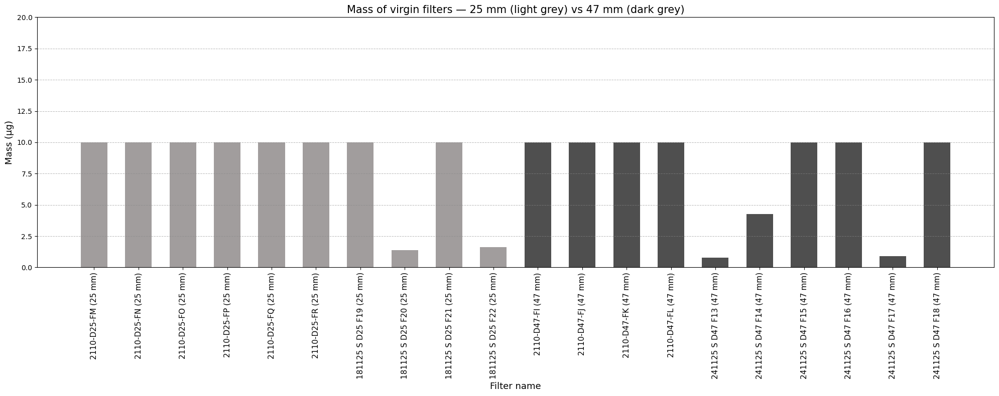

In [35]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Load file
fichier = r"C:\Users\Grira\OneDrive - Alstom\Documents\Paddle\Campagne2\Impacteur + FH\Masses and elemental composition_PTF2.xlsx"
df = pd.read_excel(fichier, engine="openpyxl", header=68) # changer la valeur du header ici

# Correct filter list (ALL filters)
virgins = ["2110-D25-FM","2110-D25-FN","2110-D25-FO","2110-D25-FP","2110-D25-FQ","2110-D25-FR","181125 S D25 F19",
           "181125 S D25 F20","181125 S D25 F21","181125 S D25 F22","2110-D47-FI","2110-D47-FJ","2110-D47-FK","2110-D47-FL",
           "241125 S D47 F13","241125 S D47 F14","241125 S D47 F15","241125 S D47 F16","241125 S D47 F17","241125 S D47 F18"] # changer les noms ici
 
# Select these filters
df_vierge = df[df["Filter name"].astype(str).isin(virgins)].copy()

# Force correct order
df_vierge["Filter name"] = pd.Categorical(df_vierge["Filter name"].astype(str),
                                          categories=virgins,
                                          ordered=True)
df_vierge = df_vierge.sort_values("Filter name")

# Create label with diameter
df_vierge["Label"] = df_vierge.apply(
    lambda row: f"{row['Filter name']} ({int(row['Filter diameter (mm)'])} mm)",
    axis=1
)

# Mass: mg → ng → µg
df_vierge["Mass_ng"] = df_vierge["Mass (mg)"] * 1_000_000
df_vierge["Mass_ug"] = df_vierge["Mass_ng"] / 1000

# Colors depending on diameter
colors = df_vierge["Filter diameter (mm)"].apply(
    lambda d: "#a19d9d" if d == 25 else "#4f4f4f"
).tolist()

# X-axis
x = np.arange(len(df_vierge))
width = 0.6

# Plot
plt.figure(figsize=(20, 8))
plt.bar(x, df_vierge["Mass_ug"], width=width, color=colors)

# Horizontal guide lines
plt.grid(axis='y', linestyle='--', alpha=0.6, linewidth=0.7, color="#888888")

# Decorations
plt.ylim(0, 20)  # add some headroom on y-axis
plt.xticks(x, df_vierge["Label"], rotation=90, fontsize=11)
plt.xlabel("Filter name", fontsize=13)
plt.ylabel("Mass (µg)", fontsize=13)
plt.title("Mass of virgin filters — 25 mm (light grey) vs 47 mm (dark grey)", fontsize=15)

plt.tight_layout()
plt.show()

Elemental composition in mass vs element

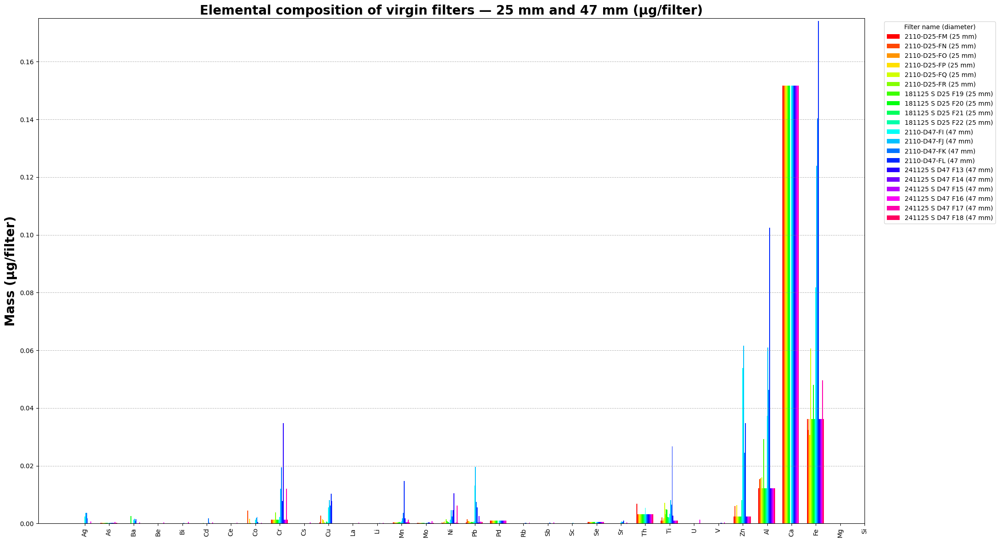

In [39]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Load file
fichier = r"C:\Users\Grira\OneDrive - Alstom\Documents\Paddle\Campagne2\Impacteur + FH\Masses and elemental composition_PTF2.xlsx"
df = pd.read_excel(fichier, engine="openpyxl", header=68) # changer la valeur du header ici

# Correct filter list (ALL filters)
virgins = ["2110-D25-FM","2110-D25-FN","2110-D25-FO","2110-D25-FP","2110-D25-FQ","2110-D25-FR","181125 S D25 F19",
           "181125 S D25 F20","181125 S D25 F21","181125 S D25 F22","2110-D47-FI","2110-D47-FJ","2110-D47-FK","2110-D47-FL",
           "241125 S D47 F13","241125 S D47 F14","241125 S D47 F15","241125 S D47 F16","241125 S D47 F17","241125 S D47 F18"] # changer les noms ici
 

df_vierge = df[df["Filter name"].astype(str).isin(virgins)]

# Element columns
elements = [col for col in df.columns if "(ng/filter)" in str(col)]
clean_elements = [col.replace(" (ng/filter)", "") for col in elements]

# Plot params
n_filters = len(df_vierge)
n_elements = len(elements)

x = np.arange(n_elements)
width = 0.7 / n_filters

plt.figure(figsize=(22, 12))

# 🎨 UNIQUE NON-REPEATING COLORS for EACH FILTER
# Generate N distinct colors evenly spaced around the HSV color circle
colors = [plt.cm.hsv(i / n_filters) for i in range(n_filters)]

# 🔥 Plot each filter with unique color
for i, (_, row) in enumerate(df_vierge.iterrows()):
    values_ug = row[elements] / 1000
    legend_label = f"{row['Filter name']} ({int(row['Filter diameter (mm)'])} mm)"
    plt.bar(x + i*width, values_ug, width=width, color=colors[i], label=legend_label)

# Grid
plt.grid(axis='y', linestyle='--', alpha=0.6, linewidth=0.7, color="#888888")

# Axis adjustments
plt.ylim(0, 0.175)
# plt.ylim(0, 8)
plt.xticks(x + width*(n_filters/2), clean_elements, rotation=90)
plt.ylabel("Mass (µg/filter)", fontsize=20, fontweight="bold")  # ← Bigger Y‑label
plt.title("Elemental composition of virgin filters — 25 mm and 47 mm (µg/filter)", fontsize=20, fontweight="bold")  # ← Bigger Y‑label

# Legend
plt.legend(title="Filter name (diameter)", bbox_to_anchor=(1.02, 1), loc='upper left')

plt.tight_layout()
plt.show()

Elemental composition in mass vs filter

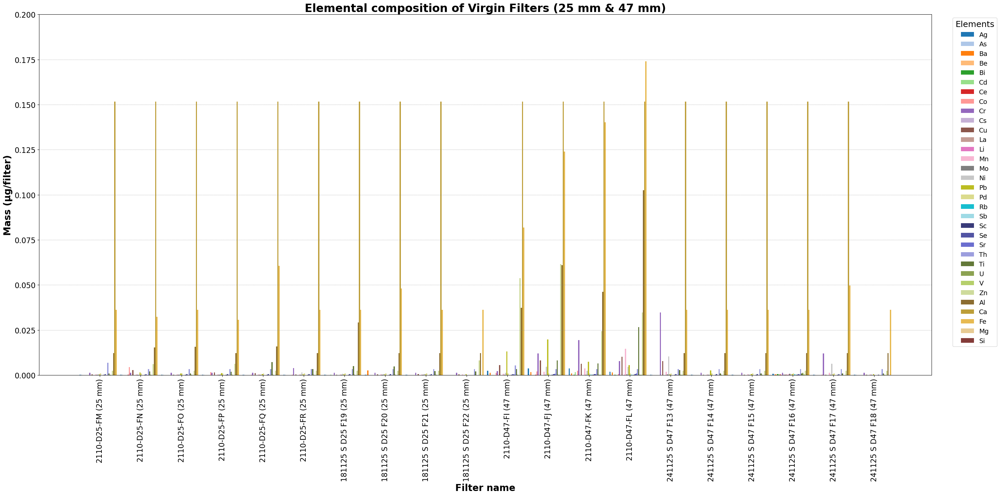

In [40]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Load file
fichier = r"C:\Users\Grira\OneDrive - Alstom\Documents\Paddle\Campagne2\Impacteur + FH\Masses and elemental composition_PTF2.xlsx"
df = pd.read_excel(fichier, engine="openpyxl", header=68) # changer la valeur du header ici

# Correct filter list (ALL filters)
virgins = ["2110-D25-FM","2110-D25-FN","2110-D25-FO","2110-D25-FP","2110-D25-FQ","2110-D25-FR","181125 S D25 F19",
           "181125 S D25 F20","181125 S D25 F21","181125 S D25 F22","2110-D47-FI","2110-D47-FJ","2110-D47-FK","2110-D47-FL",
           "241125 S D47 F13","241125 S D47 F14","241125 S D47 F15","241125 S D47 F16","241125 S D47 F17","241125 S D47 F18"] # changer les noms ici
 

df_vierge = df[df["Filter name"].astype(str).isin(virgins)].copy()

# Detect ALL chemical elements
elements = [col for col in df.columns if "(ng/filter)" in col]
clean_elements = [col.replace(" (ng/filter)", "") for col in elements]

# Add label for X-axis
df_vierge["Label"] = df_vierge.apply(
    lambda row: f"{row['Filter name']} ({int(row['Filter diameter (mm)'])} mm)",
    axis=1
)

# Convert ng → µg
df_vierge_ug = df_vierge[elements] / 1000

# Plot settings
x = np.arange(len(df_vierge))
width = 1 / (len(elements) + 1)

plt.figure(figsize=(30, 15))

# ----------- DISTINCT COLORS -------------
color_maps = [plt.cm.tab20, plt.cm.tab20b, plt.cm.tab20c]
all_colors = []
for cmap in color_maps:
    for i in range(20):
        all_colors.append(cmap(i/20))
distinct_colors = all_colors[:len(elements)]
# ------------------------------------------

# Plot all element bars
for i, (element, clean_name) in enumerate(zip(elements, clean_elements)):
    plt.bar(
        x + i*width,
        df_vierge_ug[element],
        width=width,
        color=distinct_colors[i],
        label=clean_name
    )

# Decorations (BIGGER TEXT)
plt.ylim(0, 0.2)
plt.xticks(
    x + width*(len(elements)/2),
    df_vierge["Label"],
    rotation=90,
    fontsize=16       # ← Bigger X‑axis tick labels
)
plt.yticks(fontsize=16)  # ← Bigger Y‑axis tick labels

plt.xlabel("Filter name", fontsize=20, fontweight="bold")  # ← Bigger X‑label
plt.ylabel("Mass (µg/filter)", fontsize=20, fontweight="bold")  # ← Bigger Y‑label

plt.title("Elemental composition of Virgin Filters (25 mm & 47 mm)",
          fontsize=24, fontweight="bold")  # ← Bigger title

plt.legend(
    title="Elements",
    title_fontsize=18,   # ← Bigger legend title
    fontsize=14,         # ← Bigger legend text
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    ncol=1
)

plt.grid(axis='y', linestyle='--', alpha=0.8, linewidth=0.5, color="#888888")
plt.tight_layout()
plt.show()

### Blank filters

Masses

Ligne d'entête trouvée : 1
Plot : Config3


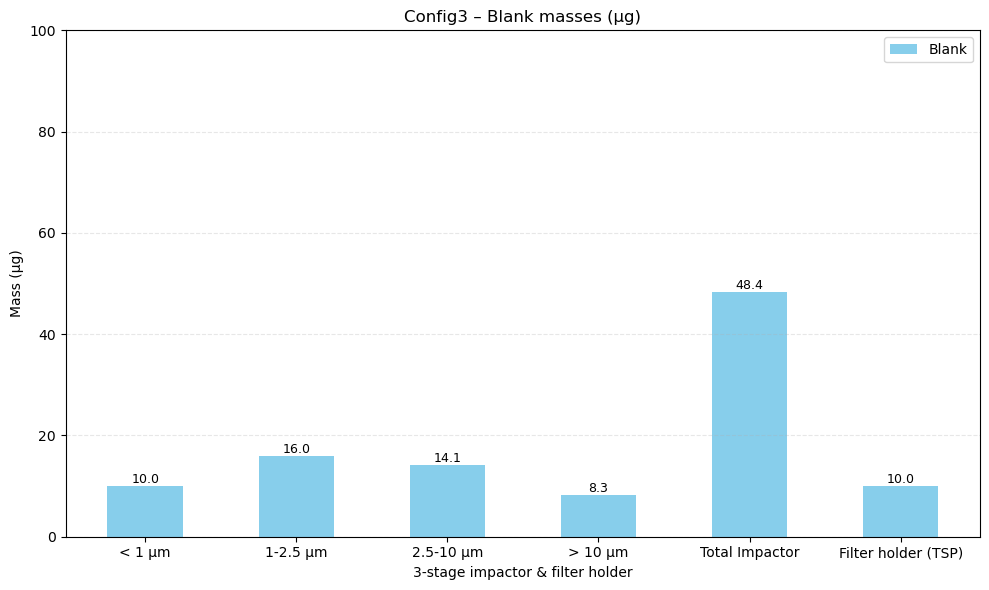

Plot : Config4


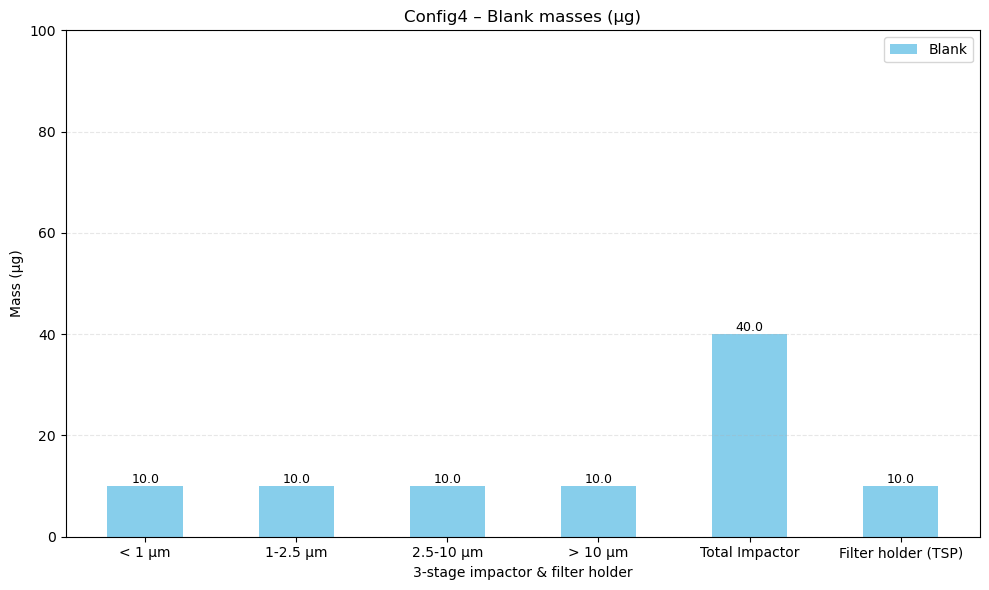

Plot : Config5


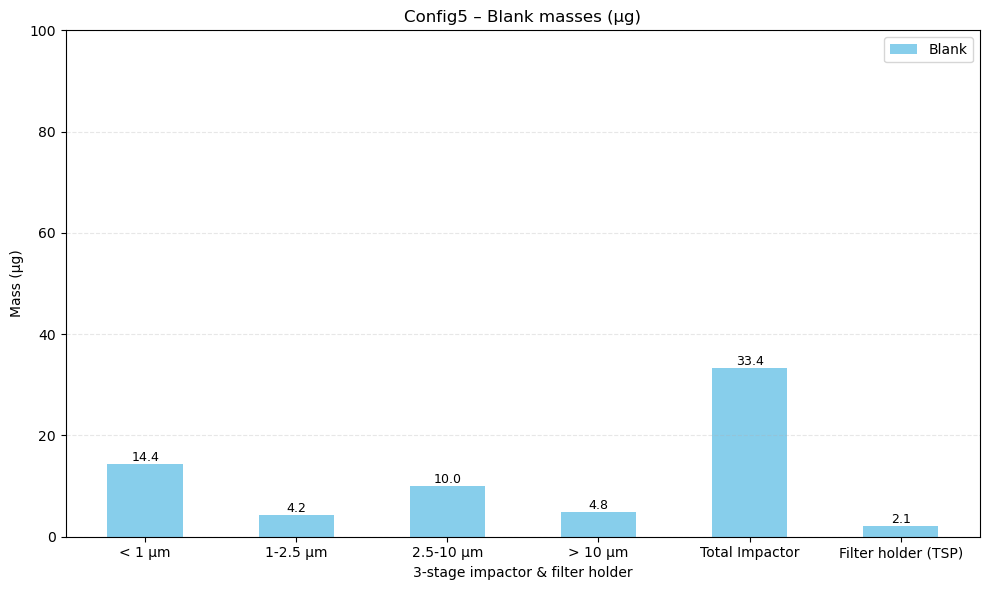

Plot : Config6


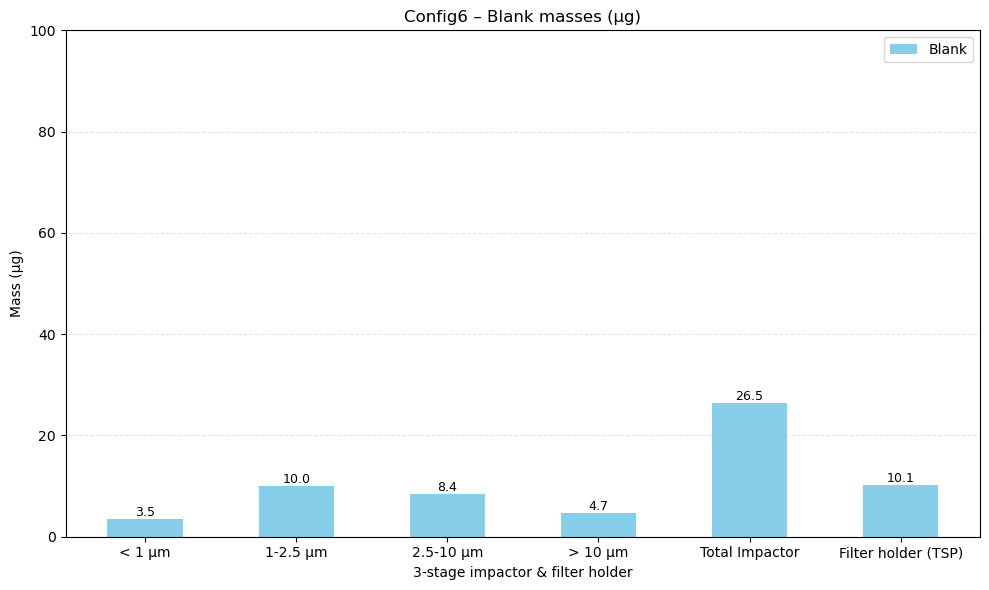

Plot : Config7


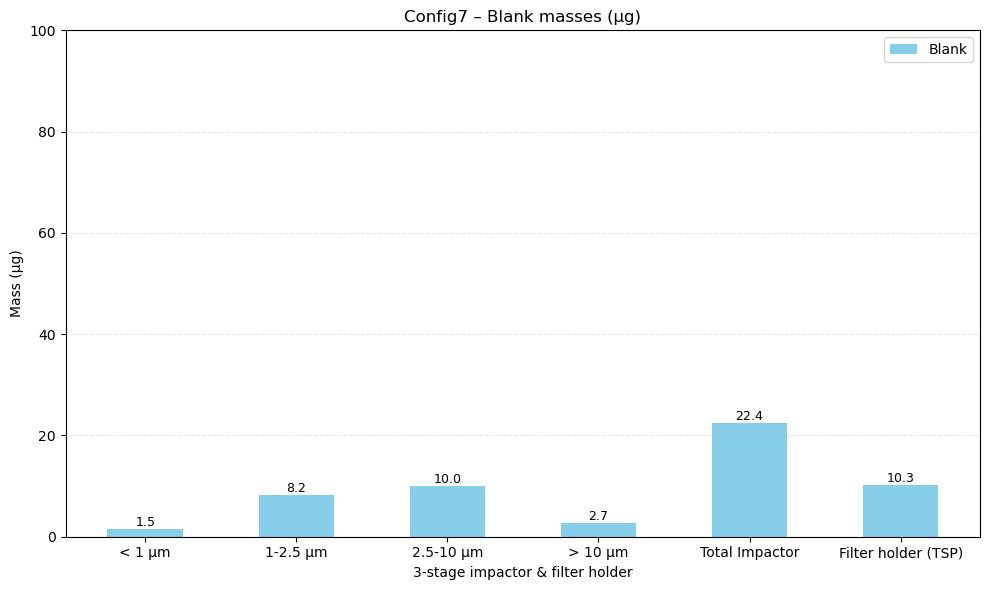

In [41]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# 1) READ RAW FILE
fichier = r"C:\Users\Grira\OneDrive - Alstom\Documents\Paddle\Campagne2\Impacteur + FH\Masses and elemental composition_PTF2.xlsx"
df_raw = pd.read_excel(fichier, header=None)

# 2) AUTO-DETECT HEADER ROW
header_row = None
for i in range(70):
    row = df_raw.iloc[i].astype(str).str.lower()
    if row.str.contains("mass").any() and row.str.contains("filter").any():
        header_row = i
        break

if header_row is None:
    raise Exception("Impossible de détecter la ligne d'entête !")

print("Ligne d'entête trouvée :", header_row)

# 3) READ CLEAN FILE
df = pd.read_excel(fichier, header=header_row)
df.columns = df.columns.map(lambda x: str(x).strip())

# 4) DETECT USEFUL COLUMNS
filter_cols = [c for c in df.columns if "filter" in c.lower() and "name" in c.lower()]
mass_cols   = [c for c in df.columns if "mass" in c.lower()]

col_filter = filter_cols[0]
col_mass   = mass_cols[0]

# 5) DETECT TYPE (Blank, Test)
def detect_type(x):
    x = str(x).strip()
    if x.startswith("B"):
        return "Blank"
    if x.isdigit():
        return "Test"
    return None

df["Type"] = df[col_filter].apply(detect_type)
df = df[df["Type"].notna()]

# 6) DETECT CONFIG/MACHINE
df["Machine"] = df.iloc[:,0].astype(str).str.extract(r"(Config[0-9A-Za-z\-]*)", expand=False).ffill()

df_clean = df.copy()

# 7) BLANK-ONLY GRAPH WITH TOTAL IMPACTOR
col_stage = "Particle diameter"
df[col_stage] = df[col_stage].astype(str).str.strip()

# Order in your data
real_order = [
    "< 1 µm",
    "1-2.5 µm",
    "2.5-10 µm",
    "> 10 µm",
    "TSP"
]

# Display labels
label_map = {
    "< 1 µm": "< 1 µm",
    "1-2.5 µm": "1-2.5 µm",
    "2.5-10 µm": "2.5-10 µm",
    "> 10 µm": "> 10 µm",
    "TSP": "Filter holder (TSP)",
    "Total Impactor": "Total Impactor"
}

for machine, dgroup in df_clean.groupby("Machine"):

    print(f"Plot : {machine}")

    blanks = dgroup[dgroup["Type"] == "Blank"]

    if blanks.empty:
        print(f"⚠️ Aucun BLANK disponible pour {machine}")
        continue

    # Store all values
    values_b = {}

    # ---- READ EACH DIAMETER & CONVERT mg → µg ----
    for diam in real_order:
        b = blanks[blanks[col_stage] == diam][col_mass]
        values_b[diam] = float(b.values[0]) * 1000 if len(b) else None   # ← mg → µg conversion

    # ---- TOTAL IMPACTOR (µg) ----
    values_b["Total Impactor"] = sum([
        values_b[d] for d in ["< 1 µm", "1-2.5 µm", "2.5-10 µm", "> 10 µm"] 
        if values_b[d] is not None
    ])

    # Final order
    final_order = [
        "< 1 µm",
        "1-2.5 µm",
        "2.5-10 µm",
        "> 10 µm",
        "Total Impactor",
        "TSP"
    ]

    masses_blank = []
    labels = []

    for diam in final_order:
        if values_b[diam] is not None:
            masses_blank.append(values_b[diam])
            labels.append(label_map[diam])

    x = np.arange(len(labels))
    width = 0.5

    plt.figure(figsize=(10,6))

    bars_blank = plt.bar(x, masses_blank, width, label="Blank", color="skyblue")

    # Add values above bars
    for bar in bars_blank:
        y = bar.get_height()
        plt.text(
            bar.get_x() + bar.get_width()/2,
            y,
            f"{y:.1f}",               # ← round to 0.1 µg
            ha='center', va='bottom',
            fontsize=9
        )

    # Scale adjusted for µg (instead of mg)
    plt.ylim(0, 100)

    plt.xticks(x, labels)
    plt.ylabel("Mass (µg)")                 # ← UPDATED
    plt.xlabel("3-stage impactor & filter holder")
    plt.title(f"{machine} – Blank masses (µg)")  # ← UPDATED
    plt.legend()
    plt.grid(axis='y', linestyle='--', alpha=0.3)

    plt.tight_layout()
    plt.show()

Elemental composition (in mass)


Plotting BLANK only: Config3


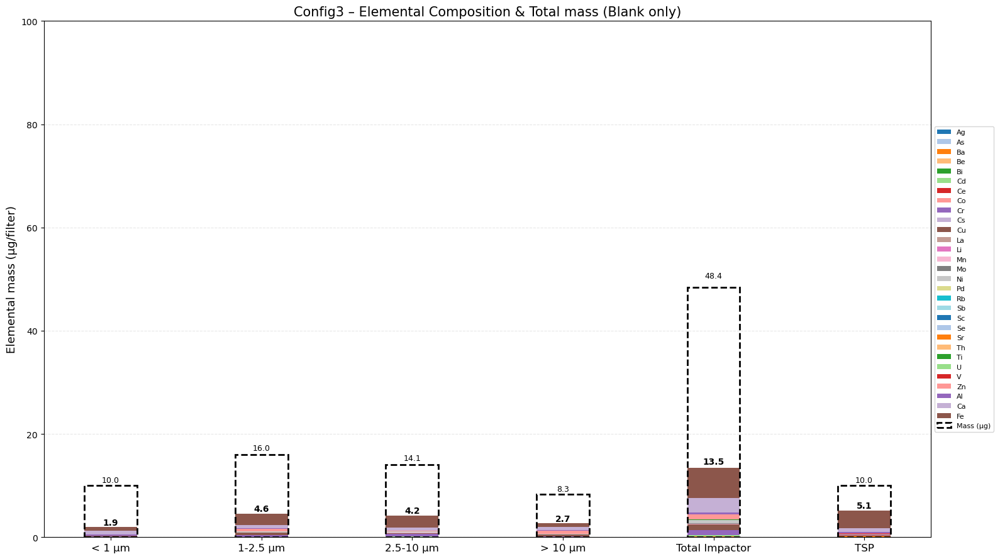


Plotting BLANK only: Config4


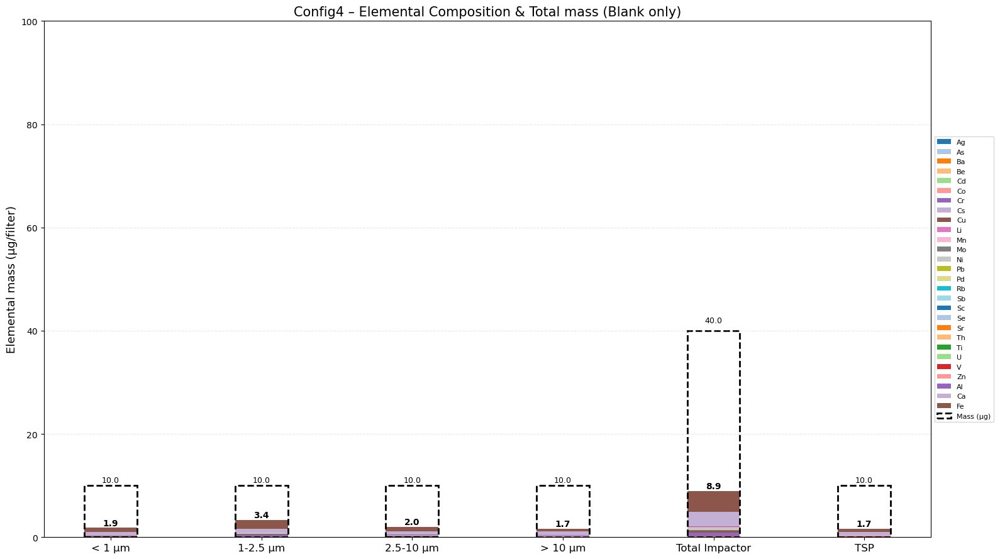


Plotting BLANK only: Config5


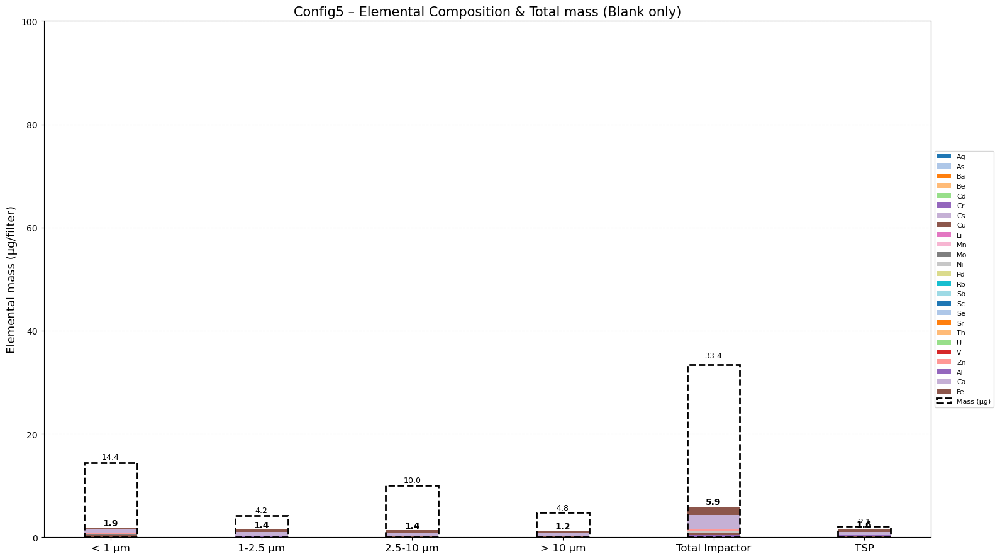


Plotting BLANK only: Config6


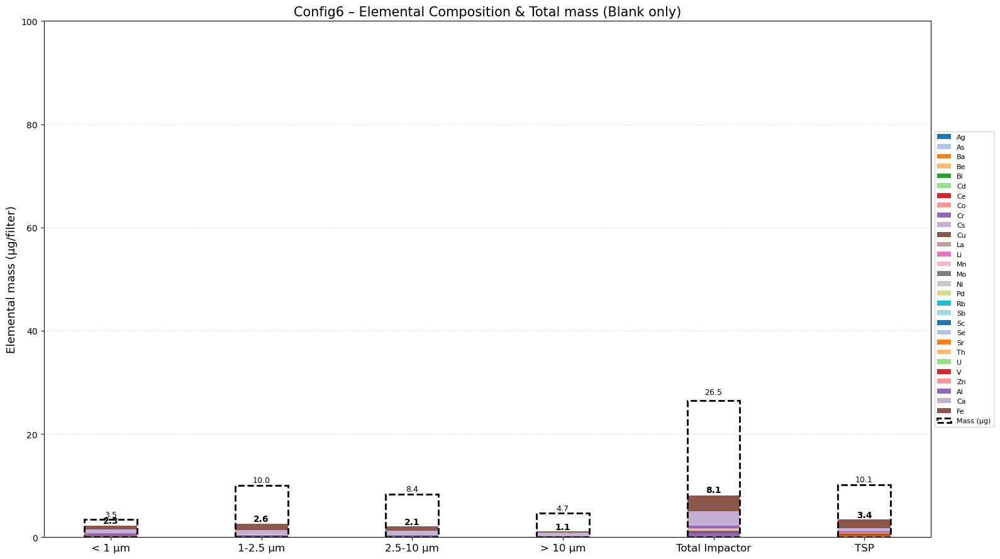


Plotting BLANK only: Config7


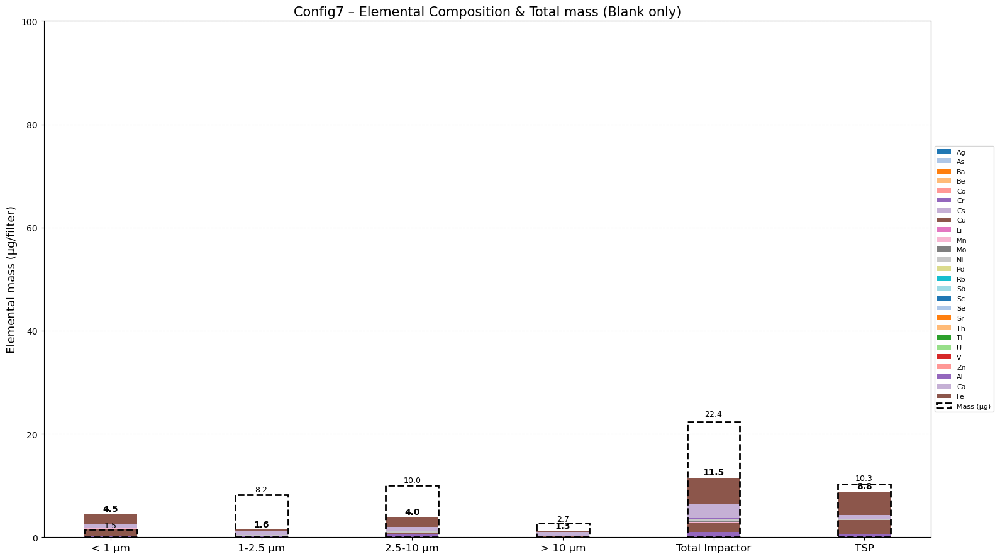


   TOP 10 ELEMENTS PER CONFIGURATION (BLANKS)


------ Config3 ------

Fe    9.295787
Ca    3.503582
Cu    1.246765
Cr    1.113643
Zn    1.047032
Ni    0.689422
Al    0.639372
Ba    0.446352
Cd    0.176313
Mo    0.169081
dtype: float64



------ Config4 ------

Fe    4.705744
Ca    3.503582
Cr    0.792113
Ni    0.426930
Cu    0.418781
Ba    0.182492
Mo    0.111509
Zn    0.109941
Al    0.108096
Mn    0.087006
dtype: float64



------ Config5 ------

Ca    3.503582
Fe    2.208840
Cu    0.554396
Zn    0.320324
Cr    0.313756
Al    0.202895
Ni    0.188992
Ba    0.107095
Mo    0.064902
Mn    0.028179
dtype: float64



------ Config6 ------

Fe    4.775426
Ca    3.503582
Cr    0.667343
Cu    0.646828
Al    0.616465
Ni    0.389292
Ba    0.387102
Zn    0.291607
Mo    0.104179
Mn    0.081487
dtype: float64



------ Config7 ------

Fe    9.521634
Cu    4.602809
Ca    3.503582
Cr    1.421746
Ni    0.421758
Al    0.319636
Mn    0.181396
Ba    0.118089
Mo    0.097333
Zn    0.047421
dtype: float64

In [18]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# 1) READ RAW FILE
fichier = r"C:\Users\Grira\OneDrive - Alstom\Documents\Paddle\Campagne2\Impacteur + FH\Masses and elemental composition_PTF2.xlsx"
df_raw = pd.read_excel(fichier, header=None)

# --------------------------
# 2) AUTO-DETECT HEADER ROW
# --------------------------
header_row = None
for i in range(50):
    row = df_raw.iloc[i].astype(str).str.lower()
    if "particle diameter" in row.tolist() and "filter name" in row.tolist():
        header_row = i
        break

df = pd.read_excel(fichier, header=header_row)
df.columns = df.columns.map(lambda x: str(x).strip())

# --------------------------
# 3) FILTER TYPE
# --------------------------
def detect_type(x):
    x = str(x).strip()
    if x.startswith("B"): return "Blank"
    if x.isdigit():       return "Test"
    return None

df["Type"] = df["Filter name"].apply(detect_type)
df = df[df["Type"].notna()]

# --------------------------
# 4) MACHINE
# --------------------------
df["Machine"] = df.iloc[:,0].astype(str).str.extract(
    r"(Config[0-9A-Za-z\-]*)", expand=False
).ffill()

# --------------------------
# 5) SIZE ORDER
# --------------------------
core_sizes = ["< 1 µm","1-2.5 µm","2.5-10 µm","> 10 µm"]
size_order = ["< 1 µm","1-2.5 µm","2.5-10 µm","> 10 µm","Total Impactor","TSP"]

# --------------------------
# 6) ELEMENT COLUMNS (ng/filter → µg/filter)
# --------------------------
elem_cols = [c for c in df.columns if "(ng/filter)" in c]

df[elem_cols] = df[elem_cols].apply(pd.to_numeric, errors="coerce").fillna(0)
df[elem_cols] = df[elem_cols] / 1000  # convert to µg/filter

elem_labels = {e: e.replace(" (ng/filter)", "") for e in elem_cols}

# --------------------------
# 7) MASS COLUMN (mg → µg)
# --------------------------
col_mass = [c for c in df.columns if "mass" in c.lower()][0]
df[col_mass] = pd.to_numeric(df[col_mass], errors="coerce").fillna(0)
df[col_mass] = df[col_mass] * 1000      # convert mg → µg

# --------------------------
# 8) BLANK PLOTS (STACKED BARS + MASS)
# --------------------------
for machine, dgroup in df.groupby("Machine"):

    print(f"\nPlotting BLANK only: {machine}")

    blanks = dgroup[dgroup["Type"] == "Blank"]

    if blanks.empty:
        print("⚠ No blank data")
        continue

    dplot = blanks[["Particle diameter", col_mass] + elem_cols].copy()
    dplot["Particle diameter"] = dplot["Particle diameter"].astype(str).str.strip()

    plt.figure(figsize=(16,9))
    width = 0.35
    x = np.arange(len(size_order))

    cmap = plt.get_cmap("tab20")
    colors = {e: cmap(i % 20) for i, e in enumerate(elem_cols)}

    grouped = dplot.groupby("Particle diameter")[elem_cols].sum()

    grouped.loc["Total Impactor"] = grouped.reindex(core_sizes).sum()
    grouped = grouped.reindex(size_order).fillna(0)

    cols_to_keep = [c for c in elem_cols if grouped[c].sum() != 0]
    grouped = grouped[cols_to_keep]
    colors_filtered = {e: colors[e] for e in cols_to_keep}

    bottom = np.zeros(len(size_order))

    for elem in cols_to_keep:
        vals = grouped[elem].values.astype(float)

        plt.bar(
            x,
            vals,
            width,
            bottom=bottom,
            color=colors_filtered[elem],
            label=elem_labels[elem]
        )

        bottom += vals

    totals = grouped.sum(axis=1).values

    for i, total in enumerate(totals):
        if total > 0:
            plt.text(
                x[i],
                total * 1.02,
                f"{total:.1f}",
                ha="center",
                va="bottom",
                fontsize=10,
                fontweight="bold"
            )

    mass_group = dplot.groupby("Particle diameter")[col_mass].sum()

    mass_group.loc["Total Impactor"] = mass_group.reindex(core_sizes).sum()
    mass_group = mass_group.reindex(size_order).fillna(0)

    for i, val in enumerate(mass_group):
        if val > 0:
            plt.bar(
                x[i],
                val,
                width,
                fill=False,
                edgecolor="black",
                linestyle="--",
                linewidth=2,
                label="Mass (µg)" if i == 0 else None
            )

            plt.text(
                x[i],
                val * 1.03,
                f"{val:.1f}",
                ha="center",
                va="bottom",
                fontsize=9,
                color="black"
            )

    plt.ylim(0, 100)
    # plt.ylim(0, 17)
    plt.xticks(x, size_order, fontsize=12)
    plt.ylabel("Elemental mass (µg/filter)", fontsize=13)
    plt.title(f"{machine} – Elemental Composition & Total mass (Blank only)", fontsize=15)

    plt.grid(axis='y', linestyle='--', alpha=0.3)
    plt.legend(loc="center left", bbox_to_anchor=(1,0.5), fontsize=8)

    plt.tight_layout()
    plt.show()

# --------------------------
# 6) COMPUTE TOP‑10 ELEMENTS PER CONFIGURATION (BLANKS ONLY)
# --------------------------
print("\n==============================================")
print("   TOP 10 ELEMENTS PER CONFIGURATION (BLANKS)")
print("==============================================\n")

configs = df["Machine"].unique()

for config in configs:

    print(f"\n------ {config} ------\n")

    # ✅ CORRECTION : Filtrer uniquement les BLANKS
    df_config = df[(df["Machine"] == config) & (df["Type"] == "Blank")]

    # Vérifier s'il y a des données blanks
    if df_config.empty:
        print(f"⚠ Pas de données Blank pour {config}\n")
        continue

    # total elemental mass = sum across BLANKS only
    total_mass = df_config[elem_cols].sum(axis=0)

    # Top 10 (basé uniquement sur les blanks)
    top10 = total_mass.sort_values(ascending=False).head(10)

    # clean names
    top10.index = [c.replace(" (ng/filter)", "") for c in top10.index]

    print(top10)
    print("\n")

print("\n==============================================")
print("DONE")
print("==============================================\n")

Elemental composition_TOP10 element (in mass)


   TOP 10 ÉLÉMENTS PAR CONFIGURATION (BLANKS UNIQUEMENT)


------ Config3 ------
--------------------------------------------------

Rang   Élément         Masse totale (µg)   
--------------------------------------------------
1      Fe              9.30                
2      Ca              3.50                
3      Cu              1.25                
4      Cr              1.11                
5      Zn              1.05                
6      Ni              0.69                
7      Al              0.64                
8      Ba              0.45                
9      Cd              0.18                
10     Mo              0.17                
--------------------------------------------------
Total des 10 éléments: 18.33 µg
Total général (tous éléments blanks): 18.59 µg
Les 10 éléments représentent: 98.6% du total



------ Config4 ------
--------------------------------------------------

Rang   Élément         Masse totale (µg)   
-----------------------------------

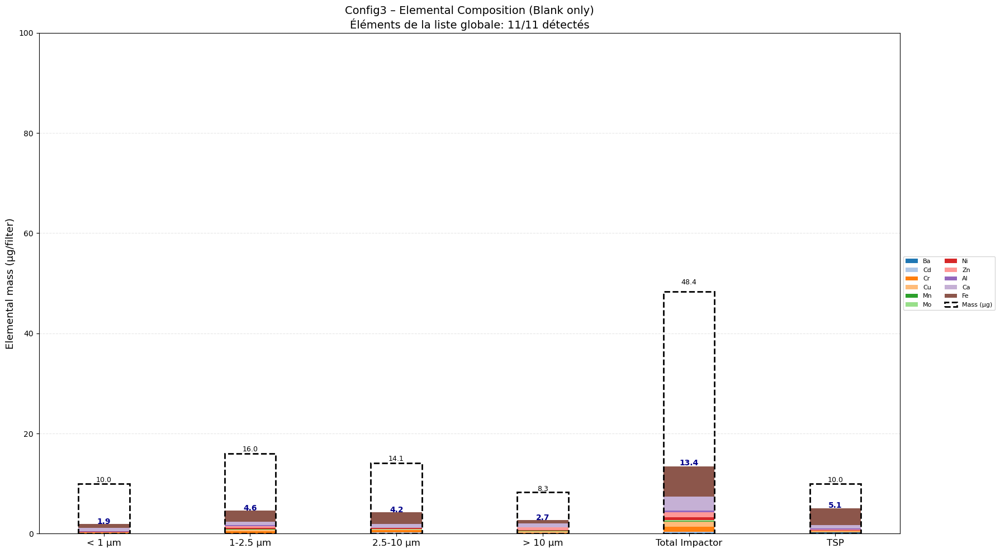


📈 Plotting BLANK only: Config4


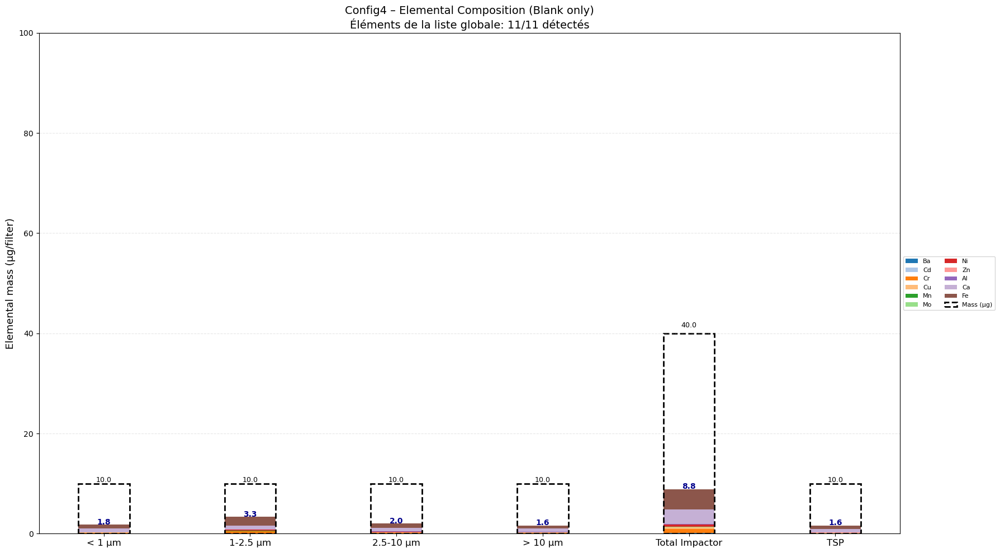


📈 Plotting BLANK only: Config5


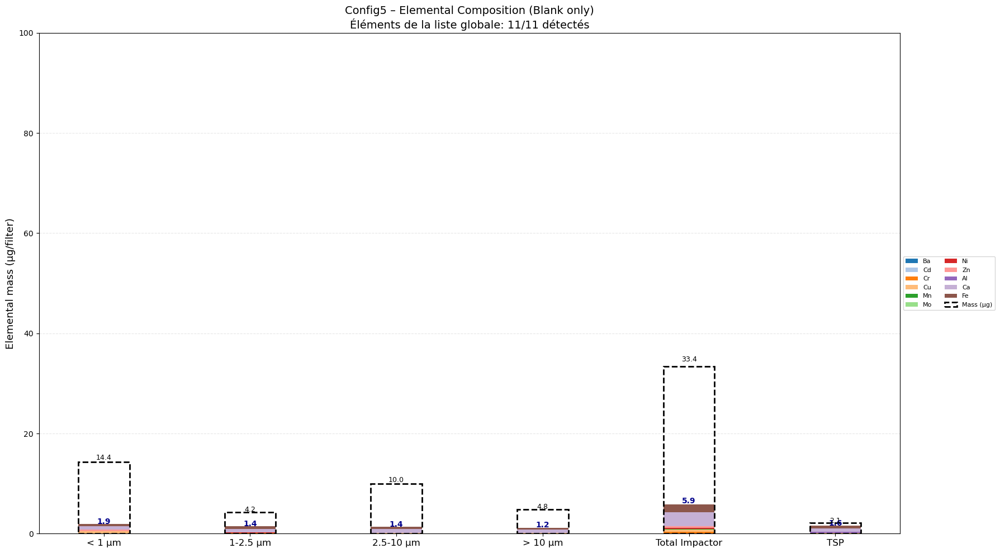


📈 Plotting BLANK only: Config6


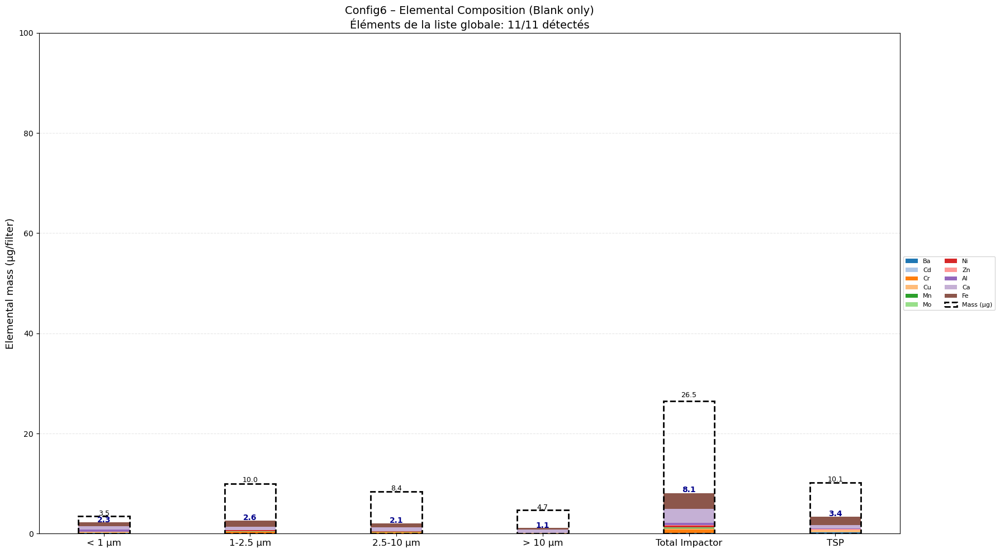


📈 Plotting BLANK only: Config7


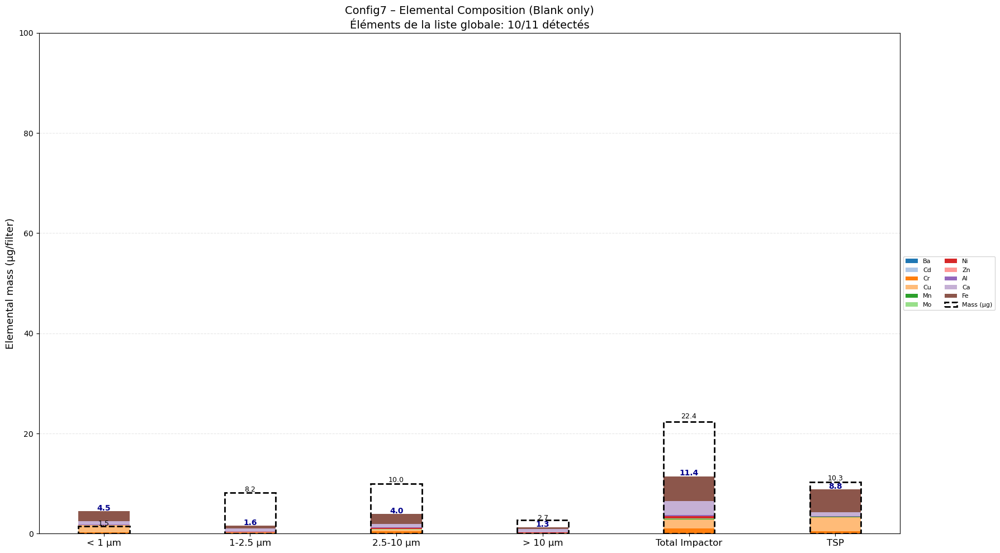


DONE


In [20]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# 1) READ RAW FILE
fichier = r"C:\Users\Grira\OneDrive - Alstom\Documents\Paddle\Campagne2\Impacteur + FH\Masses and elemental composition_PTF2.xlsx"
df_raw = pd.read_excel(fichier, header=None)

# --------------------------
# 2) AUTO-DETECT HEADER ROW
# --------------------------
header_row = None
for i in range(50):
    row = df_raw.iloc[i].astype(str).str.lower()
    if "particle diameter" in row.tolist() and "filter name" in row.tolist():
        header_row = i
        break

df = pd.read_excel(fichier, header=header_row)
df.columns = df.columns.map(lambda x: str(x).strip())

# --------------------------
# 3) FILTER TYPE
# --------------------------
def detect_type(x):
    x = str(x).strip()
    if x.startswith("B"): return "Blank"
    if x.isdigit():       return "Test"
    return None

df["Type"] = df["Filter name"].apply(detect_type)
df = df[df["Type"].notna()]

# --------------------------
# 4) MACHINE
# --------------------------
df["Machine"] = df.iloc[:,0].astype(str).str.extract(
    r"(Config[0-9A-Za-z\-]*)", expand=False
).ffill()

# --------------------------
# 5) SIZE ORDER
# --------------------------
core_sizes = ["< 1 µm","1-2.5 µm","2.5-10 µm","> 10 µm"]
size_order = ["< 1 µm","1-2.5 µm","2.5-10 µm","> 10 µm","Total Impactor","TSP"]

# --------------------------
# 6) ELEMENT COLUMNS (ng/filter → µg/filter)
# --------------------------
elem_cols = [c for c in df.columns if "(ng/filter)" in c]

df[elem_cols] = df[elem_cols].apply(pd.to_numeric, errors="coerce").fillna(0)
df[elem_cols] = df[elem_cols] / 1000  # convert to µg/filter

elem_labels = {e: e.replace(" (ng/filter)", "") for e in elem_cols}

# --------------------------
# 7) MASS COLUMN (mg → µg)
# --------------------------
col_mass = [c for c in df.columns if "mass" in c.lower()][0]
df[col_mass] = pd.to_numeric(df[col_mass], errors="coerce").fillna(0)
df[col_mass] = df[col_mass] * 1000      # convert mg → µg

# ===============================================================
# 8) COMPUTE TOP‑10 ELEMENTS FOR BLANKS ONLY
# ===============================================================
print("\n" + "="*80)
print("   TOP 10 ÉLÉMENTS PAR CONFIGURATION (BLANKS UNIQUEMENT)")
print("="*80 + "\n")

configs = df["Machine"].unique()

# Dictionnaire pour stocker les top 10 blanks
machine_top10_blanks = {}

for config in configs:

    print(f"\n------ {config} ------")
    print("-" * 50)

    df_config = df[(df["Machine"] == config) & (df["Type"] == "Blank")]

    if df_config.empty:
        print(f"⚠ Pas de données Blank pour {config}\n")
        continue

    total_mass = df_config[elem_cols].sum(axis=0)
    top10 = total_mass.sort_values(ascending=False).head(10)
    
    machine_top10_blanks[config] = top10.index.tolist()

    top10_clean = top10.copy()
    top10_clean.index = [elem_labels[c] for c in top10_clean.index]

    print(f"\n{'Rang':<6} {'Élément':<15} {'Masse totale (µg)':<20}")
    print("-" * 50)

    for rank, (elem, value) in enumerate(top10_clean.items(), 1):
        print(f"{rank:<6} {elem:<15} {value:<20.2f}")

    print("-" * 50)
    print(f"Total des 10 éléments: {top10.sum():.2f} µg")
    print(f"Total général (tous éléments blanks): {total_mass.sum():.2f} µg")
    if total_mass.sum() > 0:
        print(f"Les 10 éléments représentent: {(top10.sum()/total_mass.sum()*100):.1f}% du total")
    print("\n")

# ===============================================================
# 9) RÉSUMÉ FINAL DES TOP 10 PAR CONFIGURATION (BLANKS)
# ===============================================================
print("\n" + "="*80)
print("RÉSUMÉ FINAL - TOP 10 PAR CONFIGURATION (BLANKS)")
print("="*80)

for config, top10 in machine_top10_blanks.items():
    print(f"\n🔧 {config}")
    print("-" * 40)
    for i, elem in enumerate(top10, 1):
        elem_name = elem_labels[elem]
        print(f"  {i:2d}. {elem_name}")

# ===============================================================
# 10) LISTE GLOBALE DES ÉLÉMENTS PRÉSENTS DANS LES TOP 10 BLANKS
# ===============================================================
global_elements_blanks = set()
for top10_list in machine_top10_blanks.values():
    global_elements_blanks.update(top10_list)

global_elements_blanks = sorted(list(global_elements_blanks), key=lambda x: elem_labels[x])

print("\n" + "="*80)
print(f"LISTE GLOBALE DES ÉLÉMENTS DANS LES TOP 10 DES BLANKS ({len(global_elements_blanks)} éléments uniques)")
print("="*80)
for i, elem in enumerate(global_elements_blanks, 1):
    print(f"  {i:2d}. {elem_labels[elem]}")

# ===============================================================
# 11) BLANK PLOTS - AFFICHE TOUS LES ÉLÉMENTS DE LA LISTE GLOBALE
# ===============================================================
print("\n" + "="*80)
print("GÉNÉRATION DES GRAPHIQUES POUR LES BLANKS")
print("(Tous les éléments de la liste globale sont affichés)")
print("="*80)

# ✅ IMPORTANT: Garder TOUS les éléments de la liste globale
# Ne pas filtrer davantage - on garde global_elements_blanks
elem_cols_to_plot = [c for c in elem_cols if c in global_elements_blanks]

for machine, dgroup in df.groupby("Machine"):

    print(f"\n📈 Plotting BLANK only: {machine}")

    blanks = dgroup[dgroup["Type"] == "Blank"]

    if blanks.empty:
        print("⚠ No blank data")
        continue

    # Garder TOUS les éléments de la liste globale (même ceux à zéro)
    dplot = blanks[["Particle diameter", col_mass] + elem_cols_to_plot].copy()
    dplot["Particle diameter"] = dplot["Particle diameter"].astype(str).str.strip()

    plt.figure(figsize=(18,10))
    width = 0.35
    x = np.arange(len(size_order))

    # Palette fixe basée sur la liste globale
    cmap = plt.get_cmap("tab20")
    colors = {elem: cmap(i % 20) for i, elem in enumerate(elem_cols_to_plot)}

    grouped = dplot.groupby("Particle diameter")[elem_cols_to_plot].sum()
    grouped.loc["Total Impactor"] = grouped.reindex(core_sizes).sum()
    grouped = grouped.reindex(size_order).fillna(0)

    bottom = np.zeros(len(size_order))
    element_totals = grouped.sum(axis=1).values

    # Tracer TOUS les éléments de la liste globale
    for elem in elem_cols_to_plot:
        vals = grouped[elem].values.astype(float)
        plt.bar(
            x,
            vals,
            width,
            bottom=bottom,
            color=colors[elem],
            label=elem_labels[elem]
        )
        bottom += vals

    # Ajout du total élémentaire au-dessus des barres empilées
    for i, total in enumerate(element_totals):
        if total > 0:
            plt.text(
                x[i],
                total * 1.02,
                f"{total:.1f}",
                ha="center",
                fontsize=10,
                fontweight="bold",
                color="darkblue"
            )

    # Masse totale (trait noir)
    mass_group = dplot.groupby("Particle diameter")[col_mass].sum()
    mass_group.loc["Total Impactor"] = mass_group.reindex(core_sizes).sum()
    mass_group = mass_group.reindex(size_order).fillna(0)

    for i, val in enumerate(mass_group):
        if val > 0:
            plt.bar(
                x[i],
                val,
                width,
                fill=False,
                edgecolor="black",
                linestyle="--",
                linewidth=2,
                label="Mass (µg)" if i == 0 else None
            )
            plt.text(
                x[i],
                val * 1.03,
                f"{val:.1f}",
                ha="center",
                fontsize=9,
                color="black"
            )

    # Ajustement dynamique de la limite Y
    plt.ylim(0, 100)

    plt.xticks(x, size_order, fontsize=12)
    plt.ylabel("Elemental mass (µg/filter)", fontsize=13)
    
    # Compter les éléments détectés vs totaux
    elements_detected = sum(1 for elem in elem_cols_to_plot if blanks[elem].sum() > 0)
    plt.title(f"{machine} – Elemental Composition (Blank only)\n"
              f"Éléments de la liste globale: {elements_detected}/{len(elem_cols_to_plot)} détectés", 
              fontsize=14)

    plt.grid(axis='y', linestyle='--', alpha=0.3)
    
    # Légende avec tous les éléments de la liste globale
    plt.legend(loc="center left", bbox_to_anchor=(1, 0.5), fontsize=8, ncol=2 if len(elem_cols_to_plot) > 10 else 1)

    plt.tight_layout()
    plt.show()

print("\n" + "="*80)
print("DONE")
print("="*80)


   TOP 10 ÉLÉMENTS PAR CONFIGURATION (BLANKS UNIQUEMENT)


------ Config3 ------
--------------------------------------------------

Rang   Élément         Masse totale (µg)   
--------------------------------------------------
1      Fe              9.30                
2      Ca              3.50                
3      Cu              1.25                
4      Cr              1.11                
5      Zn              1.05                
6      Ni              0.69                
7      Al              0.64                
8      Ba              0.45                
9      Cd              0.18                
10     Mo              0.17                
--------------------------------------------------
Total des 10 éléments: 18.33 µg
Total général (tous éléments blanks): 18.59 µg
Les 10 éléments représentent: 98.6% du total



------ Config4 ------
--------------------------------------------------

Rang   Élément         Masse totale (µg)   
-----------------------------------

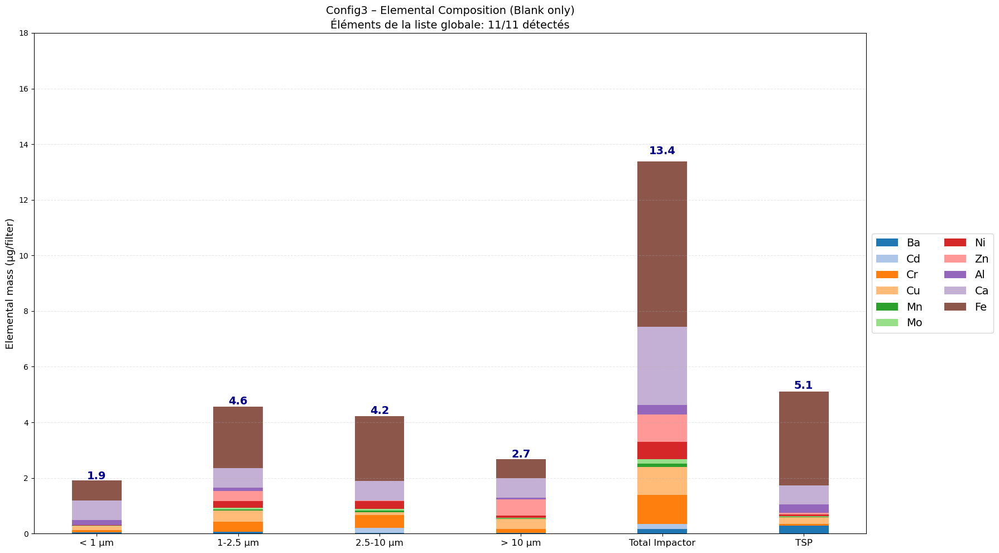


📈 Plotting BLANK only: Config4


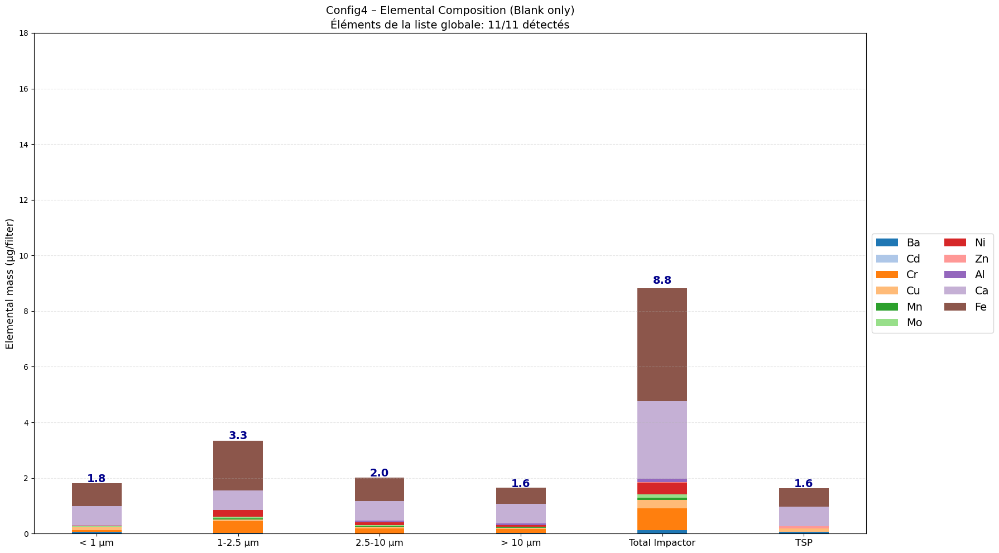


📈 Plotting BLANK only: Config5


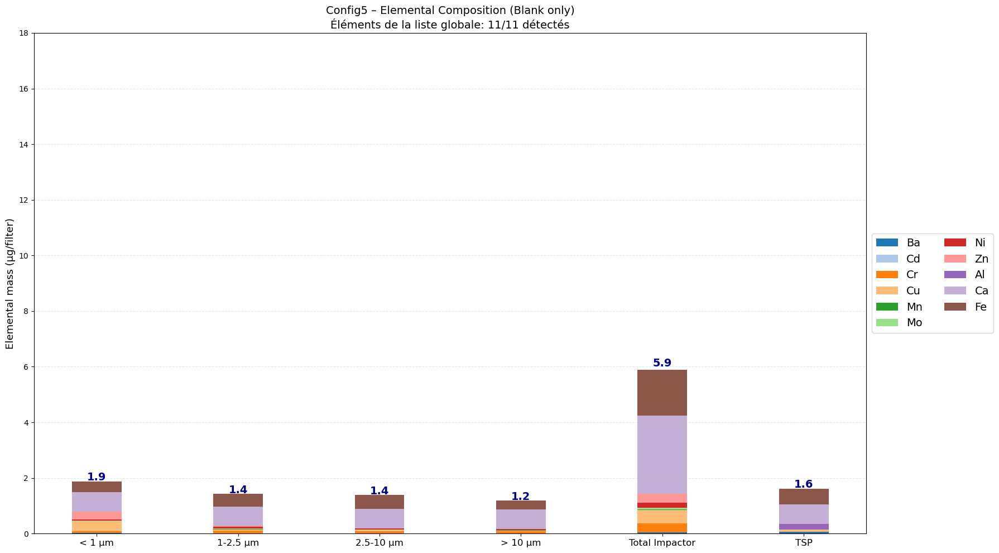


📈 Plotting BLANK only: Config6


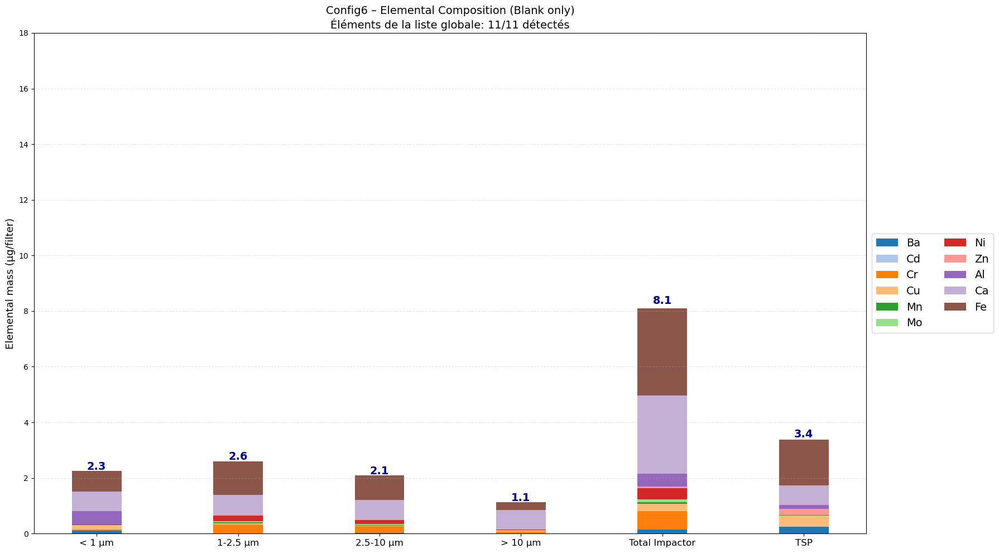


📈 Plotting BLANK only: Config7


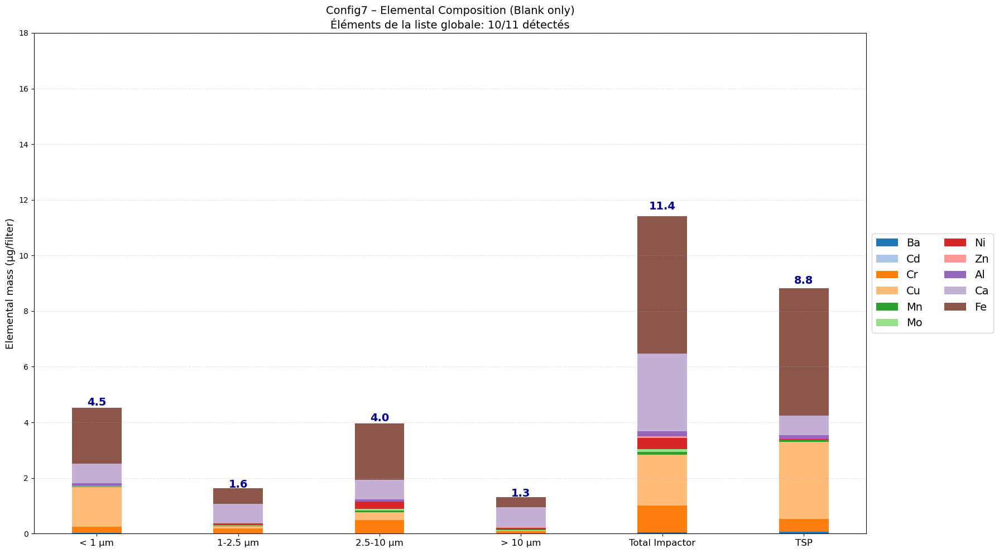


DONE


In [21]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# 1) READ RAW FILE
fichier = r"C:\Users\Grira\OneDrive - Alstom\Documents\Paddle\Campagne2\Impacteur + FH\Masses and elemental composition_PTF2.xlsx"
df_raw = pd.read_excel(fichier, header=None)

# --------------------------
# 2) AUTO-DETECT HEADER ROW
# --------------------------
header_row = None
for i in range(50):
    row = df_raw.iloc[i].astype(str).str.lower()
    if "particle diameter" in row.tolist() and "filter name" in row.tolist():
        header_row = i
        break

df = pd.read_excel(fichier, header=header_row)
df.columns = df.columns.map(lambda x: str(x).strip())

# --------------------------
# 3) FILTER TYPE
# --------------------------
def detect_type(x):
    x = str(x).strip()
    if x.startswith("B"): return "Blank"
    if x.isdigit():       return "Test"
    return None

df["Type"] = df["Filter name"].apply(detect_type)
df = df[df["Type"].notna()]

# --------------------------
# 4) MACHINE
# --------------------------
df["Machine"] = df.iloc[:,0].astype(str).str.extract(
    r"(Config[0-9A-Za-z\-]*)", expand=False
).ffill()

# --------------------------
# 5) SIZE ORDER
# --------------------------
core_sizes = ["< 1 µm","1-2.5 µm","2.5-10 µm","> 10 µm"]
size_order = ["< 1 µm","1-2.5 µm","2.5-10 µm","> 10 µm","Total Impactor","TSP"]

# --------------------------
# 6) ELEMENT COLUMNS (ng/filter → µg/filter)
# --------------------------
elem_cols = [c for c in df.columns if "(ng/filter)" in c]

df[elem_cols] = df[elem_cols].apply(pd.to_numeric, errors="coerce").fillna(0)
df[elem_cols] = df[elem_cols] / 1000  # convert to µg/filter

elem_labels = {e: e.replace(" (ng/filter)", "") for e in elem_cols}

# --------------------------
# 7) MASS COLUMN (mg → µg) - Gardé pour le calcul mais pas pour l'affichage
# --------------------------
col_mass = [c for c in df.columns if "mass" in c.lower()][0]
df[col_mass] = pd.to_numeric(df[col_mass], errors="coerce").fillna(0)
df[col_mass] = df[col_mass] * 1000      # convert mg → µg

# ===============================================================
# 8) COMPUTE TOP‑10 ELEMENTS FOR BLANKS ONLY
# ===============================================================
print("\n" + "="*80)
print("   TOP 10 ÉLÉMENTS PAR CONFIGURATION (BLANKS UNIQUEMENT)")
print("="*80 + "\n")

configs = df["Machine"].unique()

# Dictionnaire pour stocker les top 10 blanks
machine_top10_blanks = {}

for config in configs:

    print(f"\n------ {config} ------")
    print("-" * 50)

    df_config = df[(df["Machine"] == config) & (df["Type"] == "Blank")]

    if df_config.empty:
        print(f"⚠ Pas de données Blank pour {config}\n")
        continue

    total_mass = df_config[elem_cols].sum(axis=0)
    top10 = total_mass.sort_values(ascending=False).head(10)
    
    machine_top10_blanks[config] = top10.index.tolist()

    top10_clean = top10.copy()
    top10_clean.index = [elem_labels[c] for c in top10_clean.index]

    print(f"\n{'Rang':<6} {'Élément':<15} {'Masse totale (µg)':<20}")
    print("-" * 50)

    for rank, (elem, value) in enumerate(top10_clean.items(), 1):
        print(f"{rank:<6} {elem:<15} {value:<20.2f}")

    print("-" * 50)
    print(f"Total des 10 éléments: {top10.sum():.2f} µg")
    print(f"Total général (tous éléments blanks): {total_mass.sum():.2f} µg")
    if total_mass.sum() > 0:
        print(f"Les 10 éléments représentent: {(top10.sum()/total_mass.sum()*100):.1f}% du total")
    print("\n")

# ===============================================================
# 9) RÉSUMÉ FINAL DES TOP 10 PAR CONFIGURATION (BLANKS)
# ===============================================================
print("\n" + "="*80)
print("RÉSUMÉ FINAL - TOP 10 PAR CONFIGURATION (BLANKS)")
print("="*80)

for config, top10 in machine_top10_blanks.items():
    print(f"\n🔧 {config}")
    print("-" * 40)
    for i, elem in enumerate(top10, 1):
        elem_name = elem_labels[elem]
        print(f"  {i:2d}. {elem_name}")

# ===============================================================
# 10) LISTE GLOBALE DES ÉLÉMENTS PRÉSENTS DANS LES TOP 10 BLANKS
# ===============================================================
global_elements_blanks = set()
for top10_list in machine_top10_blanks.values():
    global_elements_blanks.update(top10_list)

global_elements_blanks = sorted(list(global_elements_blanks), key=lambda x: elem_labels[x])

print("\n" + "="*80)
print(f"LISTE GLOBALE DES ÉLÉMENTS DANS LES TOP 10 DES BLANKS ({len(global_elements_blanks)} éléments uniques)")
print("="*80)
for i, elem in enumerate(global_elements_blanks, 1):
    print(f"  {i:2d}. {elem_labels[elem]}")

# ===============================================================
# 11) BLANK PLOTS - SANS MASSE (UNIQUEMENT LES ÉLÉMENTS)
# ===============================================================
print("\n" + "="*80)
print("GÉNÉRATION DES GRAPHIQUES POUR LES BLANKS")
print("(Tous les éléments de la liste globale sont affichés - SANS MASSE)")
print("="*80)

# Garder TOUS les éléments de la liste globale
elem_cols_to_plot = [c for c in elem_cols if c in global_elements_blanks]

for machine, dgroup in df.groupby("Machine"):

    print(f"\n📈 Plotting BLANK only: {machine}")

    blanks = dgroup[dgroup["Type"] == "Blank"]

    if blanks.empty:
        print("⚠ No blank data")
        continue

    # ✅ Suppression de col_mass - on ne garde que les éléments
    dplot = blanks[["Particle diameter"] + elem_cols_to_plot].copy()
    dplot["Particle diameter"] = dplot["Particle diameter"].astype(str).str.strip()

    plt.figure(figsize=(18,10))
    width = 0.35
    x = np.arange(len(size_order))

    # Palette fixe basée sur la liste globale
    cmap = plt.get_cmap("tab20")
    colors = {elem: cmap(i % 20) for i, elem in enumerate(elem_cols_to_plot)}

    grouped = dplot.groupby("Particle diameter")[elem_cols_to_plot].sum()
    grouped.loc["Total Impactor"] = grouped.reindex(core_sizes).sum()
    grouped = grouped.reindex(size_order).fillna(0)

    bottom = np.zeros(len(size_order))
    element_totals = grouped.sum(axis=1).values

    # Tracer TOUS les éléments de la liste globale
    for elem in elem_cols_to_plot:
        vals = grouped[elem].values.astype(float)
        plt.bar(
            x,
            vals,
            width,
            bottom=bottom,
            color=colors[elem],
            label=elem_labels[elem]
        )
        bottom += vals

    # Ajout du total élémentaire au-dessus des barres empilées
    for i, total in enumerate(element_totals):
        if total > 0:
            plt.text(
                x[i],
                total * 1.02,
                f"{total:.1f}",
                ha="center",
                fontsize=14,
                fontweight="bold",
                color="darkblue"
            )

    # ✅ SUPPRESSION de la barre de masse (plus de code pour mass_group)

    # Ajustement dynamique de la limite Y basé uniquement sur les éléments
    plt.ylim(0, 18)

    plt.xticks(x, size_order, fontsize=12)
    plt.ylabel("Elemental mass (µg/filter)", fontsize=13)
    
    # Compter les éléments détectés vs totaux
    elements_detected = sum(1 for elem in elem_cols_to_plot if blanks[elem].sum() > 0)
    plt.title(f"{machine} – Elemental Composition (Blank only)\n"
              f"Éléments de la liste globale: {elements_detected}/{len(elem_cols_to_plot)} détectés", 
              fontsize=14)

    plt.grid(axis='y', linestyle='--', alpha=0.3)
    
    # Légende avec tous les éléments de la liste globale
    plt.legend(loc="center left", bbox_to_anchor=(1, 0.5), fontsize=14, ncol=2 if len(elem_cols_to_plot) > 10 else 1)

    plt.tight_layout()
    plt.show()

print("\n" + "="*80)
print("DONE")
print("="*80)

Concentrations

Mass concentration

Ligne d'entête trouvée : 1
Plot : Config3


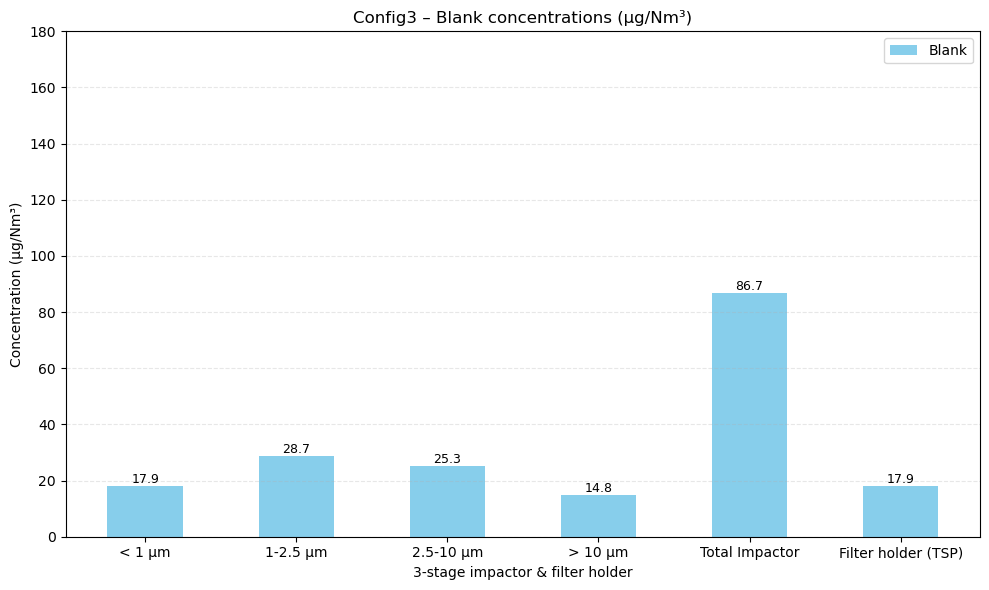

Plot : Config4


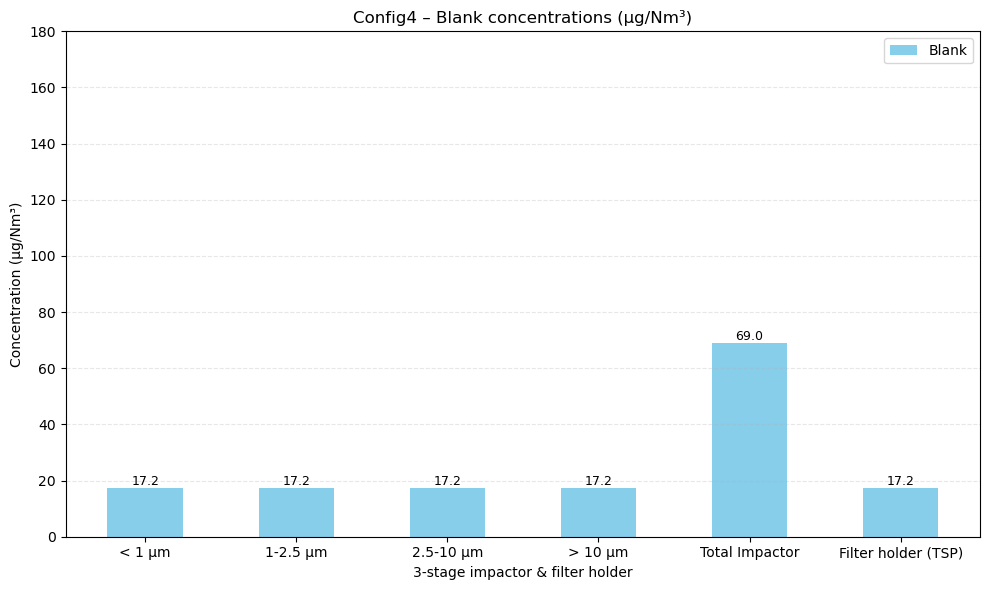

Plot : Config5


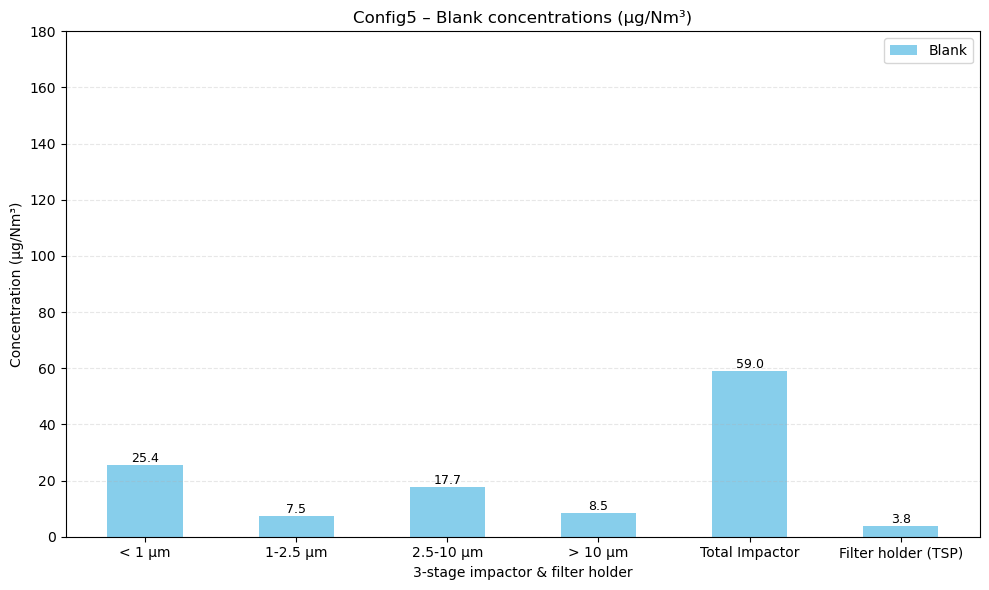

Plot : Config6


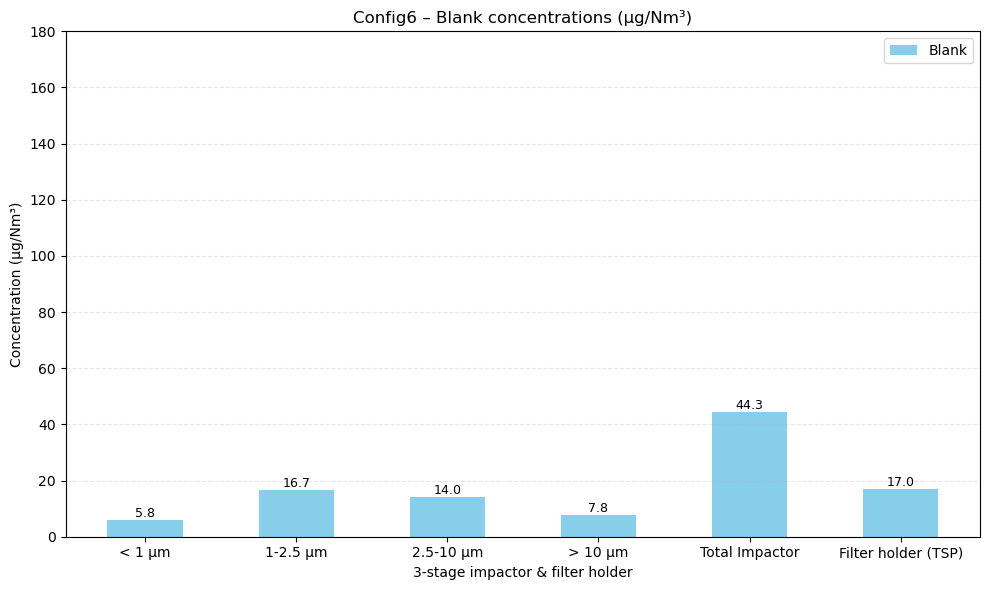

Plot : Config7


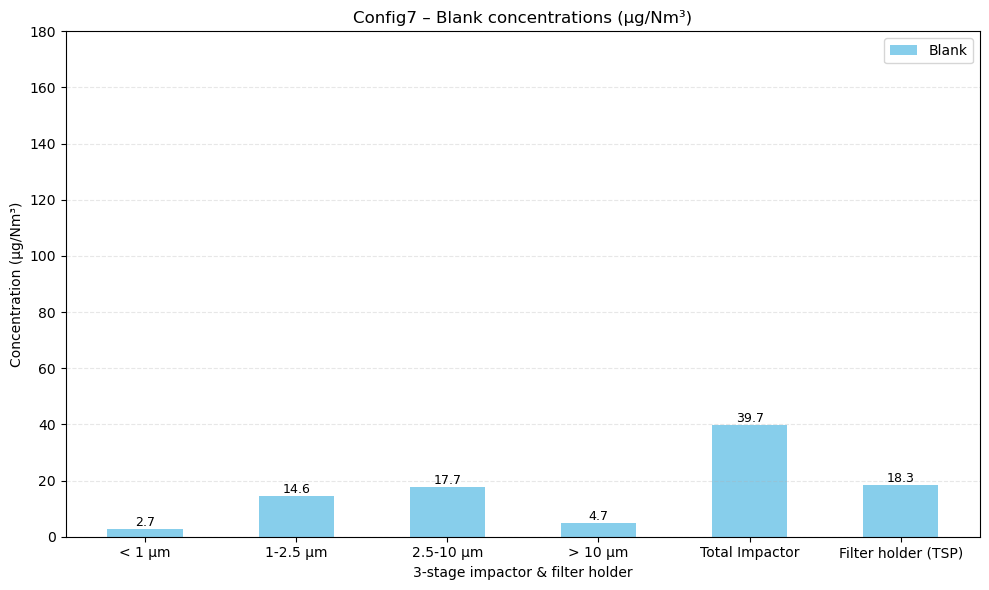

In [22]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# 1) READ RAW FILE
fichier = r"C:\Users\Grira\OneDrive - Alstom\Documents\Paddle\Campagne2\Impacteur + FH\Masses and elemental composition_PTF2.xlsx"
df_raw = pd.read_excel(fichier, header=None)

# 2) AUTO-DETECT HEADER ROW
header_row = None
for i in range(50):
    row = df_raw.iloc[i].astype(str).str.lower()
    if row.str.contains("mass").any() and row.str.contains("filter").any():
        header_row = i
        break

if header_row is None:
    raise Exception("Impossible de détecter la ligne d'entête !")

print("Ligne d'entête trouvée :", header_row)

# 3) READ CLEAN FILE
df = pd.read_excel(fichier, header=header_row)
df.columns = df.columns.map(lambda x: str(x).strip())

# 4) DETECT USEFUL COLUMNS
filter_cols = [c for c in df.columns if "filter" in c.lower() and "name" in c.lower()]
conc_cols   = [c for c in df.columns if "concentration" in c.lower()]   # <<< NEW

col_filter = filter_cols[0]
col_conc   = conc_cols[0]   # <<< NEW – we now use concentration

# 5) DETECT TYPE (Blank, Test)
def detect_type(x):
    x = str(x).strip()
    if x.startswith("B"):
        return "Blank"
    if x.isdigit():
        return "Test"
    return None

df["Type"] = df[col_filter].apply(detect_type)
df = df[df["Type"].notna()]

# 6) DETECT CONFIG/MACHINE
df["Machine"] = df.iloc[:,0].astype(str).str.extract(r"(Config[0-9A-Za-z\-]*)", expand=False).ffill()

df_clean = df.copy()

# 7) BLANK-ONLY GRAPH WITH TOTAL IMPACTOR (USING CONCENTRATION)
col_stage = "Particle diameter"
df[col_stage] = df[col_stage].astype(str).str.strip()

# Order in your data
real_order = [
    "< 1 µm",
    "1-2.5 µm",
    "2.5-10 µm",
    "> 10 µm",
    "TSP"
]

# Display labels
label_map = {
    "< 1 µm": "< 1 µm",
    "1-2.5 µm": "1-2.5 µm",
    "2.5-10 µm": "2.5-10 µm",
    "> 10 µm": "> 10 µm",
    "TSP": "Filter holder (TSP)",
    "Total Impactor": "Total Impactor"
}

for machine, dgroup in df_clean.groupby("Machine"):

    print(f"Plot : {machine}")

    blanks = dgroup[dgroup["Type"] == "Blank"]

    if blanks.empty:
        print(f"⚠️ Aucun BLANK disponible pour {machine}")
        continue

    # Store all concentration values
    values_b = {}

    # Read each diameter concentration
    for diam in real_order:
        b = blanks[blanks[col_stage] == diam][col_conc]   # <<< NEW
        values_b[diam] = float(b.values[0]) if len(b) else None

    # ---- TOTAL IMPACTOR USING CONCENTRATION ----
    values_b["Total Impactor"] = sum([
        values_b[d] for d in ["< 1 µm", "1-2.5 µm", "2.5-10 µm", "> 10 µm"]
        if values_b[d] is not None
    ])

    # Final order for plotting
    final_order = [
        "< 1 µm",
        "1-2.5 µm",
        "2.5-10 µm",
        "> 10 µm",
        "Total Impactor",
        "TSP"
    ]

    conc_blank = []
    labels = []

    for diam in final_order:
        if values_b[diam] is not None:
            conc_blank.append(values_b[diam])
            labels.append(label_map[diam])

    x = np.arange(len(labels))
    width = 0.5

    plt.figure(figsize=(10,6))

    bars_blank = plt.bar(x, conc_blank, width, label="Blank", color="skyblue")

    # Value labels
    for bar in bars_blank:
        y = bar.get_height()
        plt.text(bar.get_x() + bar.get_width()/2, y, f"{y:.1f}",
                 ha='center', va='bottom', fontsize=9)

    plt.ylim(0, 180)  
    plt.xticks(x, labels)
    plt.ylabel("Concentration (µg/Nm³)")  
    plt.xlabel("3-stage impactor & filter holder")
    plt.title(f"{machine} – Blank concentrations (µg/Nm³)")  
    plt.legend()
    plt.grid(axis='y', linestyle='--', alpha=0.3)

    plt.tight_layout()
    plt.show()

Elemental composition (in mass concentration)


Plotting BLANK only: Config3


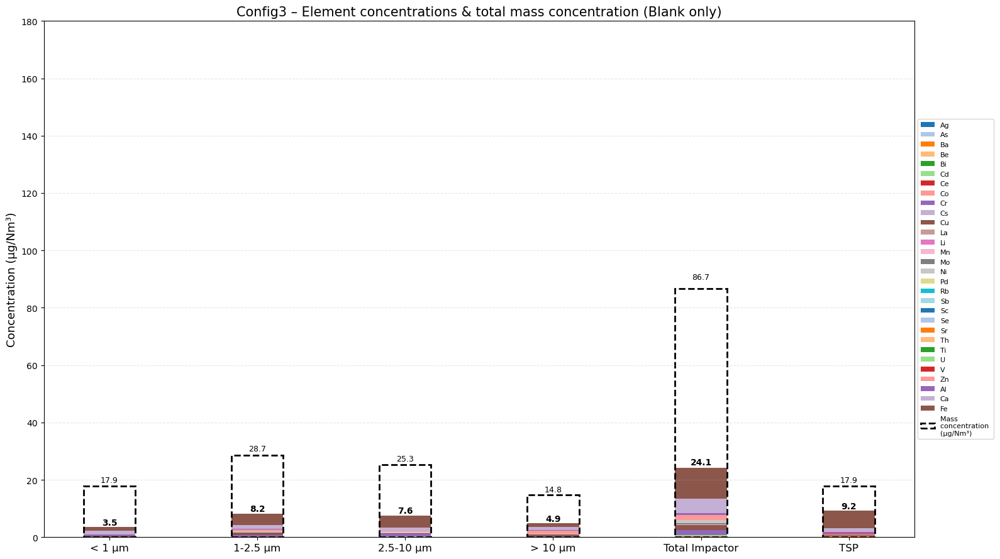


Plotting BLANK only: Config4


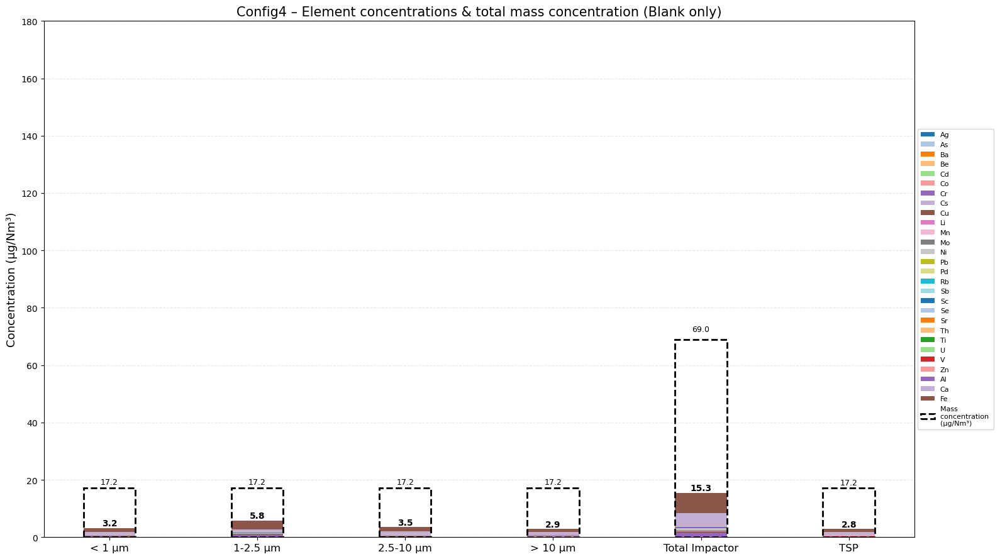


Plotting BLANK only: Config5


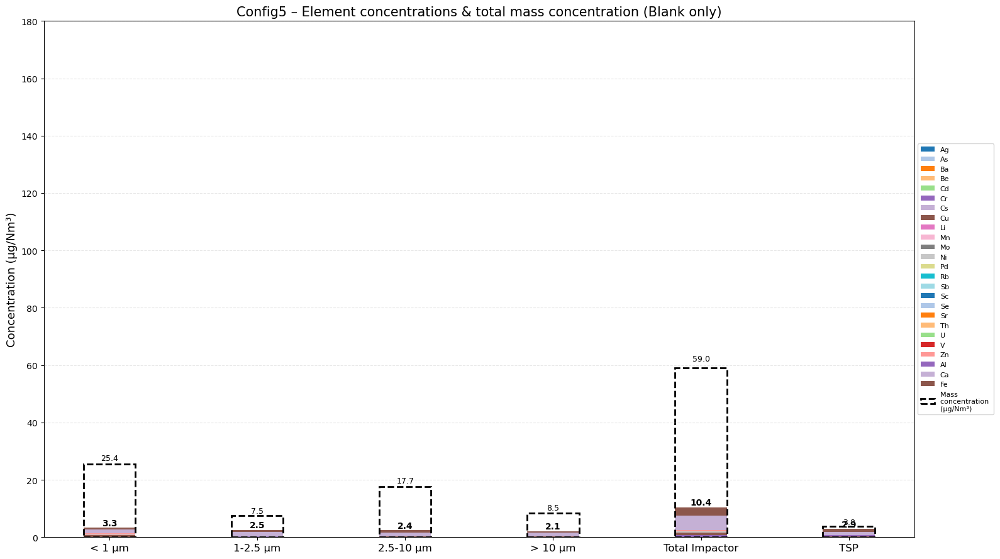


Plotting BLANK only: Config6


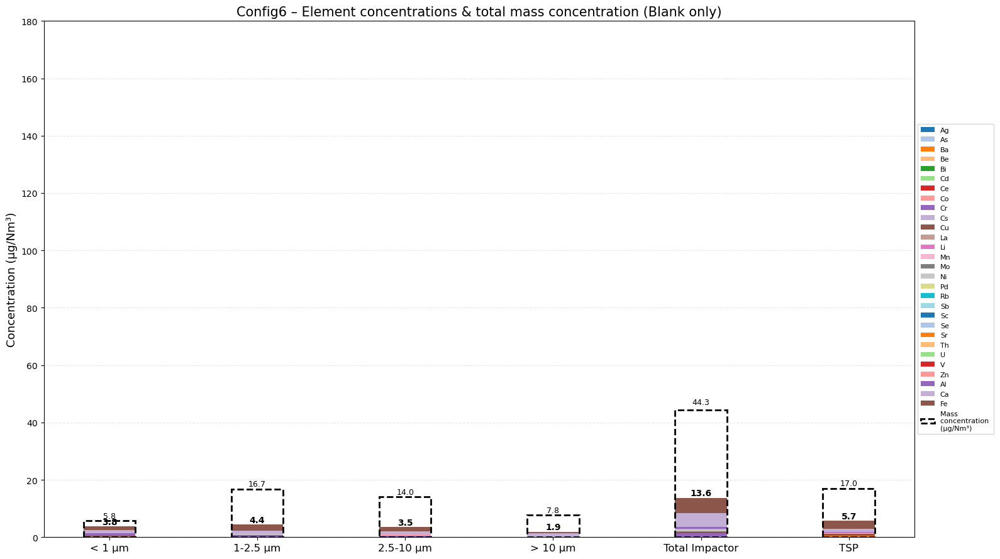


Plotting BLANK only: Config7


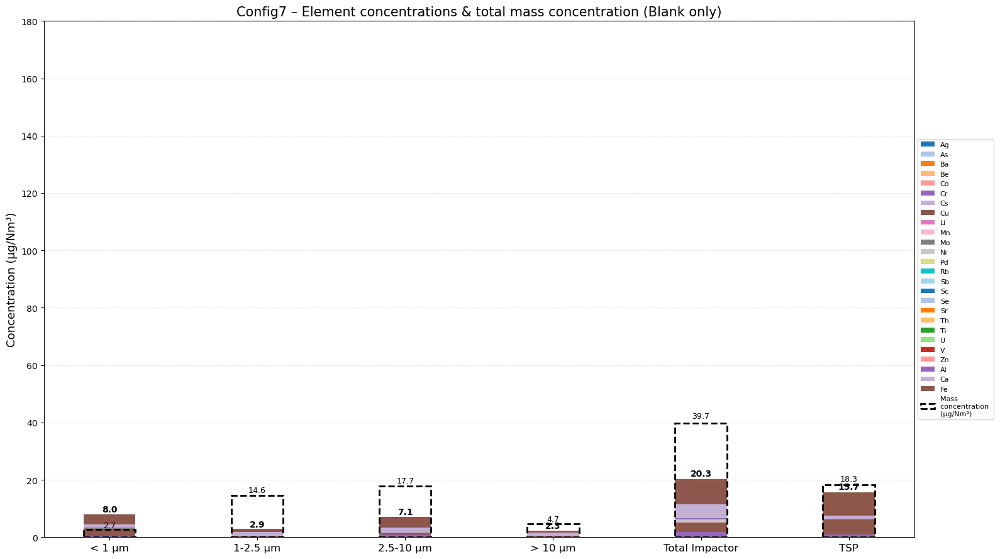


   TOP 10 ÉLÉMENTS PAR CONFIGURATION (BLANKS UNIQUEMENT)


------ Config3 ------
--------------------------------------------------

Rang   Élément         Concentration totale (µg/Nm³)
--------------------------------------------------
1      Fe              16.66                    
2      Ca              6.28                     
3      Cu              2.23                     
4      Cr              2.00                     
5      Zn              1.88                     
6      Ni              1.24                     
7      Al              1.15                     
8      Ba              0.80                     
9      Cd              0.32                     
10     Mo              0.30                     
--------------------------------------------------
Total des 10 éléments: 32.84 µg/Nm³
Total général (tous éléments blanks): 33.32 µg/Nm³
Les 10 éléments représentent: 98.6% du total



------ Config4 ------
--------------------------------------------------

Rang   Éléme

In [28]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# 1) READ RAW FILE
fichier = r"C:\Users\Grira\OneDrive - Alstom\Documents\Paddle\Campagne2\Impacteur + FH\Masses and elemental composition_PTF2.xlsx"
df_raw = pd.read_excel(fichier, header=None)

# --------------------------
# 2) AUTO-DETECT HEADER ROW
# --------------------------
header_row = None
for i in range(50):
    row = df_raw.iloc[i].astype(str).str.lower()
    if "particle diameter" in row.tolist() and "filter name" in row.tolist():
        header_row = i
        break

df = pd.read_excel(fichier, header=header_row)
df.columns = df.columns.map(lambda x: str(x).strip())

# --------------------------
# 3) FILTER TYPE (Blank / Test)
# --------------------------
def detect_type(x):
    x = str(x).strip()
    if x.startswith("B"): return "Blank"
    if x.isdigit(): return "Test"
    return None

df["Type"] = df["Filter name"].apply(detect_type)
df = df[df["Type"].notna()]

# --------------------------
# 4) MACHINE NAME
# --------------------------
df["Machine"] = df.iloc[:,0].astype(str).str.extract(
    r"(Config[0-9A-Za-z\-]*)", expand=False
).ffill()

# --------------------------
# 5) SIZE ORDER
# --------------------------
core_sizes = ["< 1 µm","1-2.5 µm","2.5-10 µm","> 10 µm"]
size_order = ["< 1 µm","1-2.5 µm","2.5-10 µm","> 10 µm","Total Impactor","TSP"]

# --------------------------
# 6) ELEMENT COLUMNS (µg/Nm3 ALREADY IN EXCEL)
# --------------------------
elem_cols = [c for c in df.columns if "(µg/Nm3 filter)" in c]

df[elem_cols] = df[elem_cols].apply(pd.to_numeric, errors="coerce").fillna(0)
elem_labels = {e: e.replace(" (µg/Nm3 filter)", "") for e in elem_cols}

# --------------------------
# 7) MASS CONCENTRATION COLUMN (µg/Nm3 ALREADY IN EXCEL)
# --------------------------
col_mass_conc = [c for c in df.columns if "Concentration" in c and "(µg/Nm3)" in c][0]
df[col_mass_conc] = pd.to_numeric(df[col_mass_conc], errors="coerce").fillna(0)

# --------------------------
# 8) BLANK PLOTS WITH STACKED ELEMENTS + MASS CONCENTRATION
# --------------------------
for machine, dgroup in df.groupby("Machine"):

    print(f"\nPlotting BLANK only: {machine}")

    blanks = dgroup[dgroup["Type"] == "Blank"]
    if blanks.empty:
        print("⚠ No blank data")
        continue

    dplot = blanks[["Particle diameter", col_mass_conc] + elem_cols].copy()
    dplot["Particle diameter"] = dplot["Particle diameter"].astype(str).str.strip()

    plt.figure(figsize=(16,9))
    width = 0.35
    x = np.arange(len(size_order))

    cmap = plt.get_cmap("tab20")
    colors = {e: cmap(i % 20) for i, e in enumerate(elem_cols)}

    # --- ELEMENTS (STACKED)
    grouped = dplot.groupby("Particle diameter")[elem_cols].sum()
    grouped.loc["Total Impactor"] = grouped.reindex(core_sizes).sum()
    grouped = grouped.reindex(size_order).fillna(0)

    cols_to_keep = [c for c in elem_cols if grouped[c].sum() != 0]
    grouped = grouped[cols_to_keep]
    colors_filtered = {e: colors[e] for e in cols_to_keep}

    bottom = np.zeros(len(size_order))

    for elem in cols_to_keep:
        vals = grouped[elem].values.astype(float)
        plt.bar(
            x,
            vals,
            width,
            bottom=bottom,
            color=colors_filtered[elem],
            label=elem_labels[elem]
        )
        bottom += vals

    totals = grouped.sum(axis=1).values
    for i, total in enumerate(totals):
        if total > 0:
            plt.text(
                x[i],
                total * 1.02,
                f"{total:.1f}",
                ha="center",
                va="bottom",
                fontsize=10,
                fontweight="bold"
            )

    # --- MASS CONCENTRATION (µg/Nm3)
    mass_group = dplot.groupby("Particle diameter")[col_mass_conc].sum()
    mass_group.loc["Total Impactor"] = mass_group.reindex(core_sizes).sum()
    mass_group = mass_group.reindex(size_order).fillna(0)

    for i, val in enumerate(mass_group):
        if val > 0:
            plt.bar(
                x[i],
                val,
                width,
                fill=False,
                edgecolor="black",
                linestyle="--",
                linewidth=2,
                label="Mass \nconcentration \n(µg/Nm³)" if i == 0 else None
            )
            plt.text(
                x[i],
                val * 1.03,
                f"{val:.1f}",
                ha="center",
                va="bottom",
                fontsize=9,
                color="black"
            )

    plt.ylim(0, 180)
    plt.xticks(x, size_order, fontsize=12)
    plt.ylabel("Concentration (µg/Nm³)", fontsize=13)
    plt.title(f"{machine} – Element concentrations & total mass concentration (Blank only)", fontsize=15)

    plt.grid(axis='y', linestyle='--', alpha=0.3)
    plt.legend(loc="center left", bbox_to_anchor=(1,0.5), fontsize=8)

    plt.tight_layout()
    plt.show()

# ===============================================================
# 9) TOP‑10 ELEMENTS PER CONFIGURATION (BLANKS ONLY) - CORRIGÉ
# ===============================================================
print("\n" + "="*80)
print("   TOP 10 ÉLÉMENTS PAR CONFIGURATION (BLANKS UNIQUEMENT)")
print("="*80 + "\n")

configs = df["Machine"].unique()

for config in configs:

    print(f"\n------ {config} ------")
    print("-" * 50)

    # ✅ CORRECTION : Filtrer uniquement les BLANKS (comme dans le code 1)
    df_config = df[(df["Machine"] == config) & (df["Type"] == "Blank")]

    # Vérifier s'il y a des données blanks
    if df_config.empty:
        print(f"⚠ Pas de données Blank pour {config}\n")
        continue

    # Concentration totale uniquement sur les blanks
    total_conc = df_config[elem_cols].sum(axis=0)

    # Top 10 (basé uniquement sur les blanks)
    top10 = total_conc.sort_values(ascending=False).head(10)

    # Nettoyer les noms pour l'affichage
    top10_clean = top10.copy()
    top10_clean.index = [elem_labels[c] for c in top10_clean.index]

    # Affichage détaillé
    print(f"\n{'Rang':<6} {'Élément':<15} {'Concentration totale (µg/Nm³)':<25}")
    print("-" * 50)

    for rank, (elem, value) in enumerate(top10_clean.items(), 1):
        print(f"{rank:<6} {elem:<15} {value:<25.2f}")

    print("-" * 50)
    print(f"Total des 10 éléments: {top10.sum():.2f} µg/Nm³")
    print(f"Total général (tous éléments blanks): {total_conc.sum():.2f} µg/Nm³")
    if total_conc.sum() > 0:
        print(f"Les 10 éléments représentent: {(top10.sum()/total_conc.sum()*100):.1f}% du total")
    print("\n")

print("\n" + "="*80)
print("DONE")
print("="*80)

Elemental composition (in mass concentration- top10)


   TOP 10 ÉLÉMENTS PAR CONFIGURATION (BLANKS UNIQUEMENT)
   Concentration en µg/Nm³


------ Config3 ------
--------------------------------------------------

Rang   Élément         Concentration totale (µg/Nm³)
--------------------------------------------------
1      Fe              16.66                    
2      Ca              6.28                     
3      Cu              2.23                     
4      Cr              2.00                     
5      Zn              1.88                     
6      Ni              1.24                     
7      Al              1.15                     
8      Ba              0.80                     
9      Cd              0.32                     
10     Mo              0.30                     
--------------------------------------------------
Total des 10 éléments: 32.84 µg/Nm³
Total général (tous éléments blanks): 33.32 µg/Nm³
Les 10 éléments représentent: 98.6% du total



------ Config4 ------
-------------------------------------

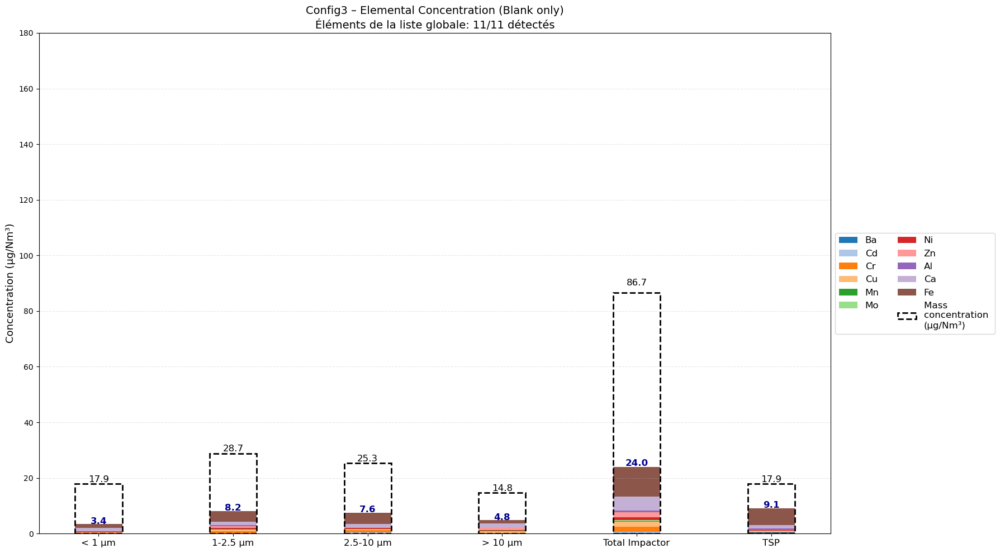


📈 Plotting BLANK only: Config4


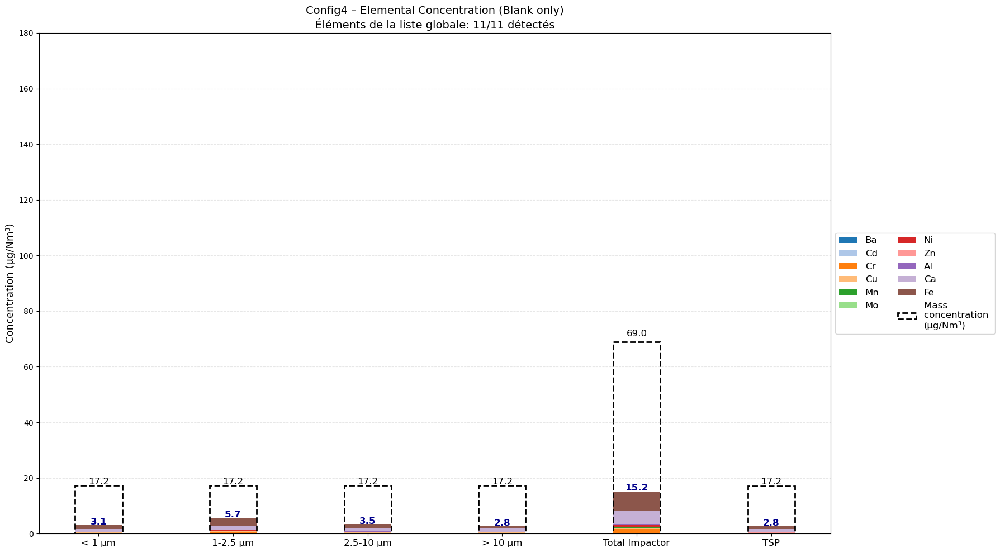


📈 Plotting BLANK only: Config5


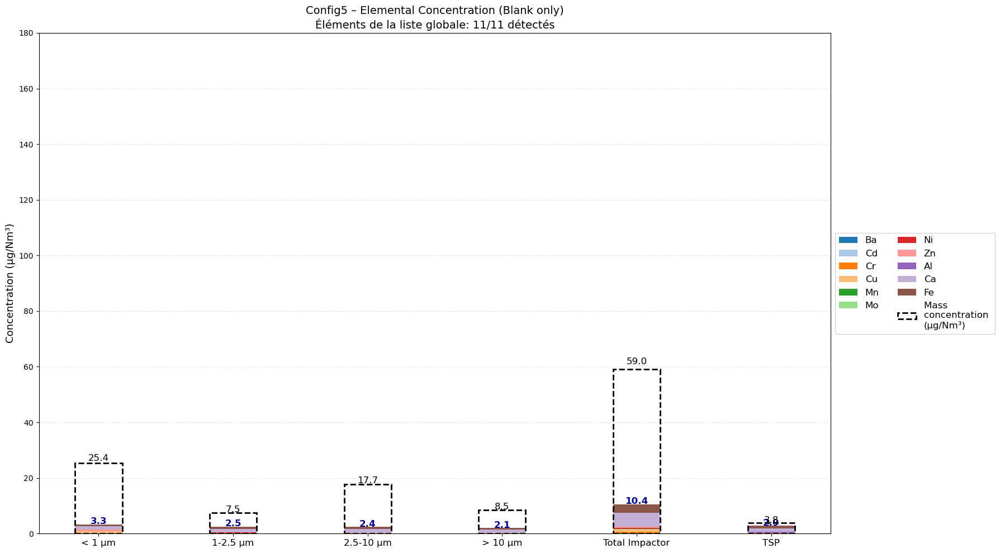


📈 Plotting BLANK only: Config6


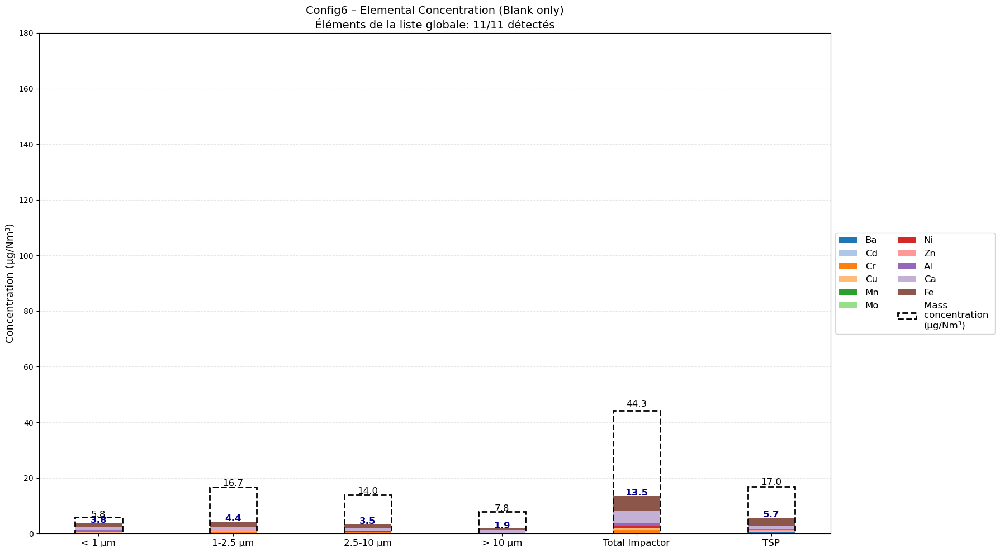


📈 Plotting BLANK only: Config7


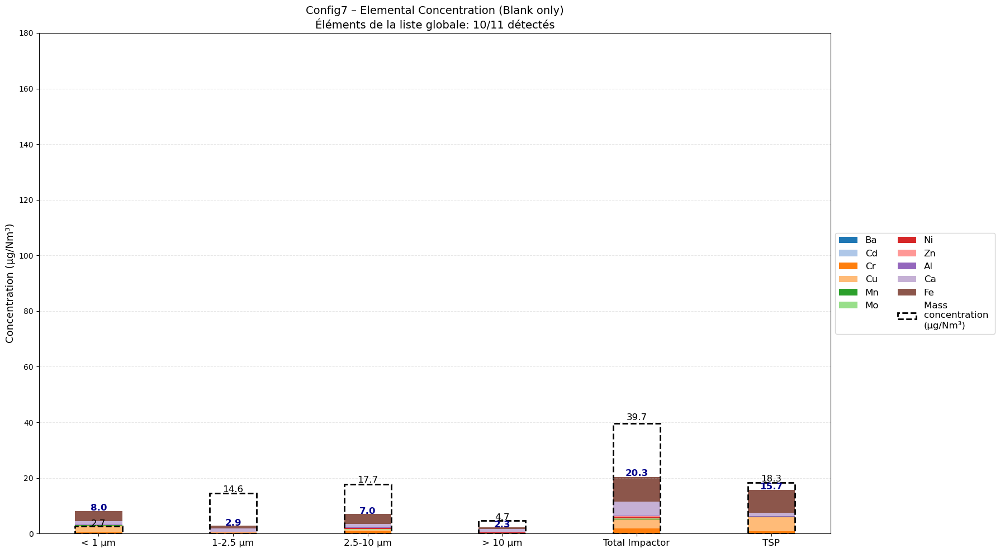


DONE


In [29]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# 1) READ RAW FILE
fichier = r"C:\Users\Grira\OneDrive - Alstom\Documents\Paddle\Campagne2\Impacteur + FH\Masses and elemental composition_PTF2.xlsx"
df_raw = pd.read_excel(fichier, header=None)

# --------------------------
# 2) AUTO-DETECT HEADER ROW
# --------------------------
header_row = None
for i in range(50):
    row = df_raw.iloc[i].astype(str).str.lower()
    if "particle diameter" in row.tolist() and "filter name" in row.tolist():
        header_row = i
        break

df = pd.read_excel(fichier, header=header_row)
df.columns = df.columns.map(lambda x: str(x).strip())

# --------------------------
# 3) FILTER TYPE
# --------------------------
def detect_type(x):
    x = str(x).strip()
    if x.startswith("B"): return "Blank"
    if x.isdigit():       return "Test"
    return None

df["Type"] = df["Filter name"].apply(detect_type)
df = df[df["Type"].notna()]

# --------------------------
# 4) MACHINE
# --------------------------
df["Machine"] = df.iloc[:,0].astype(str).str.extract(
    r"(Config[0-9A-Za-z\-]*)", expand=False
).ffill()

# --------------------------
# 5) SIZE ORDER
# --------------------------
core_sizes = ["< 1 µm","1-2.5 µm","2.5-10 µm","> 10 µm"]
size_order = ["< 1 µm","1-2.5 µm","2.5-10 µm","> 10 µm","Total Impactor","TSP"]

# ===============================================================
# 6) ELEMENT COLUMNS (µg/Nm3 filter) - NO CONVERSION NEEDED
# ===============================================================
elem_cols = [c for c in df.columns if "(µg/Nm3 filter)" in c]

df[elem_cols] = df[elem_cols].apply(pd.to_numeric, errors="coerce").fillna(0)

elem_labels = {e: e.replace(" (µg/Nm3 filter)", "") for e in elem_cols}

# ===============================================================
# 7) MASS CONCENTRATION COLUMN (µg/Nm3) - ALREADY IN EXCEL
# ===============================================================
col_mass_conc = [c for c in df.columns if "Concentration" in c and "(µg/Nm3)" in c][0]
df[col_mass_conc] = pd.to_numeric(df[col_mass_conc], errors="coerce").fillna(0)

# ===============================================================
# 8) COMPUTE TOP‑10 ELEMENTS FOR BLANKS ONLY (CONCENTRATION)
# ===============================================================
print("\n" + "="*80)
print("   TOP 10 ÉLÉMENTS PAR CONFIGURATION (BLANKS UNIQUEMENT)")
print("   Concentration en µg/Nm³")
print("="*80 + "\n")

configs = df["Machine"].unique()

# Dictionnaire pour stocker les top 10 blanks
machine_top10_blanks = {}

for config in configs:

    print(f"\n------ {config} ------")
    print("-" * 50)

    df_config = df[(df["Machine"] == config) & (df["Type"] == "Blank")]

    if df_config.empty:
        print(f"⚠ Pas de données Blank pour {config}\n")
        continue

    total_conc = df_config[elem_cols].sum(axis=0)
    top10 = total_conc.sort_values(ascending=False).head(10)
    
    machine_top10_blanks[config] = top10.index.tolist()

    top10_clean = top10.copy()
    top10_clean.index = [elem_labels[c] for c in top10_clean.index]

    print(f"\n{'Rang':<6} {'Élément':<15} {'Concentration totale (µg/Nm³)':<25}")
    print("-" * 50)

    for rank, (elem, value) in enumerate(top10_clean.items(), 1):
        print(f"{rank:<6} {elem:<15} {value:<25.2f}")

    print("-" * 50)
    print(f"Total des 10 éléments: {top10.sum():.2f} µg/Nm³")
    print(f"Total général (tous éléments blanks): {total_conc.sum():.2f} µg/Nm³")
    if total_conc.sum() > 0:
        print(f"Les 10 éléments représentent: {(top10.sum()/total_conc.sum()*100):.1f}% du total")
    print("\n")

# ===============================================================
# 9) RÉSUMÉ FINAL DES TOP 10 PAR CONFIGURATION (BLANKS)
# ===============================================================
print("\n" + "="*80)
print("RÉSUMÉ FINAL - TOP 10 PAR CONFIGURATION (BLANKS)")
print("Concentration en µg/Nm³")
print("="*80)

for config, top10 in machine_top10_blanks.items():
    print(f"\n🔧 {config}")
    print("-" * 40)
    for i, elem in enumerate(top10, 1):
        elem_name = elem_labels[elem]
        print(f"  {i:2d}. {elem_name}")

# ===============================================================
# 10) LISTE GLOBALE DES ÉLÉMENTS PRÉSENTS DANS LES TOP 10 BLANKS
# ===============================================================
global_elements_blanks = set()
for top10_list in machine_top10_blanks.values():
    global_elements_blanks.update(top10_list)

global_elements_blanks = sorted(list(global_elements_blanks), key=lambda x: elem_labels[x])

print("\n" + "="*80)
print(f"LISTE GLOBALE DES ÉLÉMENTS DANS LES TOP 10 DES BLANKS ({len(global_elements_blanks)} éléments uniques)")
print("Concentration en µg/Nm³")
print("="*80)
for i, elem in enumerate(global_elements_blanks, 1):
    print(f"  {i:2d}. {elem_labels[elem]}")

# ===============================================================
# 11) BLANK PLOTS - AFFICHE TOUS LES ÉLÉMENTS DE LA LISTE GLOBALE (CONCENTRATION)
# ===============================================================
print("\n" + "="*80)
print("GÉNÉRATION DES GRAPHIQUES POUR LES BLANKS")
print("(Tous les éléments de la liste globale sont affichés - Concentration en µg/Nm³)")
print("="*80)

# Garder TOUS les éléments de la liste globale
elem_cols_to_plot = [c for c in elem_cols if c in global_elements_blanks]

for machine, dgroup in df.groupby("Machine"):

    print(f"\n📈 Plotting BLANK only: {machine}")

    blanks = dgroup[dgroup["Type"] == "Blank"]

    if blanks.empty:
        print("⚠ No blank data")
        continue

    # Garder TOUS les éléments de la liste globale (même ceux à zéro)
    dplot = blanks[["Particle diameter", col_mass_conc] + elem_cols_to_plot].copy()
    dplot["Particle diameter"] = dplot["Particle diameter"].astype(str).str.strip()

    plt.figure(figsize=(18,10))
    width = 0.35
    x = np.arange(len(size_order))

    # Palette fixe basée sur la liste globale
    cmap = plt.get_cmap("tab20")
    colors = {elem: cmap(i % 20) for i, elem in enumerate(elem_cols_to_plot)}

    grouped = dplot.groupby("Particle diameter")[elem_cols_to_plot].sum()
    grouped.loc["Total Impactor"] = grouped.reindex(core_sizes).sum()
    grouped = grouped.reindex(size_order).fillna(0)

    bottom = np.zeros(len(size_order))
    element_totals = grouped.sum(axis=1).values

    # Tracer TOUS les éléments de la liste globale
    for elem in elem_cols_to_plot:
        vals = grouped[elem].values.astype(float)
        plt.bar(
            x,
            vals,
            width,
            bottom=bottom,
            color=colors[elem],
            label=elem_labels[elem]
        )
        bottom += vals

    # Ajout du total élémentaire au-dessus des barres empilées
    for i, total in enumerate(element_totals):
        if total > 0:
            plt.text(
                x[i],
                total * 1.02,
                f"{total:.1f}",
                ha="center",
                fontsize=12,
                fontweight="bold",
                color="darkblue"
            )

    # Masse concentration (trait noir) - en µg/Nm³
    mass_group = dplot.groupby("Particle diameter")[col_mass_conc].sum()
    mass_group.loc["Total Impactor"] = mass_group.reindex(core_sizes).sum()
    mass_group = mass_group.reindex(size_order).fillna(0)

    for i, val in enumerate(mass_group):
        if val > 0:
            plt.bar(
                x[i],
                val,
                width,
                fill=False,
                edgecolor="black",
                linestyle="--",
                linewidth=2,
                label="Mass \nconcentration \n(µg/Nm³)" if i == 0 else None
            )
            plt.text(
                x[i],
                val * 1.03,
                f"{val:.1f}",
                ha="center",
                fontsize=12,
                color="black"
            )

    # Ajustement dynamique de la limite Y
    plt.ylim(0, 180)

    plt.xticks(x, size_order, fontsize=12)
    plt.ylabel("Concentration (µg/Nm³)", fontsize=13)
    
    # Compter les éléments détectés vs totaux
    elements_detected = sum(1 for elem in elem_cols_to_plot if blanks[elem].sum() > 0)
    plt.title(f"{machine} – Elemental Concentration (Blank only)\n"
              f"Éléments de la liste globale: {elements_detected}/{len(elem_cols_to_plot)} détectés", 
              fontsize=14)

    plt.grid(axis='y', linestyle='--', alpha=0.3)
    
    # Légende avec tous les éléments de la liste globale
    plt.legend(loc="center left", bbox_to_anchor=(1, 0.5), fontsize=12, ncol=2 if len(elem_cols_to_plot) > 10 else 1)

    plt.tight_layout()
    plt.show()

print("\n" + "="*80)
print("DONE")
print("="*80)


   TOP 10 ÉLÉMENTS PAR CONFIGURATION (BLANKS UNIQUEMENT)
   Concentration en µg/Nm³


------ Config3 ------
--------------------------------------------------

Rang   Élément         Concentration totale (µg/Nm³)
--------------------------------------------------
1      Fe              16.66                    
2      Ca              6.28                     
3      Cu              2.23                     
4      Cr              2.00                     
5      Zn              1.88                     
6      Ni              1.24                     
7      Al              1.15                     
8      Ba              0.80                     
9      Cd              0.32                     
10     Mo              0.30                     
--------------------------------------------------
Total des 10 éléments: 32.84 µg/Nm³
Total général (tous éléments blanks): 33.32 µg/Nm³
Les 10 éléments représentent: 98.6% du total



------ Config4 ------
-------------------------------------

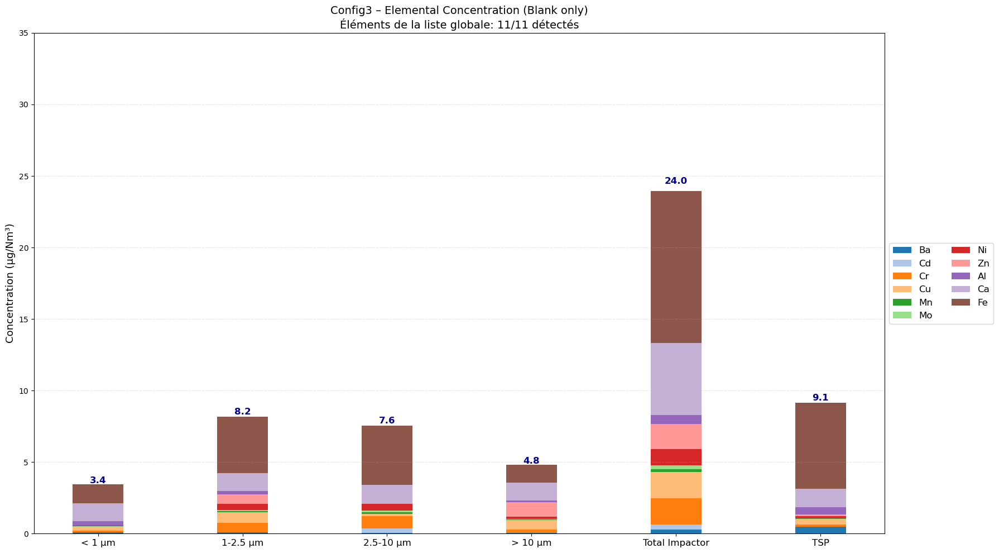


📈 Plotting BLANK only: Config4


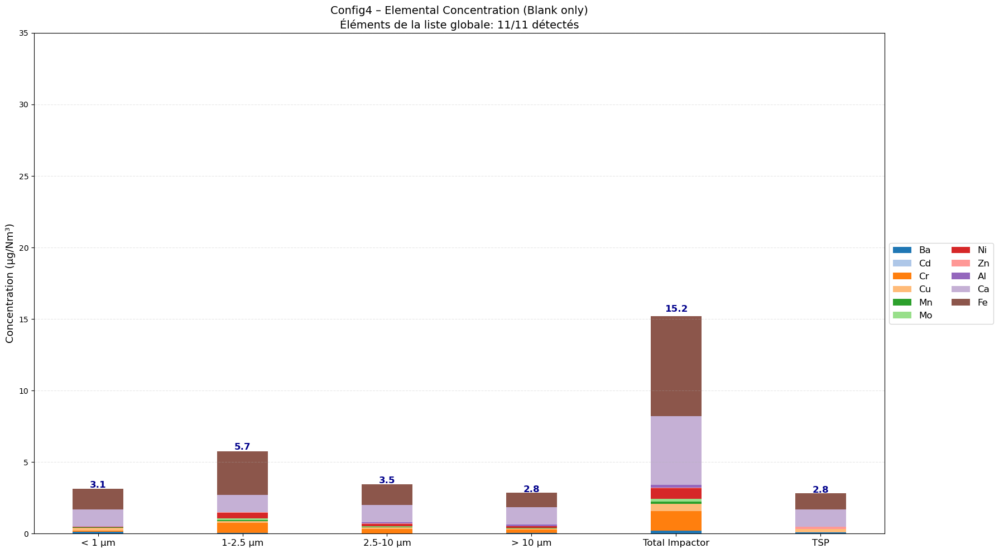


📈 Plotting BLANK only: Config5


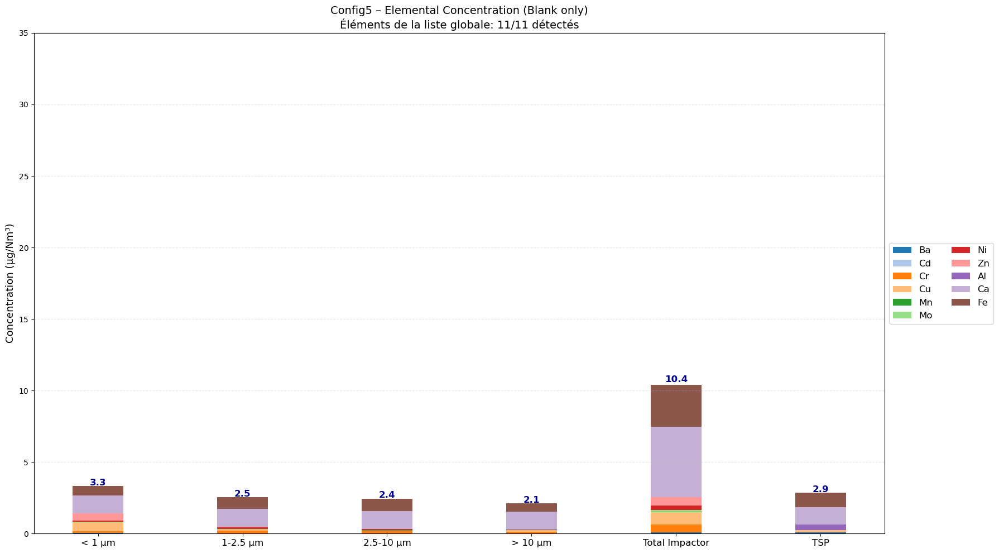


📈 Plotting BLANK only: Config6


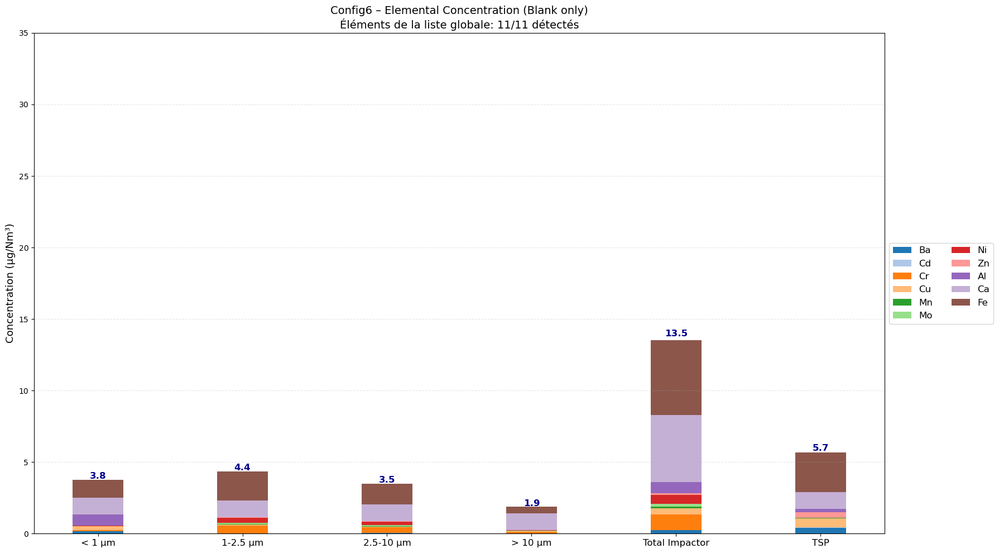


📈 Plotting BLANK only: Config7


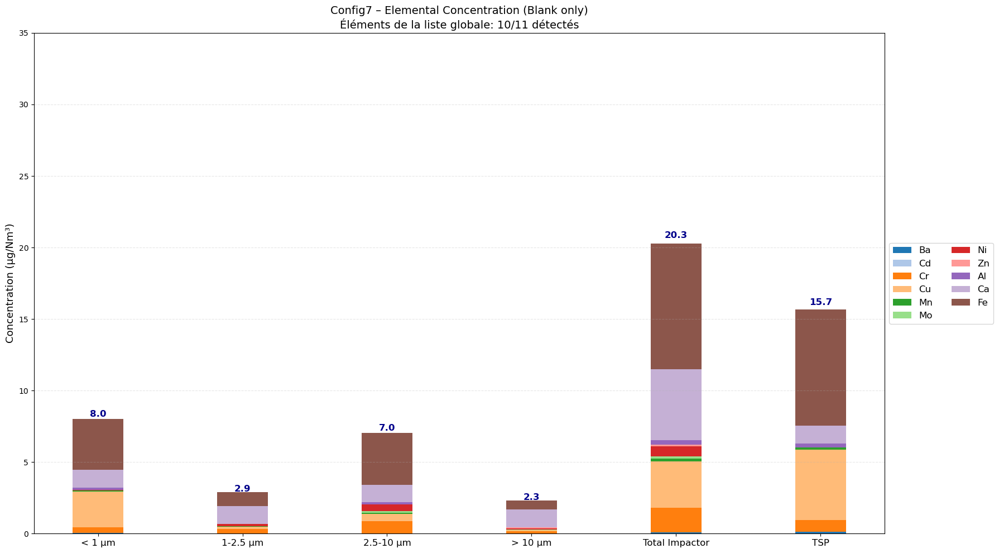


DONE


In [32]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# 1) READ RAW FILE
fichier = r"C:\Users\Grira\OneDrive - Alstom\Documents\Paddle\Campagne2\Impacteur + FH\Masses and elemental composition_PTF2.xlsx"
df_raw = pd.read_excel(fichier, header=None)


# --------------------------
# 2) AUTO-DETECT HEADER ROW
# --------------------------
header_row = None
for i in range(50):
    row = df_raw.iloc[i].astype(str).str.lower()
    if "particle diameter" in row.tolist() and "filter name" in row.tolist():
        header_row = i
        break

df = pd.read_excel(fichier, header=header_row)
df.columns = df.columns.map(lambda x: str(x).strip())

# --------------------------
# 3) FILTER TYPE
# --------------------------
def detect_type(x):
    x = str(x).strip()
    if x.startswith("B"): return "Blank"
    if x.isdigit():       return "Test"
    return None

df["Type"] = df["Filter name"].apply(detect_type)
df = df[df["Type"].notna()]

# --------------------------
# 4) MACHINE
# --------------------------
df["Machine"] = df.iloc[:,0].astype(str).str.extract(
    r"(Config[0-9A-Za-z\-]*)", expand=False
).ffill()

# --------------------------
# 5) SIZE ORDER
# --------------------------
core_sizes = ["< 1 µm","1-2.5 µm","2.5-10 µm","> 10 µm"]
size_order = ["< 1 µm","1-2.5 µm","2.5-10 µm","> 10 µm","Total Impactor","TSP"]

# ===============================================================
# 6) ELEMENT COLUMNS (µg/Nm3 filter) - NO CONVERSION NEEDED
# ===============================================================
elem_cols = [c for c in df.columns if "(µg/Nm3 filter)" in c]

df[elem_cols] = df[elem_cols].apply(pd.to_numeric, errors="coerce").fillna(0)

elem_labels = {e: e.replace(" (µg/Nm3 filter)", "") for e in elem_cols}

# ===============================================================
# 7) MASS CONCENTRATION COLUMN (µg/Nm3) - ALREADY IN EXCEL
# ===============================================================
col_mass_conc = [c for c in df.columns if "Concentration" in c and "(µg/Nm3)" in c][0]
df[col_mass_conc] = pd.to_numeric(df[col_mass_conc], errors="coerce").fillna(0)

# ===============================================================
# 8) COMPUTE TOP‑10 ELEMENTS FOR BLANKS ONLY (CONCENTRATION)
# ===============================================================
print("\n" + "="*80)
print("   TOP 10 ÉLÉMENTS PAR CONFIGURATION (BLANKS UNIQUEMENT)")
print("   Concentration en µg/Nm³")
print("="*80 + "\n")

configs = df["Machine"].unique()

# Dictionnaire pour stocker les top 10 blanks
machine_top10_blanks = {}

for config in configs:

    print(f"\n------ {config} ------")
    print("-" * 50)

    df_config = df[(df["Machine"] == config) & (df["Type"] == "Blank")]

    if df_config.empty:
        print(f"⚠ Pas de données Blank pour {config}\n")
        continue

    total_conc = df_config[elem_cols].sum(axis=0)
    top10 = total_conc.sort_values(ascending=False).head(10)
    
    machine_top10_blanks[config] = top10.index.tolist()

    top10_clean = top10.copy()
    top10_clean.index = [elem_labels[c] for c in top10_clean.index]

    print(f"\n{'Rang':<6} {'Élément':<15} {'Concentration totale (µg/Nm³)':<25}")
    print("-" * 50)

    for rank, (elem, value) in enumerate(top10_clean.items(), 1):
        print(f"{rank:<6} {elem:<15} {value:<25.2f}")

    print("-" * 50)
    print(f"Total des 10 éléments: {top10.sum():.2f} µg/Nm³")
    print(f"Total général (tous éléments blanks): {total_conc.sum():.2f} µg/Nm³")
    if total_conc.sum() > 0:
        print(f"Les 10 éléments représentent: {(top10.sum()/total_conc.sum()*100):.1f}% du total")
    print("\n")

# ===============================================================
# 9) RÉSUMÉ FINAL DES TOP 10 PAR CONFIGURATION (BLANKS)
# ===============================================================
print("\n" + "="*80)
print("RÉSUMÉ FINAL - TOP 10 PAR CONFIGURATION (BLANKS)")
print("Concentration en µg/Nm³")
print("="*80)

for config, top10 in machine_top10_blanks.items():
    print(f"\n🔧 {config}")
    print("-" * 40)
    for i, elem in enumerate(top10, 1):
        elem_name = elem_labels[elem]
        print(f"  {i:2d}. {elem_name}")

# ===============================================================
# 10) LISTE GLOBALE DES ÉLÉMENTS PRÉSENTS DANS LES TOP 10 BLANKS
# ===============================================================
global_elements_blanks = set()
for top10_list in machine_top10_blanks.values():
    global_elements_blanks.update(top10_list)

global_elements_blanks = sorted(list(global_elements_blanks), key=lambda x: elem_labels[x])

print("\n" + "="*80)
print(f"LISTE GLOBALE DES ÉLÉMENTS DANS LES TOP 10 DES BLANKS ({len(global_elements_blanks)} éléments uniques)")
print("Concentration en µg/Nm³")
print("="*80)
for i, elem in enumerate(global_elements_blanks, 1):
    print(f"  {i:2d}. {elem_labels[elem]}")

# ===============================================================
# 11) BLANK PLOTS - SANS MASSE (UNIQUEMENT LES ÉLÉMENTS)
# ===============================================================
print("\n" + "="*80)
print("GÉNÉRATION DES GRAPHIQUES POUR LES BLANKS")
print("(Tous les éléments de la liste globale sont affichés - Concentration en µg/Nm³)")
print("(Sans la barre de concentration massique)")
print("="*80)

# Garder TOUS les éléments de la liste globale
elem_cols_to_plot = [c for c in elem_cols if c in global_elements_blanks]

for machine, dgroup in df.groupby("Machine"):

    print(f"\n📈 Plotting BLANK only: {machine}")

    blanks = dgroup[dgroup["Type"] == "Blank"]

    if blanks.empty:
        print("⚠ No blank data")
        continue

    # ✅ Suppression de col_mass_conc - on ne garde que les éléments
    dplot = blanks[["Particle diameter"] + elem_cols_to_plot].copy()
    dplot["Particle diameter"] = dplot["Particle diameter"].astype(str).str.strip()

    plt.figure(figsize=(18,10))
    width = 0.35
    x = np.arange(len(size_order))

    # Palette fixe basée sur la liste globale
    cmap = plt.get_cmap("tab20")
    colors = {elem: cmap(i % 20) for i, elem in enumerate(elem_cols_to_plot)}

    grouped = dplot.groupby("Particle diameter")[elem_cols_to_plot].sum()
    grouped.loc["Total Impactor"] = grouped.reindex(core_sizes).sum()
    grouped = grouped.reindex(size_order).fillna(0)

    bottom = np.zeros(len(size_order))
    element_totals = grouped.sum(axis=1).values

    # Tracer TOUS les éléments de la liste globale
    for elem in elem_cols_to_plot:
        vals = grouped[elem].values.astype(float)
        plt.bar(
            x,
            vals,
            width,
            bottom=bottom,
            color=colors[elem],
            label=elem_labels[elem]
        )
        bottom += vals

    # Ajout du total élémentaire au-dessus des barres empilées
    for i, total in enumerate(element_totals):
        if total > 0:
            plt.text(
                x[i],
                total * 1.02,
                f"{total:.1f}",
                ha="center",
                fontsize=12,
                fontweight="bold",
                color="darkblue"
            )

    # ✅ SUPPRESSION de la barre de masse concentration (plus de code pour mass_group)

    # Ajustement dynamique de la limite Y basé uniquement sur les éléments
    plt.ylim(0, 35)

    plt.xticks(x, size_order, fontsize=12)
    plt.ylabel("Concentration (µg/Nm³)", fontsize=13)
    
    # Compter les éléments détectés vs totaux
    elements_detected = sum(1 for elem in elem_cols_to_plot if blanks[elem].sum() > 0)
    plt.title(f"{machine} – Elemental Concentration (Blank only)\n"
              f"Éléments de la liste globale: {elements_detected}/{len(elem_cols_to_plot)} détectés", 
              fontsize=14)

    plt.grid(axis='y', linestyle='--', alpha=0.3)
    
    # Légende avec tous les éléments de la liste globale
    plt.legend(loc="center left", bbox_to_anchor=(1, 0.5), fontsize=12, ncol=2 if len(elem_cols_to_plot) > 10 else 1)

    plt.tight_layout()
    plt.show()

print("\n" + "="*80)
print("DONE")
print("="*80)

Blank vs test filters (concentration)

Plot : Config3


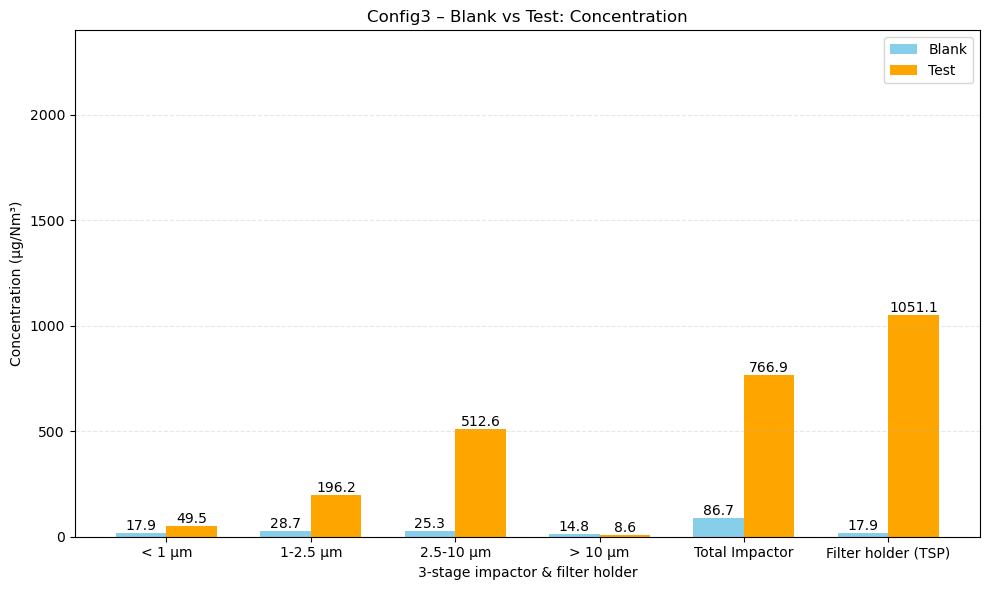

Plot : Config4


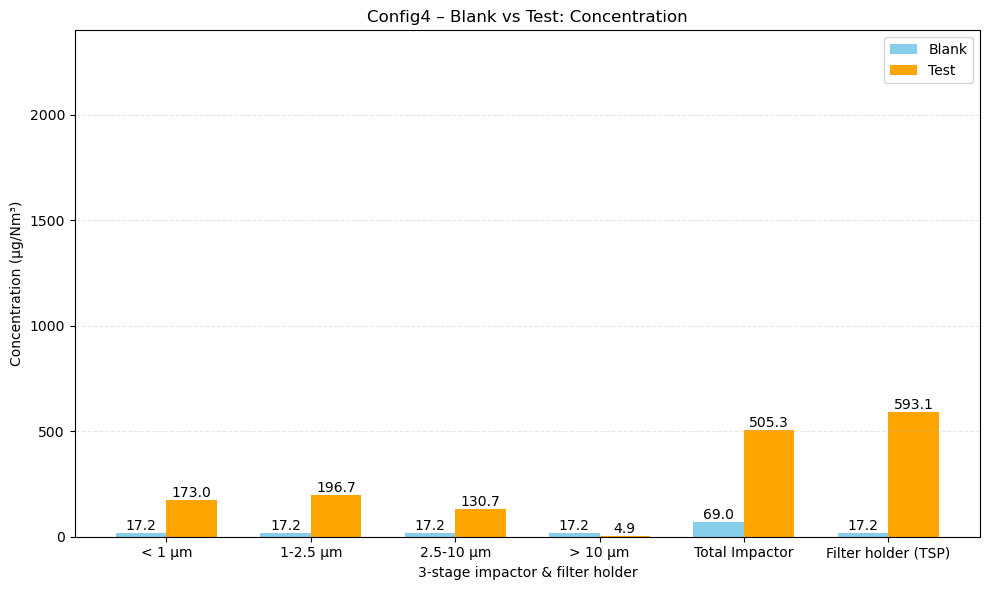

Plot : Config5


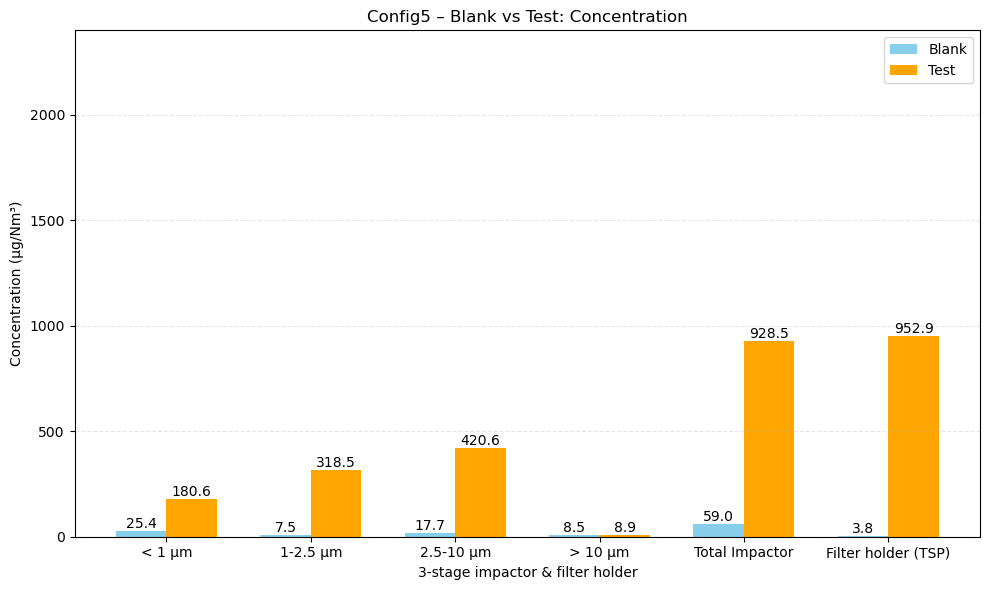

Plot : Config6


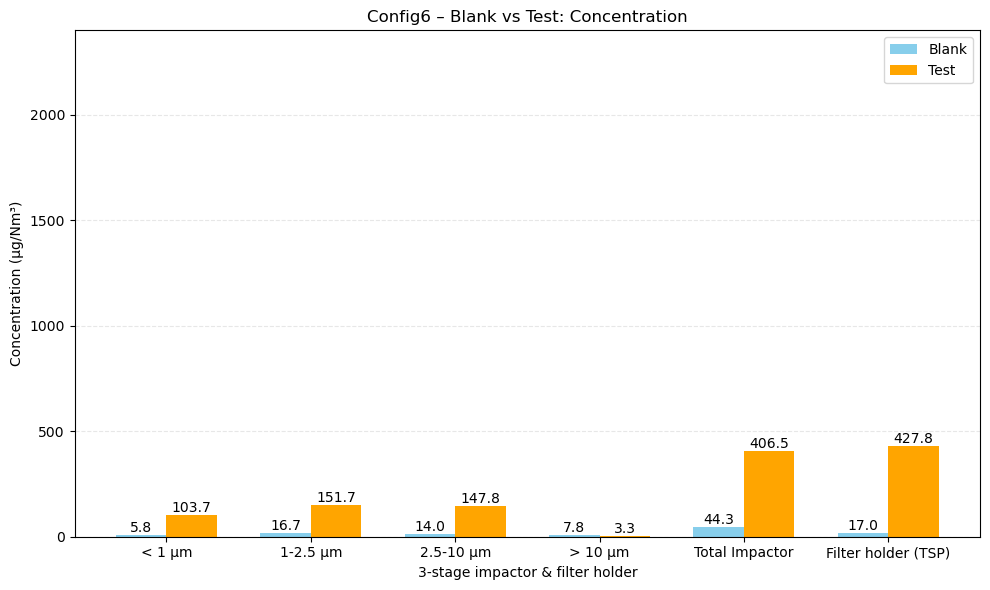

Plot : Config7


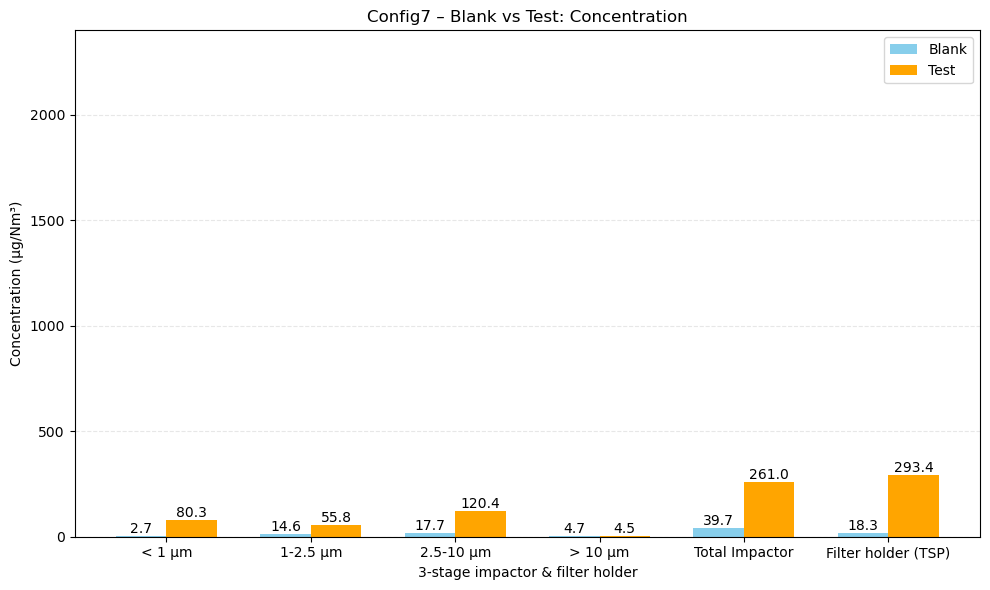

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# 1) READ RAW FILE
fichier = r"C:\Users\Grira\OneDrive - Alstom\Documents\Paddle\Campagne2\Impacteur + FH\Masses and elemental composition_PTF2.xlsx"
df_raw = pd.read_excel(fichier, header=None)

# 2) AUTO-DETECT HEADER ROW
header_row = None
for i in range(50):
    row = df_raw.iloc[i].astype(str).str.lower()
    if row.str.contains("mass").any() and row.str.contains("filter").any():
        header_row = i
        break

if header_row is None:
    raise Exception("Cannot detect header row!")

# 3) READ CLEAN FILE
df = pd.read_excel(fichier, header=header_row)
df.columns = df.columns.map(lambda x: str(x).strip())

# 4) DETECT COLUMNS
filter_cols = [c for c in df.columns if "filter" in c.lower() and "name" in c.lower()]
conc_cols   = [c for c in df.columns if "concentration" in c.lower()]

col_filter = filter_cols[0]
col_conc   = conc_cols[0]

# 5) DETECT TYPE (CORRECTED)
def detect_type(x):
    x = str(x).strip()
    if not x or x == 'nan':
        return None
    if x.startswith("B"):
        return "Blank"
    else:
        return "Test"

df["Type"] = df[col_filter].apply(detect_type)
df = df[df["Type"].notna()]

# 6) DETECT MACHINE
df["Machine"] = df.iloc[:,0].astype(str).str.extract(r"(Config[0-9A-Za-z\-]*)", expand=False).ffill()
df_clean = df.copy()

# 7) GRAPH CODE
col_stage = "Particle diameter"
df[col_stage] = df[col_stage].astype(str).str.strip()

diam_list = ["< 1 µm", "1-2.5 µm", "2.5-10 µm", "> 10 µm", "TSP"]

label_map = {
    "< 1 µm": "< 1 µm",
    "1-2.5 µm": "1-2.5 µm",
    "2.5-10 µm": "2.5-10 µm",
    "> 10 µm": "> 10 µm",
    "TSP": "Filter holder (TSP)",
    "Total Impactor": "Total Impactor"
}

for machine, dgroup in df_clean.groupby("Machine"):

    print(f"Plot : {machine}")

    blanks = dgroup[dgroup["Type"] == "Blank"]
    tests  = dgroup[dgroup["Type"] == "Test"]

    if blanks.empty or tests.empty:
        print("⚠ Not enough data")
        continue

    values_b = {}
    values_t = {}

    for diam in diam_list:
        b = blanks[blanks[col_stage] == diam][col_conc]
        t = tests[tests[col_stage] == diam][col_conc]
        values_b[diam] = float(b.values[0]) if len(b) else None
        values_t[diam] = float(t.values[0]) if len(t) else None

    values_b["Total Impactor"] = sum(values_b[d] for d in diam_list[:-1] if values_b[d] is not None)
    values_t["Total Impactor"] = sum(values_t[d] for d in diam_list[:-1] if values_t[d] is not None)

    final_order = [
        "< 1 µm",
        "1-2.5 µm",
        "2.5-10 µm",
        "> 10 µm",
        "Total Impactor",
        "TSP"
    ]

    conc_blank = []
    conc_test = []
    labels = []

    for diam in final_order:
        if values_b[diam] is not None and values_t[diam] is not None:
            conc_blank.append(values_b[diam])
            conc_test.append(values_t[diam])
            labels.append(label_map[diam])

    x = np.arange(len(labels))
    width = 0.35

    plt.figure(figsize=(10,6))

    bars_blank = plt.bar(x - width/2, conc_blank, width, label="Blank", color="skyblue")
    bars_test  = plt.bar(x + width/2, conc_test,  width, label="Test",  color="orange")

    for bar in bars_blank:
        y = bar.get_height()
        plt.text(bar.get_x() + bar.get_width()/2, y, f"{y:.1f}", ha='center', va='bottom')

    for bar in bars_test:
        y = bar.get_height()
        plt.text(bar.get_x() + bar.get_width()/2, y, f"{y:.1f}", ha='center', va='bottom')

    plt.ylim(0, 2400)
    plt.xticks(x, labels)
    plt.ylabel("Concentration (µg/Nm³)")
    plt.xlabel("3-stage impactor & filter holder")
    plt.title(f"{machine} – Blank vs Test: Concentration")
    plt.grid(axis='y', linestyle='--', alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()

### Tests filters

Masses

Plot : Config3


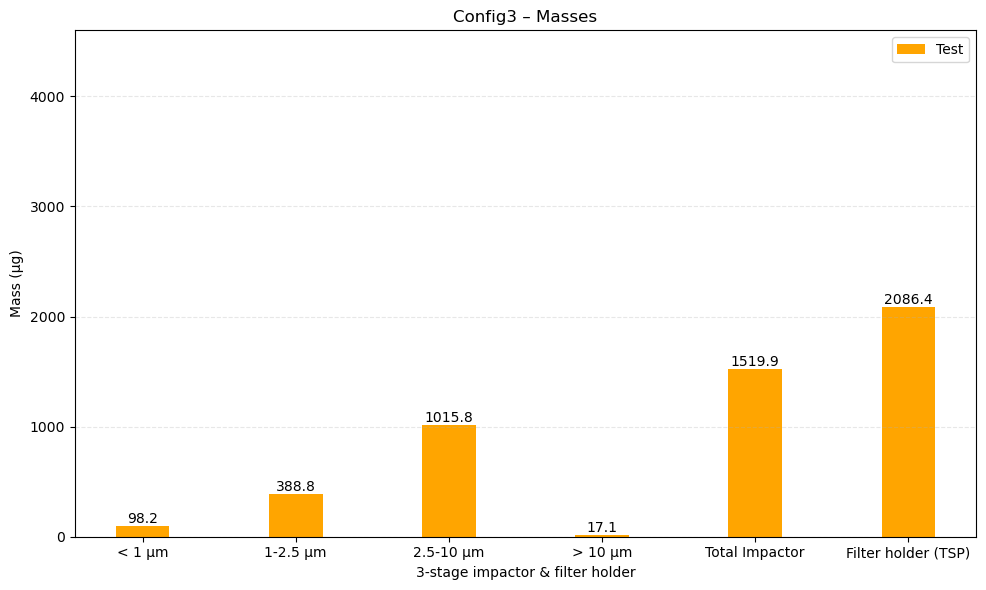

Plot : Config4


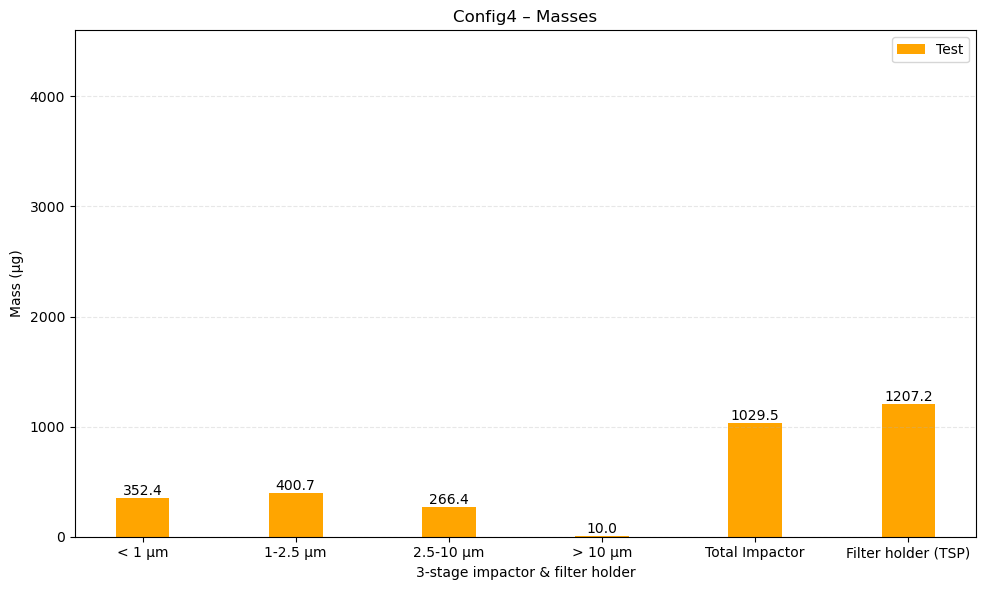

Plot : Config5


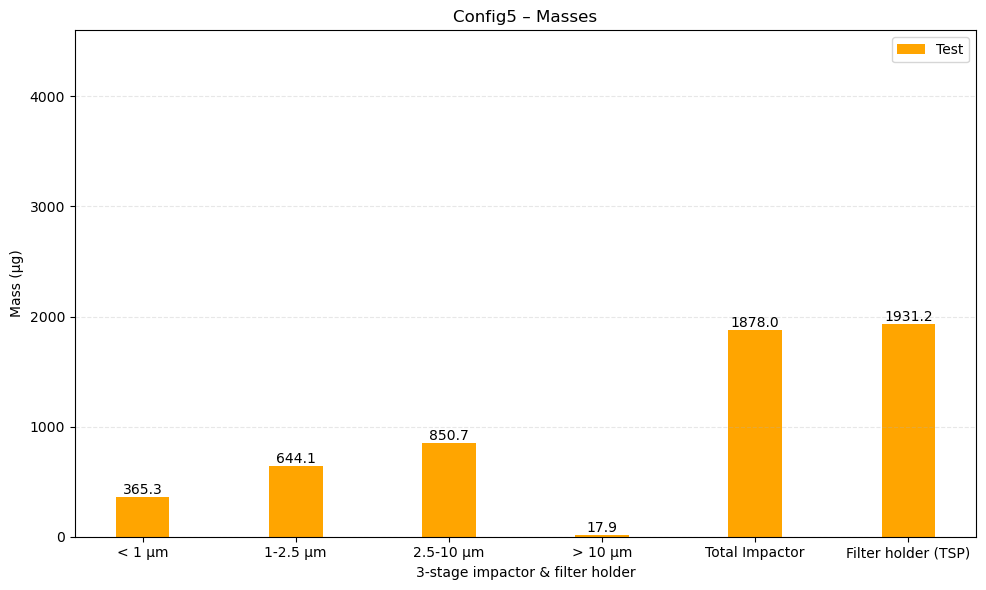

Plot : Config6


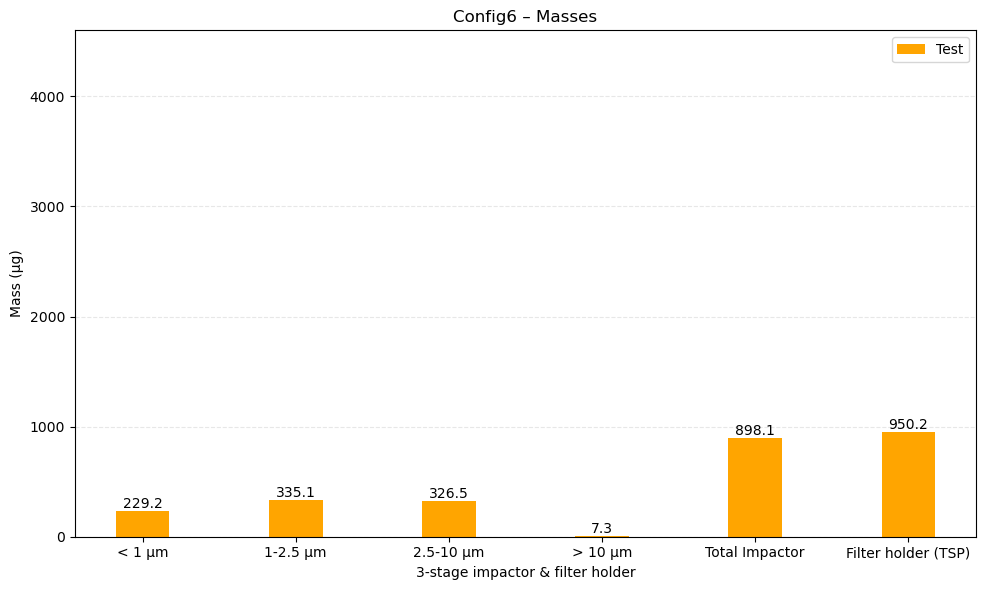

Plot : Config7


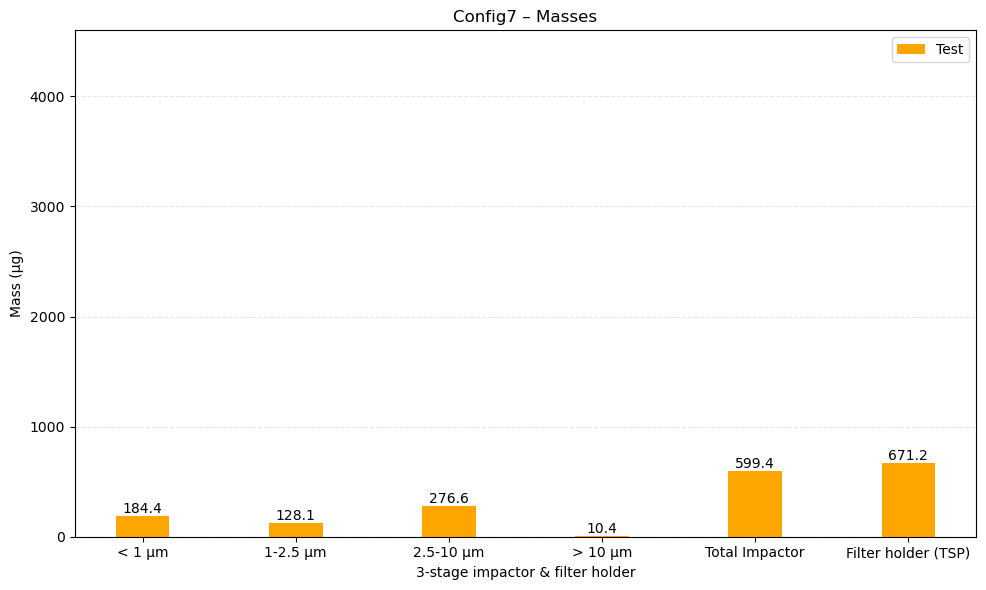

In [36]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# 1) READ RAW FILE
fichier = r"C:\Users\Grira\OneDrive - Alstom\Documents\Paddle\Campagne2\Impacteur + FH\Masses and elemental composition_PTF2.xlsx"
df_raw = pd.read_excel(fichier, header=None)

# 2) AUTO-DETECT HEADER ROW
header_row = None
for i in range(50):
    row = df_raw.iloc[i].astype(str).str.lower()
    if row.str.contains("mass").any() and row.str.contains("filter").any():
        header_row = i
        break

df = pd.read_excel(fichier, header=header_row)
df.columns = df.columns.map(lambda x: str(x).strip())

# 3) DETECT COLUMNS
filter_cols = [c for c in df.columns if "filter" in c.lower() and "name" in c.lower()]
mass_cols   = [c for c in df.columns if "mass" in c.lower()]

col_filter = filter_cols[0]
col_mass   = mass_cols[0]

# 4) DETECT TYPE
def detect_type(x):
    x = str(x).strip()
    if not x or x == 'nan':
        return None
    if x.startswith("B"):
        return "Blank"
    else:
        return "Test"   # tous les autres noms de filtres sont des tests

df["Type"] = df[col_filter].apply(detect_type)
df = df[df["Type"].notna()]

# 5) DETECT MACHINE
df["Machine"] = df.iloc[:,0].astype(str).str.extract(r"(Config[0-9A-Za-z\-]*)", expand=False).ffill()

df_clean = df.copy()

# 6) GRAPH SETTINGS
col_stage = "Particle diameter"
df[col_stage] = df[col_stage].astype(str).str.strip()

diam_list = ["< 1 µm","1-2.5 µm","2.5-10 µm","> 10 µm","TSP"]

label_map = {
    "< 1 µm": "< 1 µm",
    "1-2.5 µm": "1-2.5 µm",
    "2.5-10 µm": "2.5-10 µm",
    "> 10 µm": "> 10 µm",
    "TSP": "Filter holder (TSP)",
    "Total Impactor": "Total Impactor"
}

# ------------------------
# 🚀 TEST-ONLY VERSION
# ------------------------
for machine, dgroup in df_clean.groupby("Machine"):

    print(f"Plot : {machine}")

    tests  = dgroup[dgroup["Type"] == "Test"]

    if tests.empty:
        print("⚠ Not enough data")
        continue

    values_t = {}

    # Extract TEST mass values and convert mg → µg
    for diam in diam_list:
        t = tests[tests[col_stage] == diam][col_mass]
        values_t[diam] = float(t.values[0]) * 1000 if len(t) else None

    # Total Impactor = sum all impactor stages
    values_t["Total Impactor"] = sum([values_t[d] for d in diam_list[:-1] if values_t[d] is not None])

    final_order = [
        "< 1 µm",
        "1-2.5 µm",
        "2.5-10 µm",
        "> 10 µm",
        "Total Impactor",
        "TSP"
    ]

    masses_test = []
    labels = []

    for diam in final_order:
        if values_t[diam] is not None:
            masses_test.append(values_t[diam])
            labels.append(label_map[diam])

    x = np.arange(len(labels))
    width = 0.35

    plt.figure(figsize=(10,6))

    bars_test = plt.bar(x, masses_test, width, label="Test", color="orange")

    # Annotate
    for bar in bars_test:
        y = bar.get_height()
        plt.text(bar.get_x() + bar.get_width()/2, y,
                 f"{y:.1f}", ha='center', va='bottom')

    plt.ylim(0, 4600)
    plt.xticks(x, labels)
    plt.ylabel("Mass (µg)")   # <<<< UPDATED
    plt.xlabel("3-stage impactor & filter holder")
    plt.title(f"{machine} – Masses")
    plt.legend()
    plt.grid(axis='y', linestyle='--', alpha=0.3)

    plt.tight_layout()
    plt.show()

Elemental composition (in mass)


Plotting TEST only: Config3


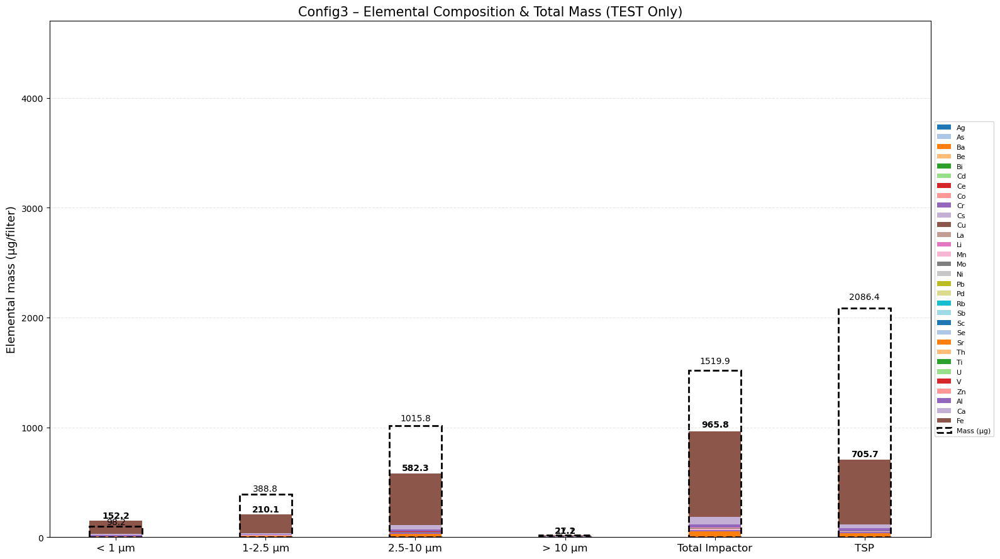


Plotting TEST only: Config4


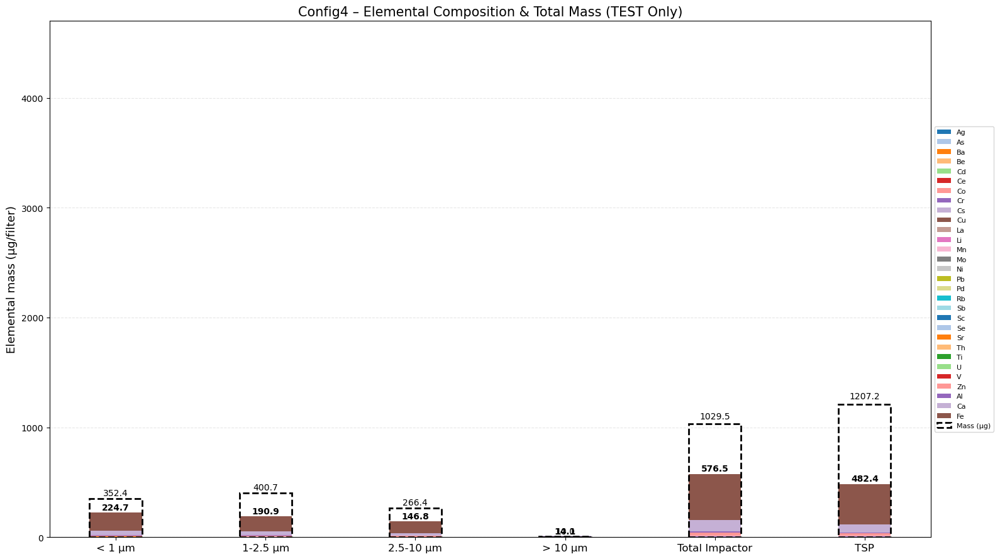


Plotting TEST only: Config5


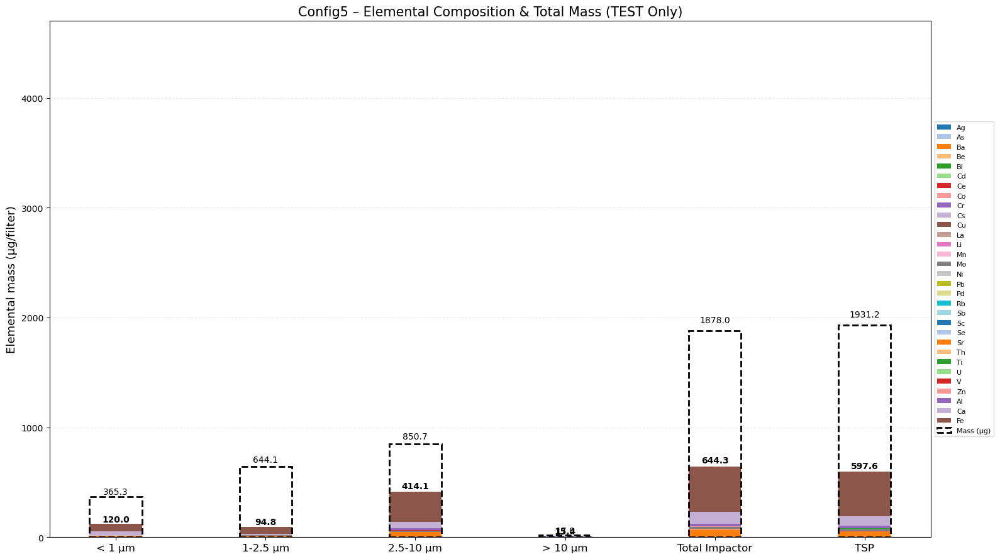


Plotting TEST only: Config6


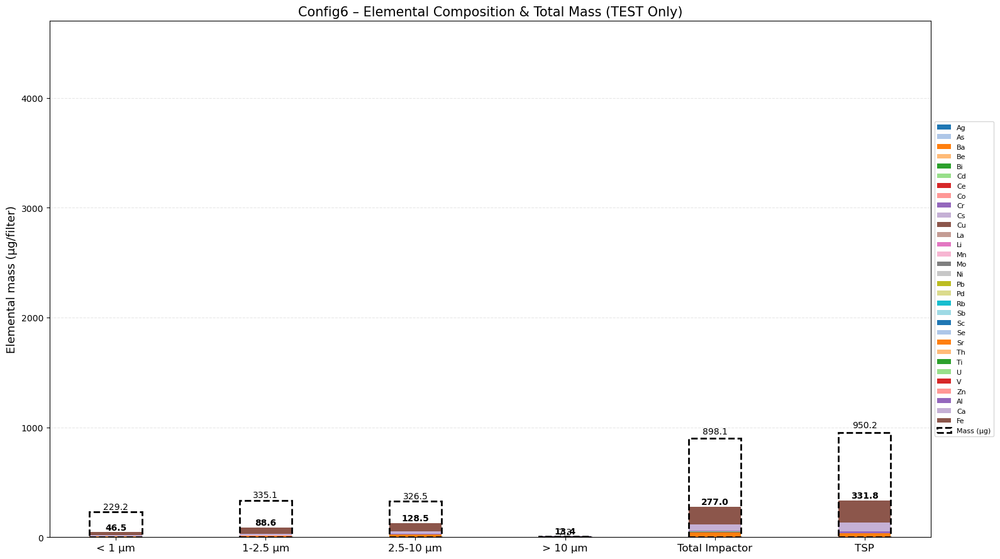


Plotting TEST only: Config7


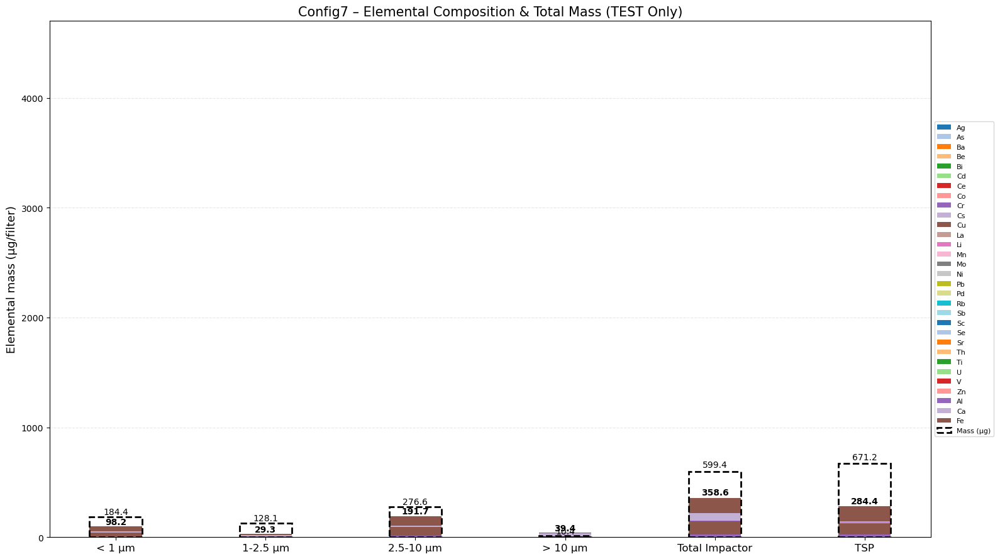


   TOP 10 ÉLÉMENTS PAR CONFIGURATION (TESTS UNIQUEMENT)


------ Config3 ------
--------------------------------------------------

Rang   Élément         Masse totale (µg)   
--------------------------------------------------
1      Fe              1371.40             
2      Ca              102.47              
3      Ba              88.57               
4      Al              51.55               
5      Cr              22.06               
6      Mn              12.27               
7      Mo              9.21                
8      V               3.73                
9      Cu              3.54                
10     Sr              2.37                
--------------------------------------------------
Total des 10 éléments: 1667.17 µg
Total général (tous éléments tests): 1671.55 µg
Les 10 éléments représentent: 99.7% du total



------ Config4 ------
--------------------------------------------------

Rang   Élément         Masse totale (µg)   
---------------------------------

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# 1) READ RAW FILE
fichier = r"C:\Users\Grira\OneDrive - Alstom\Documents\Paddle\Campagne2\Impacteur + FH\Masses and elemental composition_PTF2.xlsx"
df_raw = pd.read_excel(fichier, header=None)

# ============================================================
# 2) AUTO-DETECT HEADER ROW
# ============================================================
header_row = None
for i in range(50):
    row = df_raw.iloc[i].astype(str).str.lower()
    if "particle diameter" in row.tolist() and "filter name" in row.tolist():
        header_row = i
        break

df = pd.read_excel(fichier, header=header_row)
df.columns = df.columns.map(lambda x: str(x).strip())

# ============================================================
# 3) FILTER TYPE (Blank / Test)
# ============================================================
def detect_type(x):
    x = str(x).strip()
    if not x or x == 'nan':
        return None
    if x.startswith("B"):
        return "Blank"
    else:
        return "Test"

df["Type"] = df["Filter name"].apply(detect_type)
df = df[df["Type"].notna()]

# ============================================================
# 4) MACHINE NAME EXTRACTION
# ============================================================
df["Machine"] = df.iloc[:,0].astype(str).str.extract(
    r"(Config[0-9A-Za-z\-]*)", expand=False
).ffill()

# ============================================================
# 5) PARTICLE SIZE ORDER
# ============================================================
core_sizes = ["< 1 µm","1-2.5 µm","2.5-10 µm","> 10 µm"]
size_order = ["< 1 µm","1-2.5 µm","2.5-10 µm","> 10 µm","Total Impactor","TSP"]

# ============================================================
# 6) ELEMENTAL COLUMNS (ng/filter → µg/filter)
# ============================================================
elem_cols = [c for c in df.columns if "(ng/filter)" in c]

df[elem_cols] = df[elem_cols].apply(pd.to_numeric, errors="coerce").fillna(0)
df[elem_cols] = df[elem_cols] / 1000  # convert to µg/filter

elem_labels = {e: e.replace(" (ng/filter)", "") for e in elem_cols}

# ============================================================
# 7) MASS COLUMN (mg → µg)
# ============================================================
col_mass = [c for c in df.columns if "mass" in c.lower()][0]
df[col_mass] = pd.to_numeric(df[col_mass], errors="coerce").fillna(0)
df[col_mass] = df[col_mass] * 1000  # mg → µg

# ============================================================
# 8) PLOTS FOR TEST FILTERS ONLY
# ============================================================
for machine, dgroup in df.groupby("Machine"):

    print(f"\nPlotting TEST only: {machine}")

    tests = dgroup[dgroup["Type"] == "Test"]

    if tests.empty:
        print("⚠ No TEST data")
        continue

    dplot = tests[["Particle diameter", col_mass] + elem_cols].copy()
    dplot["Particle diameter"] = dplot["Particle diameter"].astype(str).str.strip()

    plt.figure(figsize=(16,9))
    width = 0.35
    x = np.arange(len(size_order))

    cmap = plt.get_cmap("tab20")
    colors = {e: cmap(i % 20) for i, e in enumerate(elem_cols)}

    # ----------- ELEMENT GROUPING -----------
    grouped = dplot.groupby("Particle diameter")[elem_cols].sum()
    grouped.loc["Total Impactor"] = grouped.reindex(core_sizes).sum()
    grouped = grouped.reindex(size_order).fillna(0)

    cols_to_keep = [c for c in elem_cols if grouped[c].sum() != 0]
    grouped = grouped[cols_to_keep]
    colors_filtered = {e: colors[e] for e in cols_to_keep}

    bottom = np.zeros(len(size_order))

    # ----------- STACKED BAR ELEMENTAL MASS -----------
    for elem in cols_to_keep:
        vals = grouped[elem].values.astype(float)
        plt.bar(
            x,
            vals,
            width,
            bottom=bottom,
            color=colors_filtered[elem],
            label=elem_labels[elem]
        )
        bottom += vals

    # ----------- TOTAL ELEMENTAL MASS LABELS -----------
    totals = grouped.sum(axis=1).values
    for i, total in enumerate(totals):
        if total > 0:
            plt.text(
                x[i], total * 1.02, f"{total:.1f}",
                ha="center", va="bottom",
                fontsize=10, fontweight="bold"
            )

    # ----------- OVERLAY TOTAL MASS (µg) -----------
    mass_group = dplot.groupby("Particle diameter")[col_mass].sum()
    mass_group.loc["Total Impactor"] = mass_group.reindex(core_sizes).sum()
    mass_group = mass_group.reindex(size_order).fillna(0)

    for i, val in enumerate(mass_group):
        if val > 0:
            plt.bar(
                x[i],
                val,
                width,
                fill=False,
                edgecolor="black",
                linestyle="--",
                linewidth=2,
                label="Mass (µg)" if i == 0 else None
            )
            plt.text(
                x[i], val * 1.03,
                f"{val:.1f}",
                ha="center", va="bottom",
                fontsize=10, 
                color="black"
            )

    # ----------- FIGURE FORMATTING -----------
    plt.ylim(0, 4700)
    plt.xticks(x, size_order, fontsize=12)
    plt.ylabel("Elemental mass (µg/filter)", fontsize=13)
    plt.title(f"{machine} – Elemental Composition & Total Mass (TEST Only)", fontsize=15)

    plt.grid(axis='y', linestyle='--', alpha=0.3)
    plt.legend(loc="center left", bbox_to_anchor=(1,0.5), fontsize=8)

    plt.tight_layout()
    plt.show()

# ============================================================
# 9) TOP‑10 ELEMENTS PER CONFIGURATION (TESTS ONLY) - CORRIGÉ
# ============================================================
print("\n" + "="*80)
print("   TOP 10 ÉLÉMENTS PAR CONFIGURATION (TESTS UNIQUEMENT)")
print("="*80 + "\n")

configs = df["Machine"].unique()

# Dictionnaire pour stocker les top 10 tests
machine_top10_tests = {}

for config in configs:

    print(f"\n------ {config} ------")
    print("-" * 50)

    # ✅ CORRECTION : Filtrer uniquement les TESTS
    df_config = df[(df["Machine"] == config) & (df["Type"] == "Test")]

    if df_config.empty:
        print(f"⚠ Pas de données Test pour {config}\n")
        continue

    # Somme uniquement sur les tests
    total_mass = df_config[elem_cols].sum(axis=0)

    # Top 10 des tests
    top10 = total_mass.sort_values(ascending=False).head(10)
    
    # Stocker dans un dictionnaire
    machine_top10_tests[config] = top10.index.tolist()

    # Nettoyer les noms pour l'affichage
    top10_clean = top10.copy()
    top10_clean.index = [elem_labels[c] for c in top10_clean.index]

    # Affichage détaillé
    print(f"\n{'Rang':<6} {'Élément':<15} {'Masse totale (µg)':<20}")
    print("-" * 50)

    for rank, (elem, value) in enumerate(top10_clean.items(), 1):
        print(f"{rank:<6} {elem:<15} {value:<20.2f}")

    print("-" * 50)
    print(f"Total des 10 éléments: {top10.sum():.2f} µg")
    print(f"Total général (tous éléments tests): {total_mass.sum():.2f} µg")
    if total_mass.sum() > 0:
        print(f"Les 10 éléments représentent: {(top10.sum()/total_mass.sum()*100):.1f}% du total")
    print("\n")

# ============================================================
# 10) RÉSUMÉ FINAL DES TOP 10 PAR CONFIGURATION (TESTS)
# ============================================================
print("\n" + "="*80)
print("RÉSUMÉ FINAL - TOP 10 PAR CONFIGURATION (TESTS)")
print("="*80)

for config, top10 in machine_top10_tests.items():
    print(f"\n🔧 {config}")
    print("-" * 40)
    for i, elem in enumerate(top10, 1):
        elem_name = elem_labels[elem]
        print(f"  {i:2d}. {elem_name}")

# ============================================================
# 11) LISTE GLOBALE DES ÉLÉMENTS PRÉSENTS DANS LES TOP 10 TESTS
# ============================================================
global_elements_tests = set()
for top10_list in machine_top10_tests.values():
    global_elements_tests.update(top10_list)

global_elements_tests = sorted(list(global_elements_tests), key=lambda x: elem_labels[x])

print("\n" + "="*80)
print(f"LISTE GLOBALE DES ÉLÉMENTS DANS LES TOP 10 DES TESTS ({len(global_elements_tests)} éléments uniques)")
print("="*80)
for i, elem in enumerate(global_elements_tests, 1):
    print(f"  {i:2d}. {elem_labels[elem]}")

print("\n" + "="*80)
print("DONE")
print("="*80)

Elemental composition (in mass - top10)


   TOP 10 ÉLÉMENTS PAR CONFIGURATION (TESTS UNIQUEMENT)


------ Config3 ------
--------------------------------------------------

Rang   Élément         Masse totale (µg)   
--------------------------------------------------
1      Fe              1371.40             
2      Ca              102.47              
3      Ba              88.57               
4      Al              51.55               
5      Cr              22.06               
6      Mn              12.27               
7      Mo              9.21                
8      V               3.73                
9      Cu              3.54                
10     Sr              2.37                
--------------------------------------------------
Total des 10 éléments: 1667.17 µg
Total général (tous éléments tests): 1671.55 µg
Les 10 éléments représentent: 99.7% du total



------ Config4 ------
--------------------------------------------------

Rang   Élément         Masse totale (µg)   
---------------------------------

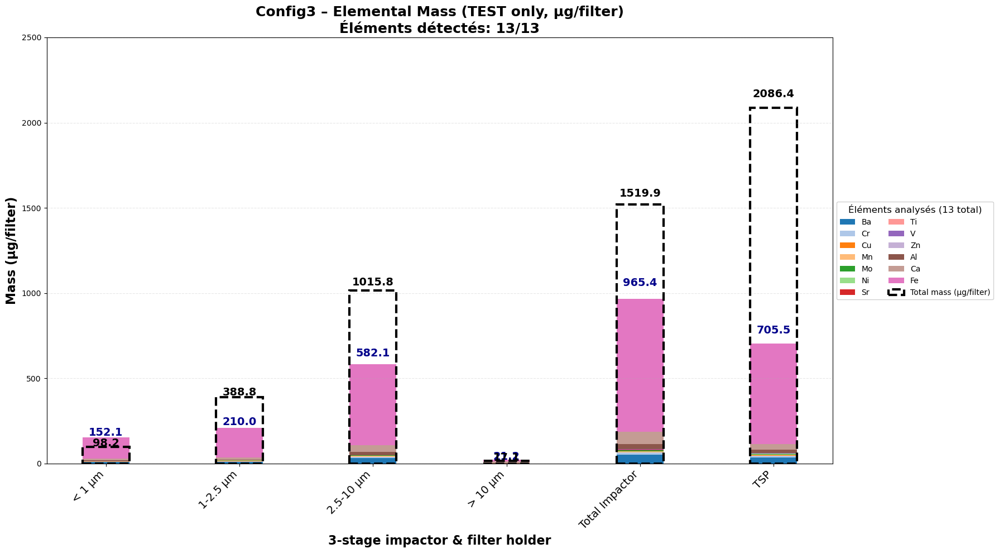


📈 Plotting TEST only: Config4


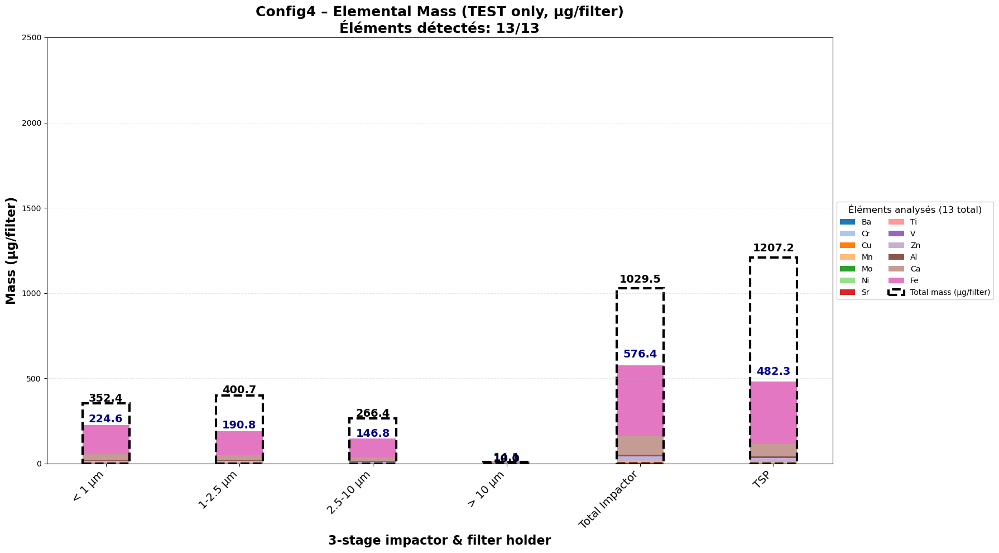


📈 Plotting TEST only: Config5


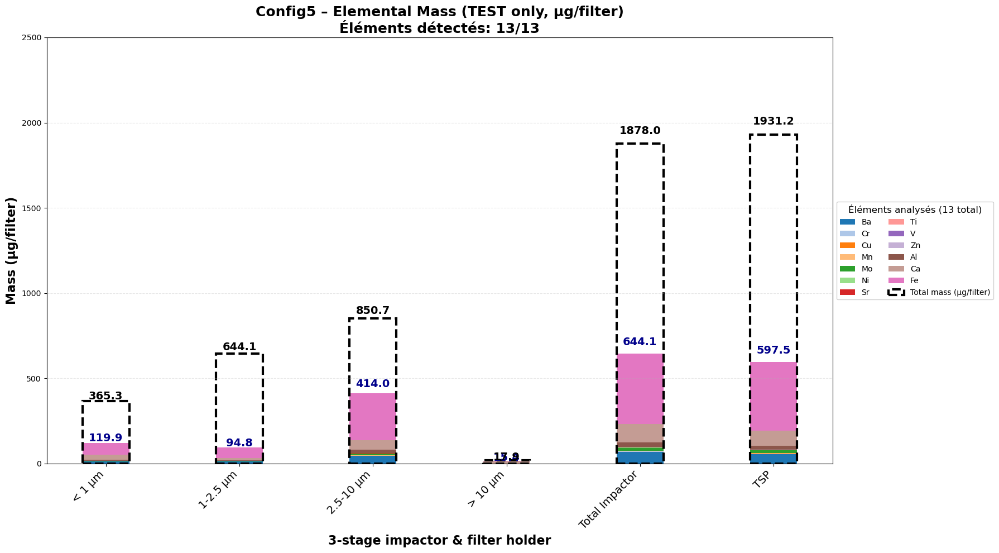


📈 Plotting TEST only: Config6


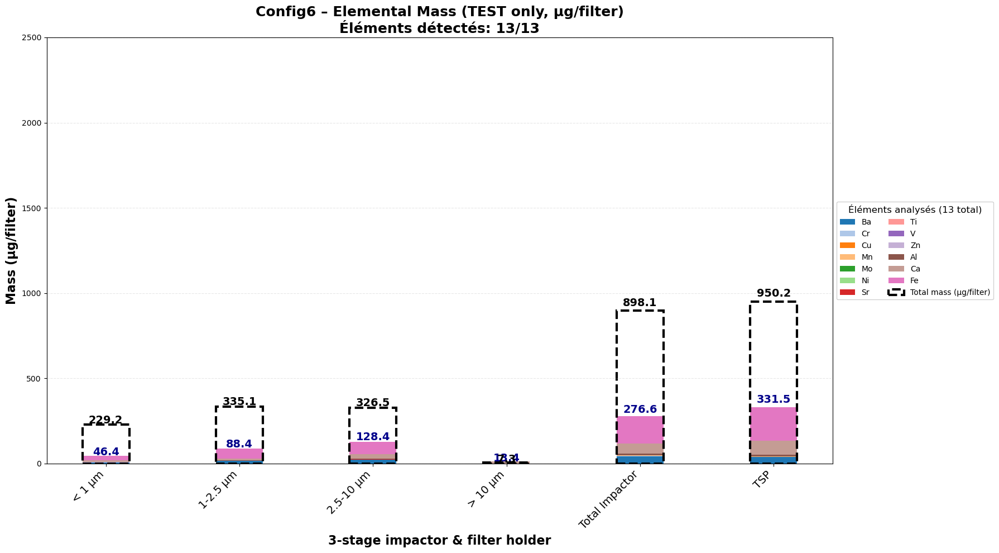


📈 Plotting TEST only: Config7


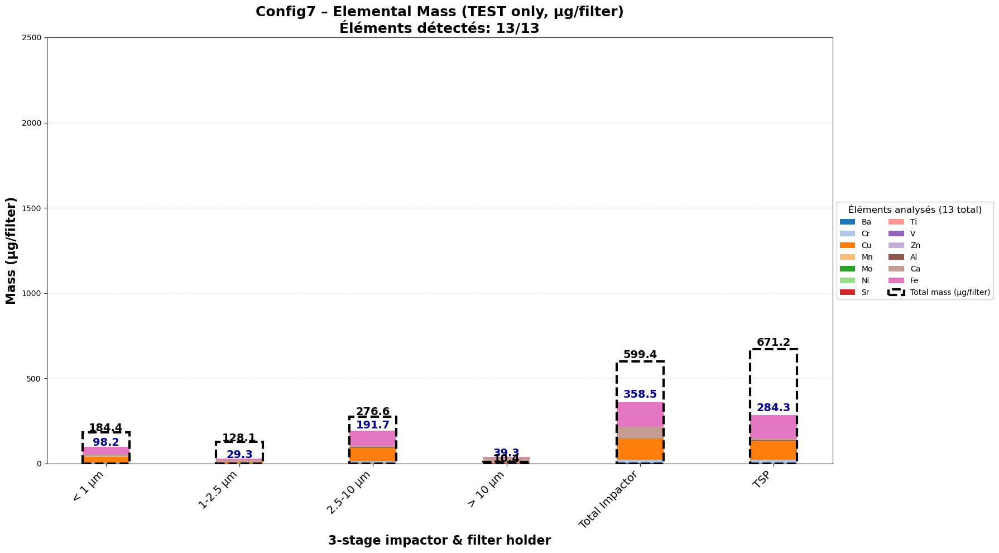


RÉSUMÉ FINAL
Nombre total de configurations: 5
Nombre total d'éléments uniques dans tous les top 10: 13

Liste globale des éléments (ordre alphabétique):
   1. Al
   2. Ba
   3. Ca
   4. Cr
   5. Cu
   6. Fe
   7. Mn
   8. Mo
   9. Ni
  10. Sr
  11. Ti
  12. V
  13. Zn

Éléments par configuration (top 10 des tests):

  Config3:
    - Fe
    - Ca
    - Ba
    - Al
    - Cr
    - Mn
    - Mo
    - V
    - Cu
    - Sr

  Config4:
    - Fe
    - Ca
    - Zn
    - Al
    - Cr
    - Mn
    - Cu
    - Ba
    - Mo
    - Ti

  Config5:
    - Fe
    - Ca
    - Ba
    - Al
    - Mo
    - Mn
    - Cr
    - Cu
    - Sr
    - Zn

  Config6:
    - Fe
    - Ca
    - Ba
    - Al
    - Cu
    - Mn
    - Sr
    - Cr
    - Ti
    - Ni

  Config7:
    - Fe
    - Cu
    - Ca
    - Cr
    - Al
    - Mn
    - Ba
    - Zn
    - Ni
    - Ti

DONE


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# 1) READ RAW FILE
fichier = r"C:\Users\Grira\OneDrive - Alstom\Documents\Paddle\Campagne2\Impacteur + FH\Masses and elemental composition_PTF2.xlsx"
df_raw = pd.read_excel(fichier, header=None)

# --------------------------
# 2) AUTO-DETECT HEADER ROW
# --------------------------
header_row = None
for i in range(50):
    row = df_raw.iloc[i].astype(str).str.lower()
    if "particle diameter" in row.tolist() and "filter name" in row.tolist():
        header_row = i
        break

df = pd.read_excel(fichier, header=header_row)
df.columns = df.columns.map(str)

# --------------------------
# 3) FILTER TYPE (Blank / Test)
# --------------------------
def detect_type(x):
    x = str(x).strip()
    if not x or x == 'nan':
        return None
    if x.startswith("B"):
        return "Blank"
    else:
        return "Test"

df["Type"] = df["Filter name"].apply(detect_type)
df = df[df["Type"].notna()]

# --------------------------
# 4) MACHINE NAME
# --------------------------
df["Machine"] = df.iloc[:,0].astype(str).str.extract(
    r"(Config[0-9A-Za-z\-]*)", expand=False
).ffill()

# ===============================================================
# 5) ELEMENT COLUMNS IN ng/filter → convert to µg/filter
# ===============================================================
elem_cols = [c for c in df.columns if "(ng/filter)" in c]

df[elem_cols] = df[elem_cols].apply(pd.to_numeric, errors="coerce").fillna(0)
df[elem_cols] /= 1000   # ng → µg

clean_names = {c: c.replace(" (ng/filter)", "") for c in elem_cols}

# ===============================================================
# 6) MASS COLUMN (mg → µg/filter)
# ===============================================================
col_mass = [c for c in df.columns if "mass" in c.lower()][0]

df[col_mass] = pd.to_numeric(df[col_mass], errors="coerce").fillna(0)
df[col_mass] *= 1000  # mg → µg

# ===============================================================
# 7) COMPUTE TOP‑10 ELEMENTS FOR TESTS ONLY
# ===============================================================
print("\n" + "="*80)
print("   TOP 10 ÉLÉMENTS PAR CONFIGURATION (TESTS UNIQUEMENT)")
print("="*80 + "\n")

configs = df["Machine"].unique()

# Dictionnaire pour stocker les top 10 tests
machine_top10_tests = {}

for config in configs:

    print(f"\n------ {config} ------")
    print("-" * 50)

    df_config = df[(df["Machine"] == config) & (df["Type"] == "Test")]

    if df_config.empty:
        print(f"⚠ Pas de données Test pour {config}\n")
        continue

    total_mass = df_config[elem_cols].sum(axis=0)
    top10 = total_mass.sort_values(ascending=False).head(10)
    
    machine_top10_tests[config] = top10.index.tolist()

    top10_clean = top10.copy()
    top10_clean.index = [clean_names[c] for c in top10_clean.index]

    print(f"\n{'Rang':<6} {'Élément':<15} {'Masse totale (µg)':<20}")
    print("-" * 50)

    for rank, (elem, value) in enumerate(top10_clean.items(), 1):
        print(f"{rank:<6} {elem:<15} {value:<20.2f}")

    print("-" * 50)
    print(f"Total des 10 éléments: {top10.sum():.2f} µg")
    print(f"Total général (tous éléments tests): {total_mass.sum():.2f} µg")
    if total_mass.sum() > 0:
        print(f"Les 10 éléments représentent: {(top10.sum()/total_mass.sum()*100):.1f}% du total")
    print("\n")

# ===============================================================
# 8) RÉSUMÉ FINAL DES TOP 10 PAR CONFIGURATION (TESTS)
# ===============================================================
print("\n" + "="*80)
print("RÉSUMÉ FINAL - TOP 10 PAR CONFIGURATION (TESTS)")
print("="*80)

for config, top10 in machine_top10_tests.items():
    print(f"\n🔧 {config}")
    print("-" * 40)
    for i, elem in enumerate(top10, 1):
        elem_name = clean_names[elem]
        print(f"  {i:2d}. {elem_name}")

# ===============================================================
# 9) LISTE GLOBALE DES ÉLÉMENTS PRÉSENTS DANS LES TOP 10 TESTS
# ===============================================================
global_elements_tests = set()
for top10_list in machine_top10_tests.values():
    global_elements_tests.update(top10_list)

global_elements_tests = sorted(list(global_elements_tests), key=lambda x: clean_names[x])

print("\n" + "="*80)
print(f"LISTE GLOBALE DES ÉLÉMENTS DANS LES TOP 10 DES TESTS ({len(global_elements_tests)} éléments uniques)")
print("="*80)
for i, elem in enumerate(global_elements_tests, 1):
    print(f"  {i:2d}. {clean_names[elem]}")

# ===============================================================
# 10) PLOT PER MACHINE WITH GLOBAL TOP-10 ELEMENTS
# ===============================================================
print("\n" + "="*80)
print("GÉNÉRATION DES GRAPHIQUES POUR LES TESTS")
print("(Tous les éléments de la liste globale sont affichés - Même légende sur toutes les configs)")
print("="*80)

core_sizes = ["< 1 µm","1-2.5 µm","2.5-10 µm","> 10 µm"]
size_order = ["< 1 µm","1-2.5 µm","2.5-10 µm","> 10 µm","Total Impactor","TSP"]

# Garder TOUS les éléments de la liste globale
elem_cols_to_plot = [c for c in elem_cols if c in global_elements_tests]

# Palette fixe basée sur la liste globale (MÊME POUR TOUTES LES CONFIGS)
cmap = plt.get_cmap("tab20")
colors = {elem: cmap(i % 20) for i, elem in enumerate(elem_cols_to_plot)}

for machine, dgroup in df.groupby("Machine"):

    print(f"\n📈 Plotting TEST only: {machine}")

    tests = dgroup[dgroup["Type"] == "Test"]
    if tests.empty:
        print("⚠ No test data")
        continue

    # Garder TOUS les éléments de la liste globale (même ceux à zéro)
    dplot = tests[["Particle diameter", col_mass] + elem_cols_to_plot].copy()
    dplot["Particle diameter"] = dplot["Particle diameter"].astype(str).str.strip()

    plt.figure(figsize=(18,10))
    width = 0.35
    x = np.arange(len(size_order))

    # --- STACKED ELEMENT MASS ---
    grouped = dplot.groupby("Particle diameter")[elem_cols_to_plot].sum()
    grouped.loc["Total Impactor"] = grouped.reindex(core_sizes).sum()
    grouped = grouped.reindex(size_order).fillna(0)

    bottom = np.zeros(len(size_order))
    
    # Calculate total elemental mass for each bar
    element_totals = grouped.sum(axis=1).values

    # Tracer TOUS les éléments de la liste globale
    for elem in elem_cols_to_plot:
        vals = grouped[elem].values.astype(float)
        plt.bar(
            x,
            vals,
            width,
            bottom=bottom,
            color=colors[elem],
            label=clean_names[elem]  # MÊME LÉGENDE POUR TOUTES LES CONFIGS
        )
        bottom += vals

    # --- ADD ELEMENTAL TOTAL MASS ON TOP OF STACKED BARS ---
    for i, total in enumerate(element_totals):
        if total > 0:
            plt.text(
                x[i],
                total * 1.08,
                f"{total:.1f}",
                ha="center",
                fontsize=14,
                fontweight="bold",
                color="darkblue"
            )

    # --- MASS BAR FROM EXCEL (µg/filter) ---
    mass_group = dplot.groupby("Particle diameter")[col_mass].sum()
    mass_group.loc["Total Impactor"] = mass_group.reindex(core_sizes).sum()
    mass_group = mass_group.reindex(size_order).fillna(0)

    for i, val in enumerate(mass_group.values):
        plt.bar(
            x[i],
            val,
            width,
            fill=False,
            edgecolor="black",
            linestyle="--",
            linewidth=3,
            label="Total mass (µg/filter)" if i == 0 else None
        )
        plt.text(
            x[i],
            val * 1.03,
            f"{val:.1f}",
            ha="center",
            fontsize=14,
            color="black",
            fontweight="bold"
        )

    # --- FORMATTING ---
    # plt.ylim(0, 4700) # same for all X61 AGC B20
    plt.ylim(0, 2500) # same for AGC B20
    
    plt.xticks(x, size_order, fontsize=14, rotation=45, ha='right')
    plt.ylabel("Mass (µg/filter)", fontsize=16, fontweight="bold")
    plt.xlabel("3‑stage impactor & filter holder", fontsize=16, fontweight="bold")
    
    # Compter les éléments détectés vs totaux
    elements_detected = sum(1 for elem in elem_cols_to_plot if tests[elem].sum() > 0)
    
    plt.title(f"{machine} – Elemental Mass (TEST only, µg/filter)\n"
              f"Éléments détectés: {elements_detected}/{len(elem_cols_to_plot)}", 
              fontsize=18, fontweight="bold")
    
    plt.grid(axis='y', linestyle='--', alpha=0.3)

    # Légende UNIQUE pour toutes les configurations (mêmes éléments, mêmes couleurs)
    # On affiche TOUS les éléments de la liste globale, sans mention "0 µg"
    plt.legend(
        loc="center left",
        bbox_to_anchor=(1, 0.5),
        fontsize=10,
        title=f"Éléments analysés ({len(elem_cols_to_plot)} total)",
        title_fontsize=12,
        ncol=2 if len(elem_cols_to_plot) > 10 else 1,
        framealpha=0.9
    )

    plt.tight_layout()
    plt.show()

# ===============================================================
# 11) RÉSUMÉ FINAL
# ===============================================================
print("\n" + "="*80)
print("RÉSUMÉ FINAL")
print("="*80)
print(f"Nombre total de configurations: {len(machine_top10_tests)}")
print(f"Nombre total d'éléments uniques dans tous les top 10: {len(global_elements_tests)}")
print("\nListe globale des éléments (ordre alphabétique):")
for i, elem in enumerate(global_elements_tests, 1):
    print(f"  {i:2d}. {clean_names[elem]}")
    
print("\nÉléments par configuration (top 10 des tests):")
for machine, top10 in machine_top10_tests.items():
    print(f"\n  {machine}:")
    for elem in top10:
        print(f"    - {clean_names[elem]}")

print("\n" + "="*80)
print("DONE")
print("="*80)


   TOP 10 ÉLÉMENTS PAR CONFIGURATION (TESTS UNIQUEMENT)


------ Config3 ------
--------------------------------------------------

Rang   Élément         Masse totale (µg)   
--------------------------------------------------
1      Fe              1371.40             
2      Ca              102.47              
3      Ba              88.57               
4      Al              51.55               
5      Cr              22.06               
6      Mn              12.27               
7      Mo              9.21                
8      V               3.73                
9      Cu              3.54                
10     Sr              2.37                
--------------------------------------------------
Total des 10 éléments: 1667.17 µg
Total général (tous éléments tests): 1671.55 µg
Les 10 éléments représentent: 99.7% du total



------ Config4 ------
--------------------------------------------------

Rang   Élément         Masse totale (µg)   
---------------------------------

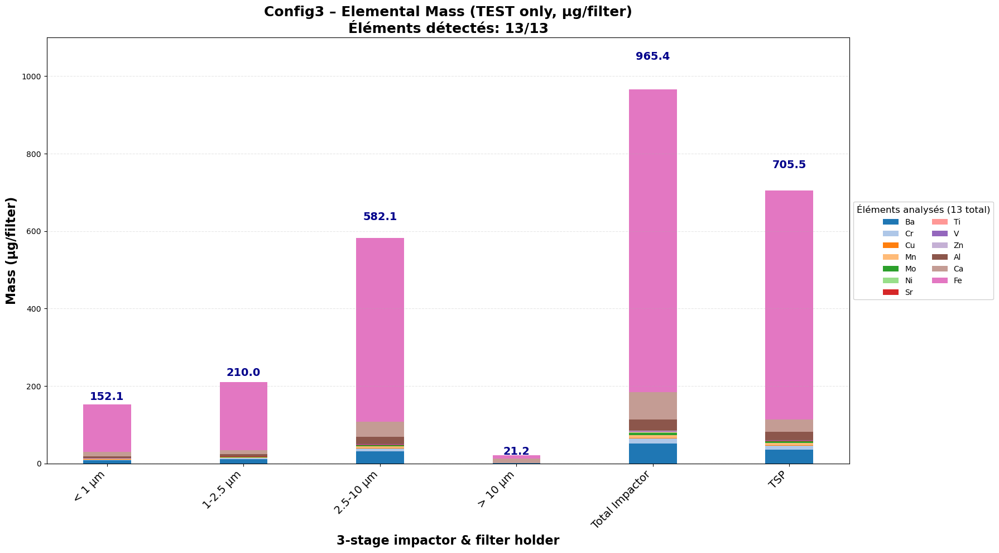


📈 Plotting TEST only: Config4


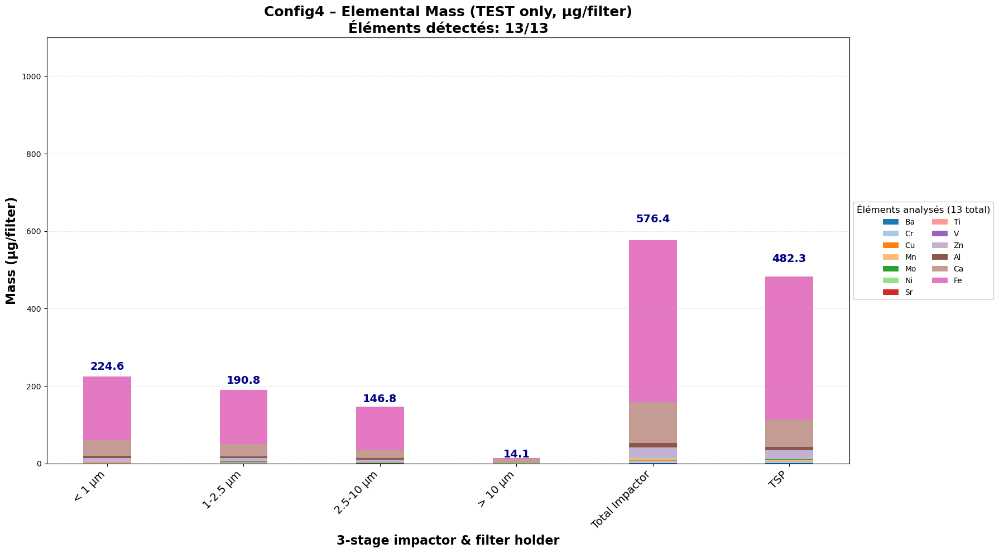


📈 Plotting TEST only: Config5


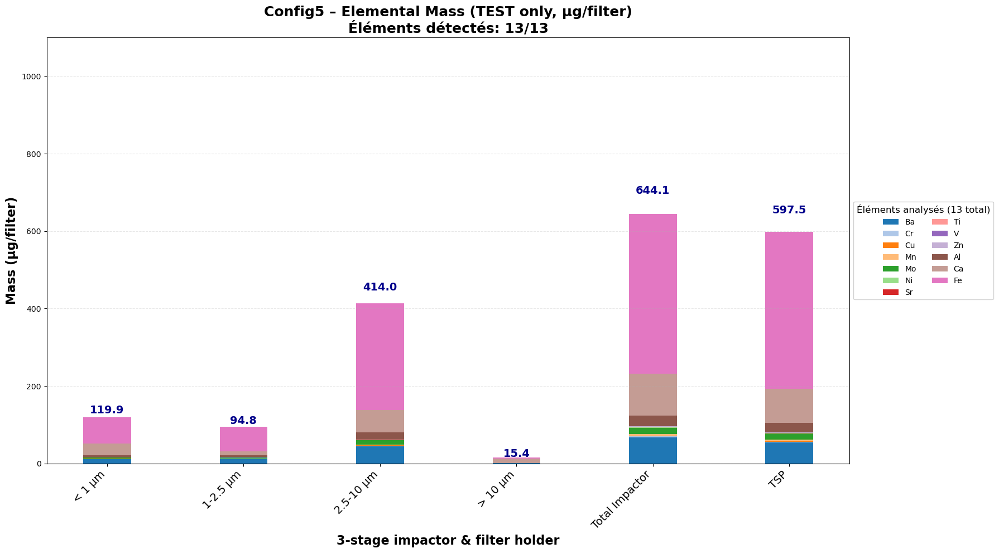


📈 Plotting TEST only: Config6


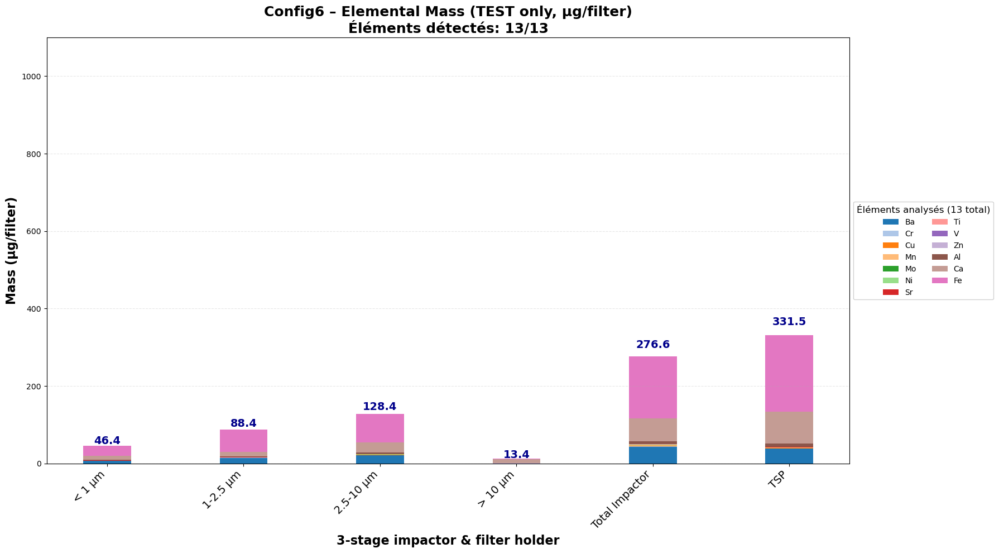


📈 Plotting TEST only: Config7


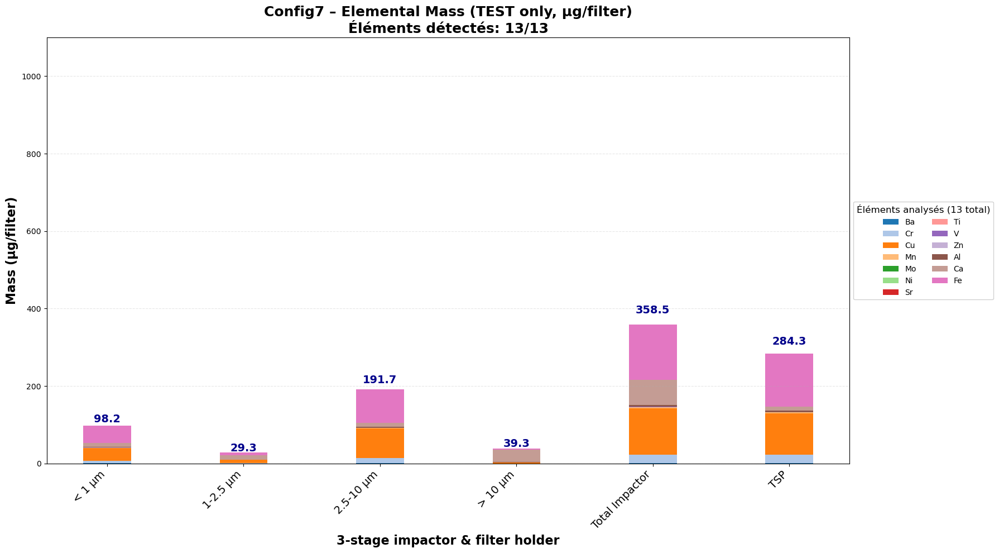


RÉSUMÉ FINAL
Nombre total de configurations: 5
Nombre total d'éléments uniques dans tous les top 10: 13

Liste globale des éléments (ordre alphabétique):
   1. Al
   2. Ba
   3. Ca
   4. Cr
   5. Cu
   6. Fe
   7. Mn
   8. Mo
   9. Ni
  10. Sr
  11. Ti
  12. V
  13. Zn

Éléments par configuration (top 10 des tests):

  Config3:
    - Fe
    - Ca
    - Ba
    - Al
    - Cr
    - Mn
    - Mo
    - V
    - Cu
    - Sr

  Config4:
    - Fe
    - Ca
    - Zn
    - Al
    - Cr
    - Mn
    - Cu
    - Ba
    - Mo
    - Ti

  Config5:
    - Fe
    - Ca
    - Ba
    - Al
    - Mo
    - Mn
    - Cr
    - Cu
    - Sr
    - Zn

  Config6:
    - Fe
    - Ca
    - Ba
    - Al
    - Cu
    - Mn
    - Sr
    - Cr
    - Ti
    - Ni

  Config7:
    - Fe
    - Cu
    - Ca
    - Cr
    - Al
    - Mn
    - Ba
    - Zn
    - Ni
    - Ti

DONE


In [28]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# 1) READ RAW FILE
fichier = r"C:\Users\Grira\OneDrive - Alstom\Documents\Paddle\Campagne2\Impacteur + FH\Masses and elemental composition_PTF2.xlsx"
df_raw = pd.read_excel(fichier, header=None)


# --------------------------
# 2) AUTO-DETECT HEADER ROW
# --------------------------
header_row = None
for i in range(50):
    row = df_raw.iloc[i].astype(str).str.lower()
    if "particle diameter" in row.tolist() and "filter name" in row.tolist():
        header_row = i
        break

df = pd.read_excel(fichier, header=header_row)
df.columns = df.columns.map(str)

# --------------------------
# 3) FILTER TYPE (Blank / Test)
# --------------------------
def detect_type(x):
    x = str(x).strip()
    if not x or x == 'nan':
        return None
    if x.startswith("B"):
        return "Blank"
    else:
        return "Test"

df["Type"] = df["Filter name"].apply(detect_type)
df = df[df["Type"].notna()]

# --------------------------
# 4) MACHINE NAME
# --------------------------
df["Machine"] = df.iloc[:,0].astype(str).str.extract(
    r"(Config[0-9A-Za-z\-]*)", expand=False
).ffill()

# ===============================================================
# 5) ELEMENT COLUMNS IN ng/filter → convert to µg/filter
# ===============================================================
elem_cols = [c for c in df.columns if "(ng/filter)" in c]

df[elem_cols] = df[elem_cols].apply(pd.to_numeric, errors="coerce").fillna(0)
df[elem_cols] /= 1000   # ng → µg

clean_names = {c: c.replace(" (ng/filter)", "") for c in elem_cols}

# ===============================================================
# 6) MASS COLUMN (mg → µg/filter) - GARDÉ POUR CALCUL MAIS PAS POUR AFFICHAGE
# ===============================================================
col_mass = [c for c in df.columns if "mass" in c.lower()][0]

df[col_mass] = pd.to_numeric(df[col_mass], errors="coerce").fillna(0)
df[col_mass] *= 1000  # mg → µg

# ===============================================================
# 7) COMPUTE TOP‑10 ELEMENTS FOR TESTS ONLY
# ===============================================================
print("\n" + "="*80)
print("   TOP 10 ÉLÉMENTS PAR CONFIGURATION (TESTS UNIQUEMENT)")
print("="*80 + "\n")

configs = df["Machine"].unique()

# Dictionnaire pour stocker les top 10 tests
machine_top10_tests = {}

for config in configs:

    print(f"\n------ {config} ------")
    print("-" * 50)

    df_config = df[(df["Machine"] == config) & (df["Type"] == "Test")]

    if df_config.empty:
        print(f"⚠ Pas de données Test pour {config}\n")
        continue

    total_mass = df_config[elem_cols].sum(axis=0)
    top10 = total_mass.sort_values(ascending=False).head(10)
    
    machine_top10_tests[config] = top10.index.tolist()

    top10_clean = top10.copy()
    top10_clean.index = [clean_names[c] for c in top10_clean.index]

    print(f"\n{'Rang':<6} {'Élément':<15} {'Masse totale (µg)':<20}")
    print("-" * 50)

    for rank, (elem, value) in enumerate(top10_clean.items(), 1):
        print(f"{rank:<6} {elem:<15} {value:<20.2f}")

    print("-" * 50)
    print(f"Total des 10 éléments: {top10.sum():.2f} µg")
    print(f"Total général (tous éléments tests): {total_mass.sum():.2f} µg")
    if total_mass.sum() > 0:
        print(f"Les 10 éléments représentent: {(top10.sum()/total_mass.sum()*100):.1f}% du total")
    print("\n")

# ===============================================================
# 8) RÉSUMÉ FINAL DES TOP 10 PAR CONFIGURATION (TESTS)
# ===============================================================
print("\n" + "="*80)
print("RÉSUMÉ FINAL - TOP 10 PAR CONFIGURATION (TESTS)")
print("="*80)

for config, top10 in machine_top10_tests.items():
    print(f"\n🔧 {config}")
    print("-" * 40)
    for i, elem in enumerate(top10, 1):
        elem_name = clean_names[elem]
        print(f"  {i:2d}. {elem_name}")

# ===============================================================
# 9) LISTE GLOBALE DES ÉLÉMENTS PRÉSENTS DANS LES TOP 10 TESTS
# ===============================================================
global_elements_tests = set()
for top10_list in machine_top10_tests.values():
    global_elements_tests.update(top10_list)

global_elements_tests = sorted(list(global_elements_tests), key=lambda x: clean_names[x])

print("\n" + "="*80)
print(f"LISTE GLOBALE DES ÉLÉMENTS DANS LES TOP 10 DES TESTS ({len(global_elements_tests)} éléments uniques)")
print("="*80)
for i, elem in enumerate(global_elements_tests, 1):
    print(f"  {i:2d}. {clean_names[elem]}")

# ===============================================================
# 10) PLOT PER MACHINE WITH GLOBAL TOP-10 ELEMENTS (SANS MASSE)
# ===============================================================
print("\n" + "="*80)
print("GÉNÉRATION DES GRAPHIQUES POUR LES TESTS")
print("(Tous les éléments de la liste globale sont affichés - Même légende sur toutes les configs)")
print("(Sans la barre de masse)")
print("="*80)

core_sizes = ["< 1 µm","1-2.5 µm","2.5-10 µm","> 10 µm"]
size_order = ["< 1 µm","1-2.5 µm","2.5-10 µm","> 10 µm","Total Impactor","TSP"]

# Garder TOUS les éléments de la liste globale
elem_cols_to_plot = [c for c in elem_cols if c in global_elements_tests]

# Palette fixe basée sur la liste globale (MÊME POUR TOUTES LES CONFIGS)
cmap = plt.get_cmap("tab20")
colors = {elem: cmap(i % 20) for i, elem in enumerate(elem_cols_to_plot)}

for machine, dgroup in df.groupby("Machine"):

    print(f"\n📈 Plotting TEST only: {machine}")

    tests = dgroup[dgroup["Type"] == "Test"]
    if tests.empty:
        print("⚠ No test data")
        continue

    # ✅ SUPPRESSION de col_mass - on ne garde que les éléments
    dplot = tests[["Particle diameter"] + elem_cols_to_plot].copy()
    dplot["Particle diameter"] = dplot["Particle diameter"].astype(str).str.strip()

    plt.figure(figsize=(18,10))
    width = 0.35
    x = np.arange(len(size_order))

    # --- STACKED ELEMENT MASS ---
    grouped = dplot.groupby("Particle diameter")[elem_cols_to_plot].sum()
    grouped.loc["Total Impactor"] = grouped.reindex(core_sizes).sum()
    grouped = grouped.reindex(size_order).fillna(0)

    bottom = np.zeros(len(size_order))
    
    # Calculate total elemental mass for each bar
    element_totals = grouped.sum(axis=1).values

    # Tracer TOUS les éléments de la liste globale
    for elem in elem_cols_to_plot:
        vals = grouped[elem].values.astype(float)
        plt.bar(
            x,
            vals,
            width,
            bottom=bottom,
            color=colors[elem],
            label=clean_names[elem]  # MÊME LÉGENDE POUR TOUTES LES CONFIGS
        )
        bottom += vals

    # --- ADD ELEMENTAL TOTAL MASS ON TOP OF STACKED BARS ---
    for i, total in enumerate(element_totals):
        if total > 0:
            plt.text(
                x[i],
                total * 1.08,
                f"{total:.1f}",
                ha="center",
                fontsize=14,
                fontweight="bold",
                color="darkblue"
            )

    # ✅ SUPPRESSION de la barre de masse (plus de code pour mass_group)

    # --- FORMATTING ---
    # Ajustement dynamique de la limite Y basé uniquement sur les éléments
    # plt.ylim(0, 2400) # all X61 AGC B20
    plt.ylim(0, 1100) # all AGC B20

    plt.xticks(x, size_order, fontsize=14, rotation=45, ha='right')
    plt.ylabel("Mass (µg/filter)", fontsize=16, fontweight="bold")
    plt.xlabel("3‑stage impactor & filter holder", fontsize=16, fontweight="bold")
    
    # Compter les éléments détectés vs totaux
    elements_detected = sum(1 for elem in elem_cols_to_plot if tests[elem].sum() > 0)
    
    plt.title(f"{machine} – Elemental Mass (TEST only, µg/filter)\n"
              f"Éléments détectés: {elements_detected}/{len(elem_cols_to_plot)}", 
              fontsize=18, fontweight="bold")
    
    plt.grid(axis='y', linestyle='--', alpha=0.3)

    # Légende UNIQUE pour toutes les configurations (mêmes éléments, mêmes couleurs)
    plt.legend(
        loc="center left",
        bbox_to_anchor=(1, 0.5),
        fontsize=10,
        title=f"Éléments analysés ({len(elem_cols_to_plot)} total)",
        title_fontsize=12,
        ncol=2 if len(elem_cols_to_plot) > 10 else 1,
        framealpha=0.9
    )

    plt.tight_layout()
    plt.show()

# ===============================================================
# 11) RÉSUMÉ FINAL
# ===============================================================
print("\n" + "="*80)
print("RÉSUMÉ FINAL")
print("="*80)
print(f"Nombre total de configurations: {len(machine_top10_tests)}")
print(f"Nombre total d'éléments uniques dans tous les top 10: {len(global_elements_tests)}")
print("\nListe globale des éléments (ordre alphabétique):")
for i, elem in enumerate(global_elements_tests, 1):
    print(f"  {i:2d}. {clean_names[elem]}")
    
print("\nÉléments par configuration (top 10 des tests):")
for machine, top10 in machine_top10_tests.items():
    print(f"\n  {machine}:")
    for elem in top10:
        print(f"    - {clean_names[elem]}")

print("\n" + "="*80)
print("DONE")
print("="*80)

Concentration

Mass concentrations

Plot : Config3


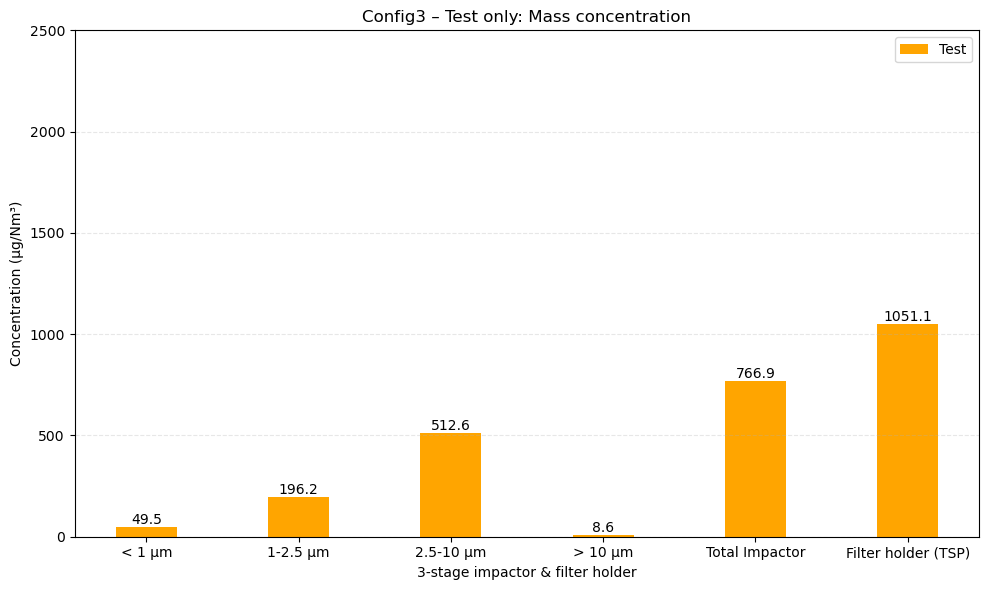

Plot : Config4


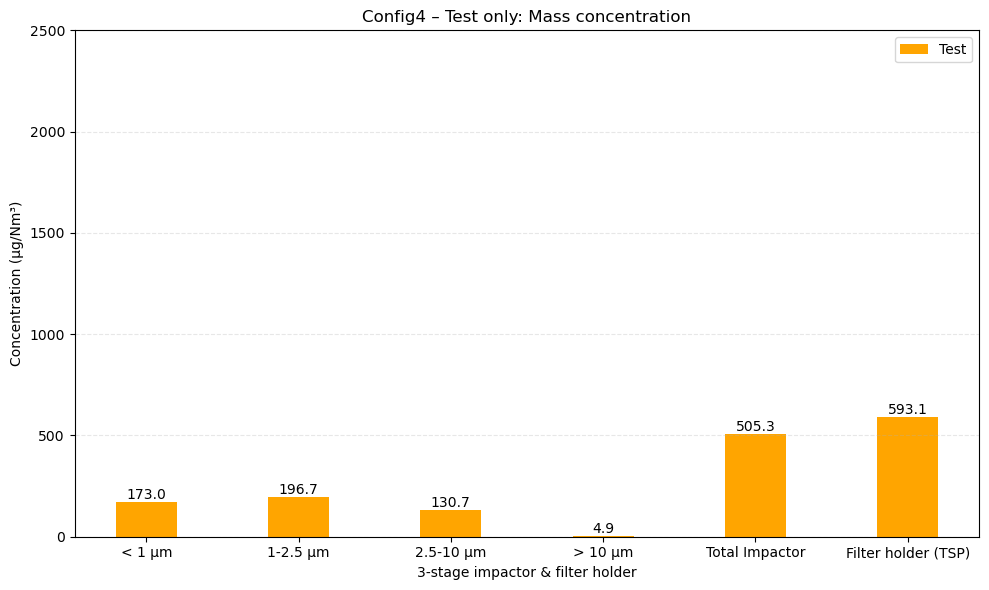

Plot : Config5


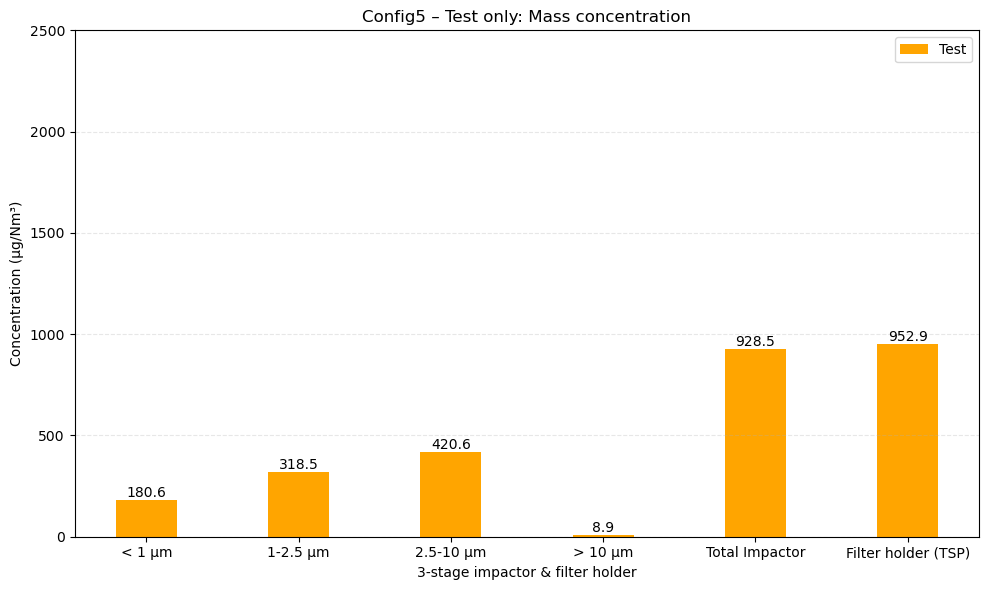

Plot : Config6


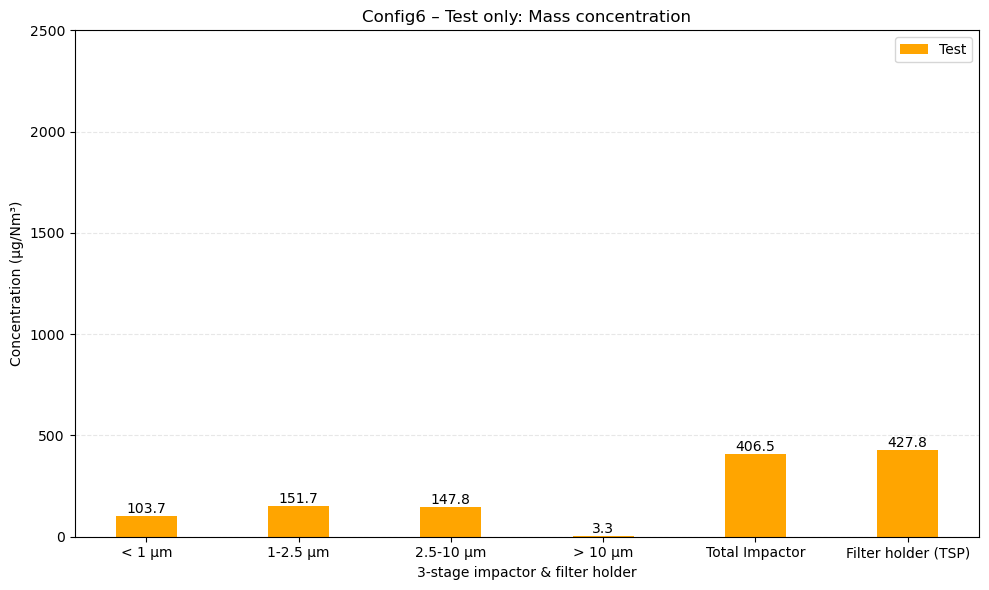

Plot : Config7


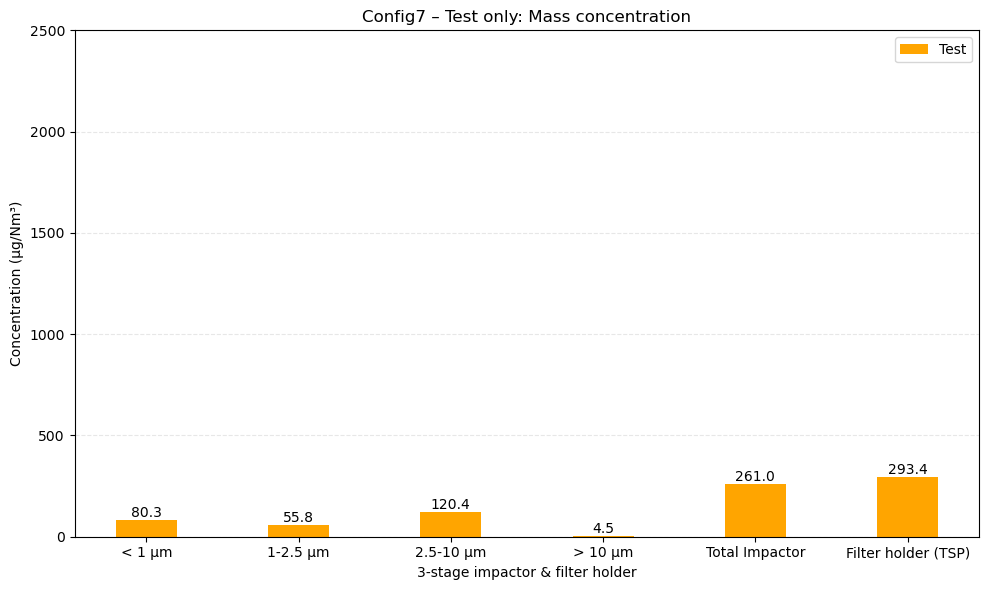

In [14]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# 1) READ RAW FILE
fichier = r"C:\Users\Grira\OneDrive - Alstom\Documents\Paddle\Campagne2\Impacteur + FH\Masses and elemental composition_PTF2.xlsx"
df_raw = pd.read_excel(fichier, header=None)

# 2) AUTO-DETECT HEADER ROW
header_row = None
for i in range(50):
    row = df_raw.iloc[i].astype(str).str.lower()
    if row.str.contains("mass").any() and row.str.contains("filter").any():
        header_row = i
        break

if header_row is None:
    raise Exception("Cannot detect header row!")

# 3) READ CLEAN FILE
df = pd.read_excel(fichier, header=header_row)
df.columns = df.columns.map(lambda x: str(x).strip())

# 4) DETECT COLUMNS
filter_cols = [c for c in df.columns if "filter" in c.lower() and "name" in c.lower()]
conc_cols   = [c for c in df.columns if "concentration" in c.lower()]  # <<< NEW

col_filter = filter_cols[0]
col_conc   = conc_cols[0]  # <<< NEW: using concentration

# 5) DETECT TYPE
def detect_type(x):
    x = str(x).strip()
    if not x or x == 'nan':
        return None
    if x.startswith("B"):
        return "Blank"
    else:
        return "Test"

df["Type"] = df[col_filter].apply(detect_type)
df = df[df["Type"].notna()]

# 6) DETECT MACHINE
df["Machine"] = df.iloc[:,0].astype(str).str.extract(r"(Config[0-9A-Za-z\-]*)", expand=False).ffill()
df_clean = df.copy()

# 7) GRAPH CODE
col_stage = "Particle diameter"
df[col_stage] = df[col_stage].astype(str).str.strip()

diam_list = ["< 1 µm", "1-2.5 µm", "2.5-10 µm", "> 10 µm", "TSP"]

label_map = {
    "< 1 µm": "< 1 µm",
    "1-2.5 µm": "1-2.5 µm",
    "2.5-10 µm": "2.5-10 µm",
    "> 10 µm": "> 10 µm",
    "TSP": "Filter holder (TSP)",
    "Total Impactor": "Total Impactor"
}

for machine, dgroup in df_clean.groupby("Machine"):

    print(f"Plot : {machine}")

    tests = dgroup[dgroup["Type"] == "Test"]

    if tests.empty:
        print("⚠ Not enough TEST data")
        continue

    values_t = {}

    for diam in diam_list:
        t = tests[tests[col_stage] == diam][col_conc]
        values_t[diam] = float(t.values[0]) if len(t) else None

    values_t["Total Impactor"] = sum(values_t[d] for d in diam_list[:-1] if values_t[d] is not None)

    final_order = [
        "< 1 µm",
        "1-2.5 µm",
        "2.5-10 µm",
        "> 10 µm",
        "Total Impactor",
        "TSP"
    ]

    conc_test = []
    labels = []

    for diam in final_order:
        if values_t[diam] is not None:
            conc_test.append(values_t[diam])
            labels.append(label_map[diam])

    x = np.arange(len(labels))
    width = 0.4

    plt.figure(figsize=(10,6))

    bars_test = plt.bar(x, conc_test, width, label="Test", color="orange")

    for bar in bars_test:
        y = bar.get_height()
        plt.text(bar.get_x() + bar.get_width()/2, y, f"{y:.1f}", ha='center', va='bottom')

    plt.ylim(0, 2500)
    plt.xticks(x, labels)
    plt.ylabel("Concentration (µg/Nm³)")
    plt.xlabel("3-stage impactor & filter holder")
    plt.title(f"{machine} – Test only: Mass concentration")
    plt.grid(axis='y', linestyle='--', alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()

Elementel composition (in mass concentration)


Plotting TEST only: Config3


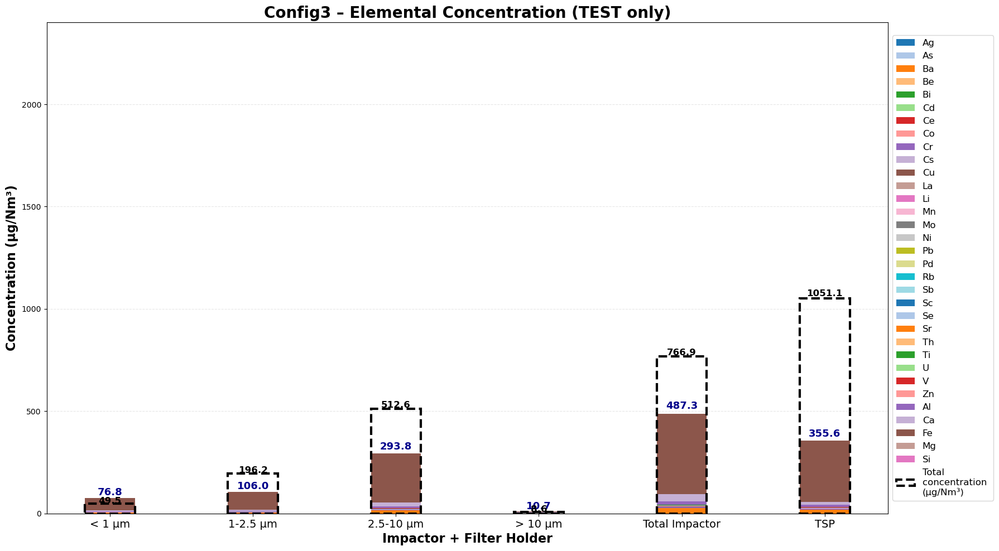


Plotting TEST only: Config4


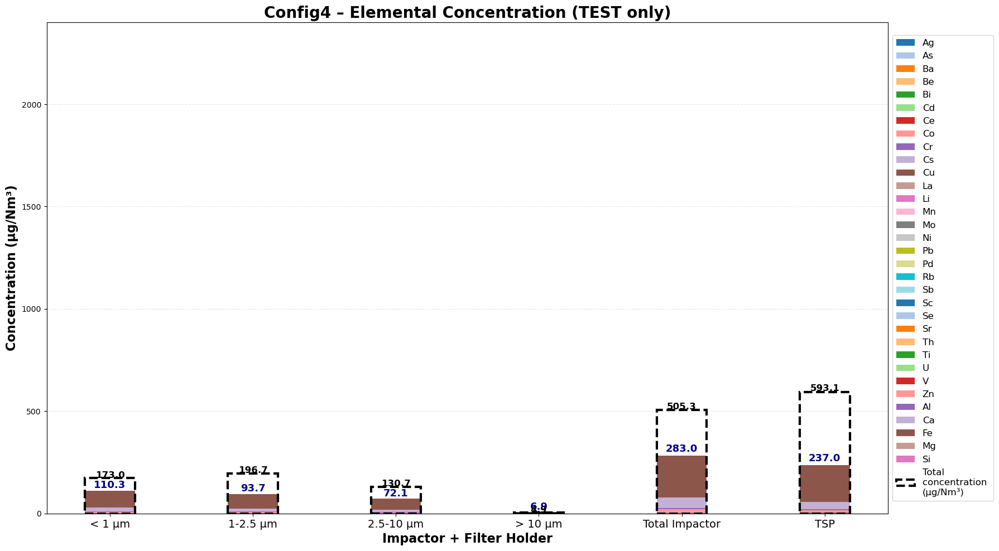


Plotting TEST only: Config5


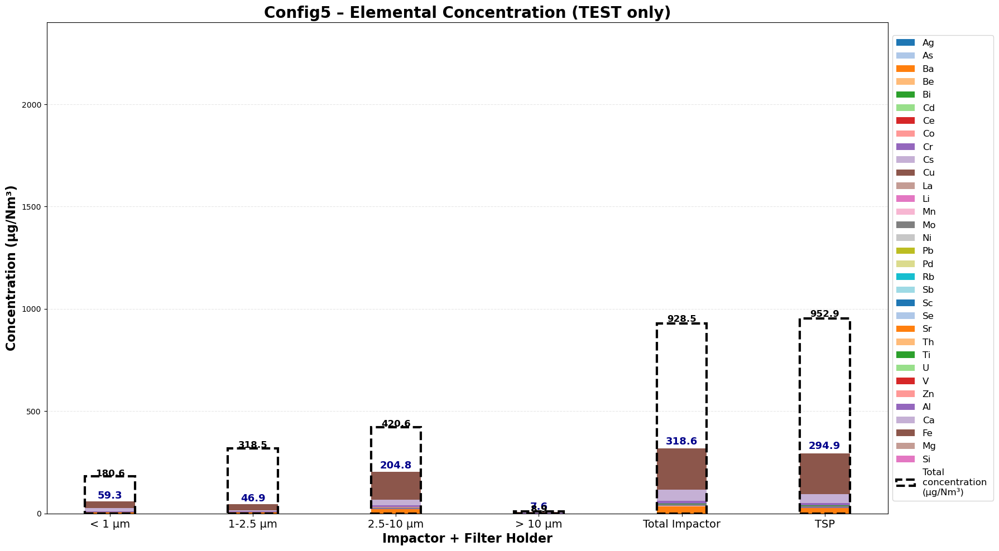


Plotting TEST only: Config6


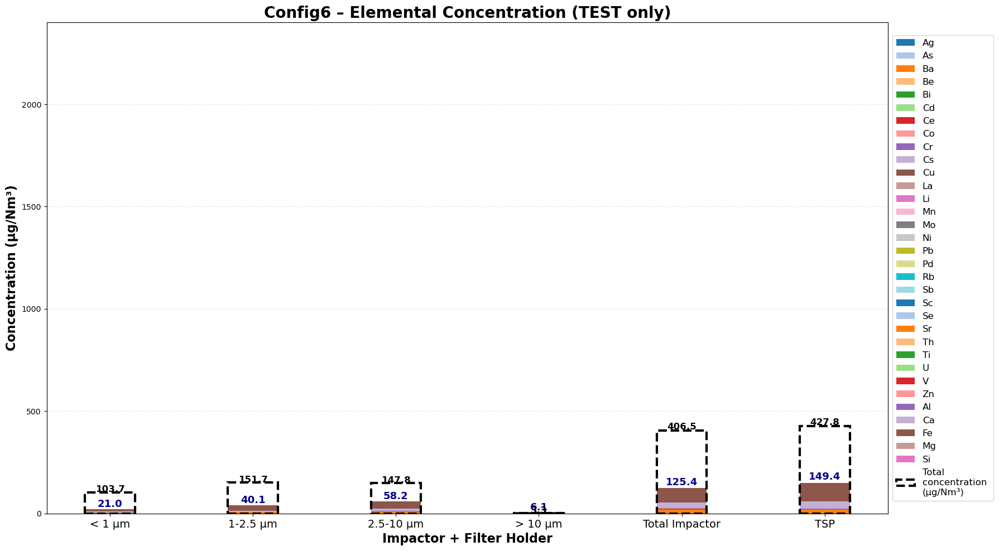


Plotting TEST only: Config7


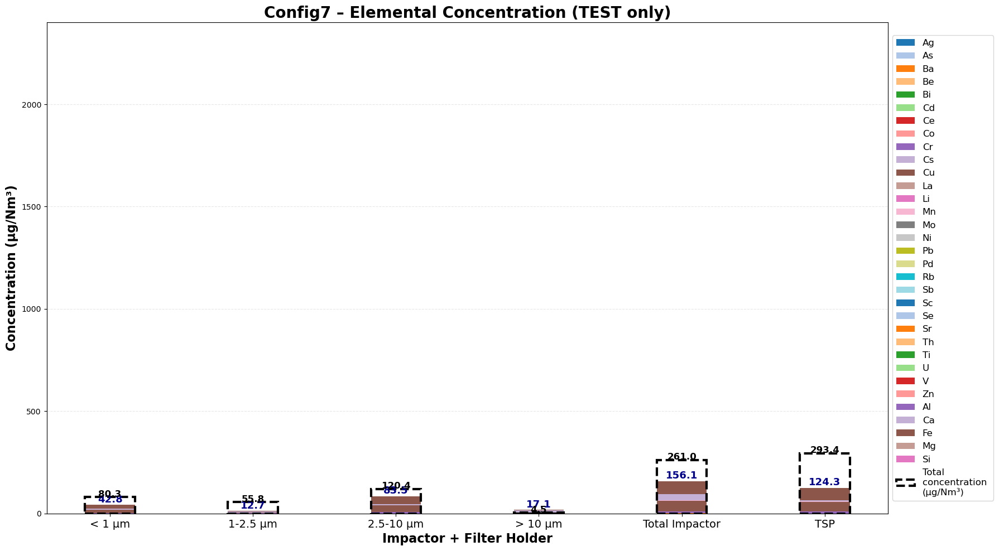


   TOP 10 ÉLÉMENTS PAR CONFIGURATION (TESTS UNIQUEMENT)
   Concentration en µg/Nm³


------ Config3 ------
--------------------------------------------------

Rang   Élément         Concentration totale (µg/Nm³)
--------------------------------------------------
1      Fe              691.51                   
2      Ca              51.68                    
3      Ba              44.66                    
4      Al              25.99                    
5      Cr              11.13                    
6      Mn              6.19                     
7      Mo              4.64                     
8      V               1.88                     
9      Cu              1.79                     
10     Sr              1.20                     
--------------------------------------------------
Total des 10 éléments: 840.66 µg/Nm³
Total général (tous éléments tests): 842.87 µg/Nm³
Les 10 éléments représentent: 99.7% du total



------ Config4 ------
-------------------------------------

In [16]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# 1) READ RAW FILE
fichier = r"C:\Users\Grira\OneDrive - Alstom\Documents\Paddle\Campagne2\Impacteur + FH\Masses and elemental composition_PTF2.xlsx"
df_raw = pd.read_excel(fichier, header=None)

# ============================================================
# 2) AUTO-DETECT HEADER ROW
# ============================================================
header_row = None
for i in range(50):
    row = df_raw.iloc[i].astype(str).str.lower()
    if "particle diameter" in row.tolist() and "filter name" in row.tolist():
        header_row = i
        break

df = pd.read_excel(fichier, header=header_row)
df.columns = df.columns.map(lambda x: str(x).strip())

# ============================================================
# 3) FILTER TYPE (Blank / Test)
# ============================================================
def detect_type(x):
    x = str(x).strip()
    if not x or x == 'nan':
        return None
    if x.startswith("B"):
        return "Blank"
    else:
        return "Test"

df["Type"] = df["Filter name"].apply(detect_type)
df = df[df["Type"].notna()]

# ============================================================
# 4) MACHINE NAME EXTRACTION
# ============================================================
df["Machine"] = df.iloc[:,0].astype(str).str.extract(
    r"(Config[0-9A-Za-z\-]*)", expand=False
).ffill()

# ============================================================
# 5) PARTICLE SIZE ORDER
# ============================================================
core_sizes = ["< 1 µm","1-2.5 µm","2.5-10 µm","> 10 µm"]
size_order = ["< 1 µm","1-2.5 µm","2.5-10 µm","> 10 µm","Total Impactor","TSP"]

# ============================================================
# 6) ELEMENTAL CONCENTRATIONS (already µg/Nm³)
# ============================================================
elem_cols = [c for c in df.columns if "(µg/Nm3 filter)" in c]
df[elem_cols] = df[elem_cols].apply(pd.to_numeric, errors="coerce").fillna(0)

elem_labels = {e: e.replace(" (µg/Nm3 filter)", "") for e in elem_cols}

# ============================================================
# 7) TOTAL MASS CONCENTRATION (µg/Nm³)
# ============================================================
col_mass_conc = [c for c in df.columns if "Concentration" in c and "(µg/Nm3)" in c][0]
df[col_mass_conc] = pd.to_numeric(df[col_mass_conc], errors="coerce").fillna(0)

# ============================================================
# 8) TEST PLOTS — µg/Nm³
# ============================================================
for machine, dgroup in df.groupby("Machine"):

    print(f"\nPlotting TEST only: {machine}")

    tests = dgroup[dgroup["Type"] == "Test"]
    if tests.empty:
        print("⚠ No TEST data")
        continue

    dplot = tests[["Particle diameter", col_mass_conc] + elem_cols].copy()
    dplot["Particle diameter"] = dplot["Particle diameter"].astype(str).str.strip()

    plt.figure(figsize=(18,10))
    width = 0.35
    x = np.arange(len(size_order))

    cmap = plt.get_cmap("tab20")
    colors = {e: cmap(i % 20) for i, e in enumerate(elem_cols)}

    # ----------- GROUP ELEMENTS -----------
    grouped = dplot.groupby("Particle diameter")[elem_cols].sum()
    grouped.loc["Total Impactor"] = grouped.reindex(core_sizes).sum()
    grouped = grouped.reindex(size_order).fillna(0)

    bottom = np.zeros(len(size_order))

    # ----------- STACKED BARS (ELEMENTS) -----------
    for elem in elem_cols:
        vals = grouped[elem].values.astype(float)
        plt.bar(
            x, vals,
            width,
            bottom=bottom,
            color=colors[elem],
            label=elem_labels[elem]
        )
        bottom += vals

    # ----------- TOTAL ELEMENT CONCENTRATION LABELS -----------
    total_elements = grouped.sum(axis=1).values

    for i, total in enumerate(total_elements):
        if total > 0:
            plt.text(
                x[i],
                total * 1.03,
                f"{total:.1f}",
                ha="center",
                va="bottom",
                fontsize=13,
                fontweight="bold",
                color="darkblue"
            )

    # ----------- TOTAL MASS CONCENTRATION (CONTOUR BAR) -----------
    mass_group = dplot.groupby("Particle diameter")[col_mass_conc].sum()
    mass_group.loc["Total Impactor"] = mass_group.reindex(core_sizes).sum()
    mass_group = mass_group.reindex(size_order).fillna(0)

    for i, val in enumerate(mass_group.values):
        if val > 0:
            plt.bar(
                x[i],
                val,
                width,
                fill=False,
                edgecolor="black",
                linestyle="--",
                linewidth=3,
                label="Total \nconcentration \n(µg/Nm³)" if i == 0 else None
            )
            plt.text(
                x[i],
                val * 1.01,
                f"{val:.1f}",
                ha="center",
                fontsize=12,
                fontweight="bold",
                color="black"
            )

    # ----------- FORMATTING -----------
    plt.ylim(0, 2400)
    plt.xticks(x, size_order, fontsize=14)
    plt.ylabel("Concentration (µg/Nm³)", fontsize=16, fontweight="bold")
    plt.xlabel("Impactor + Filter Holder", fontsize=16, fontweight="bold")
    plt.title(f"{machine} – Elemental Concentration (TEST only)", fontsize=20, fontweight="bold")

    plt.grid(axis='y', linestyle='--', alpha=0.3)
    plt.legend(loc="center left", bbox_to_anchor=(1,0.5), fontsize=12)

    plt.tight_layout()
    plt.show()

# ============================================================
# 9) TOP‑10 ELEMENTS PER CONFIGURATION (BASED ONLY ON TESTS)
# ============================================================
print("\n" + "="*80)
print("   TOP 10 ÉLÉMENTS PAR CONFIGURATION (TESTS UNIQUEMENT)")
print("   Concentration en µg/Nm³")
print("="*80 + "\n")

configs = df["Machine"].unique()

for config in configs:

    print(f"\n------ {config} ------")
    print("-" * 50)

    # ✅ CORRECTION : Filtrer uniquement les TESTS
    df_config = df[(df["Machine"] == config) & (df["Type"] == "Test")]

    if df_config.empty:
        print(f"⚠ Pas de données Test pour {config}\n")
        continue

    total_conc = df_config[elem_cols].sum(axis=0)

    top10 = total_conc.sort_values(ascending=False).head(10)
    
    # Nettoyer les noms pour l'affichage
    top10_clean = top10.copy()
    top10_clean.index = [elem_labels[c] for c in top10_clean.index]

    # Affichage détaillé
    print(f"\n{'Rang':<6} {'Élément':<15} {'Concentration totale (µg/Nm³)':<25}")
    print("-" * 50)

    for rank, (elem, value) in enumerate(top10_clean.items(), 1):
        print(f"{rank:<6} {elem:<15} {value:<25.2f}")

    print("-" * 50)
    print(f"Total des 10 éléments: {top10.sum():.2f} µg/Nm³")
    print(f"Total général (tous éléments tests): {total_conc.sum():.2f} µg/Nm³")
    if total_conc.sum() > 0:
        print(f"Les 10 éléments représentent: {(top10.sum()/total_conc.sum()*100):.1f}% du total")
    print("\n")

print("\n" + "="*80)
print("DONE")
print("="*80)

Elementel composition (in mass concentration - top 10)


   TOP 10 ÉLÉMENTS PAR CONFIGURATION (TESTS UNIQUEMENT)
   Concentration en µg/Nm³


------ Config3 ------
--------------------------------------------------

Rang   Élément         Concentration totale (µg/Nm³)
--------------------------------------------------
1      Fe              691.51                   
2      Ca              51.68                    
3      Ba              44.66                    
4      Al              25.99                    
5      Cr              11.13                    
6      Mn              6.19                     
7      Mo              4.64                     
8      V               1.88                     
9      Cu              1.79                     
10     Sr              1.20                     
--------------------------------------------------
Total des 10 éléments: 840.66 µg/Nm³
Total général (tous éléments tests): 842.87 µg/Nm³
Les 10 éléments représentent: 99.7% du total



------ Config4 ------
-------------------------------------

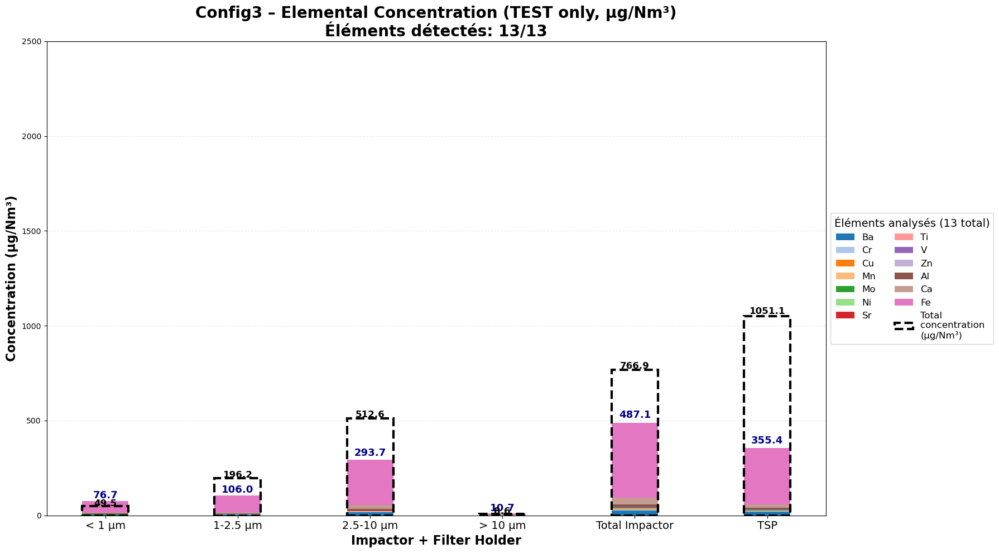


📈 Plotting TEST only: Config4


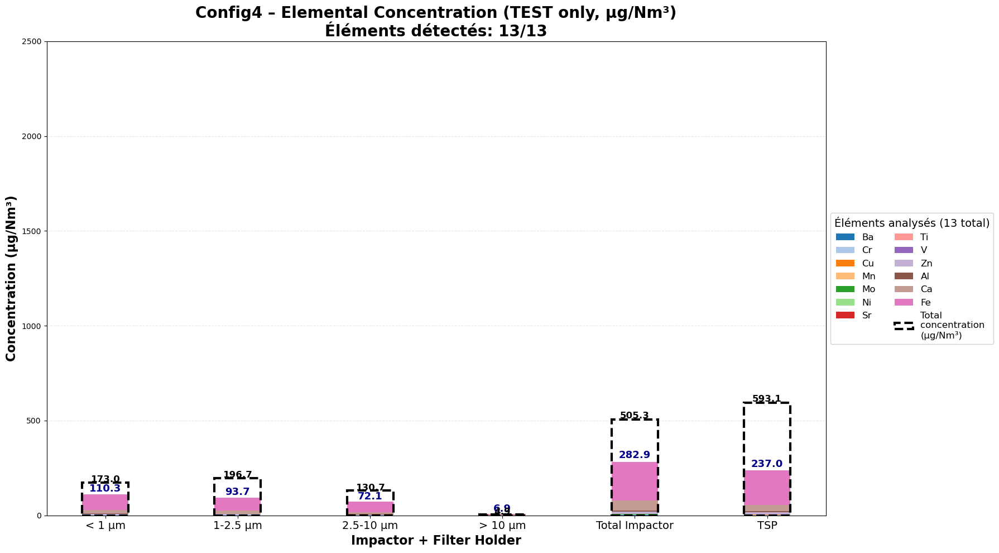


📈 Plotting TEST only: Config5


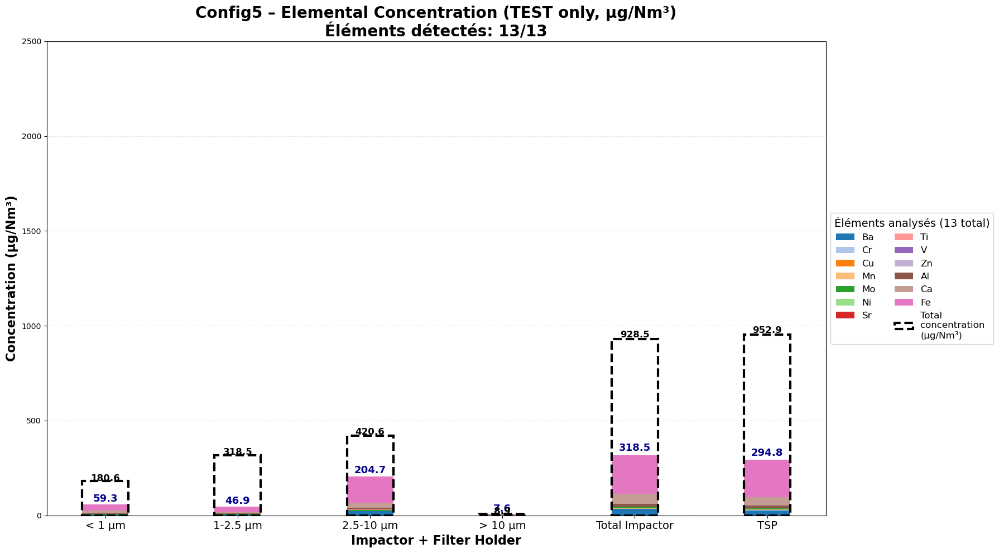


📈 Plotting TEST only: Config6


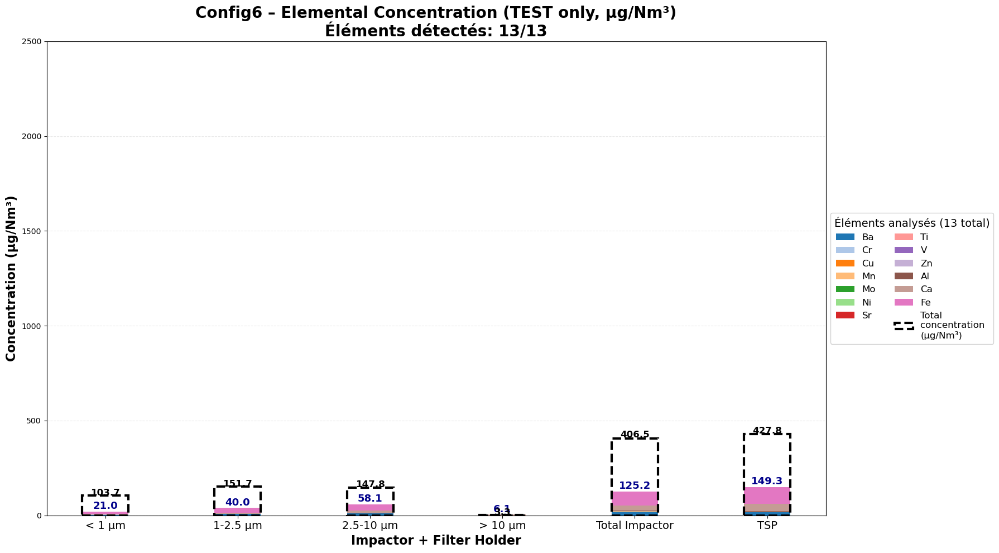


📈 Plotting TEST only: Config7


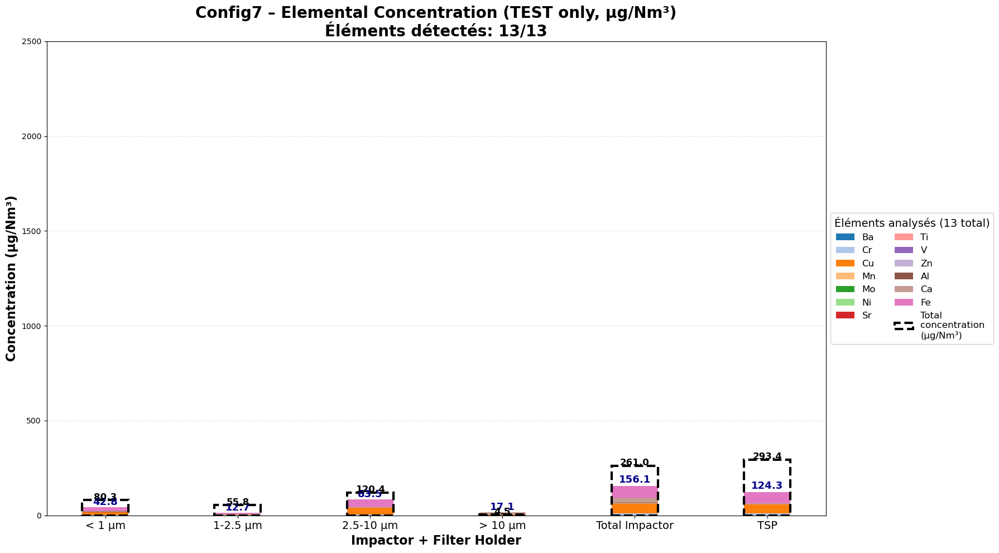


RÉSUMÉ FINAL
Nombre total de configurations: 5
Nombre total d'éléments uniques dans tous les top 10: 13

Liste globale des éléments (ordre alphabétique):
   1. Al
   2. Ba
   3. Ca
   4. Cr
   5. Cu
   6. Fe
   7. Mn
   8. Mo
   9. Ni
  10. Sr
  11. Ti
  12. V
  13. Zn

Éléments par configuration (top 10 des tests):

  Config3:
    - Fe
    - Ca
    - Ba
    - Al
    - Cr
    - Mn
    - Mo
    - V
    - Cu
    - Sr

  Config4:
    - Fe
    - Ca
    - Zn
    - Al
    - Cr
    - Mn
    - Cu
    - Ba
    - Mo
    - Ti

  Config5:
    - Fe
    - Ca
    - Ba
    - Al
    - Mo
    - Mn
    - Cr
    - Cu
    - Sr
    - Zn

  Config6:
    - Fe
    - Ca
    - Ba
    - Al
    - Cu
    - Mn
    - Sr
    - Cr
    - Ti
    - Ni

  Config7:
    - Fe
    - Cu
    - Ca
    - Cr
    - Al
    - Mn
    - Ba
    - Zn
    - Ni
    - Ti

DONE


In [17]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# 1) READ RAW FILE
fichier = r"C:\Users\Grira\OneDrive - Alstom\Documents\Paddle\Campagne2\Impacteur + FH\Masses and elemental composition_PTF2.xlsx"
df_raw = pd.read_excel(fichier, header=None)

# ============================================================
# 2) AUTO-DETECT HEADER ROW
# ============================================================
header_row = None
for i in range(50):
    row = df_raw.iloc[i].astype(str).str.lower()
    if "particle diameter" in row.tolist() and "filter name" in row.tolist():
        header_row = i
        break

df = pd.read_excel(fichier, header=header_row)
df.columns = df.columns.map(lambda x: str(x).strip())

# ============================================================
# 3) FILTER TYPE (Blank / Test)
# ============================================================
def detect_type(x):
    x = str(x).strip()
    if not x or x == 'nan':
        return None
    if x.startswith("B"):
        return "Blank"
    else:
        return "Test"

df["Type"] = df["Filter name"].apply(detect_type)
df = df[df["Type"].notna()]

# ============================================================
# 4) MACHINE NAME EXTRACTION
# ============================================================
df["Machine"] = df.iloc[:,0].astype(str).str.extract(
    r"(Config[0-9A-Za-z\-]*)", expand=False
).ffill()

# ============================================================
# 5) PARTICLE SIZE ORDER
# ============================================================
core_sizes = ["< 1 µm","1-2.5 µm","2.5-10 µm","> 10 µm"]
size_order = ["< 1 µm","1-2.5 µm","2.5-10 µm","> 10 µm","Total Impactor","TSP"]

# ============================================================
# 6) ELEMENTAL CONCENTRATIONS (already µg/Nm³)
# ============================================================
elem_cols = [c for c in df.columns if "(µg/Nm3 filter)" in c]
df[elem_cols] = df[elem_cols].apply(pd.to_numeric, errors="coerce").fillna(0)

elem_labels = {e: e.replace(" (µg/Nm3 filter)", "") for e in elem_cols}

# ============================================================
# 7) TOTAL MASS CONCENTRATION (µg/Nm³)
# ============================================================
col_mass_conc = [c for c in df.columns if "Concentration" in c and "(µg/Nm3)" in c][0]
df[col_mass_conc] = pd.to_numeric(df[col_mass_conc], errors="coerce").fillna(0)

# ============================================================
# 8) COMPUTE TOP‑10 ELEMENTS FOR TESTS ONLY
# ============================================================
print("\n" + "="*80)
print("   TOP 10 ÉLÉMENTS PAR CONFIGURATION (TESTS UNIQUEMENT)")
print("   Concentration en µg/Nm³")
print("="*80 + "\n")

configs = df["Machine"].unique()

# Dictionnaire pour stocker les top 10 tests
machine_top10_tests = {}

for config in configs:

    print(f"\n------ {config} ------")
    print("-" * 50)

    # ✅ CORRECTION : Filtrer uniquement les TESTS
    df_config = df[(df["Machine"] == config) & (df["Type"] == "Test")]

    if df_config.empty:
        print(f"⚠ Pas de données Test pour {config}\n")
        continue

    total_conc = df_config[elem_cols].sum(axis=0)
    top10 = total_conc.sort_values(ascending=False).head(10)
    
    # Stocker dans un dictionnaire
    machine_top10_tests[config] = top10.index.tolist()

    # Nettoyer les noms pour l'affichage
    top10_clean = top10.copy()
    top10_clean.index = [elem_labels[c] for c in top10_clean.index]

    print(f"\n{'Rang':<6} {'Élément':<15} {'Concentration totale (µg/Nm³)':<25}")
    print("-" * 50)

    for rank, (elem, value) in enumerate(top10_clean.items(), 1):
        print(f"{rank:<6} {elem:<15} {value:<25.2f}")

    print("-" * 50)
    print(f"Total des 10 éléments: {top10.sum():.2f} µg/Nm³")
    print(f"Total général (tous éléments tests): {total_conc.sum():.2f} µg/Nm³")
    if total_conc.sum() > 0:
        print(f"Les 10 éléments représentent: {(top10.sum()/total_conc.sum()*100):.1f}% du total")
    print("\n")

# ============================================================
# 9) RÉSUMÉ FINAL DES TOP 10 PAR CONFIGURATION (TESTS)
# ============================================================
print("\n" + "="*80)
print("RÉSUMÉ FINAL - TOP 10 PAR CONFIGURATION (TESTS)")
print("="*80)

for config, top10 in machine_top10_tests.items():
    print(f"\n🔧 {config}")
    print("-" * 40)
    for i, elem in enumerate(top10, 1):
        elem_name = elem_labels[elem]
        print(f"  {i:2d}. {elem_name}")

# ============================================================
# 10) LISTE GLOBALE DES ÉLÉMENTS PRÉSENTS DANS LES TOP 10 TESTS
# ============================================================
global_elements_tests = set()
for top10_list in machine_top10_tests.values():
    global_elements_tests.update(top10_list)

global_elements_tests = sorted(list(global_elements_tests), key=lambda x: elem_labels[x])

print("\n" + "="*80)
print(f"LISTE GLOBALE DES ÉLÉMENTS DANS LES TOP 10 DES TESTS ({len(global_elements_tests)} éléments uniques)")
print("="*80)
for i, elem in enumerate(global_elements_tests, 1):
    print(f"  {i:2d}. {elem_labels[elem]}")

# ============================================================
# 11) TEST PLOTS — µg/Nm³ (AVEC TOUS LES ÉLÉMENTS DE LA LISTE GLOBALE)
# ============================================================
print("\n" + "="*80)
print("GÉNÉRATION DES GRAPHIQUES POUR LES TESTS")
print("(Tous les éléments de la liste globale sont affichés - Même légende sur toutes les configs)")
print("="*80)

# Garder TOUS les éléments de la liste globale
elem_cols_to_plot = [c for c in elem_cols if c in global_elements_tests]

# Palette fixe basée sur la liste globale (MÊME POUR TOUTES LES CONFIGS)
cmap = plt.get_cmap("tab20")
colors = {elem: cmap(i % 20) for i, elem in enumerate(elem_cols_to_plot)}

for machine, dgroup in df.groupby("Machine"):

    print(f"\n📈 Plotting TEST only: {machine}")

    tests = dgroup[dgroup["Type"] == "Test"]
    if tests.empty:
        print("⚠ No TEST data")
        continue

    # Garder TOUS les éléments de la liste globale (même ceux à zéro)
    dplot = tests[["Particle diameter", col_mass_conc] + elem_cols_to_plot].copy()
    dplot["Particle diameter"] = dplot["Particle diameter"].astype(str).str.strip()

    plt.figure(figsize=(18,10))
    width = 0.35
    x = np.arange(len(size_order))

    # ----------- GROUP ELEMENTS -----------
    grouped = dplot.groupby("Particle diameter")[elem_cols_to_plot].sum()
    grouped.loc["Total Impactor"] = grouped.reindex(core_sizes).sum()
    grouped = grouped.reindex(size_order).fillna(0)

    bottom = np.zeros(len(size_order))

    # ----------- STACKED BARS (TOUS LES ÉLÉMENTS DE LA LISTE GLOBALE) -----------
    for elem in elem_cols_to_plot:
        vals = grouped[elem].values.astype(float)
        plt.bar(
            x, vals,
            width,
            bottom=bottom,
            color=colors[elem],
            label=elem_labels[elem]
        )
        bottom += vals

    # ----------- TOTAL ELEMENT CONCENTRATION LABELS -----------
    total_elements = grouped.sum(axis=1).values

    for i, total in enumerate(total_elements):
        if total > 0:
            plt.text(
                x[i],
                total * 1.03,
                f"{total:.1f}",
                ha="center",
                va="bottom",
                fontsize=13,
                fontweight="bold",
                color="darkblue"
            )

    # ----------- TOTAL MASS CONCENTRATION (CONTOUR BAR) -----------
    mass_group = dplot.groupby("Particle diameter")[col_mass_conc].sum()
    mass_group.loc["Total Impactor"] = mass_group.reindex(core_sizes).sum()
    mass_group = mass_group.reindex(size_order).fillna(0)

    for i, val in enumerate(mass_group.values):
        if val > 0:
            plt.bar(
                x[i],
                val,
                width,
                fill=False,
                edgecolor="black",
                linestyle="--",
                linewidth=3,
                label="Total \nconcentration \n(µg/Nm³)" if i == 0 else None
            )
            plt.text(
                x[i],
                val * 1.01,
                f"{val:.1f}",
                ha="center",
                fontsize=12,
                fontweight="bold",
                color="black"
            )

    # ----------- FORMATTING -----------
    plt.ylim(0, 2500)
    
    plt.xticks(x, size_order, fontsize=14)
    plt.ylabel("Concentration (µg/Nm³)", fontsize=16, fontweight="bold")
    plt.xlabel("Impactor + Filter Holder", fontsize=16, fontweight="bold")
    
    # Compter les éléments détectés vs totaux
    elements_detected = sum(1 for elem in elem_cols_to_plot if tests[elem].sum() > 0)
    
    plt.title(f"{machine} – Elemental Concentration (TEST only, µg/Nm³)\n"
              f"Éléments détectés: {elements_detected}/{len(elem_cols_to_plot)}", 
              fontsize=20, fontweight="bold")

    plt.grid(axis='y', linestyle='--', alpha=0.3)
    
    # Légende UNIQUE pour toutes les configurations
    plt.legend(
        loc="center left",
        bbox_to_anchor=(1, 0.5),
        fontsize=12,
        title=f"Éléments analysés ({len(elem_cols_to_plot)} total)",
        title_fontsize=14,
        ncol=2 if len(elem_cols_to_plot) > 10 else 1,
        framealpha=0.9
    )

    plt.tight_layout()
    plt.show()

# ============================================================
# 12) RÉSUMÉ FINAL
# ============================================================
print("\n" + "="*80)
print("RÉSUMÉ FINAL")
print("="*80)
print(f"Nombre total de configurations: {len(machine_top10_tests)}")
print(f"Nombre total d'éléments uniques dans tous les top 10: {len(global_elements_tests)}")
print("\nListe globale des éléments (ordre alphabétique):")
for i, elem in enumerate(global_elements_tests, 1):
    print(f"  {i:2d}. {elem_labels[elem]}")
    
print("\nÉléments par configuration (top 10 des tests):")
for machine, top10 in machine_top10_tests.items():
    print(f"\n  {machine}:")
    for elem in top10:
        print(f"    - {elem_labels[elem]}")

print("\n" + "="*80)
print("DONE")
print("="*80)


   TOP 10 ÉLÉMENTS PAR CONFIGURATION (TESTS UNIQUEMENT)
   Concentration en µg/Nm³


------ Config3 ------
--------------------------------------------------

Rang   Élément         Concentration totale (µg/Nm³)
--------------------------------------------------
1      Fe              691.51                   
2      Ca              51.68                    
3      Ba              44.66                    
4      Al              25.99                    
5      Cr              11.13                    
6      Mn              6.19                     
7      Mo              4.64                     
8      V               1.88                     
9      Cu              1.79                     
10     Sr              1.20                     
--------------------------------------------------
Total des 10 éléments: 840.66 µg/Nm³
Total général (tous éléments tests): 842.87 µg/Nm³
Les 10 éléments représentent: 99.7% du total



------ Config4 ------
-------------------------------------

C:\Users\Grira\AppData\Local\Temp\ipykernel_22236\1227019487.py:241: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


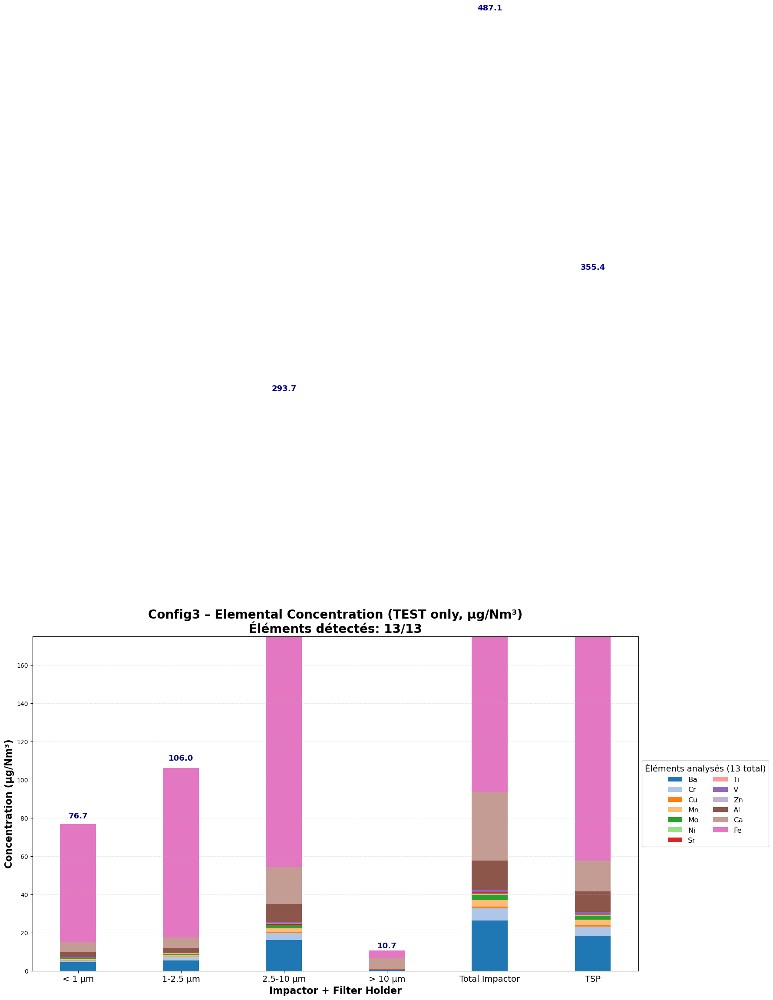


📈 Plotting TEST only: Config4


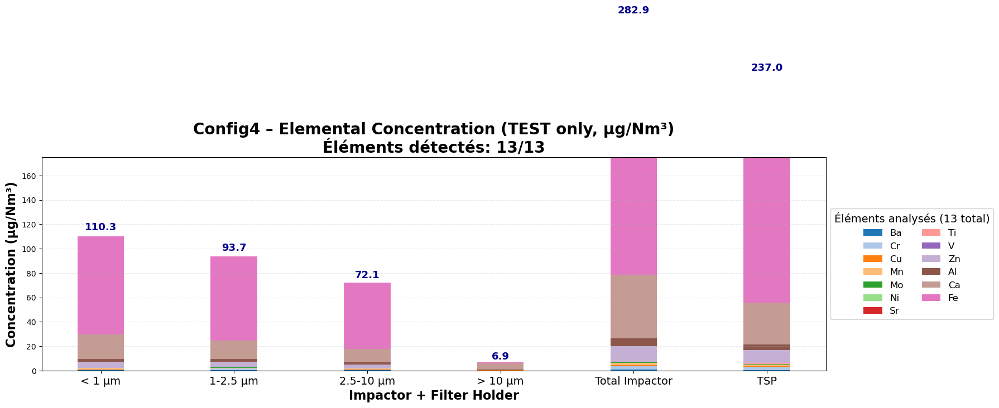


📈 Plotting TEST only: Config5


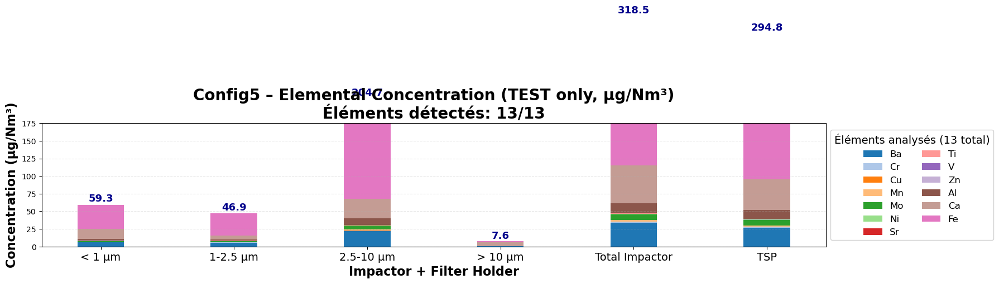


📈 Plotting TEST only: Config6


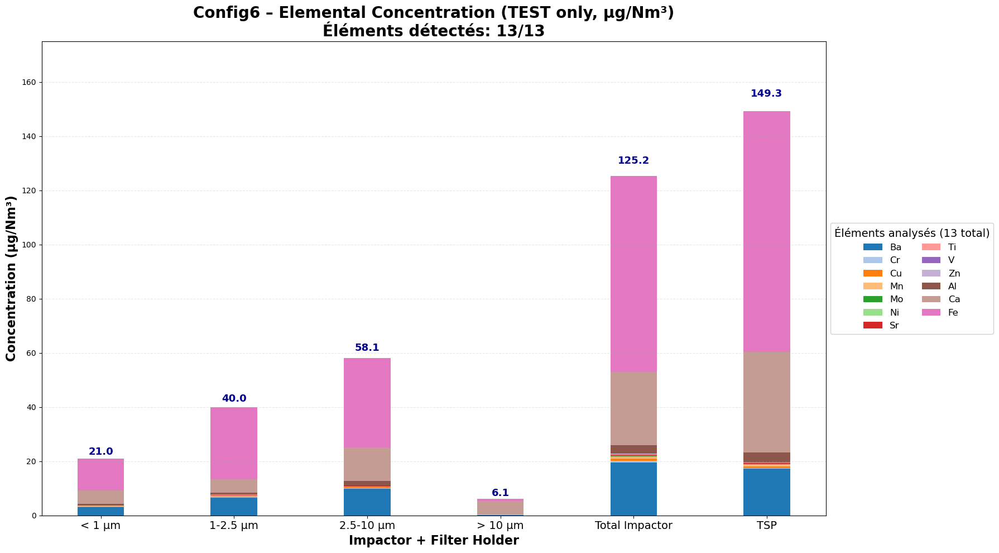


📈 Plotting TEST only: Config7


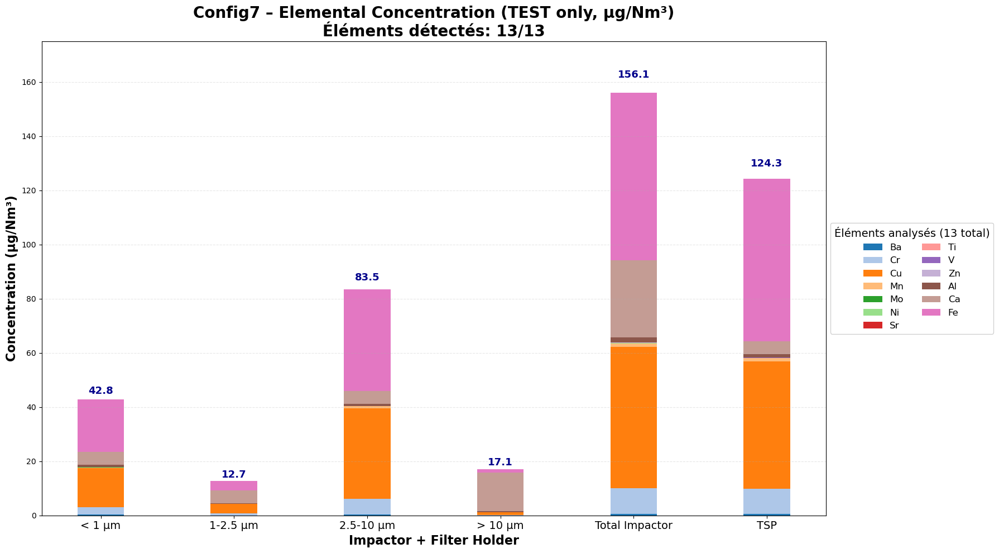


RÉSUMÉ FINAL
Nombre total de configurations: 5
Nombre total d'éléments uniques dans tous les top 10: 13

Liste globale des éléments (ordre alphabétique):
   1. Al
   2. Ba
   3. Ca
   4. Cr
   5. Cu
   6. Fe
   7. Mn
   8. Mo
   9. Ni
  10. Sr
  11. Ti
  12. V
  13. Zn

Éléments par configuration (top 10 des tests):

  Config3:
    - Fe
    - Ca
    - Ba
    - Al
    - Cr
    - Mn
    - Mo
    - V
    - Cu
    - Sr

  Config4:
    - Fe
    - Ca
    - Zn
    - Al
    - Cr
    - Mn
    - Cu
    - Ba
    - Mo
    - Ti

  Config5:
    - Fe
    - Ca
    - Ba
    - Al
    - Mo
    - Mn
    - Cr
    - Cu
    - Sr
    - Zn

  Config6:
    - Fe
    - Ca
    - Ba
    - Al
    - Cu
    - Mn
    - Sr
    - Cr
    - Ti
    - Ni

  Config7:
    - Fe
    - Cu
    - Ca
    - Cr
    - Al
    - Mn
    - Ba
    - Zn
    - Ni
    - Ti

DONE


In [15]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# 1) READ RAW FILE
fichier = r"C:\Users\Grira\OneDrive - Alstom\Documents\Paddle\Campagne2\Impacteur + FH\Masses and elemental composition_PTF2.xlsx"
df_raw = pd.read_excel(fichier, header=None)

# ============================================================
# 2) AUTO-DETECT HEADER ROW
# ============================================================
header_row = None
for i in range(50):
    row = df_raw.iloc[i].astype(str).str.lower()
    if "particle diameter" in row.tolist() and "filter name" in row.tolist():
        header_row = i
        break

df = pd.read_excel(fichier, header=header_row)
df.columns = df.columns.map(lambda x: str(x).strip())

# ============================================================
# 3) FILTER TYPE (Blank / Test)
# ============================================================
def detect_type(x):
    x = str(x).strip()
    if not x or x == 'nan':
        return None
    if x.startswith("B"):
        return "Blank"
    else:
        return "Test"

df["Type"] = df["Filter name"].apply(detect_type)
df = df[df["Type"].notna()]

# ============================================================
# 4) MACHINE NAME EXTRACTION
# ============================================================
df["Machine"] = df.iloc[:,0].astype(str).str.extract(
    r"(Config[0-9A-Za-z\-]*)", expand=False
).ffill()

# ============================================================
# 5) PARTICLE SIZE ORDER
# ============================================================
core_sizes = ["< 1 µm","1-2.5 µm","2.5-10 µm","> 10 µm"]
size_order = ["< 1 µm","1-2.5 µm","2.5-10 µm","> 10 µm","Total Impactor","TSP"]

# ============================================================
# 6) ELEMENTAL CONCENTRATIONS (already µg/Nm³)
# ============================================================
elem_cols = [c for c in df.columns if "(µg/Nm3 filter)" in c]
df[elem_cols] = df[elem_cols].apply(pd.to_numeric, errors="coerce").fillna(0)

elem_labels = {e: e.replace(" (µg/Nm3 filter)", "") for e in elem_cols}

# ============================================================
# 7) TOTAL MASS CONCENTRATION (µg/Nm³) - GARDÉ POUR CALCUL MAIS PAS POUR AFFICHAGE
# ============================================================
col_mass_conc = [c for c in df.columns if "Concentration" in c and "(µg/Nm3)" in c][0]
df[col_mass_conc] = pd.to_numeric(df[col_mass_conc], errors="coerce").fillna(0)

# ============================================================
# 8) COMPUTE TOP‑10 ELEMENTS FOR TESTS ONLY
# ============================================================
print("\n" + "="*80)
print("   TOP 10 ÉLÉMENTS PAR CONFIGURATION (TESTS UNIQUEMENT)")
print("   Concentration en µg/Nm³")
print("="*80 + "\n")

configs = df["Machine"].unique()

# Dictionnaire pour stocker les top 10 tests
machine_top10_tests = {}

for config in configs:

    print(f"\n------ {config} ------")
    print("-" * 50)

    # Filtrer uniquement les TESTS
    df_config = df[(df["Machine"] == config) & (df["Type"] == "Test")]

    if df_config.empty:
        print(f"⚠ Pas de données Test pour {config}\n")
        continue

    total_conc = df_config[elem_cols].sum(axis=0)
    top10 = total_conc.sort_values(ascending=False).head(10)
    
    # Stocker dans un dictionnaire
    machine_top10_tests[config] = top10.index.tolist()

    # Nettoyer les noms pour l'affichage
    top10_clean = top10.copy()
    top10_clean.index = [elem_labels[c] for c in top10_clean.index]

    print(f"\n{'Rang':<6} {'Élément':<15} {'Concentration totale (µg/Nm³)':<25}")
    print("-" * 50)

    for rank, (elem, value) in enumerate(top10_clean.items(), 1):
        print(f"{rank:<6} {elem:<15} {value:<25.2f}")

    print("-" * 50)
    print(f"Total des 10 éléments: {top10.sum():.2f} µg/Nm³")
    print(f"Total général (tous éléments tests): {total_conc.sum():.2f} µg/Nm³")
    if total_conc.sum() > 0:
        print(f"Les 10 éléments représentent: {(top10.sum()/total_conc.sum()*100):.1f}% du total")
    print("\n")

# ============================================================
# 9) RÉSUMÉ FINAL DES TOP 10 PAR CONFIGURATION (TESTS)
# ============================================================
print("\n" + "="*80)
print("RÉSUMÉ FINAL - TOP 10 PAR CONFIGURATION (TESTS)")
print("="*80)

for config, top10 in machine_top10_tests.items():
    print(f"\n🔧 {config}")
    print("-" * 40)
    for i, elem in enumerate(top10, 1):
        elem_name = elem_labels[elem]
        print(f"  {i:2d}. {elem_name}")

# ============================================================
# 10) LISTE GLOBALE DES ÉLÉMENTS PRÉSENTS DANS LES TOP 10 TESTS
# ============================================================
global_elements_tests = set()
for top10_list in machine_top10_tests.values():
    global_elements_tests.update(top10_list)

global_elements_tests = sorted(list(global_elements_tests), key=lambda x: elem_labels[x])

print("\n" + "="*80)
print(f"LISTE GLOBALE DES ÉLÉMENTS DANS LES TOP 10 DES TESTS ({len(global_elements_tests)} éléments uniques)")
print("="*80)
for i, elem in enumerate(global_elements_tests, 1):
    print(f"  {i:2d}. {elem_labels[elem]}")

# ============================================================
# 11) TEST PLOTS — µg/Nm³ (SANS MASSE)
# ============================================================
print("\n" + "="*80)
print("GÉNÉRATION DES GRAPHIQUES POUR LES TESTS")
print("(Tous les éléments de la liste globale sont affichés - Même légende sur toutes les configs)")
print("(Sans la barre de concentration massique)")
print("="*80)

# Garder TOUS les éléments de la liste globale
elem_cols_to_plot = [c for c in elem_cols if c in global_elements_tests]

# Palette fixe basée sur la liste globale (MÊME POUR TOUTES LES CONFIGS)
cmap = plt.get_cmap("tab20")
colors = {elem: cmap(i % 20) for i, elem in enumerate(elem_cols_to_plot)}

for machine, dgroup in df.groupby("Machine"):

    print(f"\n📈 Plotting TEST only: {machine}")

    tests = dgroup[dgroup["Type"] == "Test"]
    if tests.empty:
        print("⚠ No TEST data")
        continue

    # ✅ SUPPRESSION de col_mass_conc - on ne garde que les éléments
    dplot = tests[["Particle diameter"] + elem_cols_to_plot].copy()
    dplot["Particle diameter"] = dplot["Particle diameter"].astype(str).str.strip()

    plt.figure(figsize=(18,10))
    width = 0.35
    x = np.arange(len(size_order))

    # ----------- GROUP ELEMENTS -----------
    grouped = dplot.groupby("Particle diameter")[elem_cols_to_plot].sum()
    grouped.loc["Total Impactor"] = grouped.reindex(core_sizes).sum()
    grouped = grouped.reindex(size_order).fillna(0)

    bottom = np.zeros(len(size_order))

    # ----------- STACKED BARS (TOUS LES ÉLÉMENTS DE LA LISTE GLOBALE) -----------
    for elem in elem_cols_to_plot:
        vals = grouped[elem].values.astype(float)
        plt.bar(
            x, vals,
            width,
            bottom=bottom,
            color=colors[elem],
            label=elem_labels[elem]
        )
        bottom += vals

    # ----------- TOTAL ELEMENT CONCENTRATION LABELS -----------
    total_elements = grouped.sum(axis=1).values

    for i, total in enumerate(total_elements):
        if total > 0:
            plt.text(
                x[i],
                total * 1.03,
                f"{total:.1f}",
                ha="center",
                va="bottom",
                fontsize=13,
                fontweight="bold",
                color="darkblue"
            )

    # ✅ SUPPRESSION de la barre de masse concentration (plus de code pour mass_group)

    # ----------- FORMATTING -----------
    # Ajustement dynamique de la limite Y basé uniquement sur les éléments
    # plt.ylim(0, 1200)
    # plt.ylim(0, 550)
    plt.ylim(0, 175)

    plt.xticks(x, size_order, fontsize=14)
    plt.ylabel("Concentration (µg/Nm³)", fontsize=16, fontweight="bold")
    plt.xlabel("Impactor + Filter Holder", fontsize=16, fontweight="bold")
    
    # Compter les éléments détectés vs totaux
    elements_detected = sum(1 for elem in elem_cols_to_plot if tests[elem].sum() > 0)
    
    plt.title(f"{machine} – Elemental Concentration (TEST only, µg/Nm³)\n"
              f"Éléments détectés: {elements_detected}/{len(elem_cols_to_plot)}", 
              fontsize=20, fontweight="bold")

    plt.grid(axis='y', linestyle='--', alpha=0.3)
    
    # Légende UNIQUE pour toutes les configurations
    plt.legend(
        loc="center left",
        bbox_to_anchor=(1, 0.5),
        fontsize=12,
        title=f"Éléments analysés ({len(elem_cols_to_plot)} total)",
        title_fontsize=14,
        ncol=2 if len(elem_cols_to_plot) > 10 else 1,
        framealpha=0.9
    )

    plt.tight_layout()
    plt.show()

# ============================================================
# 12) RÉSUMÉ FINAL
# ============================================================
print("\n" + "="*80)
print("RÉSUMÉ FINAL")
print("="*80)
print(f"Nombre total de configurations: {len(machine_top10_tests)}")
print(f"Nombre total d'éléments uniques dans tous les top 10: {len(global_elements_tests)}")
print("\nListe globale des éléments (ordre alphabétique):")
for i, elem in enumerate(global_elements_tests, 1):
    print(f"  {i:2d}. {elem_labels[elem]}")
    
print("\nÉléments par configuration (top 10 des tests):")
for machine, top10 in machine_top10_tests.items():
    print(f"\n  {machine}:")
    for elem in top10:
        print(f"    - {elem_labels[elem]}")

print("\n" + "="*80)
print("DONE")
print("="*80)

##### PM1, PM2.5, PM10, PM >10 µm, Total Impactor, Filter holder

Mass concentration : Test vs Blank 

Plot: Config3


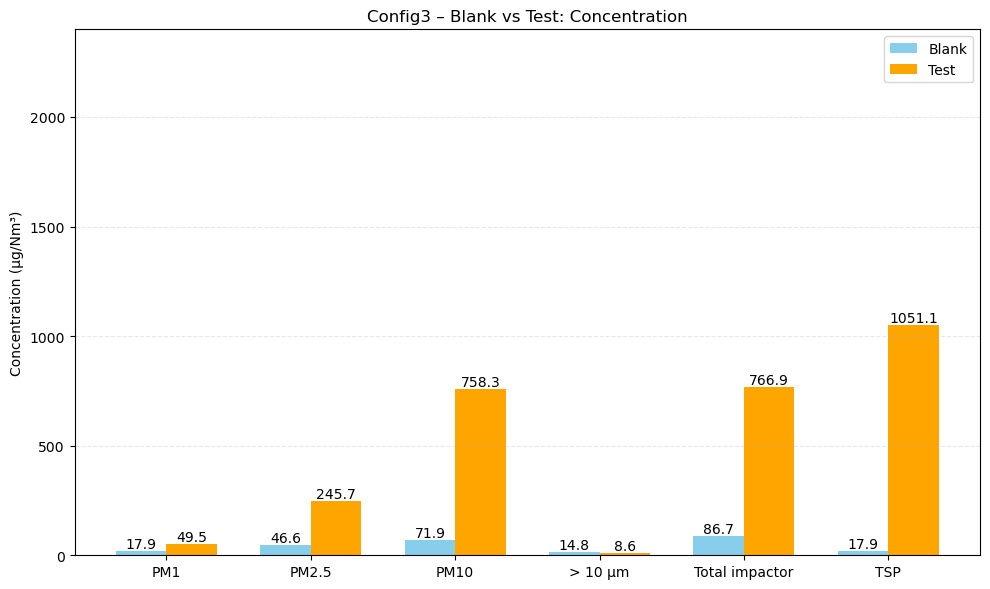

Plot: Config4


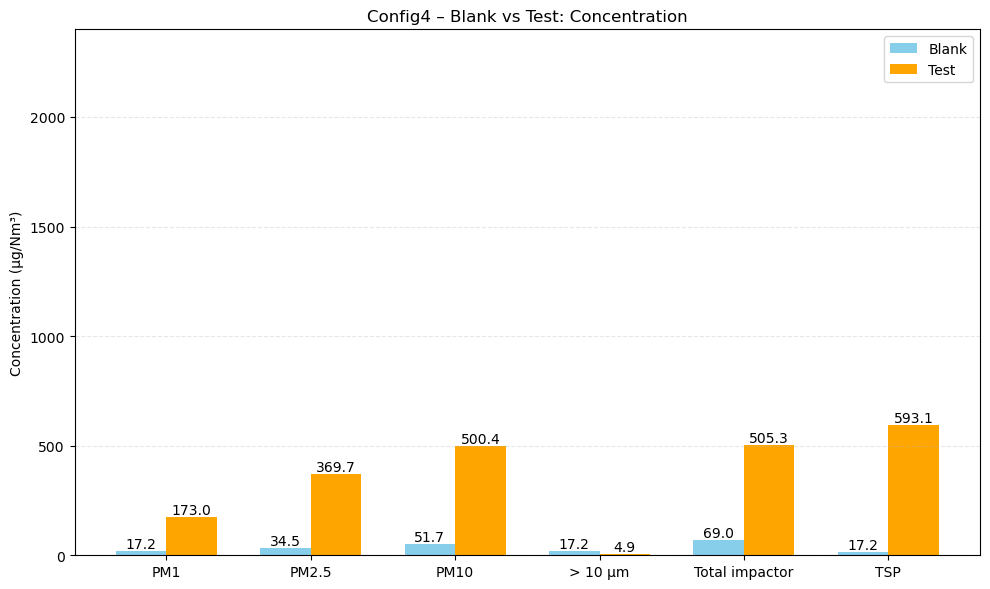

Plot: Config5


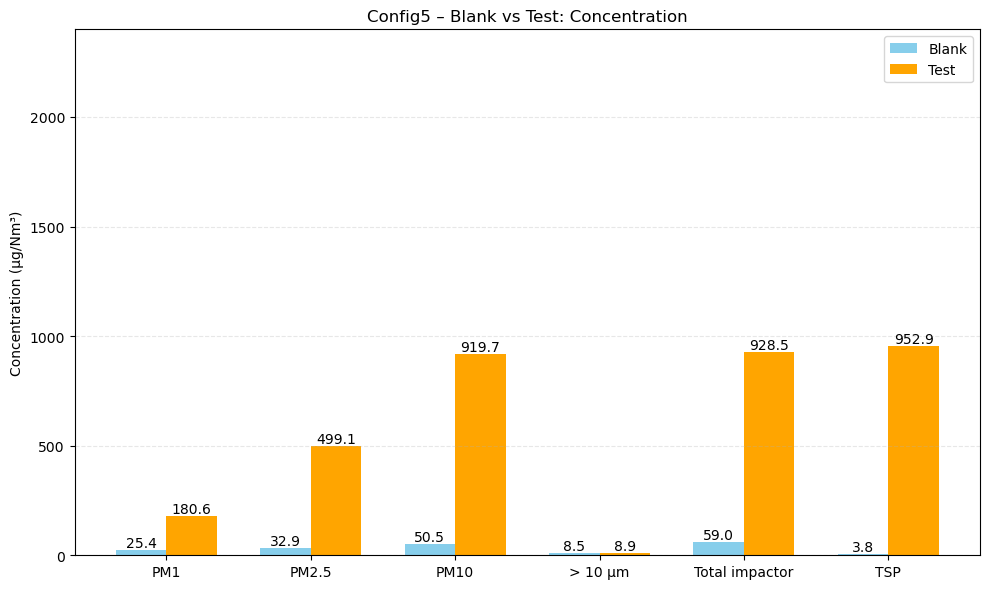

Plot: Config6


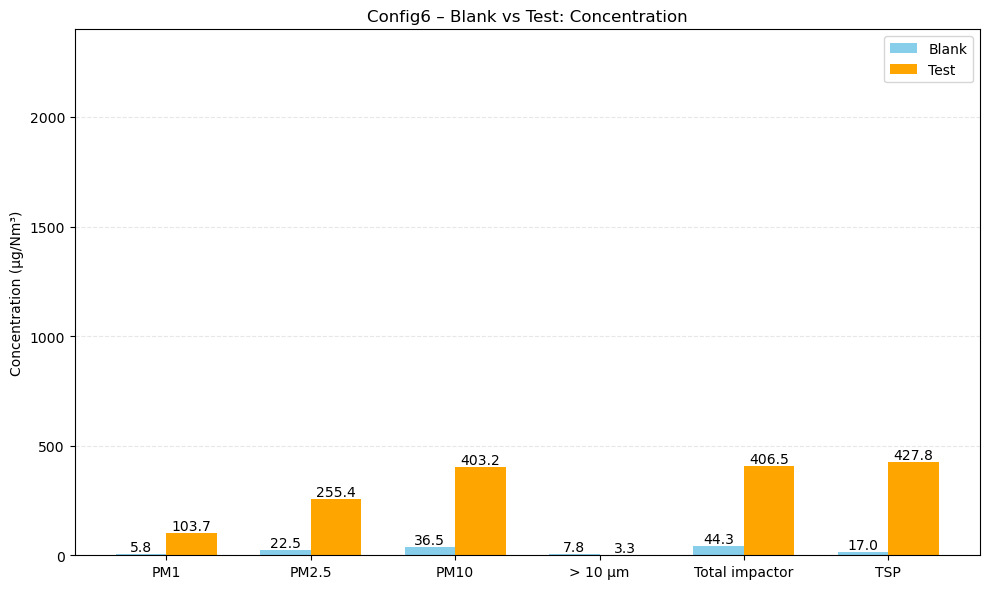

Plot: Config7


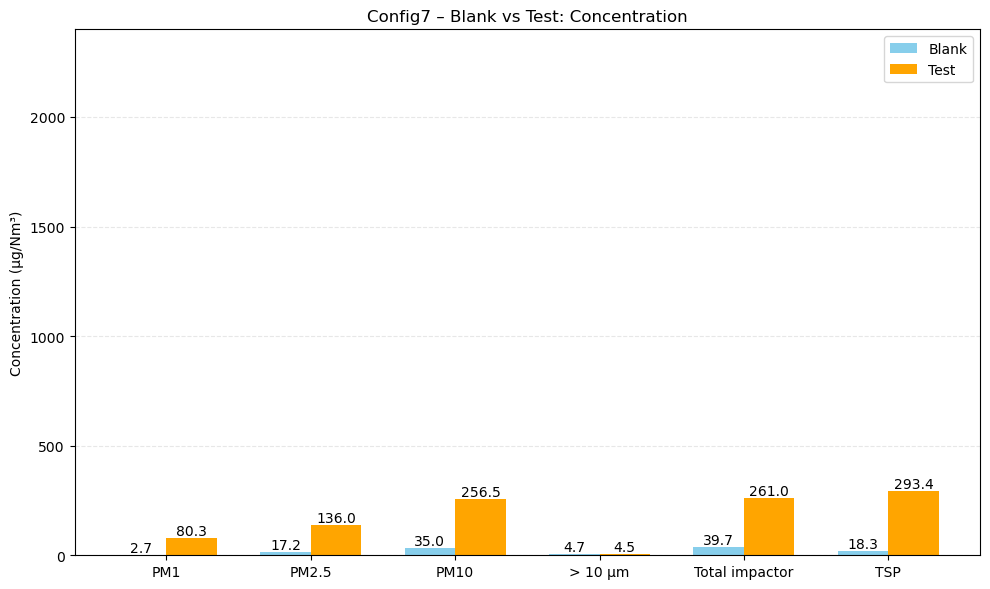

In [19]:
import numpy as np
import matplotlib.pyplot as plt

# ------------------------------------------
# DEFINE PARTICLE SIZE LABELS USED IN YOUR DF
# ------------------------------------------
DIAM_PM1      = "< 1 µm"
DIAM_1_25     = "1-2.5 µm"
DIAM_2_10     = "2.5-10 µm"
DIAM_10_INF   = "> 10 µm"
DIAM_TSP      = "TSP"

# ------------------------------------------
# USE CONCENTRATION COLUMN FROM EXCEL
# ------------------------------------------
col_conc = [c for c in df_clean.columns if "concentration" in c.lower()][0]   # NEW

# ------------------------------------------
# LOOP OVER MACHINES
# ------------------------------------------
for machine, dgroup in df_clean.groupby("Machine"):

    print(f"Plot: {machine}")

    blanks = dgroup[dgroup["Type"] == "Blank"]
    tests  = dgroup[dgroup["Type"] == "Test"]

    if blanks.empty or tests.empty:
        print("⚠ Not enough data")
        continue

    # FUNCTION TO EXTRACT CONCENTRATION
    def get_conc(df_sub, diam):
        row = df_sub[df_sub[col_stage] == diam]
        if len(row) == 0:
            return None
        return float(row[col_conc].values[0])

    # --- READ RAW CONCENTRATIONS ---
    b_PM1  = get_conc(blanks, DIAM_PM1)
    b_1_25 = get_conc(blanks, DIAM_1_25)
    b_2_10 = get_conc(blanks, DIAM_2_10)
    b_10i  = get_conc(blanks, DIAM_10_INF)
    b_TSP  = get_conc(blanks, DIAM_TSP)

    t_PM1  = get_conc(tests, DIAM_PM1)
    t_1_25 = get_conc(tests, DIAM_1_25)
    t_2_10 = get_conc(tests, DIAM_2_10)
    t_10i  = get_conc(tests, DIAM_10_INF)
    t_TSP  = get_conc(tests, DIAM_TSP)

    # ------------------------------------------
    # COMPUTE PM FRACTIONS (CONCENTRATION)
    # ------------------------------------------
    # PM1
    blank_PM1 = b_PM1
    test_PM1  = t_PM1

    # PM2.5 = PM1 + stage 1–2.5
    blank_PM25 = sum(v for v in [b_PM1, b_1_25] if v is not None)
    test_PM25  = sum(v for v in [t_PM1, t_1_25] if v is not None)

    # PM10 = PM1 + 1–2.5 + 2.5–10
    blank_PM10 = sum(v for v in [b_PM1, b_1_25, b_2_10] if v is not None)
    test_PM10  = sum(v for v in [t_PM1, t_1_25, t_2_10] if v is not None)

    # >10 µm
    blank_10i = b_10i
    test_10i  = t_10i

    # Total Impactor (sum of concentrations)
    blank_TI = sum(v for v in [b_PM1, b_1_25, b_2_10, b_10i] if v is not None)
    test_TI  = sum(v for v in [t_PM1, t_1_25, t_2_10, t_10i] if v is not None)

    # TSP
    blank_TSP = b_TSP
    test_TSP  = t_TSP

    # ------------------------------------------
    # PLOT
    # ------------------------------------------
    categories = ["PM1", "PM2.5", "PM10", "> 10 µm", "Total impactor", "TSP"]
    blank_vals = [blank_PM1, blank_PM25, blank_PM10, blank_10i, blank_TI, blank_TSP]
    test_vals  = [test_PM1,  test_PM25,  test_PM10,  test_10i,  test_TI,  test_TSP]

    x = np.arange(len(categories))
    width = 0.35

    plt.figure(figsize=(10,6))

    bars_b = plt.bar(x - width/2, blank_vals, width, label="Blank", color="skyblue")
    bars_t = plt.bar(x + width/2, test_vals, width, label="Test", color="orange")

    # annotation
    for bar in list(bars_b) + list(bars_t):
        h = bar.get_height()
        plt.text(bar.get_x() + bar.get_width()/2, h, f"{h:.1f}", ha='center', va='bottom')

    plt.ylim(0, 2400)  # Adjust based on your data
    plt.xticks(x, categories)
    plt.ylabel("Concentration (µg/Nm³)")   # UPDATED
    plt.title(f"{machine} – Blank vs Test: Concentration")  # UPDATED
    plt.grid(axis="y", linestyle="--", alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()

Mass


Plot: Config3


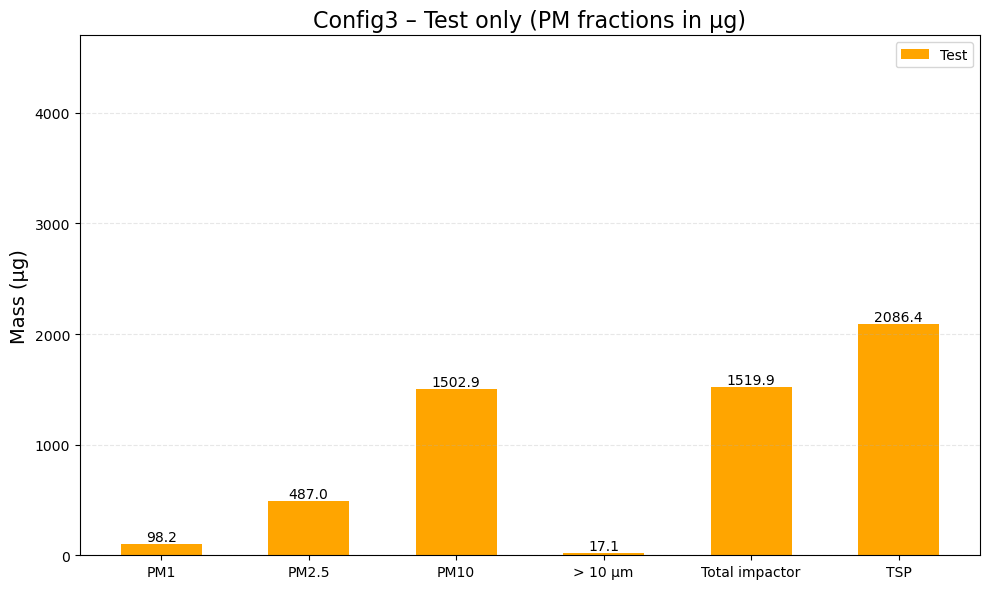


Plot: Config4


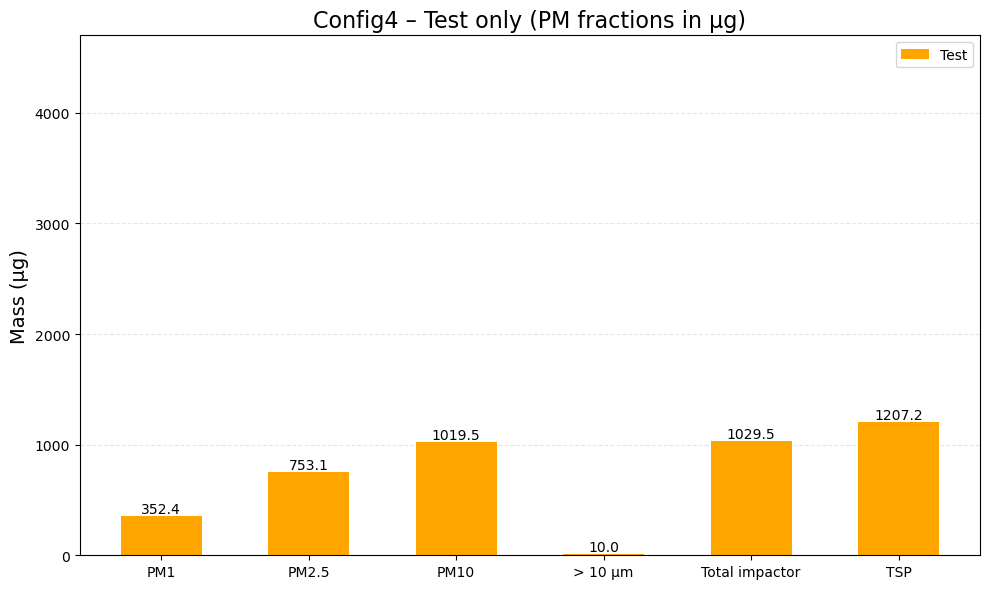


Plot: Config5


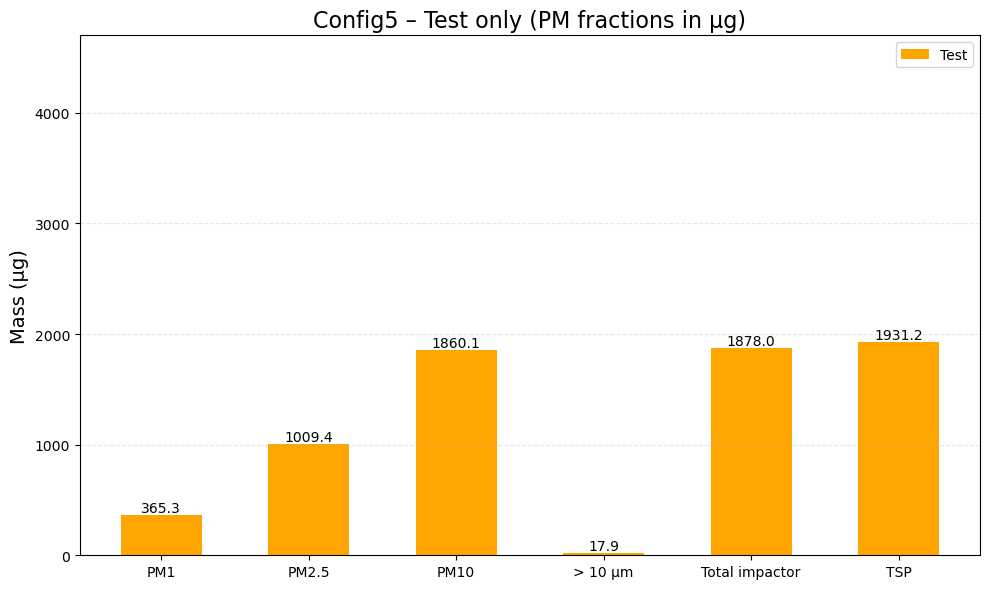


Plot: Config6


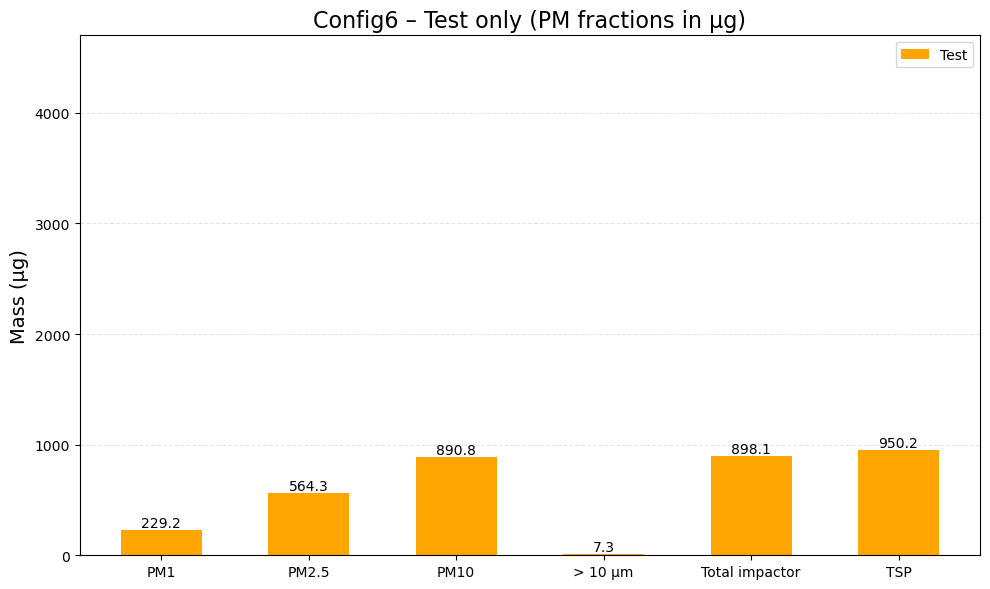


Plot: Config7


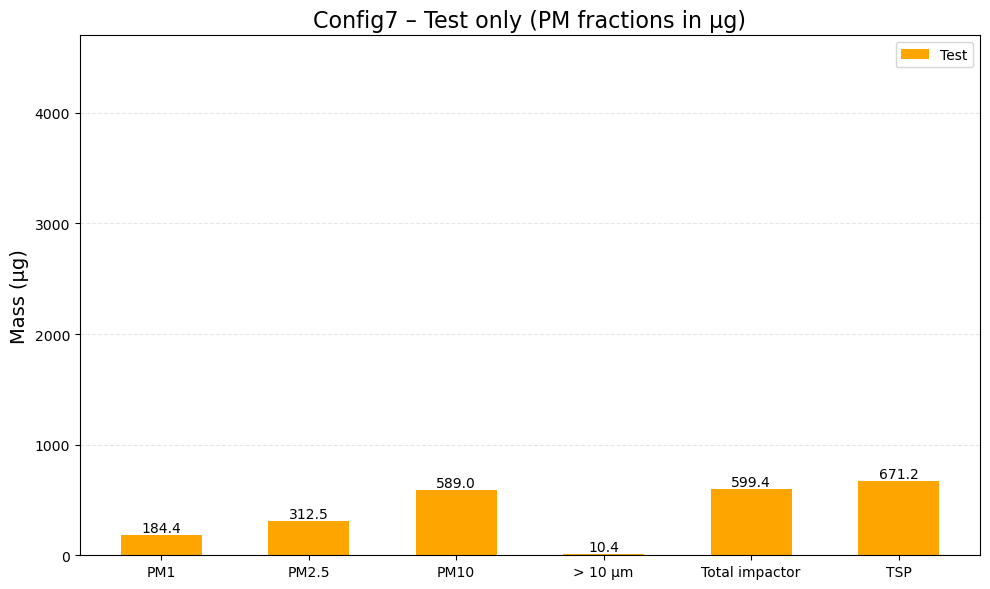

In [20]:
import numpy as np
import matplotlib.pyplot as plt

# ------------------------------------------
# DEFINE PARTICLE SIZE LABELS USED IN YOUR DF
# ------------------------------------------
DIAM_PM1      = "< 1 µm"
DIAM_1_25     = "1-2.5 µm"
DIAM_2_10     = "2.5-10 µm"
DIAM_10_INF   = "> 10 µm"
DIAM_TSP      = "TSP"

# ------------------------------------------
# LOOP OVER MACHINES
# ------------------------------------------
for machine, dgroup in df_clean.groupby("Machine"):

    print(f"\nPlot: {machine}")

    # ✅ KEEP ONLY TEST FILTERS
    tests = dgroup[dgroup["Type"] == "Test"]

    if tests.empty:
        print("⚠ No TEST data")
        continue

    # ✅ FUNCTION TO EXTRACT MASS — convert mg → µg
    def get_mass(df_sub, diam):
        row = df_sub[df_sub[col_stage] == diam]
        if len(row) == 0:
            return None
        mg = float(row[col_mass].values[0])     # value in mg
        return mg * 1000                        # ✅ convert to µg

    # --- READ MASSES (TEST ONLY, µg) ---
    t_PM1  = get_mass(tests, DIAM_PM1)
    t_1_25 = get_mass(tests, DIAM_1_25)
    t_2_10 = get_mass(tests, DIAM_2_10)
    t_10i  = get_mass(tests, DIAM_10_INF)
    t_TSP  = get_mass(tests, DIAM_TSP)

    # ------------------------------------------
    # COMPUTE PM FRACTIONS (ALL IN µg)
    # ------------------------------------------
    test_PM1 = t_PM1
    test_PM25 = sum(v for v in [t_PM1, t_1_25] if v is not None)
    test_PM10 = sum(v for v in [t_PM1, t_1_25, t_2_10] if v is not None)
    test_10i = t_10i
    test_TI = sum(v for v in [t_PM1, t_1_25, t_2_10, t_10i] if v is not None)
    test_TSP = t_TSP

    # ------------------------------------------
    # PLOT — TEST ONLY IN µg ✅
    # ------------------------------------------
    categories = ["PM1", "PM2.5", "PM10", "> 10 µm", "Total impactor", "TSP"]
    test_vals  = [test_PM1, test_PM25, test_PM10, test_10i, test_TI, test_TSP]

    x = np.arange(len(categories))
    width = 0.55

    plt.figure(figsize=(10,6))

    bars_t = plt.bar(x, test_vals, width, label="Test", color="orange")

    # --- annotation (µg) ---
    for bar in bars_t:
        h = bar.get_height()
        if h is not None:
            plt.text(
                bar.get_x() + bar.get_width()/2,
                h,
                f"{h:.1f}",     # ✅ in µg
                ha='center', va='bottom'
            )

    plt.ylim(0, 4700)
    plt.xticks(x, categories)
    plt.ylabel("Mass (µg)", fontsize=14)
    plt.title(f"{machine} – Test only (PM fractions in µg)", fontsize=16)
    plt.grid(axis="y", linestyle="--", alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()

Elemental composition


Plot for Config3


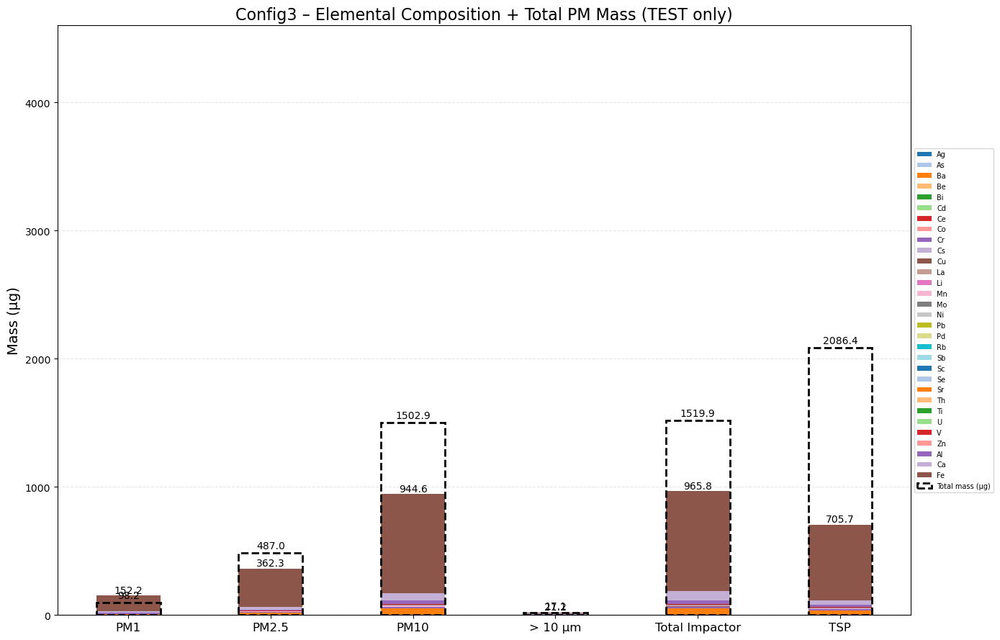


Plot for Config4


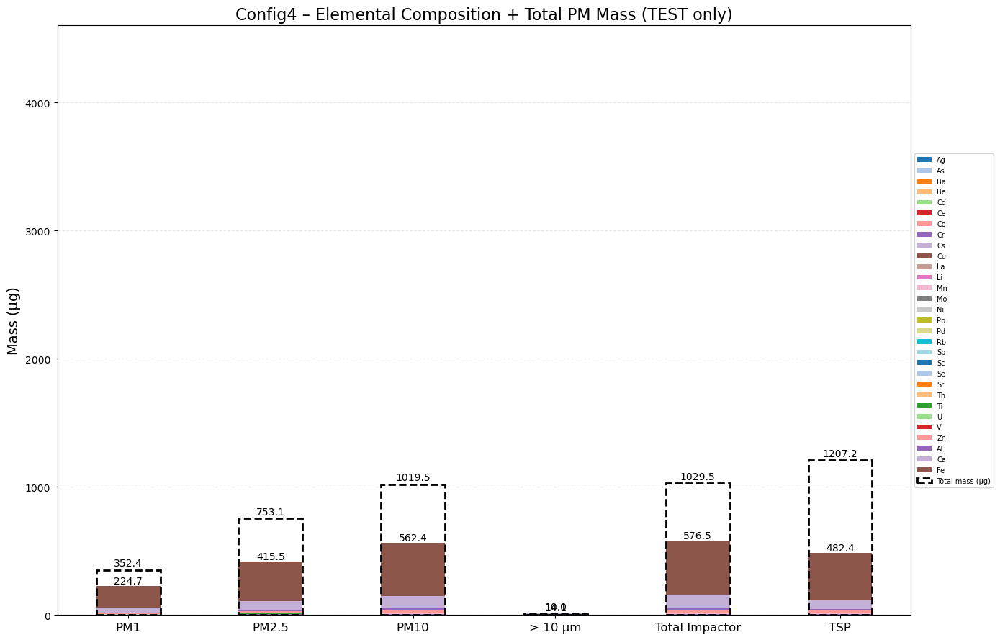


Plot for Config5


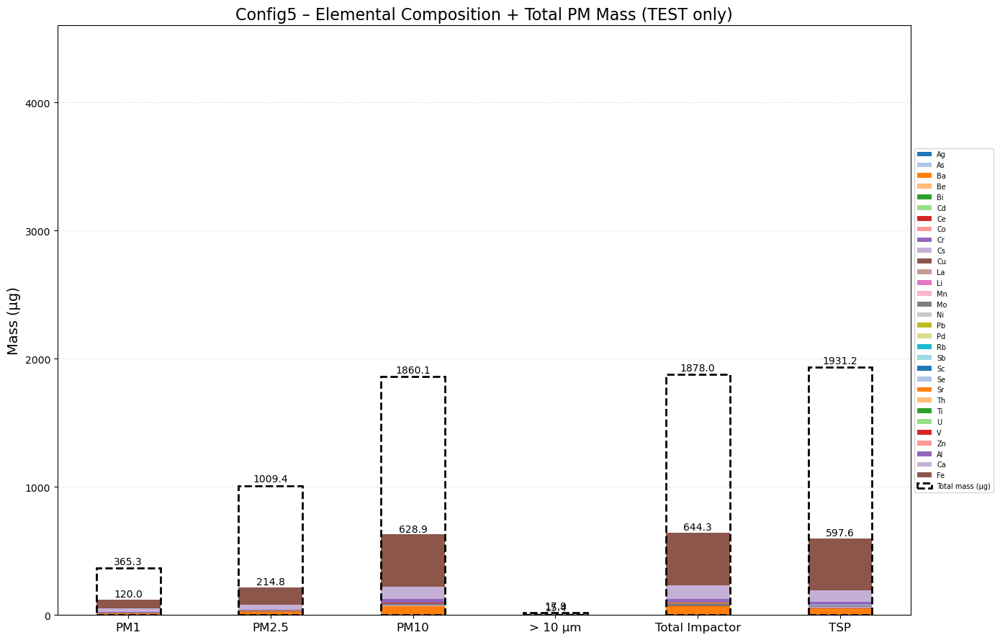


Plot for Config6


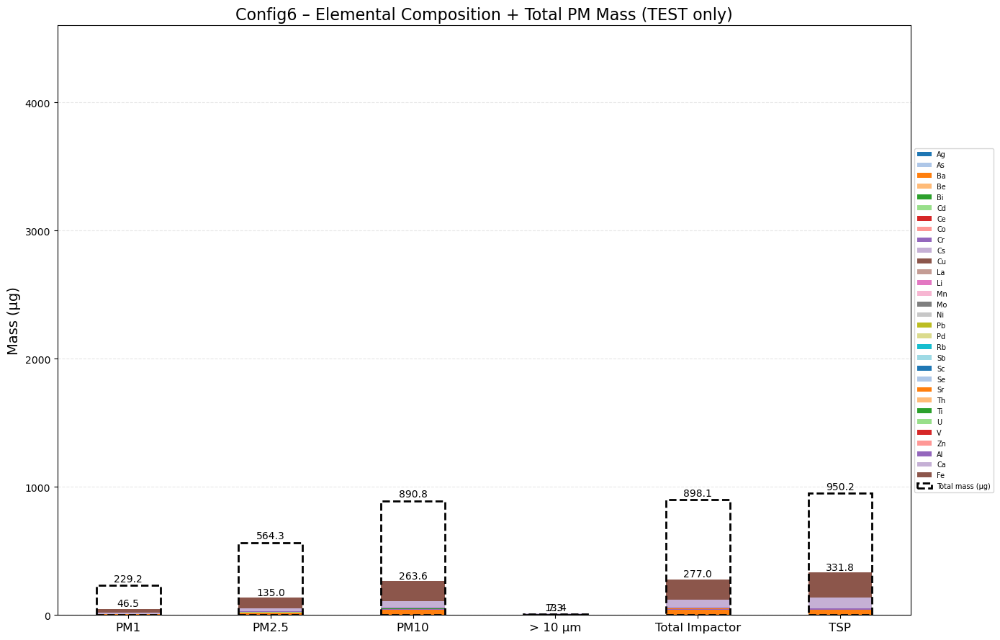


Plot for Config7


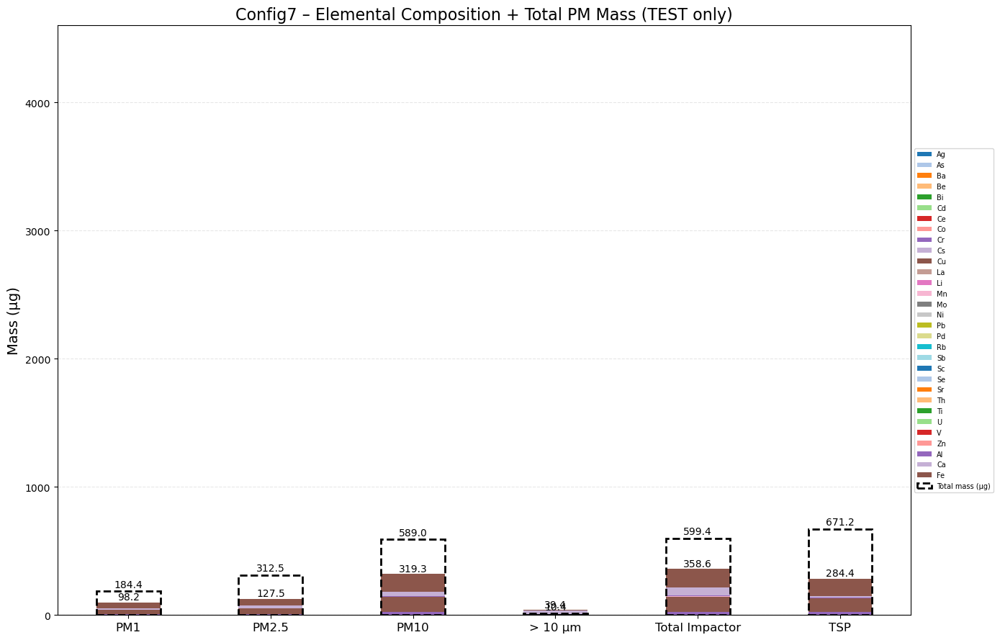


   TOP 10 ÉLÉMENTS PAR CONFIGURATION (TESTS UNIQUEMENT)


------ Config3 ------
--------------------------------------------------

Rang   Élément         Masse totale (µg)   
--------------------------------------------------
1      Fe              1371.40             
2      Ca              102.47              
3      Ba              88.57               
4      Al              51.55               
5      Cr              22.06               
6      Mn              12.27               
7      Mo              9.21                
8      V               3.73                
9      Cu              3.54                
10     Sr              2.37                
--------------------------------------------------
Total des 10 éléments: 1667.17 µg
Total général (tous éléments tests): 1671.55 µg
Les 10 éléments représentent: 99.7% du total



------ Config4 ------
--------------------------------------------------

Rang   Élément         Masse totale (µg)   
---------------------------------

In [22]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# 1) READ RAW FILE
fichier = r"C:\Users\Grira\OneDrive - Alstom\Documents\Paddle\Campagne2\Impacteur + FH\Masses and elemental composition_PTF2.xlsx"
df_raw = pd.read_excel(fichier, header=None)

# ============================================================
# 2) AUTO-DETECT HEADER ROW
# ============================================================
header_row = None
for i in range(50):
    row = df_raw.iloc[i].astype(str).str.lower()
    if "particle diameter" in row.tolist() and "filter name" in row.tolist():
        header_row = i
        break

df = pd.read_excel(fichier, header=header_row)
df.columns = df.columns.map(lambda x: str(x).strip())

# ============================================================
# 3) FILTER TYPE (Blank / Test)
# ============================================================
def detect_type(x):
    x = str(x).strip()
    if not x or x == 'nan':
        return None
    if x.startswith("B"):
        return "Blank"
    else:
        return "Test"

df["Type"] = df["Filter name"].apply(detect_type)
df = df[df["Type"].notna()]

# ============================================================
# 4) MACHINE NAME EXTRACTION
# ============================================================
df["Machine"] = df.iloc[:,0].astype(str).str.extract(
    r"(Config[0-9A-Za-z\-]*)", expand=False
).ffill()

# ============================================================
# 5) SIZE LABELS (ORIGINAL)
# ============================================================
DIAM_PM1      = "< 1 µm"
DIAM_1_25     = "1-2.5 µm"
DIAM_2_10     = "2.5-10 µm"
DIAM_10_INF   = "> 10 µm"
DIAM_TSP      = "TSP"

core_sizes = [DIAM_PM1, DIAM_1_25, DIAM_2_10, DIAM_10_INF]

# FIXED ORDER (RENAMED)
size_order = ["PM1", "PM2.5", "PM10", DIAM_10_INF, "Total Impactor", "TSP"]

# ============================================================
# 6) ELEMENTAL COLUMNS (ng/filter → µg/filter)
# ============================================================
elem_cols = [c for c in df.columns if "(ng/filter)" in c]

df[elem_cols] = df[elem_cols].apply(pd.to_numeric, errors="coerce").fillna(0)
df[elem_cols] = df[elem_cols] / 1000  # ng → µg

elem_labels = {e: e.replace(" (ng/filter)", "") for e in elem_cols}

# ============================================================
# 7) MASS COLUMN (mg → µg)
# ============================================================
col_mass = [c for c in df.columns if "mass" in c.lower()][0]
df[col_mass] = pd.to_numeric(df[col_mass], errors="coerce").fillna(0)
df[col_mass] = df[col_mass] * 1000  # mg → µg

# ============================================================
# 8) MERGED PLOT PER MACHINE - CORRECTED ELEMENT CALCULATIONS
# ============================================================
def get_mass(df_sub, diam):
    row = df_sub[df_sub["Particle diameter"] == diam]
    if len(row) == 0:
        return None
    return float(row[col_mass].values[0])

def get_elements(df_sub, diam):
    """Get element concentrations for a specific diameter"""
    row = df_sub[df_sub["Particle diameter"] == diam]
    if len(row) == 0:
        return pd.Series(0, index=elem_cols)
    return row[elem_cols].iloc[0]

for machine, dgroup in df.groupby("Machine"):

    print(f"\nPlot for {machine}")

    tests = dgroup[dgroup["Type"] == "Test"].copy()
    if tests.empty:
        print("⚠ No TEST data")
        continue

    tests["Particle diameter"] = tests["Particle diameter"].astype(str).str.strip()

    # ---------------------------------------------------
    # PM FRACTIONS (µg/filter) - MASS CALCULATION
    # ---------------------------------------------------
    t_PM1  = get_mass(tests, DIAM_PM1)
    t_1_25 = get_mass(tests, DIAM_1_25)
    t_2_10 = get_mass(tests, DIAM_2_10)
    t_10i  = get_mass(tests, DIAM_10_INF)
    t_TSP  = get_mass(tests, DIAM_TSP)

    pm_PM1  = t_PM1
    pm_PM25 = sum(v for v in [t_PM1, t_1_25] if v is not None)
    pm_PM10 = sum(v for v in [t_PM1, t_1_25, t_2_10] if v is not None)
    pm_10i  = t_10i
    pm_TI   = sum(v for v in [t_PM1, t_1_25, t_2_10, t_10i] if v is not None)

    pm_values = [pm_PM1, pm_PM25, pm_PM10, pm_10i, pm_TI, t_TSP]

    # ---------------------------------------------------
    # ELEMENTAL GROUPING (µg/filter) - CORRECTED
    # Get elements for each fraction individually
    # ---------------------------------------------------
    elem_PM1  = get_elements(tests, DIAM_PM1)
    elem_1_25 = get_elements(tests, DIAM_1_25)
    elem_2_10 = get_elements(tests, DIAM_2_10)
    elem_10i  = get_elements(tests, DIAM_10_INF)
    elem_TSP  = get_elements(tests, DIAM_TSP)

    # Calculate cumulative fractions (same logic as for mass)
    elem_PM2_5 = elem_PM1 + elem_1_25           # PM2.5 = PM1 + (1-2.5 µm)
    elem_PM10  = elem_PM1 + elem_1_25 + elem_2_10  # PM10 = PM1 + (1-2.5) + (2.5-10)
    elem_TI    = elem_PM1 + elem_1_25 + elem_2_10 + elem_10i  # Total Impactor = sum of all stages

    # Create DataFrame with all fractions
    ele = pd.DataFrame({
        "PM1": elem_PM1,
        "PM2.5": elem_PM2_5,
        "PM10": elem_PM10,
        DIAM_10_INF: elem_10i,
        "Total Impactor": elem_TI,
        "TSP": elem_TSP
    }).T

    # Reorder to match size_order
    ele = ele.reindex(size_order).fillna(0)

    # ---------------------------------------------------
    # PLOT
    # ---------------------------------------------------
    plt.figure(figsize=(14,9))
    x = np.arange(len(size_order))
    width = 0.45

    bottom = np.zeros(len(size_order))
    cmap = plt.get_cmap("tab20")
    color_map = {e: cmap(i % 20) for i, e in enumerate(elem_cols)}

    for elem in elem_cols:
        vals = ele[elem].values
        if vals.sum() == 0:
            continue
        plt.bar(x, vals, width, bottom=bottom,
                color=color_map[elem], label=elem_labels[elem])
        bottom += vals

    # element total
    for i, tot in enumerate(ele.sum(axis=1)):
        if tot > 0:
            plt.text(x[i], tot + 20, f"{tot:.1f}", ha='center', fontsize=10)

    # PM mass overlay
    for i, val in enumerate(pm_values):
        if val is not None and val > 0:
            plt.bar(x[i], val, width, fill=False, edgecolor="black",
                    linestyle="--", linewidth=2,
                    label="Total mass (µg)" if i == 0 else None)
            plt.text(x[i], val + 30, f"{val:.1f}", ha="center", fontsize=10, color="black")

    # Set y-axis limit based on max value
    max_val = max(ele.sum(axis=1).max(), max([v for v in pm_values if v is not None]))
    plt.ylim(0, 4600)
    plt.title(f"{machine} – Elemental Composition + Total PM Mass (TEST only)", fontsize=16)
    plt.xticks(x, size_order, fontsize=12)
    plt.ylabel("Mass (µg)", fontsize=14)
    plt.grid(axis='y', linestyle='--', alpha=0.3)
    plt.legend(loc="center left", bbox_to_anchor=(1,0.5), fontsize=7)
    plt.tight_layout()
    plt.show()


# ============================================================
print("\n" + "="*80)
print("   TOP 10 ÉLÉMENTS PAR CONFIGURATION (TESTS UNIQUEMENT)")
print("="*80 + "\n")

configs = df["Machine"].unique()

for config in configs:

    print(f"\n------ {config} ------")
    print("-" * 50)

    # ✅ CORRECTION : Filtrer uniquement les TESTS
    df_config = df[(df["Machine"] == config) & (df["Type"] == "Test")]

    # Vérifier s'il y a des données tests
    if df_config.empty:
        print(f"⚠ Pas de données Test pour {config}\n")
        continue

    total_mass = df_config[elem_cols].sum(axis=0)

    top10 = total_mass.sort_values(ascending=False).head(10)
    
    # Nettoyer les noms pour l'affichage
    top10.index = [c.replace(" (ng/filter)", "") for c in top10.index]

    # Affichage détaillé avec tableau
    print(f"\n{'Rang':<6} {'Élément':<15} {'Masse totale (µg)':<20}")
    print("-" * 50)
    
    for rank, (elem, value) in enumerate(top10.items(), 1):
        print(f"{rank:<6} {elem:<15} {value:<20.2f}")
    
    print("-" * 50)
    print(f"Total des 10 éléments: {top10.sum():.2f} µg")
    print(f"Total général (tous éléments tests): {total_mass.sum():.2f} µg")
    if total_mass.sum() > 0:
        print(f"Les 10 éléments représentent: {(top10.sum()/total_mass.sum()*100):.1f}% du total")
    print("\n")

print("\n" + "="*80)
print("DONE (Top‑10 elements printed above - based ONLY on TESTS)")
print("="*80)
print("==============================================\n")

Elemental composition (top 10)


   TOP 10 ÉLÉMENTS PAR CONFIGURATION (TESTS UNIQUEMENT)
   Masse en µg


------ Config3 ------
--------------------------------------------------

Rang   Élément         Masse totale (µg)   
--------------------------------------------------
1      Fe              1371.40             
2      Ca              102.47              
3      Ba              88.57               
4      Al              51.55               
5      Cr              22.06               
6      Mn              12.27               
7      Mo              9.21                
8      V               3.73                
9      Cu              3.54                
10     Sr              2.37                
--------------------------------------------------
Total des 10 éléments: 1667.17 µg
Total général (tous éléments tests): 1671.55 µg
Les 10 éléments représentent: 99.7% du total



------ Config4 ------
--------------------------------------------------

Rang   Élément         Masse totale (µg)   
------------------

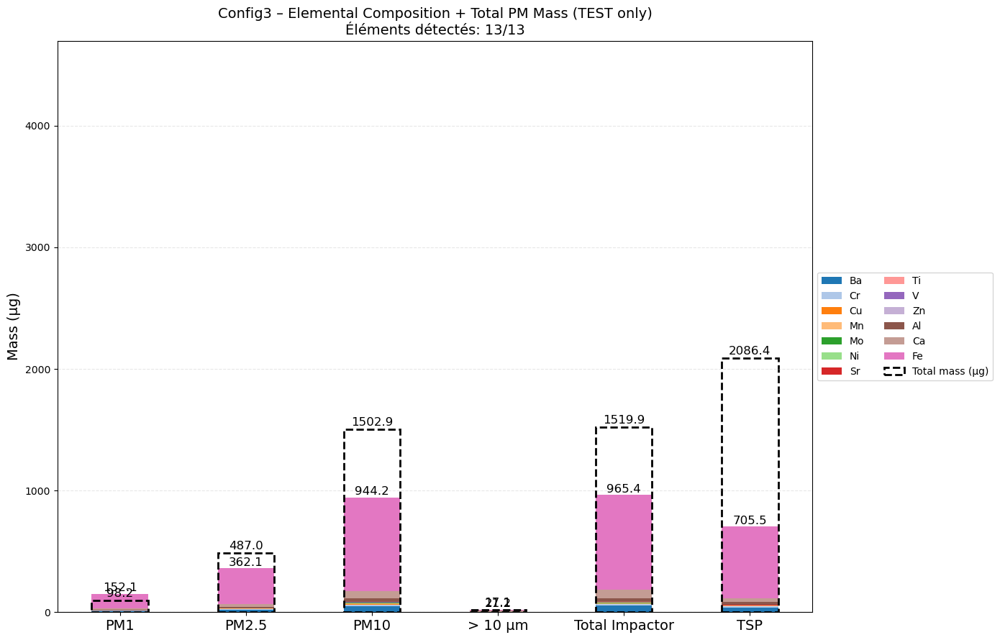


📈 Plot for Config4


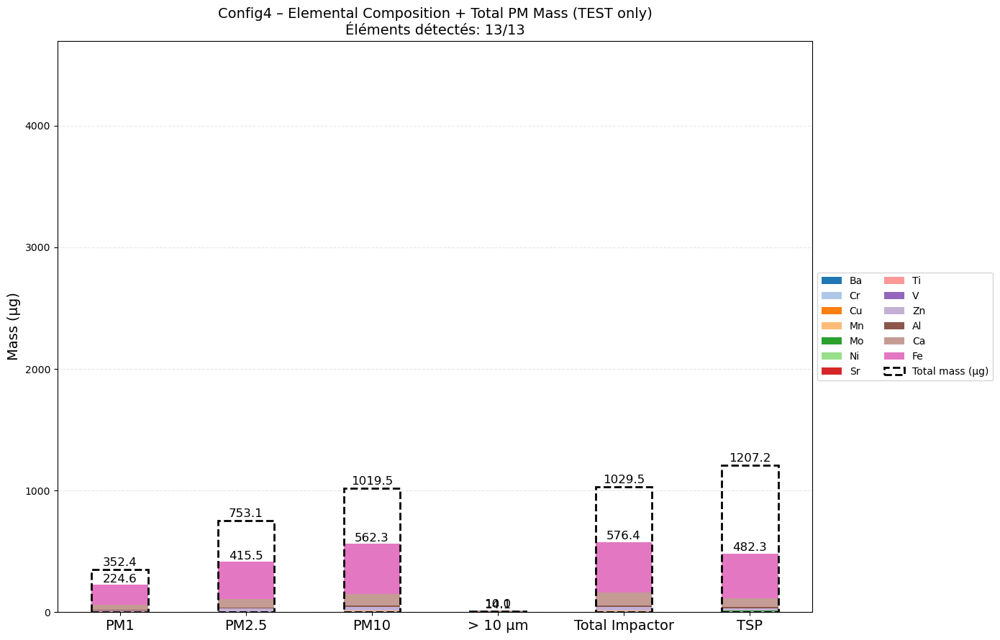


📈 Plot for Config5


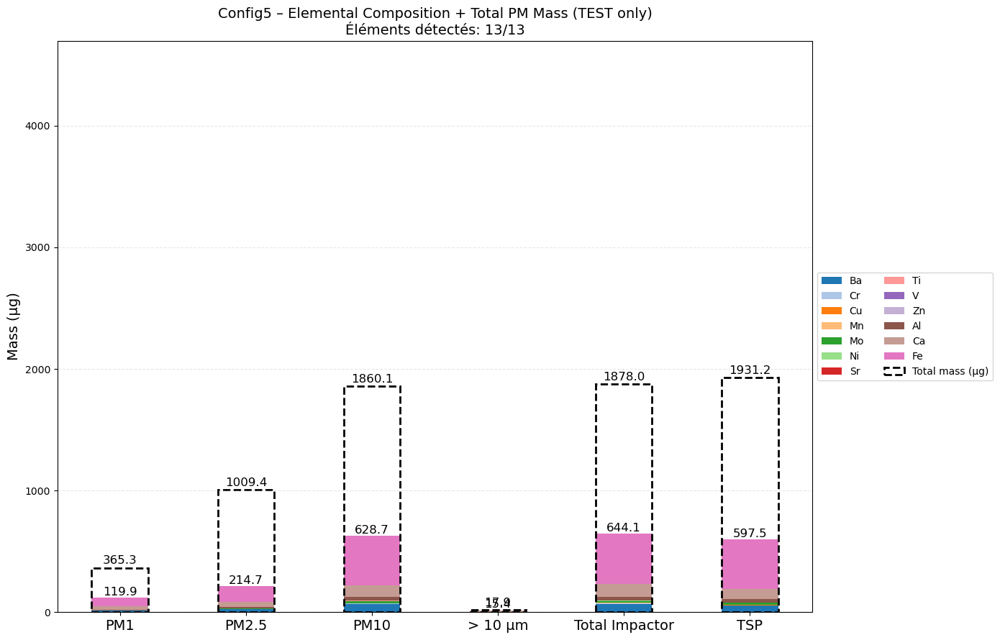


📈 Plot for Config6


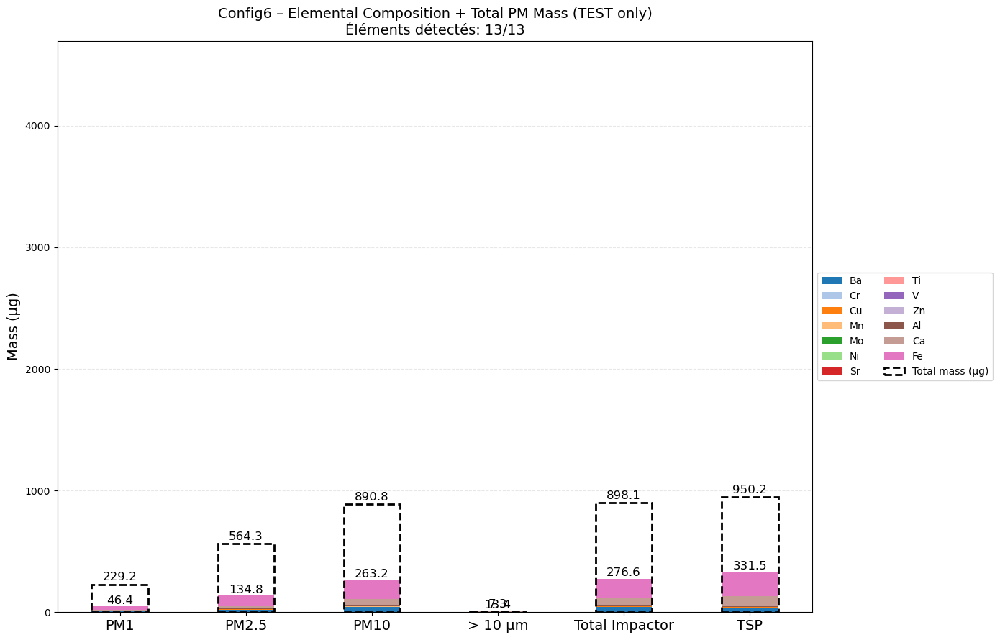


📈 Plot for Config7


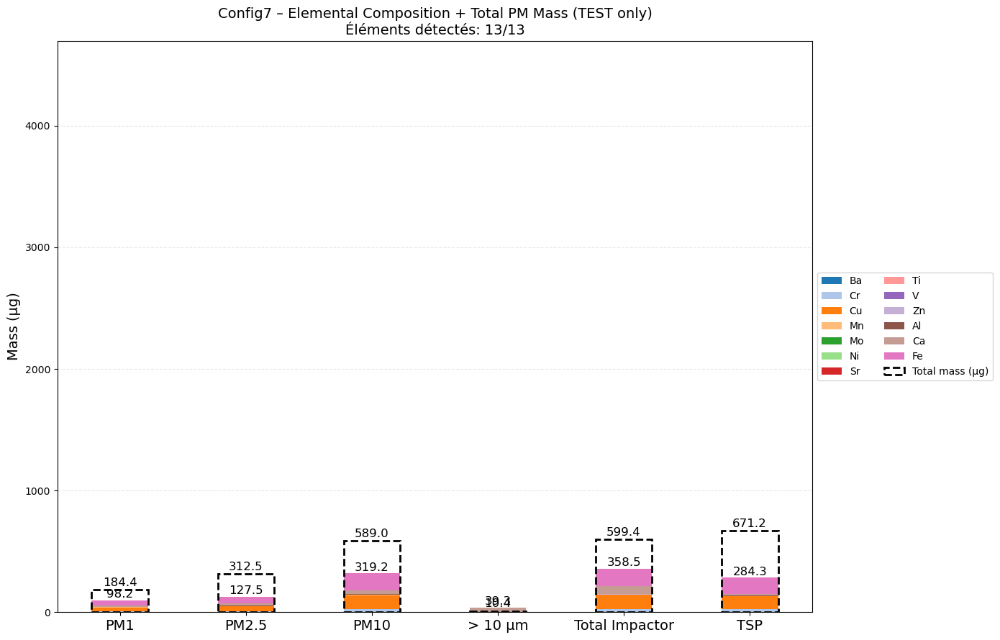


RÉSUMÉ FINAL
Nombre total de configurations: 5
Nombre total d'éléments uniques dans tous les top 10: 13

📊 LISTE GLOBALE DES ÉLÉMENTS (ordre alphabétique):
   1. Al
   2. Ba
   3. Ca
   4. Cr
   5. Cu
   6. Fe
   7. Mn
   8. Mo
   9. Ni
  10. Sr
  11. Ti
  12. V
  13. Zn

📈 TOP 10 PAR CONFIGURATION (basé uniquement sur les tests):

  🔧 Config3:
      1. Fe
      2. Ca
      3. Ba
      4. Al
      5. Cr
      6. Mn
      7. Mo
      8. V
      9. Cu
     10. Sr

  🔧 Config4:
      1. Fe
      2. Ca
      3. Zn
      4. Al
      5. Cr
      6. Mn
      7. Cu
      8. Ba
      9. Mo
     10. Ti

  🔧 Config5:
      1. Fe
      2. Ca
      3. Ba
      4. Al
      5. Mo
      6. Mn
      7. Cr
      8. Cu
      9. Sr
     10. Zn

  🔧 Config6:
      1. Fe
      2. Ca
      3. Ba
      4. Al
      5. Cu
      6. Mn
      7. Sr
      8. Cr
      9. Ti
     10. Ni

  🔧 Config7:
      1. Fe
      2. Cu
      3. Ca
      4. Cr
      5. Al
      6. Mn
      7. Ba
      8. Zn
      9. Ni
     10. 

In [25]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# 1) READ RAW FILE
fichier = r"C:\Users\Grira\OneDrive - Alstom\Documents\Paddle\Campagne2\Impacteur + FH\Masses and elemental composition_PTF2.xlsx"
df_raw = pd.read_excel(fichier, header=None)


# ============================================================
# 2) AUTO-DETECT HEADER ROW
# ============================================================
header_row = None
for i in range(50):
    row = df_raw.iloc[i].astype(str).str.lower()
    if "particle diameter" in row.tolist() and "filter name" in row.tolist():
        header_row = i
        break

df = pd.read_excel(fichier, header=header_row)
df.columns = df.columns.map(lambda x: str(x).strip())

# ============================================================
# 3) FILTER TYPE (Blank / Test)
# ============================================================
def detect_type(x):
    x = str(x).strip()
    if not x or x == 'nan':
        return None
    if x.startswith("B"):
        return "Blank"
    else:
        return "Test"

df["Type"] = df["Filter name"].apply(detect_type)
df = df[df["Type"].notna()]

# ============================================================
# 4) MACHINE NAME EXTRACTION
# ============================================================
df["Machine"] = df.iloc[:,0].astype(str).str.extract(
    r"(Config[0-9A-Za-z\-]*)", expand=False
).ffill()

# ============================================================
# 5) SIZE LABELS
# ============================================================
DIAM_PM1      = "< 1 µm"
DIAM_1_25     = "1-2.5 µm"
DIAM_2_10     = "2.5-10 µm"
DIAM_10_INF   = "> 10 µm"
DIAM_TSP      = "TSP"

core_sizes = [DIAM_PM1, DIAM_1_25, DIAM_2_10, DIAM_10_INF]

# Fixed order for display
size_order = ["PM1", "PM2.5", "PM10", DIAM_10_INF, "Total Impactor", "TSP"]

# ============================================================
# 6) ELEMENTAL COLUMNS (ng/filter → µg/filter)
# ============================================================
elem_cols = [c for c in df.columns if "(ng/filter)" in c]

df[elem_cols] = df[elem_cols].apply(pd.to_numeric, errors="coerce").fillna(0)
df[elem_cols] = df[elem_cols] / 1000  # ng → µg

elem_labels = {e: e.replace(" (ng/filter)", "") for e in elem_cols}

# ============================================================
# 7) MASS COLUMN (mg → µg)
# ============================================================
col_mass = [c for c in df.columns if "mass" in c.lower()][0]
df[col_mass] = pd.to_numeric(df[col_mass], errors="coerce").fillna(0)
df[col_mass] = df[col_mass] * 1000  # mg → µg

# ============================================================
# 8) COMPUTE TOP‑10 ELEMENTS FOR TESTS ONLY
# ============================================================
print("\n" + "="*80)
print("   TOP 10 ÉLÉMENTS PAR CONFIGURATION (TESTS UNIQUEMENT)")
print("   Masse en µg")
print("="*80 + "\n")

configs = df["Machine"].unique()

# Dictionnaire pour stocker les top 10 tests
machine_top10_tests = {}

for config in configs:

    print(f"\n------ {config} ------")
    print("-" * 50)

    # Filtrer uniquement les TESTS
    df_config = df[(df["Machine"] == config) & (df["Type"] == "Test")]

    if df_config.empty:
        print(f"⚠ Pas de données Test pour {config}\n")
        continue

    total_mass = df_config[elem_cols].sum(axis=0)
    top10 = total_mass.sort_values(ascending=False).head(10)
    
    # Stocker dans un dictionnaire
    machine_top10_tests[config] = top10.index.tolist()

    # Nettoyer les noms pour l'affichage
    top10_clean = top10.copy()
    top10_clean.index = [elem_labels[c] for c in top10_clean.index]

    print(f"\n{'Rang':<6} {'Élément':<15} {'Masse totale (µg)':<20}")
    print("-" * 50)

    for rank, (elem, value) in enumerate(top10_clean.items(), 1):
        print(f"{rank:<6} {elem:<15} {value:<20.2f}")

    print("-" * 50)
    print(f"Total des 10 éléments: {top10.sum():.2f} µg")
    print(f"Total général (tous éléments tests): {total_mass.sum():.2f} µg")
    if total_mass.sum() > 0:
        print(f"Les 10 éléments représentent: {(top10.sum()/total_mass.sum()*100):.1f}% du total")
    print("\n")

# ============================================================
# 9) RÉSUMÉ FINAL DES TOP 10 PAR CONFIGURATION (TESTS)
# ============================================================
print("\n" + "="*80)
print("RÉSUMÉ FINAL - TOP 10 PAR CONFIGURATION (TESTS)")
print("="*80)

for config, top10 in machine_top10_tests.items():
    print(f"\n🔧 {config}")
    print("-" * 40)
    for i, elem in enumerate(top10, 1):
        elem_name = elem_labels[elem]
        print(f"  {i:2d}. {elem_name}")

# ============================================================
# 10) LISTE GLOBALE DES ÉLÉMENTS PRÉSENTS DANS LES TOP 10 TESTS
# ============================================================
global_elements_tests = set()
for top10_list in machine_top10_tests.values():
    global_elements_tests.update(top10_list)

global_elements_tests = sorted(list(global_elements_tests), key=lambda x: elem_labels[x])

print("\n" + "="*80)
print(f"LISTE GLOBALE DES ÉLÉMENTS DANS LES TOP 10 DES TESTS ({len(global_elements_tests)} éléments uniques)")
print("(Ces éléments seront affichés dans tous les graphiques avec la même légende)")
print("="*80)
for i, elem in enumerate(global_elements_tests, 1):
    print(f"  {i:2d}. {elem_labels[elem]}")

# ============================================================
# 11) MERGED PLOT PER MACHINE - MÊME LÉGENDE POUR TOUTES LES CONFIGS
# ============================================================
def get_mass(df_sub, diam):
    row = df_sub[df_sub["Particle diameter"] == diam]
    if len(row) == 0:
        return None
    return float(row[col_mass].values[0])

def get_elements(df_sub, diam):
    """Get element concentrations for a specific diameter"""
    row = df_sub[df_sub["Particle diameter"] == diam]
    if len(row) == 0:
        return pd.Series(0, index=elem_cols)
    return row[elem_cols].iloc[0]

# Garder TOUS les éléments de la liste globale
elem_cols_to_plot = [c for c in elem_cols if c in global_elements_tests]

# Palette fixe basée sur la liste globale (MÊME POUR TOUTES LES CONFIGS)
cmap = plt.get_cmap("tab20")
colors = {elem: cmap(i % 20) for i, elem in enumerate(elem_cols_to_plot)}

for machine, dgroup in df.groupby("Machine"):

    print(f"\n📈 Plot for {machine}")

    tests = dgroup[dgroup["Type"] == "Test"].copy()
    if tests.empty:
        print("⚠ No TEST data")
        continue

    tests["Particle diameter"] = tests["Particle diameter"].astype(str).str.strip()

    # ---------------------------------------------------
    # PM FRACTIONS (µg/filter) - MASS CALCULATION
    # ---------------------------------------------------
    t_PM1  = get_mass(tests, DIAM_PM1)
    t_1_25 = get_mass(tests, DIAM_1_25)
    t_2_10 = get_mass(tests, DIAM_2_10)
    t_10i  = get_mass(tests, DIAM_10_INF)
    t_TSP  = get_mass(tests, DIAM_TSP)

    pm_PM1  = t_PM1
    pm_PM25 = sum(v for v in [t_PM1, t_1_25] if v is not None)
    pm_PM10 = sum(v for v in [t_PM1, t_1_25, t_2_10] if v is not None)
    pm_10i  = t_10i
    pm_TI   = sum(v for v in [t_PM1, t_1_25, t_2_10, t_10i] if v is not None)

    pm_values = [pm_PM1, pm_PM25, pm_PM10, pm_10i, pm_TI, t_TSP]

    # ---------------------------------------------------
    # ELEMENTAL GROUPING (µg/filter)
    # ---------------------------------------------------
    elem_PM1  = get_elements(tests, DIAM_PM1)
    elem_1_25 = get_elements(tests, DIAM_1_25)
    elem_2_10 = get_elements(tests, DIAM_2_10)
    elem_10i  = get_elements(tests, DIAM_10_INF)
    elem_TSP  = get_elements(tests, DIAM_TSP)

    # Calculate cumulative fractions
    elem_PM2_5 = elem_PM1 + elem_1_25
    elem_PM10  = elem_PM1 + elem_1_25 + elem_2_10
    elem_TI    = elem_PM1 + elem_1_25 + elem_2_10 + elem_10i

    # Create DataFrame with all fractions
    ele = pd.DataFrame({
        "PM1": elem_PM1[elem_cols_to_plot],
        "PM2.5": elem_PM2_5[elem_cols_to_plot],
        "PM10": elem_PM10[elem_cols_to_plot],
        DIAM_10_INF: elem_10i[elem_cols_to_plot],
        "Total Impactor": elem_TI[elem_cols_to_plot],
        "TSP": elem_TSP[elem_cols_to_plot]
    }).T

    # Reorder to match size_order
    ele = ele.reindex(size_order).fillna(0)

    # ---------------------------------------------------
    # PLOT
    # ---------------------------------------------------
    plt.figure(figsize=(14,9))
    x = np.arange(len(size_order))
    width = 0.45

    bottom = np.zeros(len(size_order))

    # Tracer TOUS les éléments de la liste globale (même ceux à zéro)
    # La légende sera identique pour toutes les configurations
    for elem in elem_cols_to_plot:
        vals = ele[elem].values
        plt.bar(x, vals, width, bottom=bottom,
                color=colors[elem], label=elem_labels[elem])
        bottom += vals

    # Element total labels
    for i, tot in enumerate(ele.sum(axis=1)):
        if tot > 0:
            plt.text(x[i], tot + 20, f"{tot:.1f}", ha='center', fontsize=12)

    # PM mass overlay
    for i, val in enumerate(pm_values):
        if val is not None and val > 0:
            plt.bar(x[i], val, width, fill=False, edgecolor="black",
                    linestyle="--", linewidth=2,
                    label="Total mass (µg)" if i == 0 else None)
            plt.text(x[i], val + 30, f"{val:.1f}", ha="center", fontsize=12, color="black")

    # Set y-axis limit based on max value
    plt.ylim(0, 4700)
    
    # Count detected elements
    elements_detected = sum(1 for elem in elem_cols_to_plot if tests[elem].sum() > 0)
    
    plt.title(f"{machine} – Elemental Composition + Total PM Mass (TEST only)\n"
              f"Éléments détectés: {elements_detected}/{len(elem_cols_to_plot)}", 
              fontsize=14)
    plt.xticks(x, size_order, fontsize=14)
    plt.ylabel("Mass (µg)", fontsize=14)
    plt.grid(axis='y', linestyle='--', alpha=0.3)
    
    # Légende IDENTIQUE pour toutes les configurations
    # Mêmes éléments, mêmes couleurs, même ordre
    plt.legend(loc="center left", bbox_to_anchor=(1, 0.5), fontsize=10, 
               ncol=2 if len(elem_cols_to_plot) > 10 else 1)
    plt.tight_layout()
    plt.show()

# ============================================================
# 12) RÉSUMÉ FINAL
# ============================================================
print("\n" + "="*80)
print("RÉSUMÉ FINAL")
print("="*80)
print(f"Nombre total de configurations: {len(machine_top10_tests)}")
print(f"Nombre total d'éléments uniques dans tous les top 10: {len(global_elements_tests)}")
print("\n📊 LISTE GLOBALE DES ÉLÉMENTS (ordre alphabétique):")
for i, elem in enumerate(global_elements_tests, 1):
    print(f"  {i:2d}. {elem_labels[elem]}")
    
print("\n📈 TOP 10 PAR CONFIGURATION (basé uniquement sur les tests):")
for machine, top10 in machine_top10_tests.items():
    print(f"\n  🔧 {machine}:")
    for i, elem in enumerate(top10, 1):
        print(f"     {i:2d}. {elem_labels[elem]}")

print("\n" + "="*80)
print("DONE")
print("="*80)


   TOP 10 ÉLÉMENTS PAR CONFIGURATION (TESTS UNIQUEMENT)
   Masse en µg


------ Config3 ------
--------------------------------------------------

Rang   Élément         Masse totale (µg)   
--------------------------------------------------
1      Fe              1371.40             
2      Ca              102.47              
3      Ba              88.57               
4      Al              51.55               
5      Cr              22.06               
6      Mn              12.27               
7      Mo              9.21                
8      V               3.73                
9      Cu              3.54                
10     Sr              2.37                
--------------------------------------------------
Total des 10 éléments: 1667.17 µg
Total général (tous éléments tests): 1671.55 µg
Les 10 éléments représentent: 99.7% du total



------ Config4 ------
--------------------------------------------------

Rang   Élément         Masse totale (µg)   
------------------

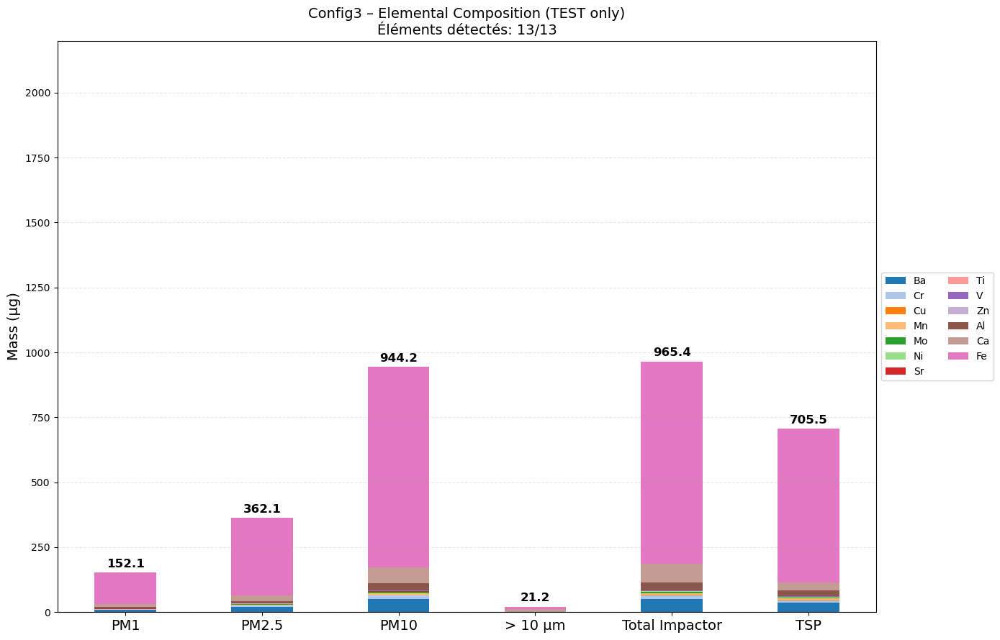


📈 Plot for Config4


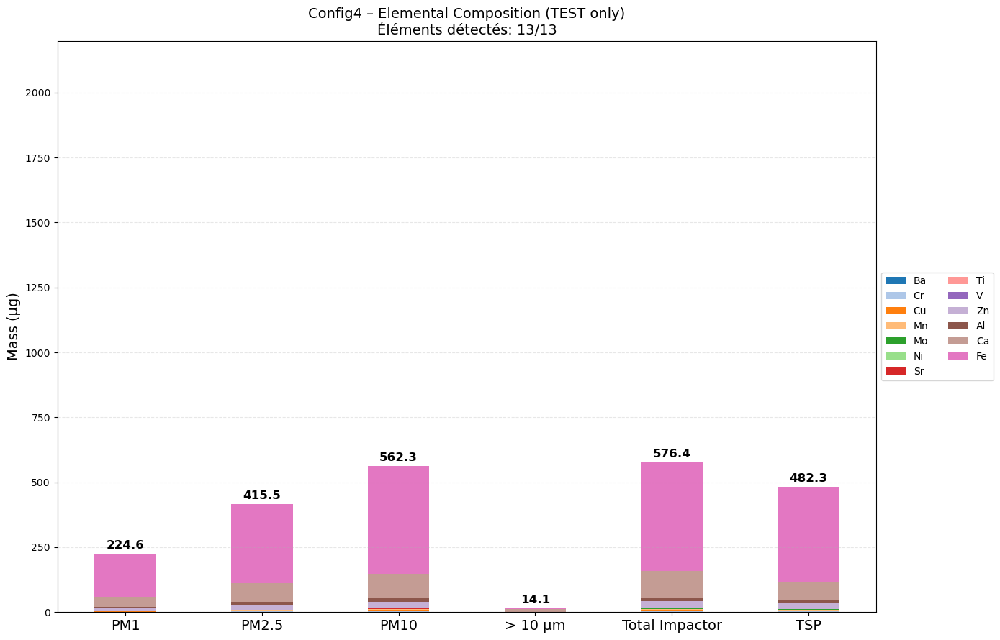


📈 Plot for Config5


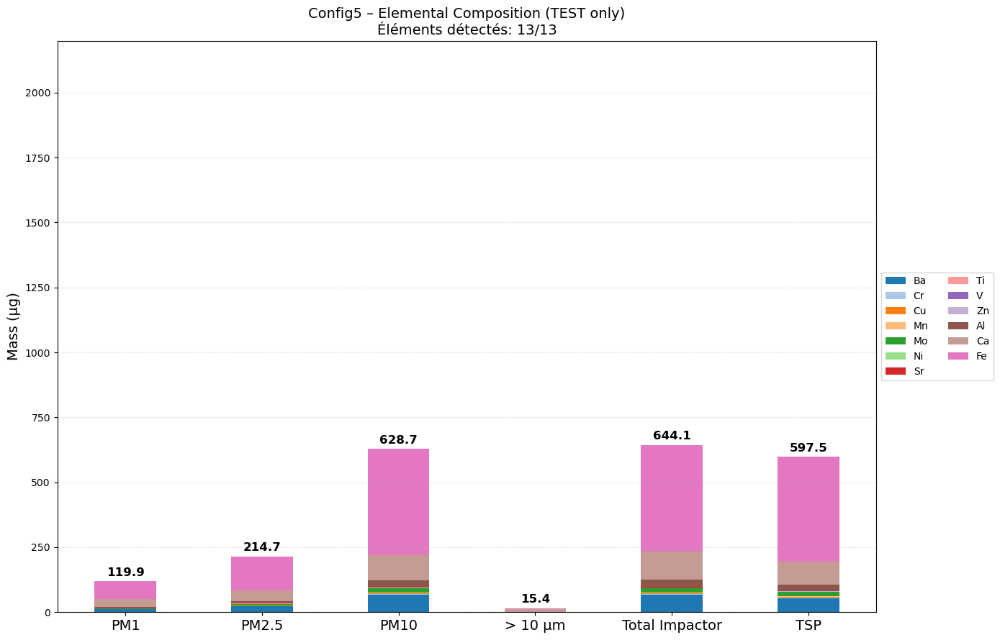


📈 Plot for Config6


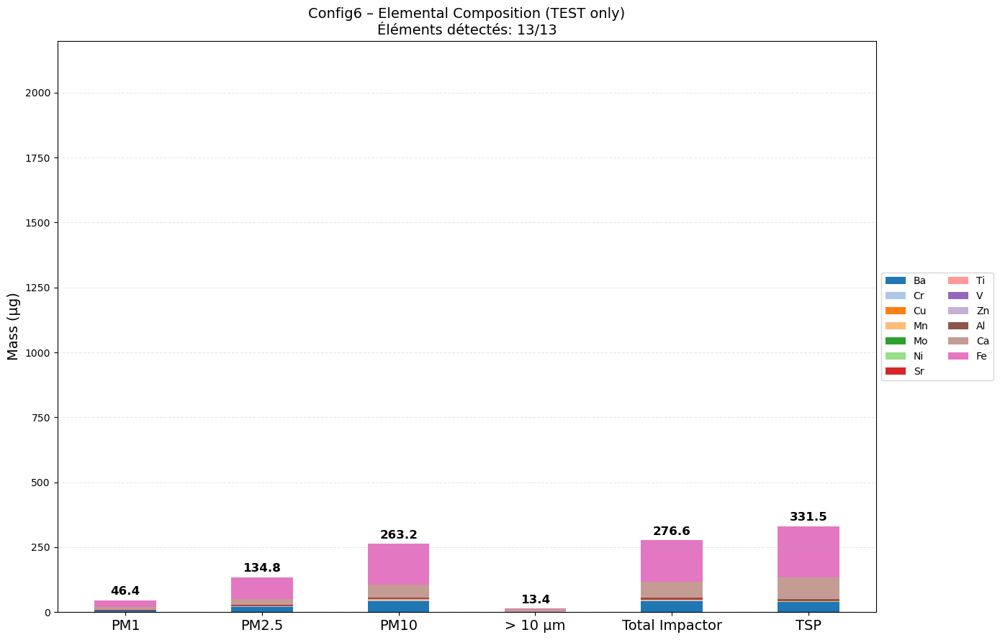


📈 Plot for Config7


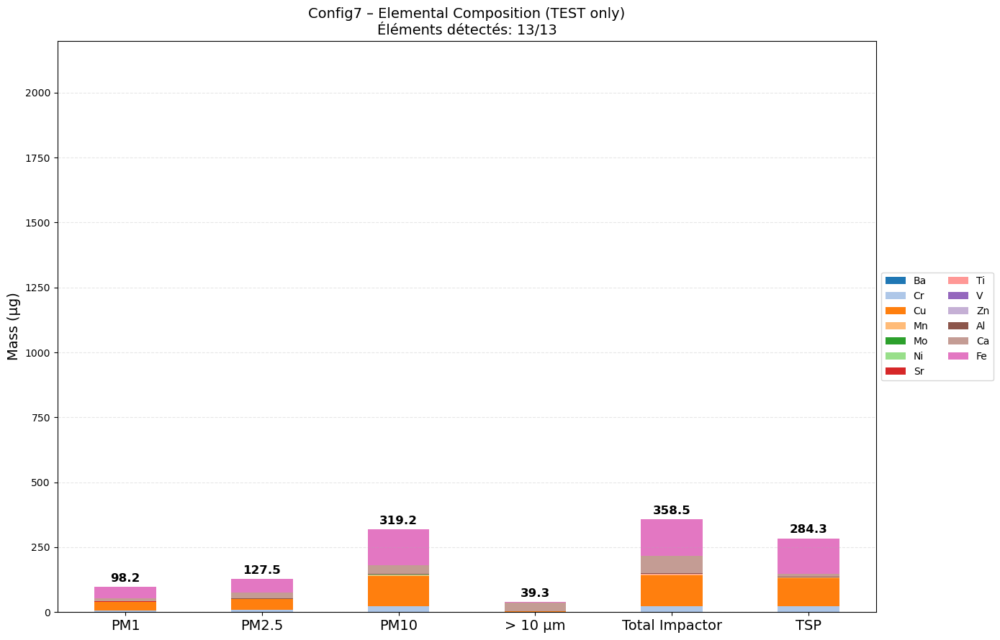


RÉSUMÉ FINAL
Nombre total de configurations: 5
Nombre total d'éléments uniques dans tous les top 10: 13

📊 LISTE GLOBALE DES ÉLÉMENTS (ordre alphabétique):
   1. Al
   2. Ba
   3. Ca
   4. Cr
   5. Cu
   6. Fe
   7. Mn
   8. Mo
   9. Ni
  10. Sr
  11. Ti
  12. V
  13. Zn

📈 TOP 10 PAR CONFIGURATION (basé uniquement sur les tests):

  🔧 Config3:
      1. Fe
      2. Ca
      3. Ba
      4. Al
      5. Cr
      6. Mn
      7. Mo
      8. V
      9. Cu
     10. Sr

  🔧 Config4:
      1. Fe
      2. Ca
      3. Zn
      4. Al
      5. Cr
      6. Mn
      7. Cu
      8. Ba
      9. Mo
     10. Ti

  🔧 Config5:
      1. Fe
      2. Ca
      3. Ba
      4. Al
      5. Mo
      6. Mn
      7. Cr
      8. Cu
      9. Sr
     10. Zn

  🔧 Config6:
      1. Fe
      2. Ca
      3. Ba
      4. Al
      5. Cu
      6. Mn
      7. Sr
      8. Cr
      9. Ti
     10. Ni

  🔧 Config7:
      1. Fe
      2. Cu
      3. Ca
      4. Cr
      5. Al
      6. Mn
      7. Ba
      8. Zn
      9. Ni
     10. 

In [26]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# 1) READ RAW FILE
fichier = r"C:\Users\Grira\OneDrive - Alstom\Documents\Paddle\Campagne2\Impacteur + FH\Masses and elemental composition_PTF2.xlsx"
df_raw = pd.read_excel(fichier, header=None)

# ============================================================
# 2) AUTO-DETECT HEADER ROW
# ============================================================
header_row = None
for i in range(50):
    row = df_raw.iloc[i].astype(str).str.lower()
    if "particle diameter" in row.tolist() and "filter name" in row.tolist():
        header_row = i
        break

df = pd.read_excel(fichier, header=header_row)
df.columns = df.columns.map(lambda x: str(x).strip())

# ============================================================
# 3) FILTER TYPE (Blank / Test)
# ============================================================
def detect_type(x):
    x = str(x).strip()
    if not x or x == 'nan':
        return None
    if x.startswith("B"):
        return "Blank"
    else:
        return "Test"

df["Type"] = df["Filter name"].apply(detect_type)
df = df[df["Type"].notna()]

# ============================================================
# 4) MACHINE NAME EXTRACTION
# ============================================================
df["Machine"] = df.iloc[:,0].astype(str).str.extract(
    r"(Config[0-9A-Za-z\-]*)", expand=False
).ffill()

# ============================================================
# 5) SIZE LABELS
# ============================================================
DIAM_PM1      = "< 1 µm"
DIAM_1_25     = "1-2.5 µm"
DIAM_2_10     = "2.5-10 µm"
DIAM_10_INF   = "> 10 µm"
DIAM_TSP      = "TSP"

core_sizes = [DIAM_PM1, DIAM_1_25, DIAM_2_10, DIAM_10_INF]

# Fixed order for display
size_order = ["PM1", "PM2.5", "PM10", DIAM_10_INF, "Total Impactor", "TSP"]

# ============================================================
# 6) ELEMENTAL COLUMNS (ng/filter → µg/filter)
# ============================================================
elem_cols = [c for c in df.columns if "(ng/filter)" in c]

df[elem_cols] = df[elem_cols].apply(pd.to_numeric, errors="coerce").fillna(0)
df[elem_cols] = df[elem_cols] / 1000  # ng → µg

elem_labels = {e: e.replace(" (ng/filter)", "") for e in elem_cols}

# ============================================================
# 7) MASS COLUMN (mg → µg) - GARDÉ POUR CALCUL MAIS PAS POUR AFFICHAGE
# ============================================================
col_mass = [c for c in df.columns if "mass" in c.lower()][0]
df[col_mass] = pd.to_numeric(df[col_mass], errors="coerce").fillna(0)
df[col_mass] = df[col_mass] * 1000  # mg → µg

# ============================================================
# 8) COMPUTE TOP‑10 ELEMENTS FOR TESTS ONLY
# ============================================================
print("\n" + "="*80)
print("   TOP 10 ÉLÉMENTS PAR CONFIGURATION (TESTS UNIQUEMENT)")
print("   Masse en µg")
print("="*80 + "\n")

configs = df["Machine"].unique()

# Dictionnaire pour stocker les top 10 tests
machine_top10_tests = {}

for config in configs:

    print(f"\n------ {config} ------")
    print("-" * 50)

    # Filtrer uniquement les TESTS
    df_config = df[(df["Machine"] == config) & (df["Type"] == "Test")]

    if df_config.empty:
        print(f"⚠ Pas de données Test pour {config}\n")
        continue

    total_mass = df_config[elem_cols].sum(axis=0)
    top10 = total_mass.sort_values(ascending=False).head(10)
    
    # Stocker dans un dictionnaire
    machine_top10_tests[config] = top10.index.tolist()

    # Nettoyer les noms pour l'affichage
    top10_clean = top10.copy()
    top10_clean.index = [elem_labels[c] for c in top10_clean.index]

    print(f"\n{'Rang':<6} {'Élément':<15} {'Masse totale (µg)':<20}")
    print("-" * 50)

    for rank, (elem, value) in enumerate(top10_clean.items(), 1):
        print(f"{rank:<6} {elem:<15} {value:<20.2f}")

    print("-" * 50)
    print(f"Total des 10 éléments: {top10.sum():.2f} µg")
    print(f"Total général (tous éléments tests): {total_mass.sum():.2f} µg")
    if total_mass.sum() > 0:
        print(f"Les 10 éléments représentent: {(top10.sum()/total_mass.sum()*100):.1f}% du total")
    print("\n")

# ============================================================
# 9) RÉSUMÉ FINAL DES TOP 10 PAR CONFIGURATION (TESTS)
# ============================================================
print("\n" + "="*80)
print("RÉSUMÉ FINAL - TOP 10 PAR CONFIGURATION (TESTS)")
print("="*80)

for config, top10 in machine_top10_tests.items():
    print(f"\n🔧 {config}")
    print("-" * 40)
    for i, elem in enumerate(top10, 1):
        elem_name = elem_labels[elem]
        print(f"  {i:2d}. {elem_name}")

# ============================================================
# 10) LISTE GLOBALE DES ÉLÉMENTS PRÉSENTS DANS LES TOP 10 TESTS
# ============================================================
global_elements_tests = set()
for top10_list in machine_top10_tests.values():
    global_elements_tests.update(top10_list)

global_elements_tests = sorted(list(global_elements_tests), key=lambda x: elem_labels[x])

print("\n" + "="*80)
print(f"LISTE GLOBALE DES ÉLÉMENTS DANS LES TOP 10 DES TESTS ({len(global_elements_tests)} éléments uniques)")
print("(Ces éléments seront affichés dans tous les graphiques avec la même légende)")
print("="*80)
for i, elem in enumerate(global_elements_tests, 1):
    print(f"  {i:2d}. {elem_labels[elem]}")

# ============================================================
# 11) MERGED PLOT PER MACHINE - SANS MASSE
# ============================================================
def get_elements(df_sub, diam):
    """Get element concentrations for a specific diameter"""
    row = df_sub[df_sub["Particle diameter"] == diam]
    if len(row) == 0:
        return pd.Series(0, index=elem_cols)
    return row[elem_cols].iloc[0]

# Garder TOUS les éléments de la liste globale
elem_cols_to_plot = [c for c in elem_cols if c in global_elements_tests]

# Palette fixe basée sur la liste globale (MÊME POUR TOUTES LES CONFIGS)
cmap = plt.get_cmap("tab20")
colors = {elem: cmap(i % 20) for i, elem in enumerate(elem_cols_to_plot)}

for machine, dgroup in df.groupby("Machine"):

    print(f"\n📈 Plot for {machine}")

    tests = dgroup[dgroup["Type"] == "Test"].copy()
    if tests.empty:
        print("⚠ No TEST data")
        continue

    tests["Particle diameter"] = tests["Particle diameter"].astype(str).str.strip()

    # ---------------------------------------------------
    # ELEMENTAL GROUPING (µg/filter) - SANS MASSE
    # ---------------------------------------------------
    elem_PM1  = get_elements(tests, DIAM_PM1)
    elem_1_25 = get_elements(tests, DIAM_1_25)
    elem_2_10 = get_elements(tests, DIAM_2_10)
    elem_10i  = get_elements(tests, DIAM_10_INF)
    elem_TSP  = get_elements(tests, DIAM_TSP)

    # Calculate cumulative fractions
    elem_PM2_5 = elem_PM1 + elem_1_25
    elem_PM10  = elem_PM1 + elem_1_25 + elem_2_10
    elem_TI    = elem_PM1 + elem_1_25 + elem_2_10 + elem_10i

    # Create DataFrame with all fractions
    ele = pd.DataFrame({
        "PM1": elem_PM1[elem_cols_to_plot],
        "PM2.5": elem_PM2_5[elem_cols_to_plot],
        "PM10": elem_PM10[elem_cols_to_plot],
        DIAM_10_INF: elem_10i[elem_cols_to_plot],
        "Total Impactor": elem_TI[elem_cols_to_plot],
        "TSP": elem_TSP[elem_cols_to_plot]
    }).T

    # Reorder to match size_order
    ele = ele.reindex(size_order).fillna(0)

    # ---------------------------------------------------
    # PLOT
    # ---------------------------------------------------
    plt.figure(figsize=(14,9))
    x = np.arange(len(size_order))
    width = 0.45

    bottom = np.zeros(len(size_order))

    # Tracer TOUS les éléments de la liste globale (même ceux à zéro)
    for elem in elem_cols_to_plot:
        vals = ele[elem].values
        plt.bar(x, vals, width, bottom=bottom,
                color=colors[elem], label=elem_labels[elem])
        bottom += vals

    # Element total labels
    for i, tot in enumerate(ele.sum(axis=1)):
        if tot > 0:
            plt.text(x[i], tot + 20, f"{tot:.1f}", ha='center', fontsize=12, fontweight='bold')

    # ✅ SUPPRESSION de la barre de masse (plus de PM mass overlay)

    # Ajustement dynamique de la limite Y basé uniquement sur les éléments
    plt.ylim(0, 2200)
    
    # Count detected elements
    elements_detected = sum(1 for elem in elem_cols_to_plot if tests[elem].sum() > 0)
    
    plt.title(f"{machine} – Elemental Composition (TEST only)\n"
              f"Éléments détectés: {elements_detected}/{len(elem_cols_to_plot)}", 
              fontsize=14)
    plt.xticks(x, size_order, fontsize=14)
    plt.ylabel("Mass (µg)", fontsize=14)
    plt.grid(axis='y', linestyle='--', alpha=0.3)
    
    # Légende IDENTIQUE pour toutes les configurations
    plt.legend(loc="center left", bbox_to_anchor=(1, 0.5), fontsize=10, 
               ncol=2 if len(elem_cols_to_plot) > 10 else 1)
    plt.tight_layout()
    plt.show()

# ============================================================
# 12) RÉSUMÉ FINAL
# ============================================================
print("\n" + "="*80)
print("RÉSUMÉ FINAL")
print("="*80)
print(f"Nombre total de configurations: {len(machine_top10_tests)}")
print(f"Nombre total d'éléments uniques dans tous les top 10: {len(global_elements_tests)}")
print("\n📊 LISTE GLOBALE DES ÉLÉMENTS (ordre alphabétique):")
for i, elem in enumerate(global_elements_tests, 1):
    print(f"  {i:2d}. {elem_labels[elem]}")
    
print("\n📈 TOP 10 PAR CONFIGURATION (basé uniquement sur les tests):")
for machine, top10 in machine_top10_tests.items():
    print(f"\n  🔧 {machine}:")
    for i, elem in enumerate(top10, 1):
        print(f"     {i:2d}. {elem_labels[elem]}")

print("\n" + "="*80)
print("DONE")
print("="*80)

Mass concentration

Plot: Config3


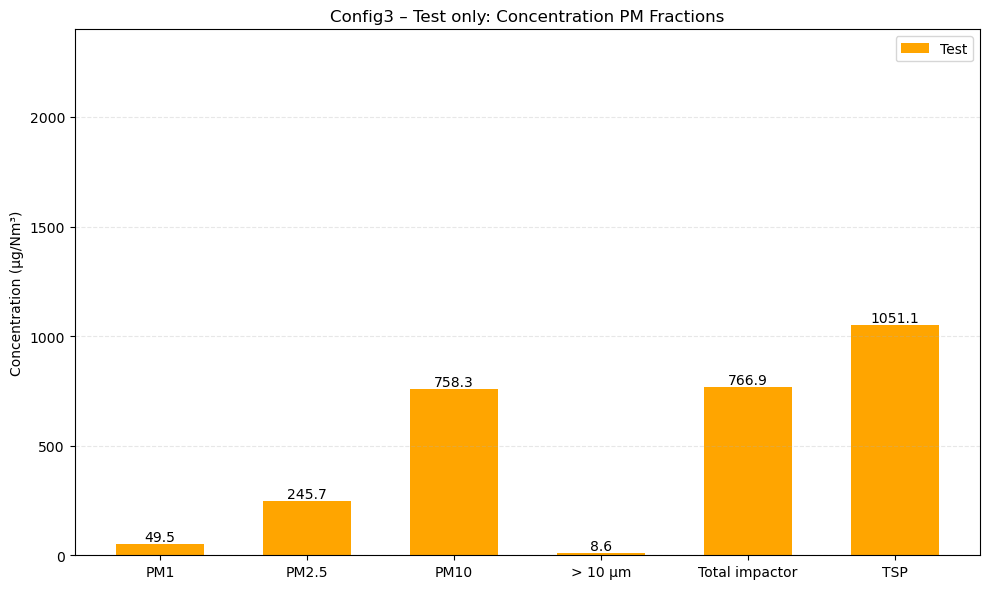

Plot: Config4


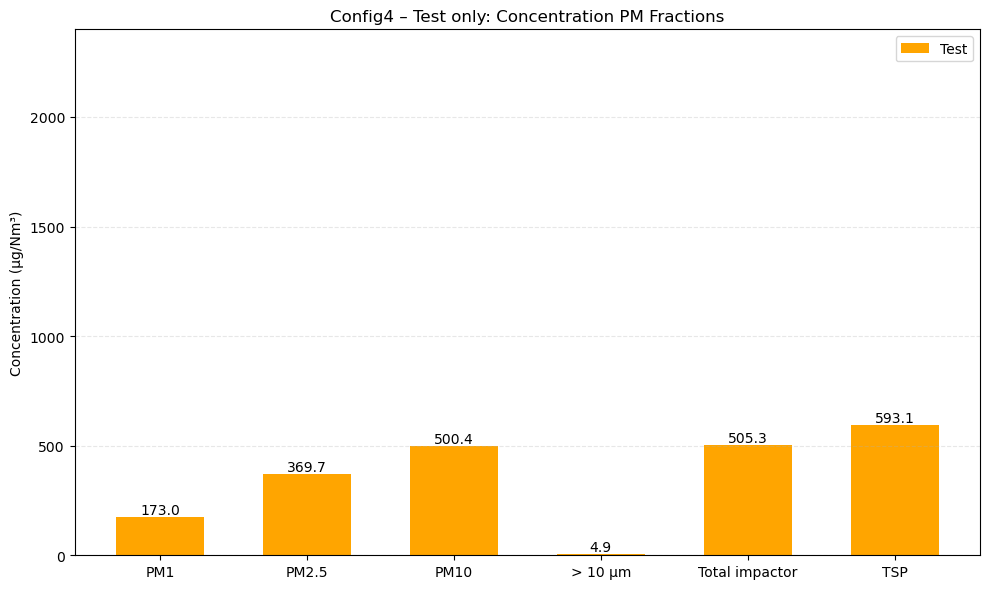

Plot: Config5


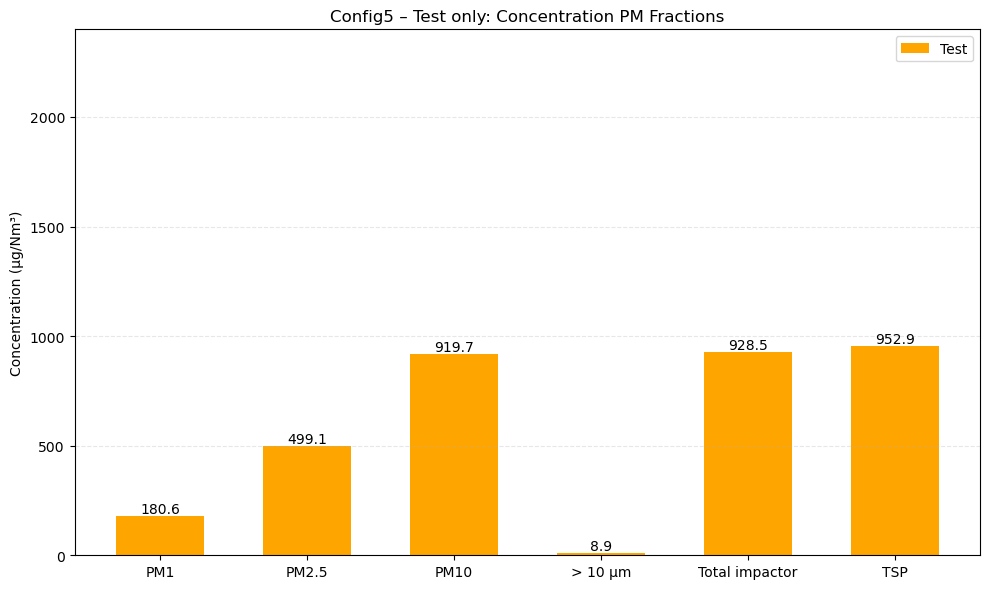

Plot: Config6


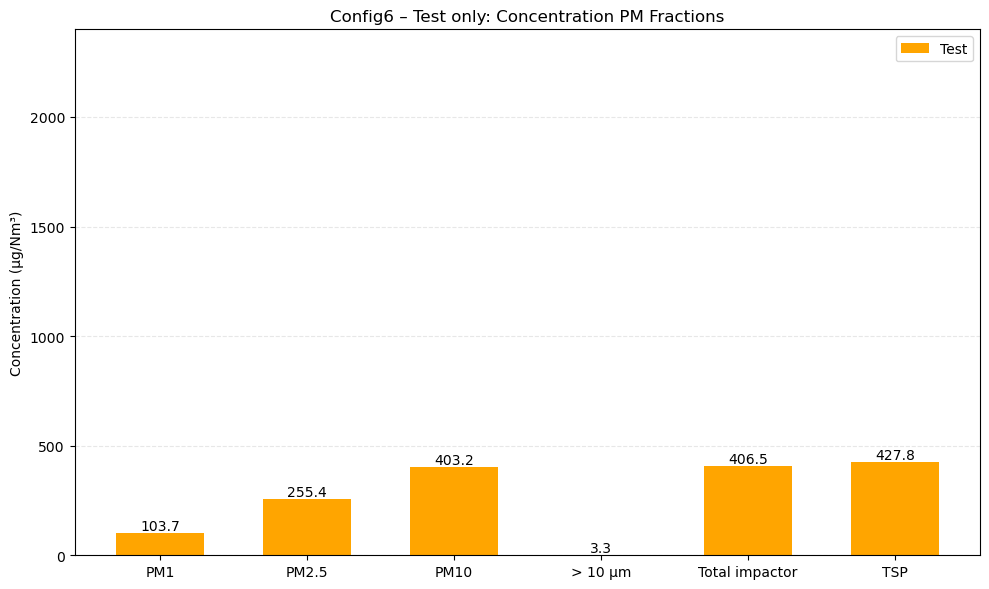

Plot: Config7


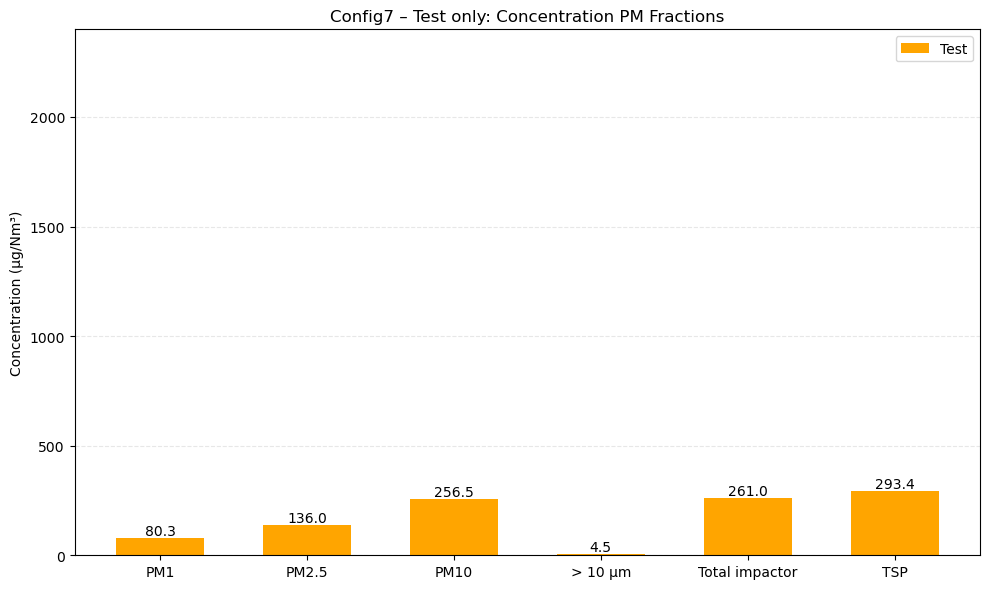

In [28]:
import numpy as np
import matplotlib.pyplot as plt

# ------------------------------------------
# DEFINE PARTICLE SIZE LABELS USED IN YOUR DF
# ------------------------------------------
DIAM_PM1      = "< 1 µm"
DIAM_1_25     = "1-2.5 µm"
DIAM_2_10     = "2.5-10 µm"
DIAM_10_INF   = "> 10 µm"
DIAM_TSP      = "TSP"

# ------------------------------------------
# USE CONCENTRATION COLUMN FROM EXCEL
# ------------------------------------------
col_conc = [c for c in df_clean.columns if "concentration" in c.lower()][0]

# ------------------------------------------
# LOOP OVER MACHINES
# ------------------------------------------
for machine, dgroup in df_clean.groupby("Machine"):

    print(f"Plot: {machine}")

    # ✅ KEEP ONLY TEST FILTERS
    tests = dgroup[dgroup["Type"] == "Test"]

    if tests.empty:
        print("⚠ No TEST data")
        continue

    # ✅ FUNCTION TO EXTRACT CONCENTRATION
    def get_conc(df_sub, diam):
        row = df_sub[df_sub[col_stage] == diam]
        if len(row) == 0:
            return None
        return float(row[col_conc].values[0])

    # --- READ RAW CONCENTRATIONS (TEST ONLY) ---
    t_PM1  = get_conc(tests, DIAM_PM1)
    t_1_25 = get_conc(tests, DIAM_1_25)
    t_2_10 = get_conc(tests, DIAM_2_10)
    t_10i  = get_conc(tests, DIAM_10_INF)
    t_TSP  = get_conc(tests, DIAM_TSP)

    # ------------------------------------------
    # COMPUTE PM FRACTIONS (TEST ONLY)
    # ------------------------------------------
    test_PM1  = t_PM1
    test_PM25 = sum(v for v in [t_PM1, t_1_25] if v is not None)
    test_PM10 = sum(v for v in [t_PM1, t_1_25, t_2_10] if v is not None)
    test_10i  = t_10i
    test_TI   = sum(v for v in [t_PM1, t_1_25, t_2_10, t_10i] if v is not None)
    test_TSP  = t_TSP

    # ------------------------------------------
    # PLOT — TEST ONLY ✅
    # ------------------------------------------
    categories = ["PM1", "PM2.5", "PM10", "> 10 µm", "Total impactor", "TSP"]
    test_vals  = [test_PM1, test_PM25, test_PM10, test_10i, test_TI, test_TSP]

    x = np.arange(len(categories))
    width = 0.6

    plt.figure(figsize=(10,6))

    bars_t = plt.bar(x, test_vals, width, label="Test", color="orange")

    # Add labels above bars
    for bar in bars_t:
        h = bar.get_height()
        if h is not None:
            plt.text(
                bar.get_x() + bar.get_width()/2,
                h,
                f"{h:.1f}",
                ha='center',
                va='bottom'
            )

    plt.ylim(0, 2400)
    plt.xticks(x, categories)
    plt.ylabel("Concentration (µg/Nm³)")
    plt.title(f"{machine} – Test only: Concentration PM Fractions")
    plt.grid(axis="y", linestyle="--", alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()

Elemental composition


Plot for Config3


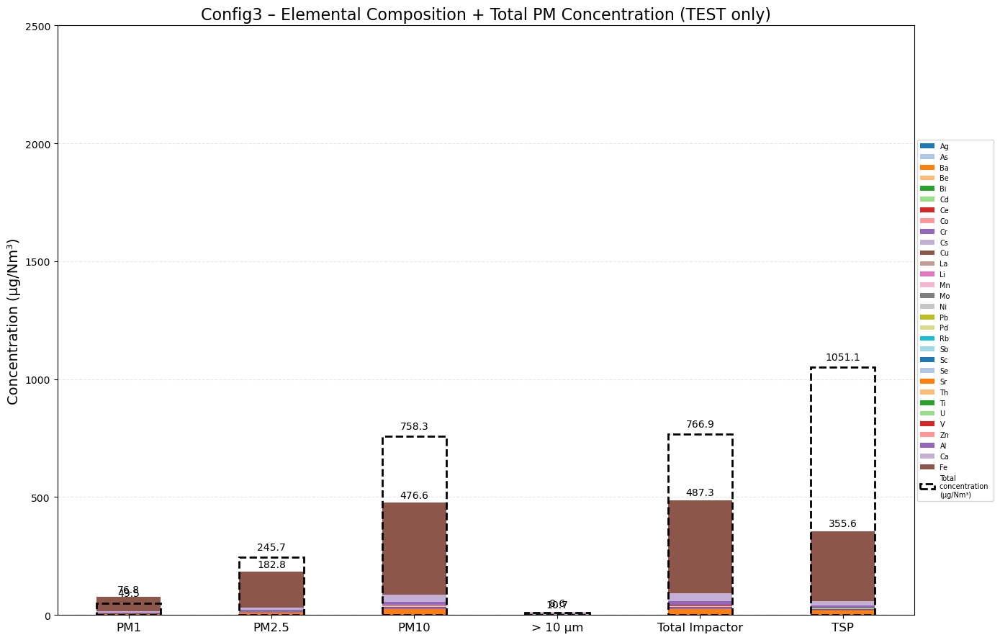


Plot for Config4


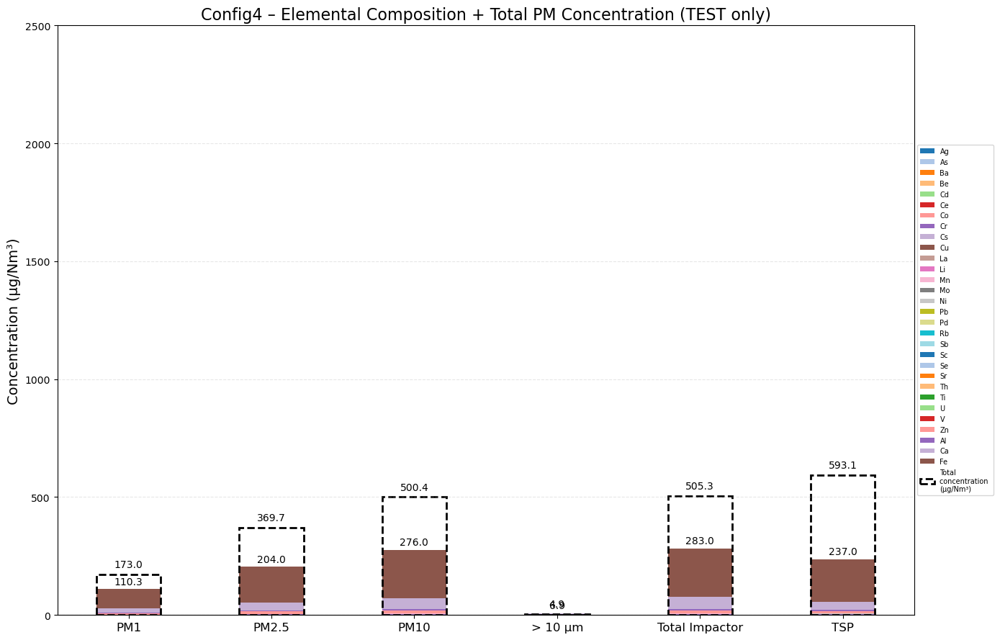


Plot for Config5


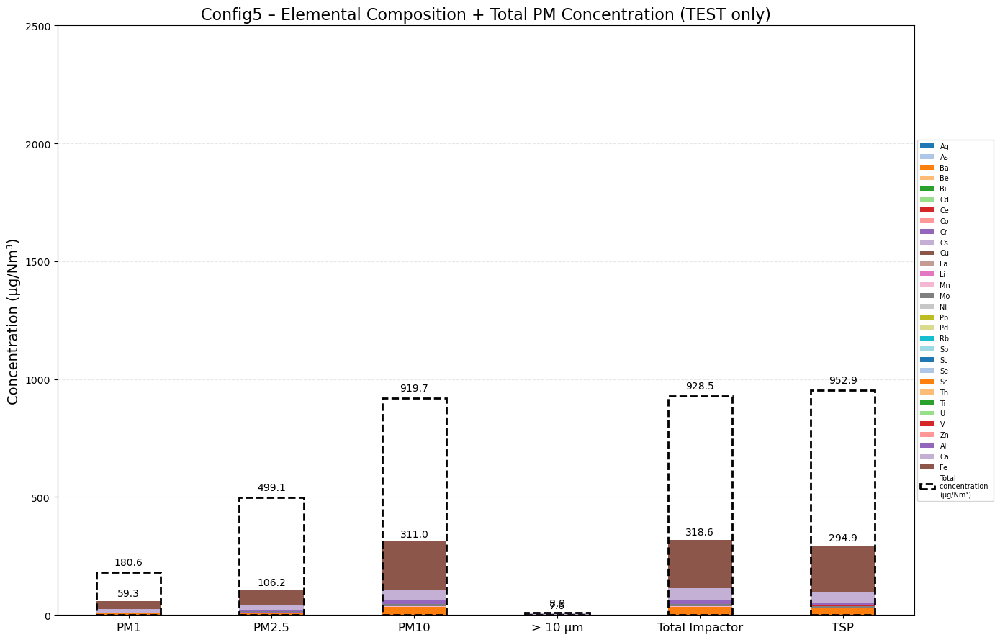


Plot for Config6


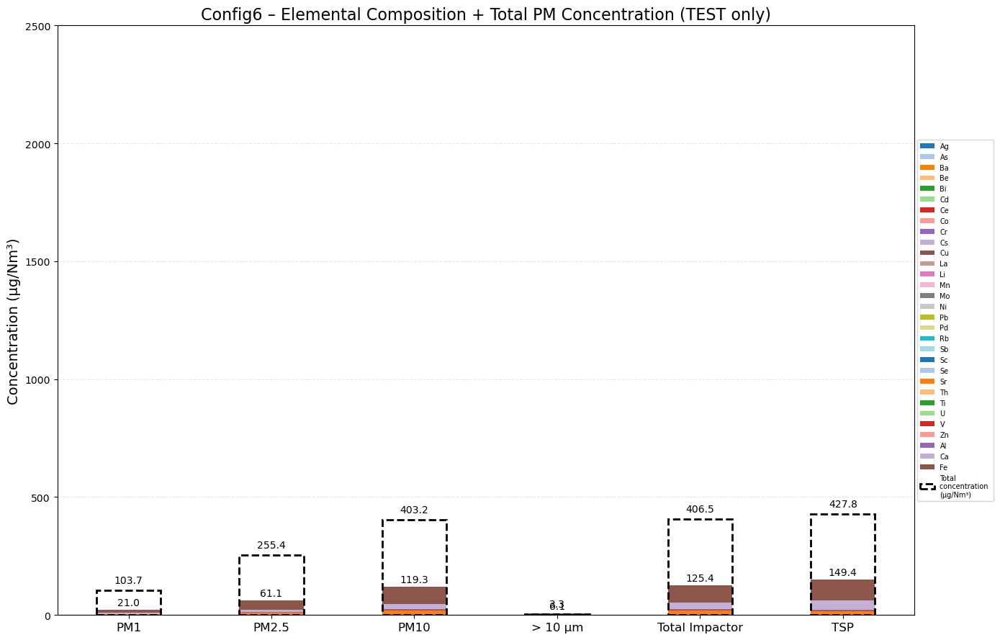


Plot for Config7


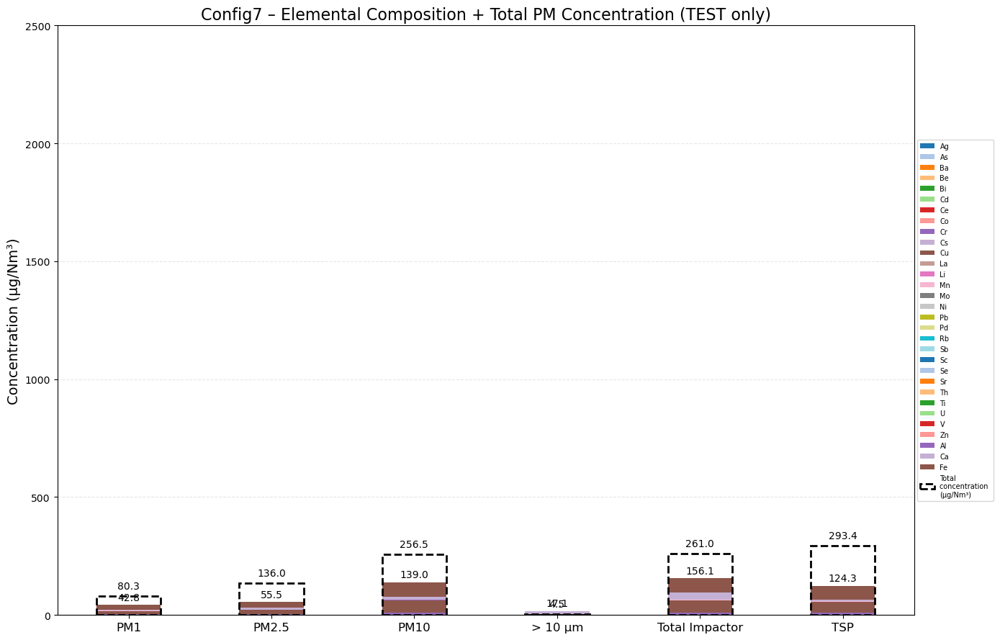


      TOP 10 ELEMENTS PER CONFIGURATION


------ Config3 ------

Fe    708.172527
Ca     57.958806
Ba     45.459066
Al     27.138149
Cr     13.120987
Mn      6.448773
Mo      4.944693
Cu      4.021711
Zn      2.188788
Ni      2.152603
dtype: float64



------ Config4 ------

Fe    394.313479
Ca     91.865934
Zn     23.941724
Al     11.233640
Cr      6.903786
Mn      3.106786
Cu      2.254339
Ba      1.496559
Ni      1.000487
Mo      0.886262
dtype: float64



------ Config5 ------

Fe    406.841473
Ca    103.184204
Ba     60.730691
Al     26.662116
Mo     16.414912
Mn      3.357526
Cr      3.170604
Cu      2.090714
Zn      1.320256
Sr      0.887195
dtype: float64



------ Config6 ------

Fe    169.024541
Ca     70.079284
Ba     37.634830
Al      7.964804
Cu      2.586348
Cr      1.737158
Mn      1.473039
Sr      0.987274
Ni      0.860781
Zn      0.697811
dtype: float64



------ Config7 ------

Fe    138.756539
Cu    107.543702
Ca     39.413129
Cr     21.138121
Al      3.860225
Mn   

In [29]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# 1) READ RAW FILE
fichier = r"C:\Users\Grira\OneDrive - Alstom\Documents\Paddle\Campagne2\Impacteur + FH\Masses and elemental composition_PTF2.xlsx"
df_raw = pd.read_excel(fichier, header=None)

# ============================================================
# 2) AUTO-DETECT HEADER ROW
# ============================================================
header_row = None
for i in range(50):
    row = df_raw.iloc[i].astype(str).str.lower()
    if "particle diameter" in row.tolist() and "filter name" in row.tolist():
        header_row = i
        break

df = pd.read_excel(fichier, header=header_row)
df.columns = df.columns.map(lambda x: str(x).strip())

# ============================================================
# 3) FILTER TYPE (Blank / Test)
# ============================================================
def detect_type(x):
    x = str(x).strip()
    if not x or x == 'nan':
        return None
    if x.startswith("B"):
        return "Blank"
    else:
        return "Test"

df["Type"] = df["Filter name"].apply(detect_type)
df = df[df["Type"].notna()]

# ============================================================
# 4) MACHINE NAME EXTRACTION
# ============================================================
df["Machine"] = df.iloc[:,0].astype(str).str.extract(
    r"(Config[0-9A-Za-z\-]*)", expand=False
).ffill()

# ============================================================
# 5) SIZE LABELS (ORIGINAL NAMES)
# ============================================================
DIAM_PM1    = "< 1 µm"
DIAM_1_25   = "1-2.5 µm"
DIAM_2_10   = "2.5-10 µm"
DIAM_10_INF = "> 10 µm"
DIAM_TSP    = "TSP"

core_sizes = [DIAM_PM1, DIAM_1_25, DIAM_2_10, DIAM_10_INF]

# CORRECTED ORDER WITH RENAMED LABELS
size_order = ["PM1", "PM2.5", "PM10", DIAM_10_INF, "Total Impactor", DIAM_TSP]

# ============================================================
# 6) ELEMENTAL CONCENTRATIONS (µg/Nm³)
# ============================================================
elem_cols = [c for c in df.columns if "(µg/Nm3 filter)" in c]
df[elem_cols] = df[elem_cols].apply(pd.to_numeric, errors="coerce").fillna(0)
elem_labels = {e: e.replace(" (µg/Nm3 filter)", "") for e in elem_cols}

# ============================================================
# 7) MASS CONCENTRATION COLUMN (µg/Nm³)
# ============================================================
col_mass_conc = [c for c in df.columns 
                 if "Concentration" in c and "(µg/Nm3)" in c][0]
df[col_mass_conc] = pd.to_numeric(df[col_mass_conc], errors="coerce").fillna(0)

# ============================================================
# 8) FUNCTION TO GET ELEMENTS PER FRACTION
# ============================================================
def get_elements(df_sub, diam):
    """Get element concentrations for a specific diameter"""
    row = df_sub[df_sub["Particle diameter"] == diam]
    if len(row) == 0:
        return pd.Series(0, index=elem_cols)
    return row[elem_cols].iloc[0]

def get_conc(df_sub, diam):
    row = df_sub[df_sub["Particle diameter"] == diam]
    if len(row) == 0:
        return None
    return float(row[col_mass_conc].values[0])

# ============================================================
# 9) MERGED PLOT PER MACHINE - CORRECTED CUMULATIVE ELEMENTS
# ============================================================
for machine, dgroup in df.groupby("Machine"):

    print(f"\nPlot for {machine}")

    tests = dgroup[dgroup["Type"] == "Test"].copy()
    if tests.empty:
        print("⚠ No TEST data")
        continue

    tests["Particle diameter"] = tests["Particle diameter"].astype(str).str.strip()

    # ---------------------------------------------------
    # COMPUTE PM FRACTIONS (µg/Nm³)
    # ---------------------------------------------------
    c_PM1  = get_conc(tests, DIAM_PM1)
    c_1_25 = get_conc(tests, DIAM_1_25)
    c_2_10 = get_conc(tests, DIAM_2_10)
    c_10i  = get_conc(tests, DIAM_10_INF)
    c_TSP  = get_conc(tests, DIAM_TSP)

    PM1_conc  = c_PM1
    PM25_conc = sum(v for v in [c_PM1, c_1_25] if v is not None)
    PM10_conc = sum(v for v in [c_PM1, c_1_25, c_2_10] if v is not None)
    TI_conc   = sum(v for v in [c_PM1, c_1_25, c_2_10, c_10i] if v is not None)

    pm_values = [PM1_conc, PM25_conc, PM10_conc, c_10i, TI_conc, c_TSP]

    # ---------------------------------------------------
    # ELEMENTAL GROUPING - CORRECTED CUMULATIVE CALCULATION
    # Get elements for each individual fraction
    # ---------------------------------------------------
    elem_PM1  = get_elements(tests, DIAM_PM1)
    elem_1_25 = get_elements(tests, DIAM_1_25)
    elem_2_10 = get_elements(tests, DIAM_2_10)
    elem_10i  = get_elements(tests, DIAM_10_INF)
    elem_TSP  = get_elements(tests, DIAM_TSP)
    
    # Calculate cumulative fractions (same logic as mass)
    elem_PM2_5 = elem_PM1 + elem_1_25                    # PM2.5 = PM1 + (1-2.5 µm)
    elem_PM10  = elem_PM1 + elem_1_25 + elem_2_10        # PM10 = PM1 + (1-2.5) + (2.5-10)
    elem_TI    = elem_PM1 + elem_1_25 + elem_2_10 + elem_10i  # Total Impactor = sum of all stages
    
    # Create DataFrame with all fractions
    ele = pd.DataFrame({
        "PM1": elem_PM1,
        "PM2.5": elem_PM2_5,
        "PM10": elem_PM10,
        DIAM_10_INF: elem_10i,
        "Total Impactor": elem_TI,
        DIAM_TSP: elem_TSP
    }).T
    
    # Reorder to match size_order
    ele = ele.reindex(size_order).fillna(0)

    # ---------------------------------------------------
    # PLOT
    # ---------------------------------------------------
    plt.figure(figsize=(14,9))
    x = np.arange(len(size_order))
    width = 0.45

    bottom = np.zeros(len(size_order))
    cmap = plt.get_cmap("tab20")
    color_map = {e: cmap(i % 20) for i, e in enumerate(elem_cols)}

    # STACKED ELEMENTS
    for elem in elem_cols:
        vals = ele[elem].values
        if vals.sum() == 0:
            continue
        plt.bar(x, vals, width, bottom=bottom, color=color_map[elem],
                label=elem_labels[elem])
        bottom += vals

    # TOTAL ELEMENT CONC LABELS
    totals = ele.sum(axis=1)
    for i, tot in enumerate(totals):
        if tot > 0:
            plt.text(x[i], tot + 20, f"{tot:.1f}", ha='center', fontsize=10)

    # OVERLAY TOTAL PM CONCENTRATION
    for i, val in enumerate(pm_values):
        if val is not None and val > 0:
            plt.bar(x[i], val, width, fill=False, edgecolor="black",
                    linestyle="--", linewidth=2,
                    label="Total \nconcentration \n(µg/Nm³)" if i == 0 else None)
            plt.text(x[i], val + 30, f"{val:.1f}", ha="center", fontsize=10)

    # Dynamic y-axis limit based on max value
    plt.ylim(0, 2500)
    plt.title(f"{machine} – Elemental Composition + Total PM Concentration (TEST only)", fontsize=16)
    plt.xticks(x, size_order, fontsize=12)
    plt.ylabel("Concentration (µg/Nm³)", fontsize=14)
    plt.grid(axis='y', linestyle='--', alpha=0.3)
    plt.legend(loc="center left", bbox_to_anchor=(1,0.5), fontsize=7)
    plt.tight_layout()
    plt.show()

# ============================================================
# 10) TOP‑10 ELEMENTS PER CONFIGURATION (µg/Nm³)
# ============================================================

print("\n==============================================")
print("      TOP 10 ELEMENTS PER CONFIGURATION")
print("==============================================\n")

for config in df["Machine"].unique():

    print(f"\n------ {config} ------\n")

    df_config = df[df["Machine"] == config]

    total_conc = df_config[elem_cols].sum(axis=0)

    top10 = total_conc.sort_values(ascending=False).head(10)
    top10.index = [elem_labels[c] for c in top10.index]

    print(top10)
    print("\n")

print("==============================================")
print("DONE")
print("==============================================")

Elemental composition (top 10)


   TOP 10 ÉLÉMENTS PAR CONFIGURATION (TESTS UNIQUEMENT)
   Concentration en µg/Nm³


------ Config3 ------
--------------------------------------------------

Rang   Élément         Concentration totale (µg/Nm³)
--------------------------------------------------
1      Fe              691.51                   
2      Ca              51.68                    
3      Ba              44.66                    
4      Al              25.99                    
5      Cr              11.13                    
6      Mn              6.19                     
7      Mo              4.64                     
8      V               1.88                     
9      Cu              1.79                     
10     Sr              1.20                     
--------------------------------------------------
Total des 10 éléments: 840.66 µg/Nm³
Total général (tous éléments tests): 842.87 µg/Nm³
Les 10 éléments représentent: 99.7% du total



------ Config4 ------
-------------------------------------

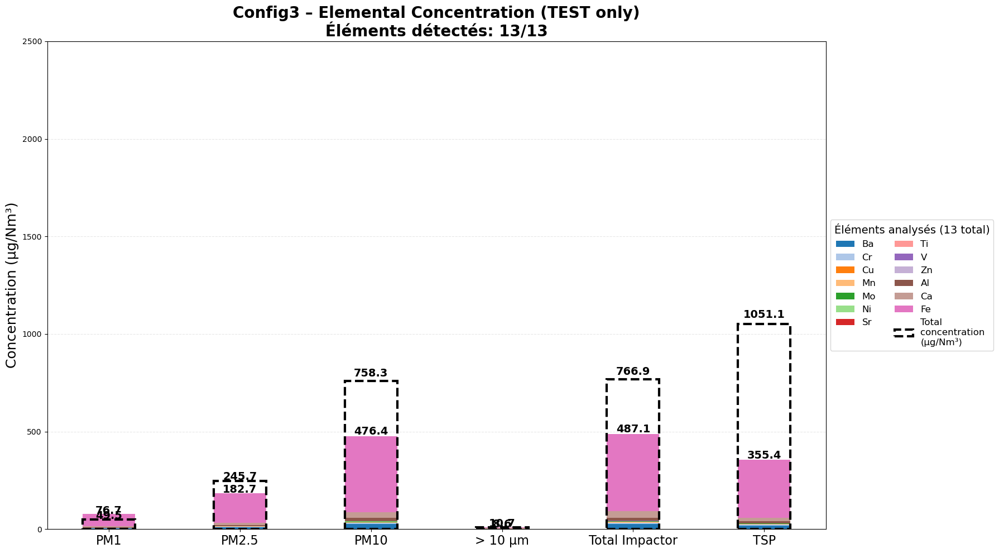


📈 Plotting TEST only: Config4


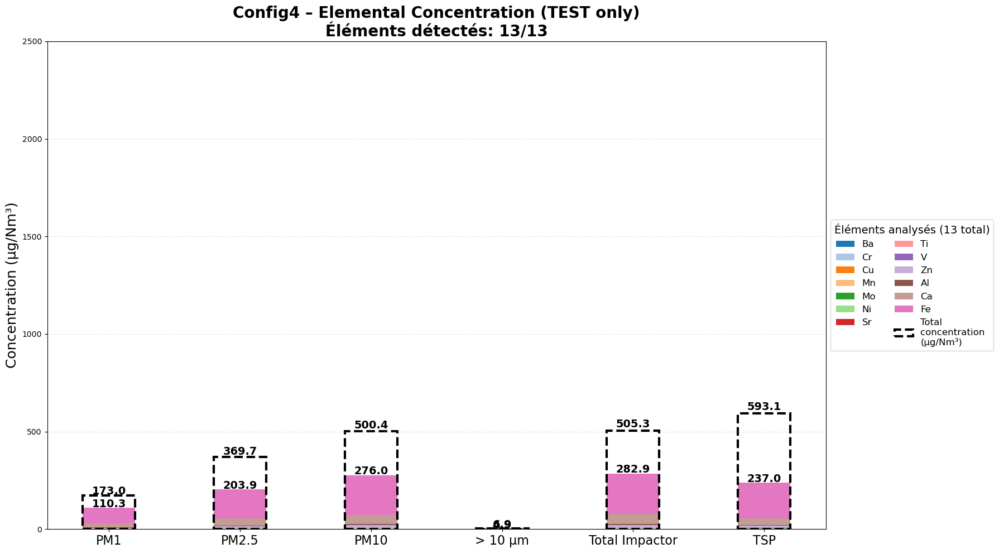


📈 Plotting TEST only: Config5


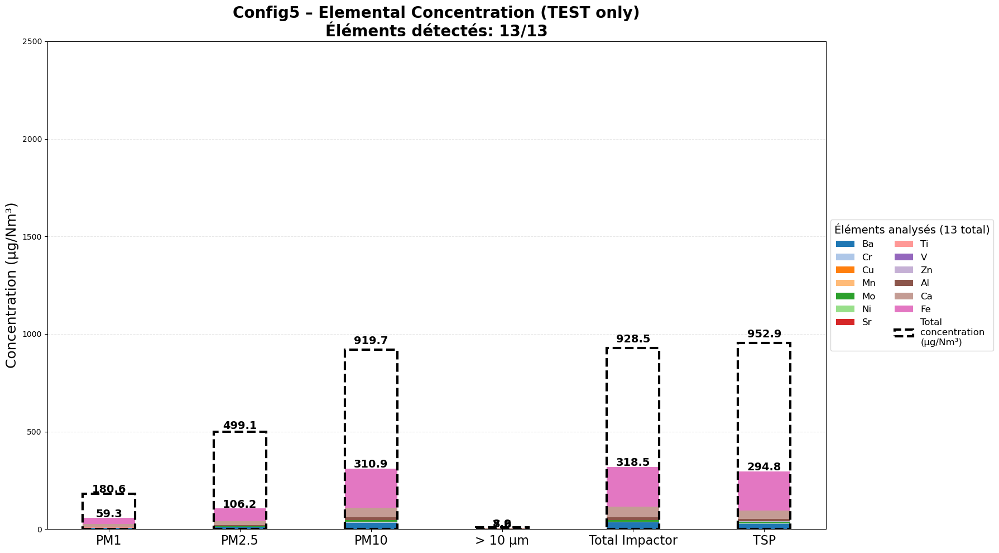


📈 Plotting TEST only: Config6


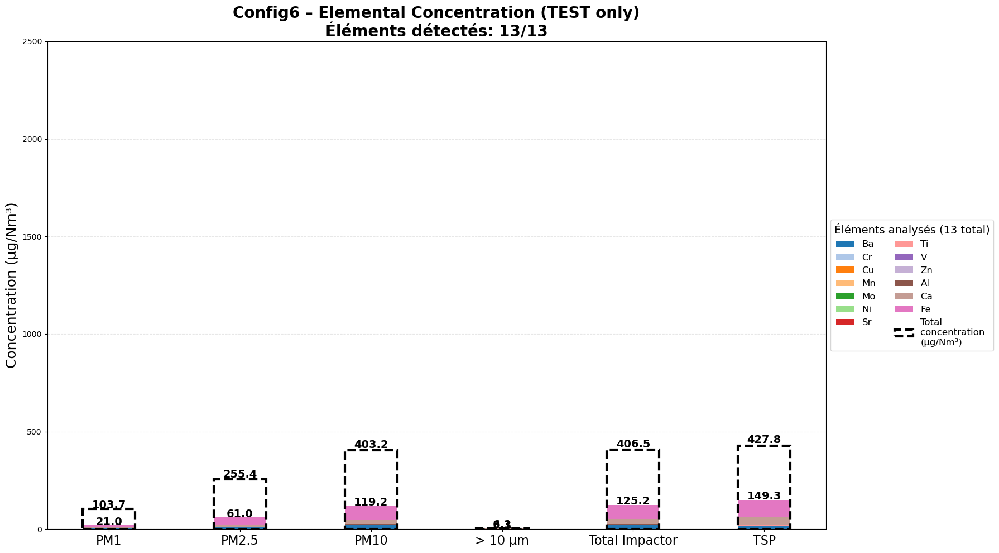


📈 Plotting TEST only: Config7


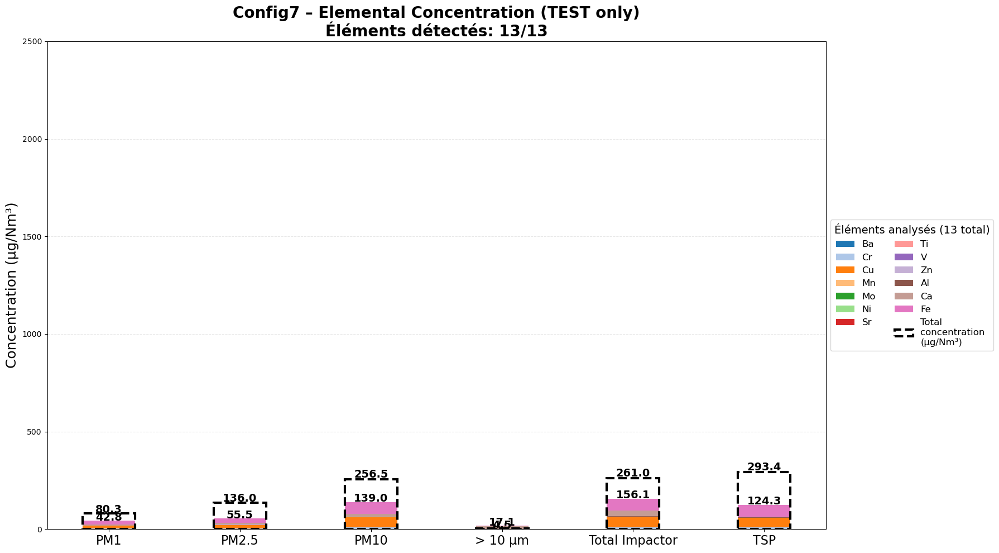


RÉSUMÉ FINAL
Nombre total de configurations: 5
Nombre total d'éléments uniques dans tous les top 10: 13

📊 LISTE GLOBALE DES ÉLÉMENTS (ordre alphabétique):
   1. Al
   2. Ba
   3. Ca
   4. Cr
   5. Cu
   6. Fe
   7. Mn
   8. Mo
   9. Ni
  10. Sr
  11. Ti
  12. V
  13. Zn

📈 TOP 10 PAR CONFIGURATION (basé uniquement sur les tests):

  🔧 Config3:
      1. Fe
      2. Ca
      3. Ba
      4. Al
      5. Cr
      6. Mn
      7. Mo
      8. V
      9. Cu
     10. Sr

  🔧 Config4:
      1. Fe
      2. Ca
      3. Zn
      4. Al
      5. Cr
      6. Mn
      7. Cu
      8. Ba
      9. Mo
     10. Ti

  🔧 Config5:
      1. Fe
      2. Ca
      3. Ba
      4. Al
      5. Mo
      6. Mn
      7. Cr
      8. Cu
      9. Sr
     10. Zn

  🔧 Config6:
      1. Fe
      2. Ca
      3. Ba
      4. Al
      5. Cu
      6. Mn
      7. Sr
      8. Cr
      9. Ti
     10. Ni

  🔧 Config7:
      1. Fe
      2. Cu
      3. Ca
      4. Cr
      5. Al
      6. Mn
      7. Ba
      8. Zn
      9. Ni
     10. 

In [31]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# 1) READ RAW FILE
fichier = r"C:\Users\Grira\OneDrive - Alstom\Documents\Paddle\Campagne2\Impacteur + FH\Masses and elemental composition_PTF2.xlsx"
df_raw = pd.read_excel(fichier, header=None)

# ============================================================
# 2) AUTO-DETECT HEADER ROW
# ============================================================
header_row = None
for i in range(50):
    row = df_raw.iloc[i].astype(str).str.lower()
    if "particle diameter" in row.tolist() and "filter name" in row.tolist():
        header_row = i
        break

df = pd.read_excel(fichier, header=header_row)
df.columns = df.columns.map(str)

# ============================================================
# 3) FILTER TYPE (Blank / Test)
# ============================================================
def detect_type(x):
    x = str(x).strip()
    if not x or x == 'nan':
        return None
    if x.startswith("B"):
        return "Blank"
    else:
        return "Test"

df["Type"] = df["Filter name"].apply(detect_type)
df = df[df["Type"].notna()]

# ============================================================
# 4) MACHINE NAME
# ============================================================
df["Machine"] = df.iloc[:,0].astype(str).str.extract(
    r"(Config[0-9A-Za-z\-]*)", expand=False
).ffill()

# ============================================================
# 5) ELEMENT COLUMNS (µg/Nm³)
# ============================================================
elem_cols = [c for c in df.columns if "(µg/Nm3 filter)" in c]
df[elem_cols] = df[elem_cols].apply(pd.to_numeric, errors="coerce").fillna(0)
elem_labels = {c: c.replace(" (µg/Nm3 filter)", "") for c in elem_cols}

# ============================================================
# 6) TOTAL MASS CONCENTRATION (µg/Nm³)
# ============================================================
col_mass_conc = [c for c in df.columns 
                 if "Concentration" in c and "(µg/Nm3)" in c][0]
df[col_mass_conc] = pd.to_numeric(df[col_mass_conc], errors="coerce").fillna(0)

# ============================================================
# 7) COMPUTE TOP‑10 ELEMENTS FOR TESTS ONLY (per configuration)
# ============================================================
print("\n" + "="*80)
print("   TOP 10 ÉLÉMENTS PAR CONFIGURATION (TESTS UNIQUEMENT)")
print("   Concentration en µg/Nm³")
print("="*80 + "\n")

configs = df["Machine"].unique()

# Dictionnaire pour stocker les top 10 tests
machine_top10_tests = {}

for config in configs:

    print(f"\n------ {config} ------")
    print("-" * 50)

    # Filtrer uniquement les TESTS
    df_config = df[(df["Machine"] == config) & (df["Type"] == "Test")]

    if df_config.empty:
        print(f"⚠ Pas de données Test pour {config}\n")
        continue

    total_conc = df_config[elem_cols].sum(axis=0)
    top10 = total_conc.sort_values(ascending=False).head(10)
    
    # Stocker dans un dictionnaire
    machine_top10_tests[config] = top10.index.tolist()

    # Nettoyer les noms pour l'affichage
    top10_clean = top10.copy()
    top10_clean.index = [elem_labels[c] for c in top10_clean.index]

    print(f"\n{'Rang':<6} {'Élément':<15} {'Concentration totale (µg/Nm³)':<25}")
    print("-" * 50)

    for rank, (elem, value) in enumerate(top10_clean.items(), 1):
        print(f"{rank:<6} {elem:<15} {value:<25.2f}")

    print("-" * 50)
    print(f"Total des 10 éléments: {top10.sum():.2f} µg/Nm³")
    print(f"Total général (tous éléments tests): {total_conc.sum():.2f} µg/Nm³")
    if total_conc.sum() > 0:
        print(f"Les 10 éléments représentent: {(top10.sum()/total_conc.sum()*100):.1f}% du total")
    print("\n")

# ============================================================
# 8) RÉSUMÉ FINAL DES TOP 10 PAR CONFIGURATION (TESTS)
# ============================================================
print("\n" + "="*80)
print("RÉSUMÉ FINAL - TOP 10 PAR CONFIGURATION (TESTS)")
print("="*80)

for config, top10 in machine_top10_tests.items():
    print(f"\n🔧 {config}")
    print("-" * 40)
    for i, elem in enumerate(top10, 1):
        elem_name = elem_labels[elem]
        print(f"  {i:2d}. {elem_name}")

# ============================================================
# 9) LISTE GLOBALE DES ÉLÉMENTS PRÉSENTS DANS LES TOP 10 TESTS
# ============================================================
global_elements_tests = set()
for top10_list in machine_top10_tests.values():
    global_elements_tests.update(top10_list)

global_elements_tests = sorted(list(global_elements_tests), key=lambda x: elem_labels[x])

print("\n" + "="*80)
print(f"LISTE GLOBALE DES ÉLÉMENTS DANS LES TOP 10 DES TESTS ({len(global_elements_tests)} éléments uniques)")
print("(Ces éléments seront affichés dans tous les graphiques avec la même légende)")
print("="*80)
for i, elem in enumerate(global_elements_tests, 1):
    print(f"  {i:2d}. {elem_labels[elem]}")

# ============================================================
# 10) SIZE ORDER
# ============================================================
size_order = [
    "PM1",
    "PM2.5",
    "PM10",
    "> 10 µm",
    "Total Impactor",
    "TSP"
]

# ============================================================
# 11) PLOTTING LOOP (TEST ONLY) - AVEC LISTE GLOBALE
# ============================================================
# Garder TOUS les éléments de la liste globale
elem_cols_to_plot = [c for c in elem_cols if c in global_elements_tests]

# Palette fixe basée sur la liste globale (MÊME POUR TOUTES LES CONFIGS)
cmap = plt.get_cmap("tab20")
colors = {elem: cmap(i % 20) for i, elem in enumerate(elem_cols_to_plot)}

for machine, dgroup in df.groupby("Machine"):

    print(f"\n📈 Plotting TEST only: {machine}")

    tests = dgroup[dgroup["Type"] == "Test"].copy()
    if tests.empty:
        print("⚠ No test data")
        continue

    tests["Particle diameter"] = tests["Particle diameter"].astype(str).str.strip()

    # Create a mapping for raw data
    tests["diameter_key"] = tests["Particle diameter"].map({
        "< 1 µm": "PM1_raw",
        "1-2.5 µm": "PM2.5_raw",
        "2.5-10 µm": "PM10_raw",
        "> 10 µm": "> 10 µm",
        "TSP": "TSP"
    })

    # ============================================================
    # 11A — CUMULATIVE ELEMENTAL CONCENTRATIONS (avec éléments globaux)
    # ============================================================
    # Create a dictionary to store raw values for each fraction
    raw_elements = {}
    for fraction in ["PM1_raw", "PM2.5_raw", "PM10_raw", "> 10 µm", "TSP"]:
        subset = tests[tests["diameter_key"] == fraction]
        if not subset.empty:
            raw_elements[fraction] = subset[elem_cols_to_plot].iloc[0]
        else:
            raw_elements[fraction] = pd.Series(0, index=elem_cols_to_plot)

    # Create grouped DataFrame with cumulative calculations
    # grouped = pd.DataFrame(index=size_order, columns=elem_cols_to_plot).fillna(0)

    grouped = pd.DataFrame(
    0.0,
    index=size_order,
    columns=elem_cols_to_plot
    )

    # PM1 = <1 µm
    grouped.loc["PM1"] = raw_elements["PM1_raw"]

    # PM2.5 = PM1 + 1–2.5 µm
    grouped.loc["PM2.5"] = raw_elements["PM1_raw"] + raw_elements["PM2.5_raw"]

    # PM10 = PM2.5 + 2.5–10 µm
    grouped.loc["PM10"] = grouped.loc["PM2.5"] + raw_elements["PM10_raw"]

    # >10 µm unchanged
    grouped.loc["> 10 µm"] = raw_elements["> 10 µm"]

    # TOTAL IMPACTOR = (<1 + 1–2.5 + 2.5–10 + >10 µm)
    grouped.loc["Total Impactor"] = (
        raw_elements["PM1_raw"] +
        raw_elements["PM2.5_raw"] +
        raw_elements["PM10_raw"] +
        raw_elements["> 10 µm"]
    )

    # TSP untouched
    grouped.loc["TSP"] = raw_elements["TSP"]

    # ============================================================
    # 11B — CUMULATIVE MASS CONCENTRATION
    # ============================================================
    # Create a dictionary to store raw mass values for each fraction
    raw_mass = {}
    for fraction in ["PM1_raw", "PM2.5_raw", "PM10_raw", "> 10 µm", "TSP"]:
        subset = tests[tests["diameter_key"] == fraction]
        if not subset.empty:
            raw_mass[fraction] = subset[col_mass_conc].iloc[0]
        else:
            raw_mass[fraction] = 0

    mass_group = pd.Series(index=size_order, dtype=float)

    mass_group["PM1"] = raw_mass["PM1_raw"]
    mass_group["PM2.5"] = raw_mass["PM1_raw"] + raw_mass["PM2.5_raw"]
    mass_group["PM10"] = mass_group["PM2.5"] + raw_mass["PM10_raw"]
    mass_group["> 10 µm"] = raw_mass["> 10 µm"]
    mass_group["Total Impactor"] = (
        raw_mass["PM1_raw"] +
        raw_mass["PM2.5_raw"] +
        raw_mass["PM10_raw"] +
        raw_mass["> 10 µm"]
    )
    mass_group["TSP"] = raw_mass["TSP"]

    # ============================================================
    # 11C — PLOT FIGURE
    # ============================================================
    plt.figure(figsize=(18,10))
    width = 0.40
    x = np.arange(len(size_order))

    bottom = np.zeros(len(size_order))

    # Tracer TOUS les éléments de la liste globale
    for elem in elem_cols_to_plot:
        vals = grouped[elem].values.astype(float)
        plt.bar(x, vals, width, bottom=bottom,
                color=colors[elem], label=elem_labels[elem])
        bottom += vals

    # Element total labels
    totals = grouped.sum(axis=1).values
    for i, total in enumerate(totals):
        if total > 0:
            plt.text(x[i], total * 1.02, f"{total:.1f}",
                     ha="center", fontsize=14, fontweight="bold")

    # Mass concentration bars
    for i, val in enumerate(mass_group.values):
        if val > 0:
            plt.bar(
                x[i], val, width,
                fill=False, edgecolor="black",
                linestyle="--", linewidth=3,
                label="Total \nconcentration \n(µg/Nm³)" if i == 0 else None
            )
            plt.text(x[i], val * 1.03, f"{val:.1f}",
                     ha="center", fontsize=14, fontweight="bold")

    # Dynamic y-axis limit
    plt.ylim(0, 2500)
    
    # Count detected elements
    elements_detected = sum(1 for elem in elem_cols_to_plot if tests[elem].sum() > 0)
    
    plt.xticks(x, size_order, fontsize=16)
    plt.ylabel("Concentration (µg/Nm³)", fontsize=18)
    plt.title(f"{machine} – Elemental Concentration (TEST only)\n"
              f"Éléments détectés: {elements_detected}/{len(elem_cols_to_plot)}",
              fontsize=20, fontweight="bold")

    plt.grid(axis='y', linestyle='--', alpha=0.3)
    
    # Légende IDENTIQUE pour toutes les configurations
    plt.legend(loc="center left", bbox_to_anchor=(1, 0.5),
               fontsize=12, title=f"Éléments analysés ({len(elem_cols_to_plot)} total)", 
               title_fontsize=14, ncol=2 if len(elem_cols_to_plot) > 10 else 1)

    plt.tight_layout()
    plt.show()

# ============================================================
# 12) RÉSUMÉ FINAL
# ============================================================
print("\n" + "="*80)
print("RÉSUMÉ FINAL")
print("="*80)
print(f"Nombre total de configurations: {len(machine_top10_tests)}")
print(f"Nombre total d'éléments uniques dans tous les top 10: {len(global_elements_tests)}")
print("\n📊 LISTE GLOBALE DES ÉLÉMENTS (ordre alphabétique):")
for i, elem in enumerate(global_elements_tests, 1):
    print(f"  {i:2d}. {elem_labels[elem]}")
    
print("\n📈 TOP 10 PAR CONFIGURATION (basé uniquement sur les tests):")
for machine, top10 in machine_top10_tests.items():
    print(f"\n  🔧 {machine}:")
    for i, elem in enumerate(top10, 1):
        print(f"     {i:2d}. {elem_labels[elem]}")

print("\n" + "="*80)
print("DONE")
print("="*80)


   TOP 10 ÉLÉMENTS PAR CONFIGURATION (TESTS UNIQUEMENT)
   Concentration en µg/Nm³


------ Config3 ------
--------------------------------------------------

Rang   Élément         Concentration totale (µg/Nm³)
--------------------------------------------------
1      Fe              691.51                   
2      Ca              51.68                    
3      Ba              44.66                    
4      Al              25.99                    
5      Cr              11.13                    
6      Mn              6.19                     
7      Mo              4.64                     
8      V               1.88                     
9      Cu              1.79                     
10     Sr              1.20                     
--------------------------------------------------
Total des 10 éléments: 840.66 µg/Nm³
Total général (tous éléments tests): 842.87 µg/Nm³
Les 10 éléments représentent: 99.7% du total



------ Config4 ------
-------------------------------------

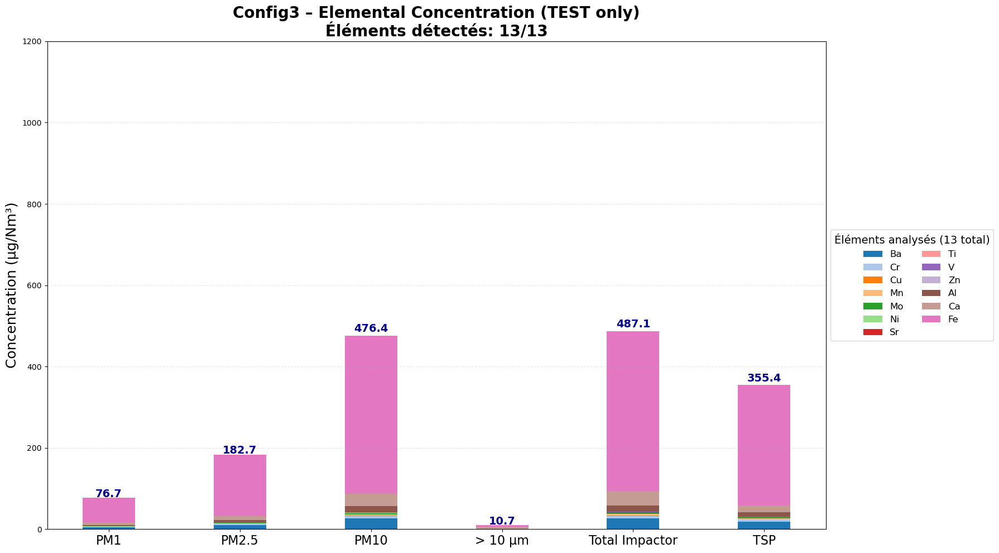


📈 Plotting TEST only: Config4


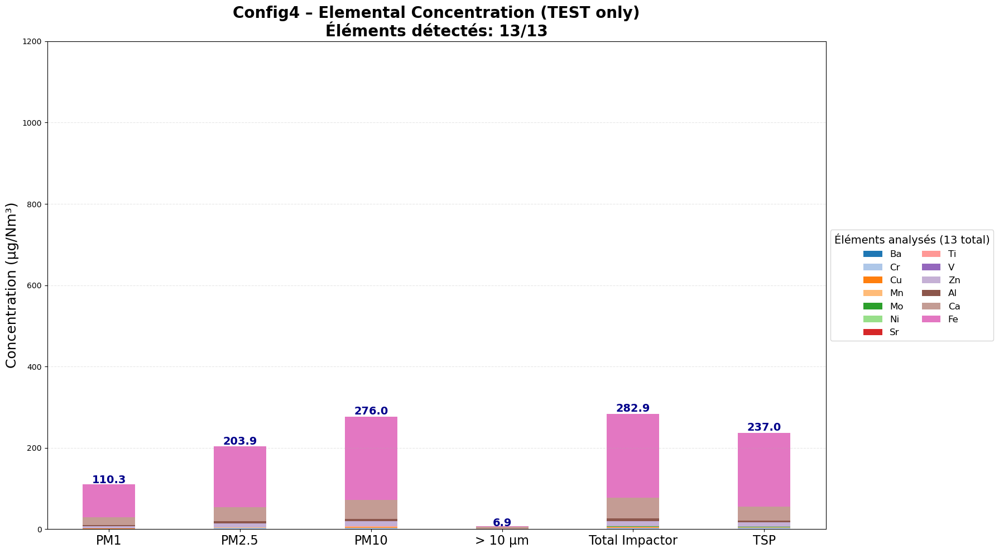


📈 Plotting TEST only: Config5


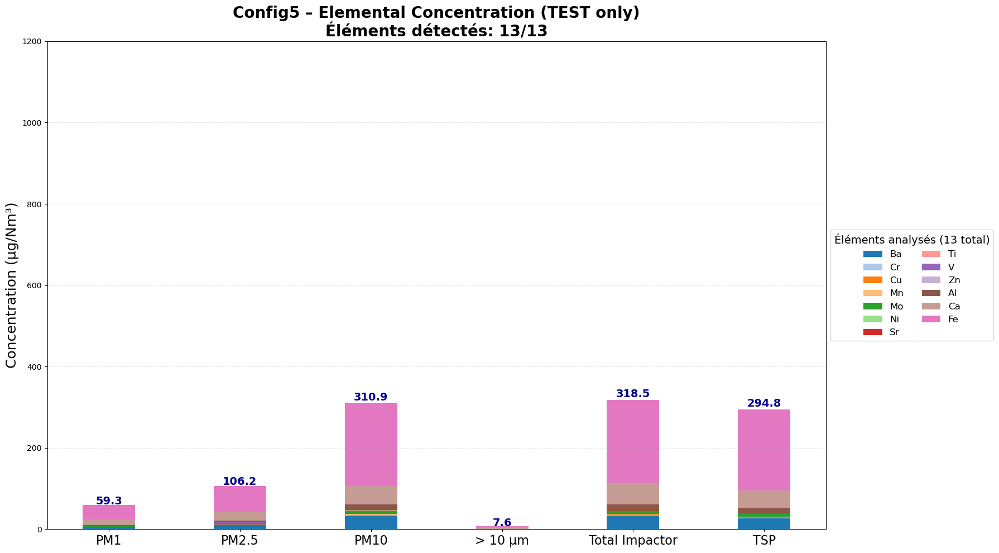


📈 Plotting TEST only: Config6


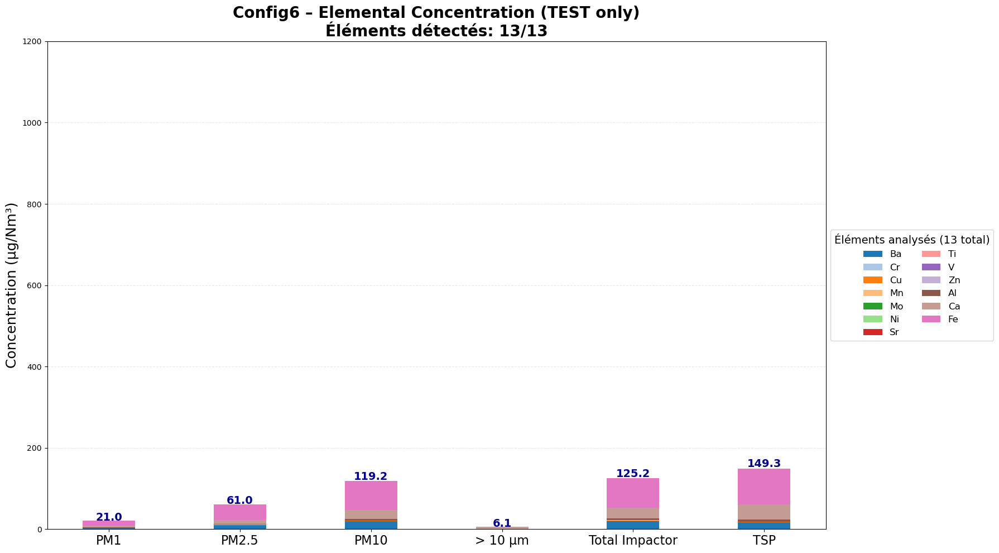


📈 Plotting TEST only: Config7


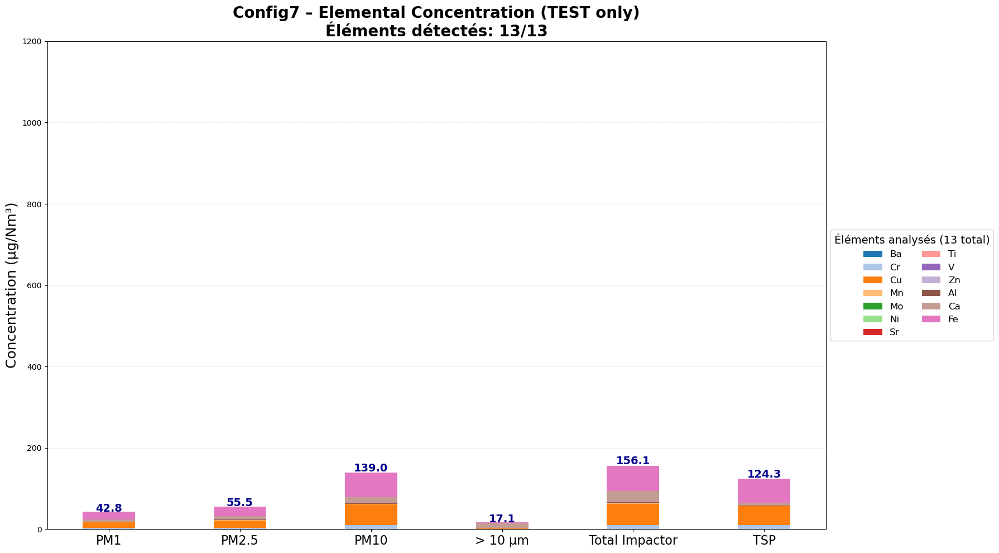


RÉSUMÉ FINAL
Nombre total de configurations: 5
Nombre total d'éléments uniques dans tous les top 10: 13

📊 LISTE GLOBALE DES ÉLÉMENTS (ordre alphabétique):
   1. Al
   2. Ba
   3. Ca
   4. Cr
   5. Cu
   6. Fe
   7. Mn
   8. Mo
   9. Ni
  10. Sr
  11. Ti
  12. V
  13. Zn

📈 TOP 10 PAR CONFIGURATION (basé uniquement sur les tests):

  🔧 Config3:
      1. Fe
      2. Ca
      3. Ba
      4. Al
      5. Cr
      6. Mn
      7. Mo
      8. V
      9. Cu
     10. Sr

  🔧 Config4:
      1. Fe
      2. Ca
      3. Zn
      4. Al
      5. Cr
      6. Mn
      7. Cu
      8. Ba
      9. Mo
     10. Ti

  🔧 Config5:
      1. Fe
      2. Ca
      3. Ba
      4. Al
      5. Mo
      6. Mn
      7. Cr
      8. Cu
      9. Sr
     10. Zn

  🔧 Config6:
      1. Fe
      2. Ca
      3. Ba
      4. Al
      5. Cu
      6. Mn
      7. Sr
      8. Cr
      9. Ti
     10. Ni

  🔧 Config7:
      1. Fe
      2. Cu
      3. Ca
      4. Cr
      5. Al
      6. Mn
      7. Ba
      8. Zn
      9. Ni
     10. 

In [33]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# 1) READ RAW FILE
fichier = r"C:\Users\Grira\OneDrive - Alstom\Documents\Paddle\Campagne2\Impacteur + FH\Masses and elemental composition_PTF2.xlsx"
df_raw = pd.read_excel(fichier, header=None)

# ============================================================
# 2) AUTO-DETECT HEADER ROW
# ============================================================
header_row = None
for i in range(50):
    row = df_raw.iloc[i].astype(str).str.lower()
    if "particle diameter" in row.tolist() and "filter name" in row.tolist():
        header_row = i
        break

df = pd.read_excel(fichier, header=header_row)
df.columns = df.columns.map(str)

# ============================================================
# 3) FILTER TYPE (Blank / Test)
# ============================================================
def detect_type(x):
    x = str(x).strip()
    if not x or x == 'nan':
        return None
    if x.startswith("B"):
        return "Blank"
    else:
        return "Test"

df["Type"] = df["Filter name"].apply(detect_type)
df = df[df["Type"].notna()]

# ============================================================
# 4) MACHINE NAME
# ============================================================
df["Machine"] = df.iloc[:,0].astype(str).str.extract(
    r"(Config[0-9A-Za-z\-]*)", expand=False
).ffill()

# ============================================================
# 5) ELEMENT COLUMNS (µg/Nm³)
# ============================================================
elem_cols = [c for c in df.columns if "(µg/Nm3 filter)" in c]
df[elem_cols] = df[elem_cols].apply(pd.to_numeric, errors="coerce").fillna(0)
elem_labels = {c: c.replace(" (µg/Nm3 filter)", "") for c in elem_cols}

# ============================================================
# 6) TOTAL MASS CONCENTRATION (µg/Nm³) - GARDÉ POUR CALCUL MAIS PAS POUR AFFICHAGE
# ============================================================
col_mass_conc = [c for c in df.columns 
                 if "Concentration" in c and "(µg/Nm3)" in c][0]
df[col_mass_conc] = pd.to_numeric(df[col_mass_conc], errors="coerce").fillna(0)

# ============================================================
# 7) COMPUTE TOP‑10 ELEMENTS FOR TESTS ONLY (per configuration)
# ============================================================
print("\n" + "="*80)
print("   TOP 10 ÉLÉMENTS PAR CONFIGURATION (TESTS UNIQUEMENT)")
print("   Concentration en µg/Nm³")
print("="*80 + "\n")

configs = df["Machine"].unique()

# Dictionnaire pour stocker les top 10 tests
machine_top10_tests = {}

for config in configs:

    print(f"\n------ {config} ------")
    print("-" * 50)

    # Filtrer uniquement les TESTS
    df_config = df[(df["Machine"] == config) & (df["Type"] == "Test")]

    if df_config.empty:
        print(f"⚠ Pas de données Test pour {config}\n")
        continue

    total_conc = df_config[elem_cols].sum(axis=0)
    top10 = total_conc.sort_values(ascending=False).head(10)
    
    # Stocker dans un dictionnaire
    machine_top10_tests[config] = top10.index.tolist()

    # Nettoyer les noms pour l'affichage
    top10_clean = top10.copy()
    top10_clean.index = [elem_labels[c] for c in top10_clean.index]

    print(f"\n{'Rang':<6} {'Élément':<15} {'Concentration totale (µg/Nm³)':<25}")
    print("-" * 50)

    for rank, (elem, value) in enumerate(top10_clean.items(), 1):
        print(f"{rank:<6} {elem:<15} {value:<25.2f}")

    print("-" * 50)
    print(f"Total des 10 éléments: {top10.sum():.2f} µg/Nm³")
    print(f"Total général (tous éléments tests): {total_conc.sum():.2f} µg/Nm³")
    if total_conc.sum() > 0:
        print(f"Les 10 éléments représentent: {(top10.sum()/total_conc.sum()*100):.1f}% du total")
    print("\n")

# ============================================================
# 8) RÉSUMÉ FINAL DES TOP 10 PAR CONFIGURATION (TESTS)
# ============================================================
print("\n" + "="*80)
print("RÉSUMÉ FINAL - TOP 10 PAR CONFIGURATION (TESTS)")
print("="*80)

for config, top10 in machine_top10_tests.items():
    print(f"\n🔧 {config}")
    print("-" * 40)
    for i, elem in enumerate(top10, 1):
        elem_name = elem_labels[elem]
        print(f"  {i:2d}. {elem_name}")

# ============================================================
# 9) LISTE GLOBALE DES ÉLÉMENTS PRÉSENTS DANS LES TOP 10 TESTS
# ============================================================
global_elements_tests = set()
for top10_list in machine_top10_tests.values():
    global_elements_tests.update(top10_list)

global_elements_tests = sorted(list(global_elements_tests), key=lambda x: elem_labels[x])

print("\n" + "="*80)
print(f"LISTE GLOBALE DES ÉLÉMENTS DANS LES TOP 10 DES TESTS ({len(global_elements_tests)} éléments uniques)")
print("(Ces éléments seront affichés dans tous les graphiques avec la même légende)")
print("="*80)
for i, elem in enumerate(global_elements_tests, 1):
    print(f"  {i:2d}. {elem_labels[elem]}")

# ============================================================
# 10) SIZE ORDER
# ============================================================
size_order = [
    "PM1",
    "PM2.5",
    "PM10",
    "> 10 µm",
    "Total Impactor",
    "TSP"
]

# ============================================================
# 11) PLOTTING LOOP (TEST ONLY) - SANS MASSE
# ============================================================
# Garder TOUS les éléments de la liste globale
elem_cols_to_plot = [c for c in elem_cols if c in global_elements_tests]

# Palette fixe basée sur la liste globale (MÊME POUR TOUTES LES CONFIGS)
cmap = plt.get_cmap("tab20")
colors = {elem: cmap(i % 20) for i, elem in enumerate(elem_cols_to_plot)}

for machine, dgroup in df.groupby("Machine"):

    print(f"\n📈 Plotting TEST only: {machine}")

    tests = dgroup[dgroup["Type"] == "Test"].copy()
    if tests.empty:
        print("⚠ No test data")
        continue

    tests["Particle diameter"] = tests["Particle diameter"].astype(str).str.strip()

    # Create a mapping for raw data
    tests["diameter_key"] = tests["Particle diameter"].map({
        "< 1 µm": "PM1_raw",
        "1-2.5 µm": "PM2.5_raw",
        "2.5-10 µm": "PM10_raw",
        "> 10 µm": "> 10 µm",
        "TSP": "TSP"
    })

    # ============================================================
    # 11A — CUMULATIVE ELEMENTAL CONCENTRATIONS (avec éléments globaux)
    # ============================================================
    # Create a dictionary to store raw values for each fraction
    raw_elements = {}
    for fraction in ["PM1_raw", "PM2.5_raw", "PM10_raw", "> 10 µm", "TSP"]:
        subset = tests[tests["diameter_key"] == fraction]
        if not subset.empty:
            raw_elements[fraction] = subset[elem_cols_to_plot].iloc[0]
        else:
            raw_elements[fraction] = pd.Series(0, index=elem_cols_to_plot)

    # Create grouped DataFrame with cumulative calculations
    # grouped = pd.DataFrame(index=size_order, columns=elem_cols_to_plot).fillna(0)
    
    grouped = pd.DataFrame(
        0.0,
        index=size_order,
        columns=elem_cols_to_plot
    )

    # PM1 = <1 µm
    grouped.loc["PM1"] = raw_elements["PM1_raw"]

    # PM2.5 = PM1 + 1–2.5 µm
    grouped.loc["PM2.5"] = raw_elements["PM1_raw"] + raw_elements["PM2.5_raw"]

    # PM10 = PM2.5 + 2.5–10 µm
    grouped.loc["PM10"] = grouped.loc["PM2.5"] + raw_elements["PM10_raw"]

    # >10 µm unchanged
    grouped.loc["> 10 µm"] = raw_elements["> 10 µm"]

    # TOTAL IMPACTOR = (<1 + 1–2.5 + 2.5–10 + >10 µm)
    grouped.loc["Total Impactor"] = (
        raw_elements["PM1_raw"] +
        raw_elements["PM2.5_raw"] +
        raw_elements["PM10_raw"] +
        raw_elements["> 10 µm"]
    )

    # TSP untouched
    grouped.loc["TSP"] = raw_elements["TSP"]

    # ============================================================
    # 11B — PLOT FIGURE (SANS MASSE)
    # ============================================================
    plt.figure(figsize=(18,10))
    width = 0.40
    x = np.arange(len(size_order))

    bottom = np.zeros(len(size_order))

    # Tracer TOUS les éléments de la liste globale
    for elem in elem_cols_to_plot:
        vals = grouped[elem].values.astype(float)
        plt.bar(x, vals, width, bottom=bottom,
                color=colors[elem], label=elem_labels[elem])
        bottom += vals

    # Element total labels
    totals = grouped.sum(axis=1).values
    for i, total in enumerate(totals):
        if total > 0:
            plt.text(x[i], total * 1.02, f"{total:.1f}",
                     ha="center", fontsize=14, fontweight="bold", color="darkblue")

    # ✅ SUPPRESSION des barres de masse concentration (plus de code pour mass_group)

    # Ajustement dynamique de la limite Y basé uniquement sur les éléments
    plt.ylim(0, 1200)
    
    # Count detected elements
    elements_detected = sum(1 for elem in elem_cols_to_plot if tests[elem].sum() > 0)
    
    plt.xticks(x, size_order, fontsize=16)
    plt.ylabel("Concentration (µg/Nm³)", fontsize=18)
    plt.title(f"{machine} – Elemental Concentration (TEST only)\n"
              f"Éléments détectés: {elements_detected}/{len(elem_cols_to_plot)}",
              fontsize=20, fontweight="bold")

    plt.grid(axis='y', linestyle='--', alpha=0.3)
    
    # Légende IDENTIQUE pour toutes les configurations
    plt.legend(loc="center left", bbox_to_anchor=(1, 0.5),
               fontsize=12, title=f"Éléments analysés ({len(elem_cols_to_plot)} total)", 
               title_fontsize=14, ncol=2 if len(elem_cols_to_plot) > 10 else 1)

    plt.tight_layout()
    plt.show()

# ============================================================
# 12) RÉSUMÉ FINAL
# ============================================================
print("\n" + "="*80)
print("RÉSUMÉ FINAL")
print("="*80)
print(f"Nombre total de configurations: {len(machine_top10_tests)}")
print(f"Nombre total d'éléments uniques dans tous les top 10: {len(global_elements_tests)}")
print("\n📊 LISTE GLOBALE DES ÉLÉMENTS (ordre alphabétique):")
for i, elem in enumerate(global_elements_tests, 1):
    print(f"  {i:2d}. {elem_labels[elem]}")
    
print("\n📈 TOP 10 PAR CONFIGURATION (basé uniquement sur les tests):")
for machine, top10 in machine_top10_tests.items():
    print(f"\n  🔧 {machine}:")
    for i, elem in enumerate(top10, 1):
        print(f"     {i:2d}. {elem_labels[elem]}")

print("\n" + "="*80)
print("DONE")
print("="*80)

Wabtec_De Falco et al

In [199]:
# import numpy as np
# import matplotlib.pyplot as plt

# # --- Données ---
# materials = ["Sintered A CoFren", "Organic B Competitor", "Organic C CoFren"]

# PM10 = [212.0, 385.3, 545.0]
# PM25 = [76.0, 190.0, 312.1]
# PM1  = [8.5, 33.7, 49.7]

# # Création des positions pour les barres
# x = np.arange(len(materials))
# width = 0.25  # largeur des barres

# # --- Figure ---
# plt.figure(figsize=(10, 6))

# plt.bar(x - width, PM10, width, label="PM10 (mg/m³)", color="#f4c542")
# plt.bar(x,         PM25, width, label="PM2.5 (mg/m³)", color="#42a5f5")
# plt.bar(x + width, PM1,  width, label="PM1 (mg/m³)", color="#66bb6a")

# # --- Mise en forme ---
# plt.ylim(0, 600)
# plt.xticks(x, materials, fontsize=12)
# plt.ylabel("Concentration (mg/m³)", fontsize=12)
# plt.title("Particulate Emissions by Material", fontsize=14)
# plt.legend()
# plt.tight_layout()

# # Affichage
# plt.show()

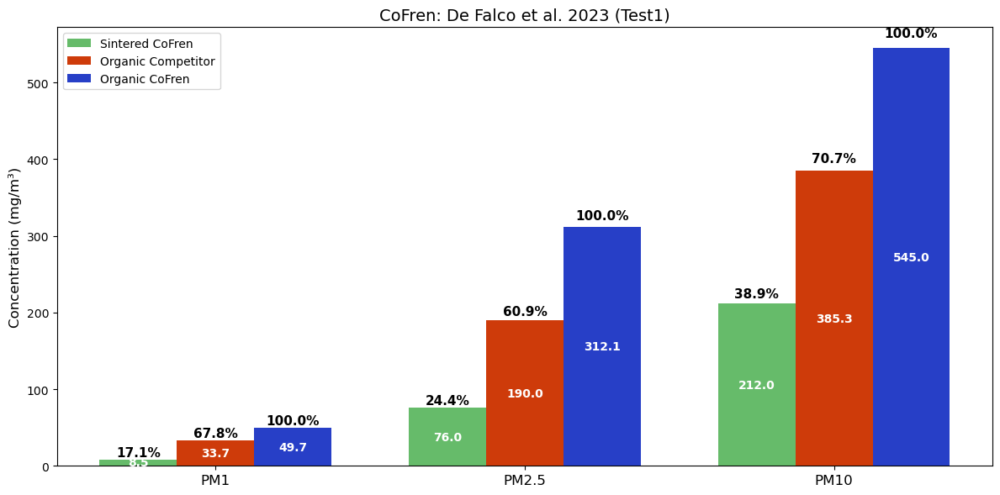

In [202]:
import numpy as np
import matplotlib.pyplot as plt

# --- Données ---
pm_categories = ["PM1", "PM2.5", "PM10"]

Sintered_CoFren = [8.5, 76.0, 212.0]
Organic_Competitor = [33.7, 190.0, 385.3]
Organic_CoFren = [49.7, 312.1, 545.0]

# Pourcentages par rapport à Organic CoFren (=100%)
S_percent = [(v / Organic_CoFren[i]) * 100 for i, v in enumerate(Sintered_CoFren)]
OC_percent = [(v / Organic_CoFren[i]) * 100 for i, v in enumerate(Organic_Competitor)]
O_percent = [100, 100, 100]

x = np.arange(len(pm_categories))
width = 0.25

plt.figure(figsize=(12,6))

bars1 = plt.bar(x - width, Sintered_CoFren, width, label="Sintered CoFren", color="#66bb6a")
bars2 = plt.bar(x, Organic_Competitor, width, label="Organic Competitor", color="#ce3b0a")
bars3 = plt.bar(x + width, Organic_CoFren, width, label="Organic CoFren", color="#273fc7")

# --- Ajout % au-dessus + valeur dans la barre ---
def add_labels(bars, percents):
    for bar, pct in zip(bars, percents):
        height = bar.get_height()

        # Pourcentage AU-DESSUS
        plt.text(
            bar.get_x() + bar.get_width()/2,
            height + height * 0.02,
            f"{pct:.1f}%",
            ha='center', va='bottom', fontsize=11, fontweight='bold'
        )

        # Valeur DANS la barre
        plt.text(
            bar.get_x() + bar.get_width()/2,
            height * 0.5,
            f"{height}",
            ha='center', va='center', fontsize=10, color="white", fontweight="bold"
        )

add_labels(bars1, S_percent)
add_labels(bars2, OC_percent)
add_labels(bars3, O_percent)

plt.xticks(x, pm_categories, fontsize=12)
plt.ylabel("Concentration (mg/m³)", fontsize=12)
plt.title("CoFren: De Falco et al. 2023 (Test1)", fontsize=14)
plt.legend()
plt.tight_layout()

plt.show()

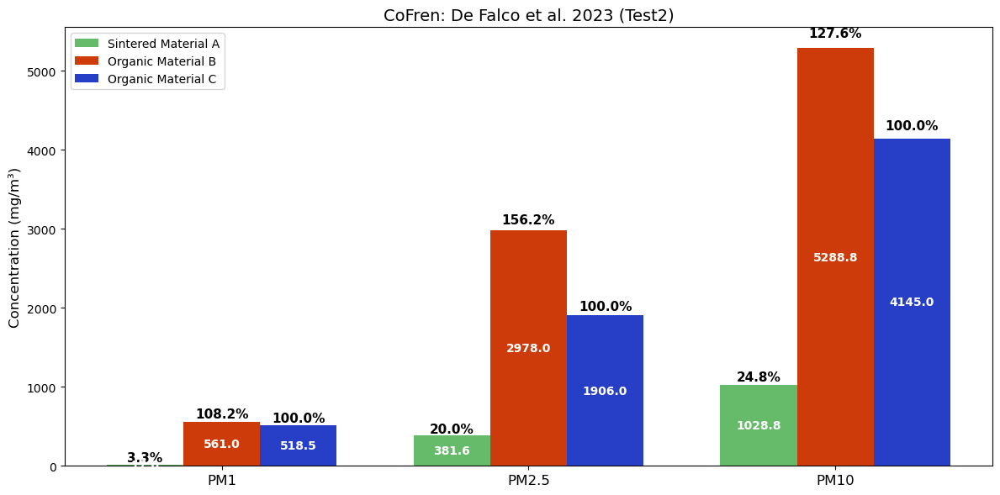

In [97]:
import numpy as np
import matplotlib.pyplot as plt

# --- Données réorganisées (PM1, PM2.5, PM10) ---
pm_categories = ["PM1", "PM2.5", "PM10"]

Sintered_A = [17.0, 381.6, 1028.8]
Organic_B  = [561.0, 2978.0, 5288.8]
Organic_C  = [518.5, 1906.0, 4145.0]   # Base = 100 %

# Pourcentages par rapport à Organic C
S_percent = [(v / Organic_C[i]) * 100 for i, v in enumerate(Sintered_A)]
B_percent = [(v / Organic_C[i]) * 100 for i, v in enumerate(Organic_B)]
C_percent = [100, 100, 100]

x = np.arange(len(pm_categories))
width = 0.25

plt.figure(figsize=(12,6))

bars1 = plt.bar(x - width, Sintered_A, width, label="Sintered Material A", color="#66bb6a")
bars2 = plt.bar(x,        Organic_B,  width, label="Organic Material B", color="#ce3b0a")
bars3 = plt.bar(x + width, Organic_C, width, label="Organic Material C", color="#273fc7")

# --- Ajout % + valeur ---
def add_labels(bars, percents):
    for bar, pct in zip(bars, percents):
        height = bar.get_height()

        # Pourcentage au-dessus
        plt.text(
            bar.get_x() + bar.get_width()/2,
            height + max(height * 0.02, 5),
            f"{pct:.1f}%",
            ha='center', va='bottom', fontsize=11, fontweight='bold'
        )

        # Valeur à l'intérieur de la barre
        plt.text(
            bar.get_x() + bar.get_width()/2,
            height * 0.5,
            f"{height:.1f}",
            ha='center', va='center', fontsize=10, color="white", fontweight="bold"
        )

add_labels(bars1, S_percent)
add_labels(bars2, B_percent)
add_labels(bars3, C_percent)

plt.xticks(x, pm_categories, fontsize=12)
plt.ylabel("Concentration (mg/m³)", fontsize=12)
plt.title("CoFren: De Falco et al. 2023 (Test2)", fontsize=14)
plt.legend()
plt.tight_layout()

plt.show()

All config - Total particle mass concentration_Imapctor

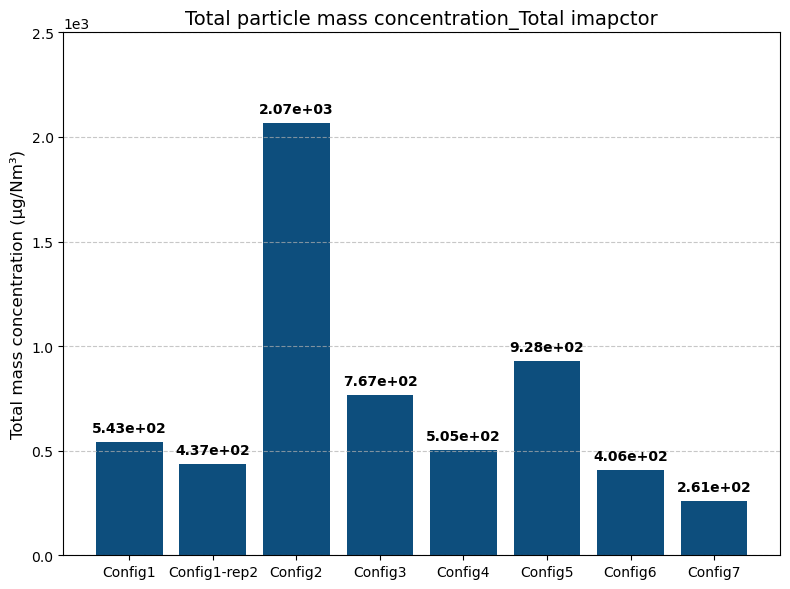

In [3]:
import matplotlib.pyplot as plt
import numpy as np

# Data
conditions = ['Config1', 'Config1-rep2', 'Config2', 'Config3', 'Config4', 'Config5', 'Config6','Config7']
total_concentration = np.array([543.4, 437.0, 2067.3, 766.9, 505.3, 928.5, 406.5, 261.0])  # µg/Nm³ total impactor
# total_concentration = np.array([492.2, 409.2, 2294.6, 1051.1, 593.1, 952.9, 427.8, 293.4])  # µg/Nm³ FH

# Create bar chart with the exact blue from the reference graph
fig, ax = plt.subplots(figsize=(8, 6))
bars = ax.bar(conditions, total_concentration, color="#0d4e7d")  # Matplotlib default blue

# Labels, title, grid
ax.set_ylabel('Total mass concentration (µg/Nm³)', fontsize=12)
ax.set_title('Total particle mass concentration_Total imapctor', fontsize=14)
# ax.set_title('Total particle mass concentration_FH', fontsize=14)
ax.grid(axis='y', linestyle='--', alpha=0.7)
ax.set_ylim(0, 2.5e3)

# Annotate each bar with its concentration value
for bar, conc in zip(bars, total_concentration):
    height = bar.get_height()
    ax.annotate(f'{conc:.2e}',
                xy=(bar.get_x() + bar.get_width() / 2, height),
                xytext=(0, 5),
                textcoords="offset points",
                ha='center', va='bottom',
                fontsize=10, fontweight='bold')

# Scientific notation on y-axis
ax.ticklabel_format(axis='y', style='sci', scilimits=(0, 0))

plt.tight_layout()
plt.show()

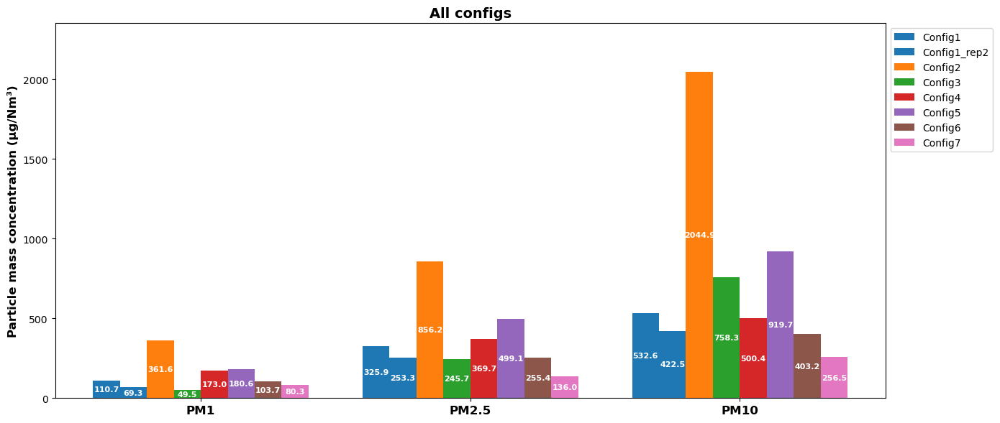

In [26]:
import numpy as np
import matplotlib.pyplot as plt

# --- Data (PM1, PM2.5, PM10) ---
pm_categories = ["PM1", "PM2.5", "PM10"]

Config1 = [110.7, 325.9, 532.6]
Config1_rep2 = [69.3, 253.3, 422.5]
Config2 = [361.6, 856.2, 2044.9]
Config3 = [49.5, 245.7, 758.3]
Config4 = [173, 369.7, 500.4]
Config5 = [180.6, 499.1, 919.7]
Config6 = [103.7, 255.4, 403.2]
Config7 = [80.3, 136.0, 256.5]

configs = [Config1, Config1_rep2, Config2, Config3, Config4, Config5, Config6, Config7]
config_labels = ["Config1", "Config1_rep2", "Config2", "Config3", "Config4", "Config5", "Config6", "Config7"]
N = len(configs)

# Distinct colours (first two same because Config1 & rep2 share colour)
colors = ["#1f77b4", "#1f77b4", "#ff7f0e", "#2ca02c", "#d62728", "#9467bd", "#8c564b", "#e377c2"]

x = np.arange(len(pm_categories))
width = 0.8 / N
offsets = np.linspace(-(N-1)/2, (N-1)/2, N) * width

plt.figure(figsize=(14, 6))

bars = []

for i, config in enumerate(configs):
    bar = plt.bar(x + offsets[i], config, width,
                  label=config_labels[i], color=colors[i])
    bars.append(bar)

def add_labels(bars):
    for bar in bars:
        height = bar.get_height()
        # Only the value inside the bar – no percentage
        plt.text(bar.get_x() + bar.get_width()/2,
                 height * 0.5,
                 f"{height:.1f}",
                 ha='center', va='center', fontsize=8, color="white", fontweight="bold")

for bar_group in bars:
    add_labels(bar_group)

plt.xticks(x, pm_categories, fontsize=12, fontweight="bold")
plt.ylabel("Particle mass concentration (µg/Nm³)", fontsize=12, fontweight="bold")
plt.title("All configs", fontsize=14, fontweight="bold")
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.tight_layout()
max_val = max(max(c) for c in configs)
plt.ylim(0, max_val * 1.15)
plt.show()

AGC

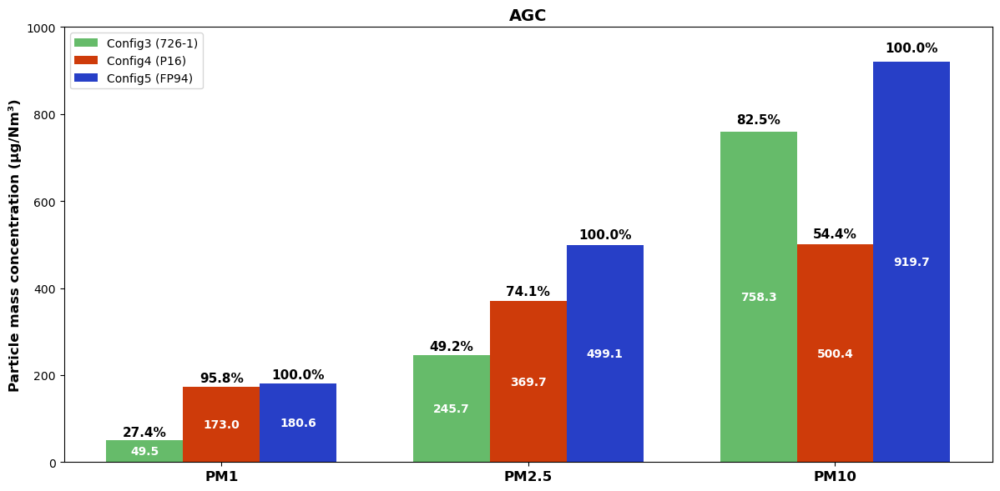

In [17]:
import numpy as np
import matplotlib.pyplot as plt

# --- Données réorganisées (PM1, PM2.5, PM10) ---
pm_categories = ["PM1", "PM2.5", "PM10"]

Config1 = [49.5, 245.7, 758.3]
Config1_rep2 = [49.5, 245.7, 758.3]
Config2 = [49.5, 245.7, 758.3]
Config3 = [49.5, 245.7, 758.3]
Config4  = [173, 369.7, 500.4]
Config5  = [180.6, 499.1, 919.7]   # Base = 100 %
Config6  = [180.6, 499.1, 919.7]   
Config7  = [180.6, 499.1, 919.7]   

# Pourcentages par rapport à Organic C
S_percent = [(v / Config5[i]) * 100 for i, v in enumerate(Config3)]
B_percent = [(v / Config5[i]) * 100 for i, v in enumerate(Config4)]
C_percent = [100, 100, 100]

x = np.arange(len(pm_categories))
width = 0.25

plt.figure(figsize=(12,6))

bars1 = plt.bar(x - width, Config3, width, label="Config3 (726-1)", color="#66bb6a")
bars2 = plt.bar(x,        Config4,  width, label="Config4 (P16)", color="#ce3b0a")
bars3 = plt.bar(x + width, Config5, width, label="Config5 (FP94)", color="#273fc7")

# --- Ajout % + valeur ---
def add_labels(bars, percents):
    for bar, pct in zip(bars, percents):
        height = bar.get_height()

        # Pourcentage au-dessus
        plt.text(
            bar.get_x() + bar.get_width()/2,
            height + max(height * 0.02, 5),
            f"{pct:.1f}%",
            ha='center', va='bottom', fontsize=11, fontweight='bold'
        )

        # Valeur à l'intérieur de la barre
        plt.text(
            bar.get_x() + bar.get_width()/2,
            height * 0.5,
            f"{height:.1f}",
            ha='center', va='center', fontsize=10, color="white", fontweight="bold"
        )

add_labels(bars1, S_percent)
add_labels(bars2, B_percent)
add_labels(bars3, C_percent)

plt.xticks(x, pm_categories, fontsize=12, fontweight="bold")
plt.ylabel("Particle mass concentration (µg/Nm³)", fontsize=12, fontweight="bold")
plt.title("AGC", fontsize=14, fontweight="bold")
plt.legend()
plt.tight_layout()
plt.ylim(0,1000)
plt.show()

Config1 vs Config6

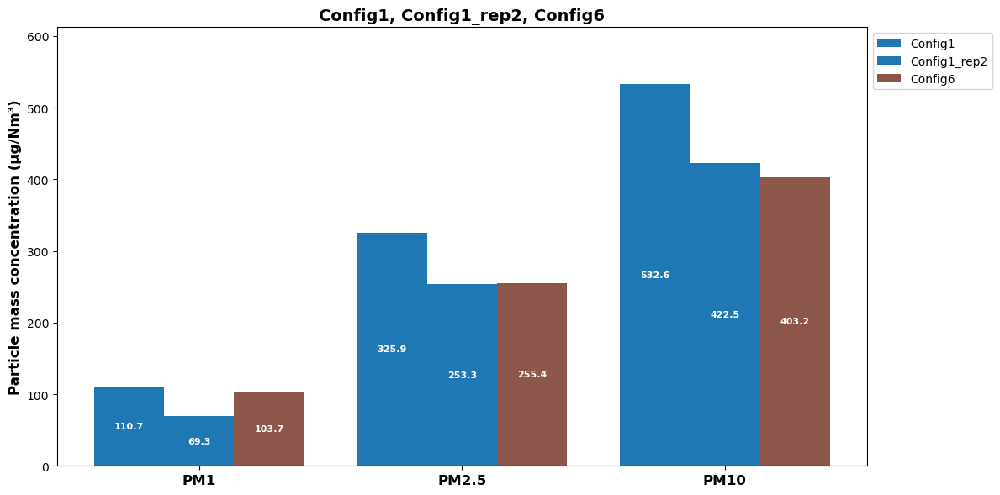

In [32]:
import numpy as np
import matplotlib.pyplot as plt

# --- Data (PM1, PM2.5, PM10) ---
pm_categories = ["PM1", "PM2.5", "PM10"]

Config1 = [110.7, 325.9, 532.6]
Config1_rep2 = [69.3, 253.3, 422.5]
Config6 = [103.7, 255.4, 403.2]

# Keep only the three configs
configs = [Config1, Config1_rep2, Config6]
config_labels = ["Config1", "Config1_rep2", "Config6"]
N = len(configs)

# Distinct colours for each (you can change these)
colors = ["#1f77b4","#1f77b4", "#8c564b"]   

x = np.arange(len(pm_categories))
width = 0.8 / N
offsets = np.linspace(-(N-1)/2, (N-1)/2, N) * width

plt.figure(figsize=(12, 6))

bars = []

for i, config in enumerate(configs):
    bar = plt.bar(x + offsets[i], config, width,
                  label=config_labels[i], color=colors[i])
    bars.append(bar)

def add_labels(bars):
    for bar in bars:
        height = bar.get_height()
        plt.text(bar.get_x() + bar.get_width()/2,
                 height * 0.5,
                 f"{height:.1f}",
                 ha='center', va='center', fontsize=8, color="white", fontweight="bold")

for bar_group in bars:
    add_labels(bar_group)

plt.xticks(x, pm_categories, fontsize=12, fontweight="bold")
plt.ylabel("Particle mass concentration (µg/Nm³)", fontsize=12, fontweight="bold")
plt.title("Config1, Config1_rep2, Config6", fontsize=14, fontweight="bold")
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.tight_layout()
max_val = max(max(c) for c in configs)
plt.ylim(0, max_val * 1.15)
plt.show()

Config2 vs Config3

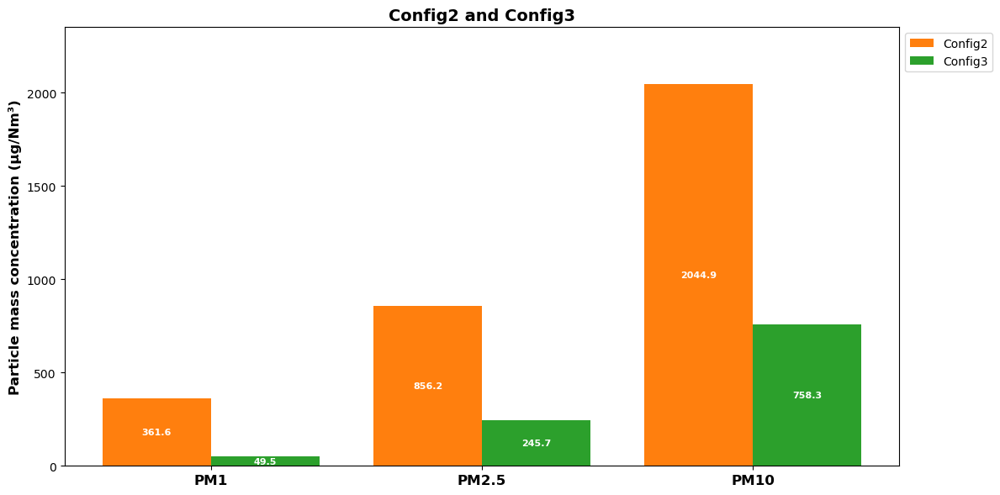

In [34]:
import numpy as np
import matplotlib.pyplot as plt

# --- Data (PM1, PM2.5, PM10) ---
pm_categories = ["PM1", "PM2.5", "PM10"]

Config2 = [361.6, 856.2, 2044.9]
Config3 = [49.5, 245.7, 758.3]

# Keep only Config2 and Config3
configs = [Config2, Config3]
config_labels = ["Config2", "Config3"]
N = len(configs)

# Distinct colours for each
colors = ["#ff7f0e", "#2ca02c"]   # orange, green

x = np.arange(len(pm_categories))
width = 0.8 / N
offsets = np.linspace(-(N-1)/2, (N-1)/2, N) * width

plt.figure(figsize=(12, 6))

bars = []

for i, config in enumerate(configs):
    bar = plt.bar(x + offsets[i], config, width,
                  label=config_labels[i], color=colors[i])
    bars.append(bar)

def add_labels(bars):
    for bar in bars:
        height = bar.get_height()
        plt.text(bar.get_x() + bar.get_width()/2,
                 height * 0.5,
                 f"{height:.1f}",
                 ha='center', va='center', fontsize=8, color="white", fontweight="bold")

for bar_group in bars:
    add_labels(bar_group)

plt.xticks(x, pm_categories, fontsize=12, fontweight="bold")
plt.ylabel("Particle mass concentration (µg/Nm³)", fontsize=12, fontweight="bold")
plt.title("Config2 and Config3", fontsize=14, fontweight="bold")
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.tight_layout()
max_val = max(max(c) for c in configs)
plt.ylim(0, max_val * 1.15)
plt.show()

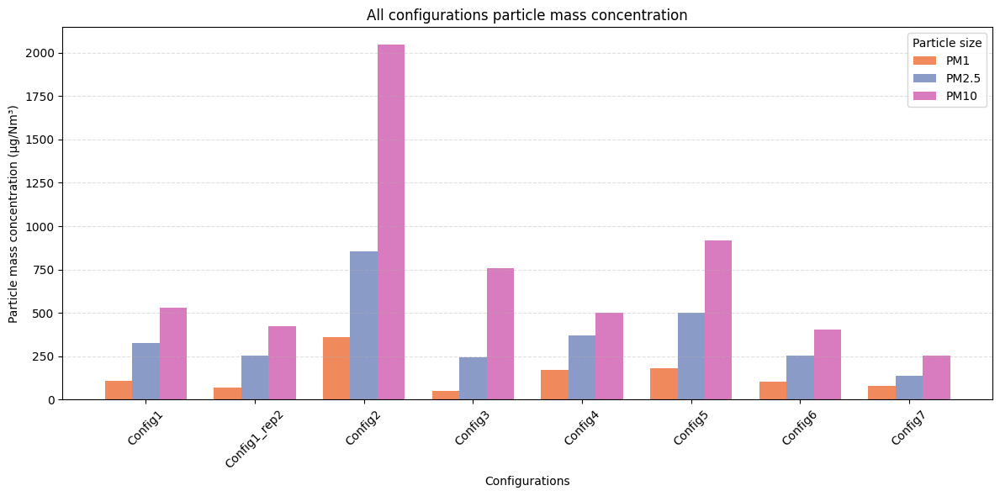

In [1]:
import matplotlib.pyplot as plt
import numpy as np
configs = [
'Config1', 'Config1_rep2', 'Config2',
'Config3', 'Config4', 'Config5',
'Config6', 'Config7'
]
PM1 = [110.7, 69.3, 361.6, 49.5, 173.0, 180.6, 103.7, 80.3]
PM25 = [325.9, 253.3, 856.2, 245.7, 369.7, 499.1, 255.4, 136.0]
PM10 = [532.6, 422.5, 2044.9, 758.3, 500.4, 919.7, 403.2, 256.5]
x = np.arange(len(configs))
w = 0.25
plt.figure(figsize=(12,6))
plt.bar(x - w, PM1, width=w, color='#F08A5D', label='PM1')
plt.bar(x, PM25, width=w, color='#8A9BC8', label='PM2.5')
plt.bar(x + w, PM10, width=w, color='#D97BBF', label='PM10')
plt.xticks(x, configs, rotation=45)
plt.ylabel('Particle mass concentration (µg/Nm³)')
plt.xlabel('Configurations')
plt.title('All configurations particle mass concentration')

plt.legend(title='Particle size')
plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

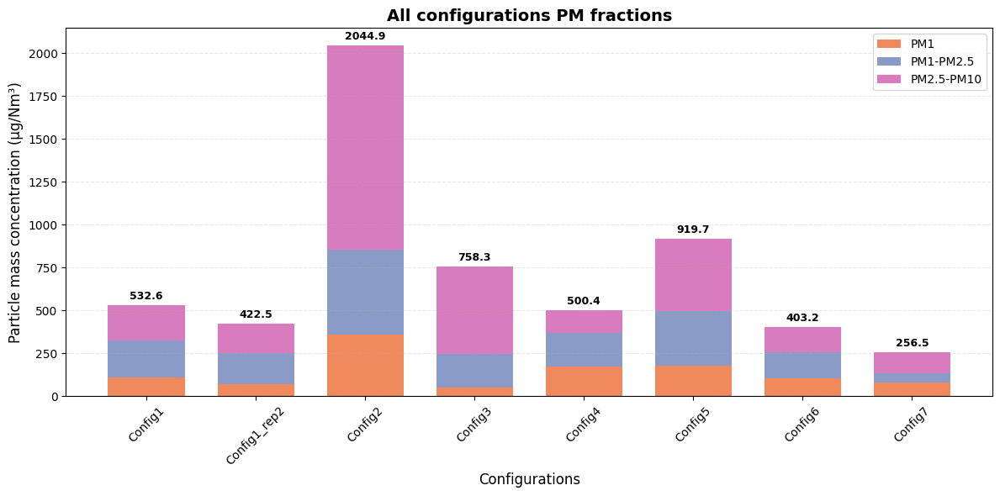

In [2]:
import matplotlib.pyplot as plt
import numpy as np

configs = [
    'Config1', 'Config1_rep2', 'Config2',
    'Config3', 'Config4', 'Config5',
    'Config6', 'Config7'
]

PM1 = [110.7, 69.3, 361.6, 49.5, 173.0, 180.6, 103.7, 80.3]
PM1_PM25 = [215.2, 184.0, 494.6, 196.2, 196.7, 318.5, 151.7, 55.7]
PM25_PM10 = [206.7, 169.2, 1188.7, 512.6, 130.7, 420.6, 147.8, 120.5]

x = np.arange(len(configs))

plt.figure(figsize=(12,6))

# PM1
plt.bar(
    x, PM1,
    color='#F08A5D',
    width=0.7,
    label='PM1'
)

# PM1-PM2.5
plt.bar(
    x, PM1_PM25,
    bottom=PM1,
    color='#8A9BC8',
    width=0.7,
    label='PM1-PM2.5'
)

# PM2.5-PM10
plt.bar(
    x, PM25_PM10,
    bottom=np.array(PM1) + np.array(PM1_PM25),
    color='#D97BBF',
    width=0.7,
    label='PM2.5-PM10'
)

# Totaux au-dessus des barres
totals = np.array(PM1) + np.array(PM1_PM25) + np.array(PM25_PM10)

for i, total in enumerate(totals):
    plt.text(
        i,
        total + 20,
        f'{total:.1f}',
        ha='center',
        va='bottom',
        fontsize=9,
        fontweight='bold'
    )

plt.xticks(x, configs, rotation=45)
plt.ylabel('Particle mass concentration (µg/Nm³)', fontsize=12)
plt.xlabel('Configurations', fontsize=12)
plt.title('All configurations PM fractions', fontsize=14, fontweight='bold')

plt.legend(frameon=True)

plt.grid(axis='y', linestyle='--', alpha=0.3)

plt.tight_layout()
plt.show()

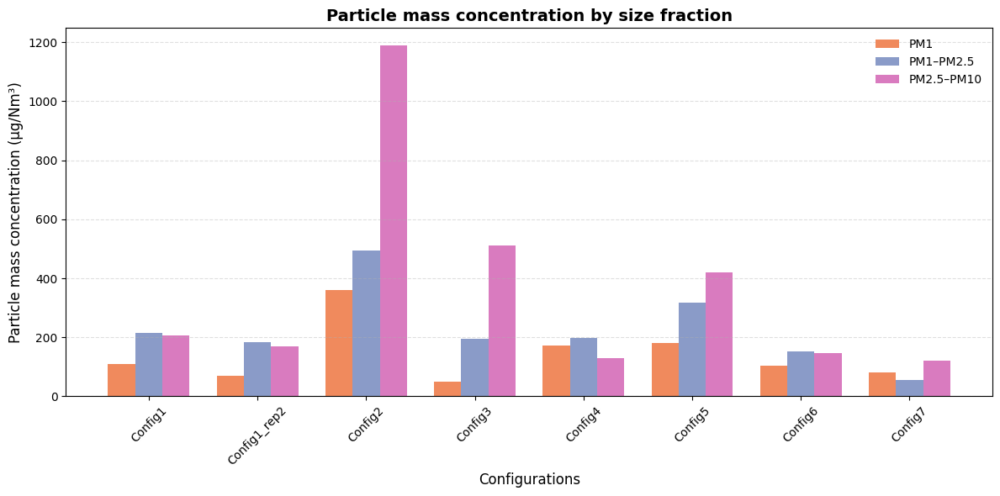

In [3]:
import matplotlib.pyplot as plt
import numpy as np

configs = [
    'Config1', 'Config1_rep2', 'Config2',
    'Config3', 'Config4', 'Config5',
    'Config6', 'Config7'
]

PM1 = [110.7, 69.3, 361.6, 49.5, 173.0, 180.6, 103.7, 80.3]
PM1_PM25 = [215.2, 184.0, 494.6, 196.2, 196.7, 318.5, 151.7, 55.7]
PM25_PM10 = [206.7, 169.2, 1188.7, 512.6, 130.7, 420.6, 147.8, 120.5]

x = np.arange(len(configs))
w = 0.25

plt.figure(figsize=(12,6))

plt.bar(
    x - w, PM1,
    width=w,
    color='#F08A5D',
    label='PM1'
)

plt.bar(
    x, PM1_PM25,
    width=w,
    color='#8A9BC8',
    label='PM1–PM2.5'
)

plt.bar(
    x + w, PM25_PM10,
    width=w,
    color='#D97BBF',
    label='PM2.5–PM10'
)

plt.xticks(x, configs, rotation=45)
plt.ylabel('Particle mass concentration (µg/Nm³)', fontsize=12)
plt.xlabel('Configurations', fontsize=12)
plt.title('Particle mass concentration by size fraction', fontsize=14, weight='bold')

plt.legend(frameon=False)

plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()

plt.show()

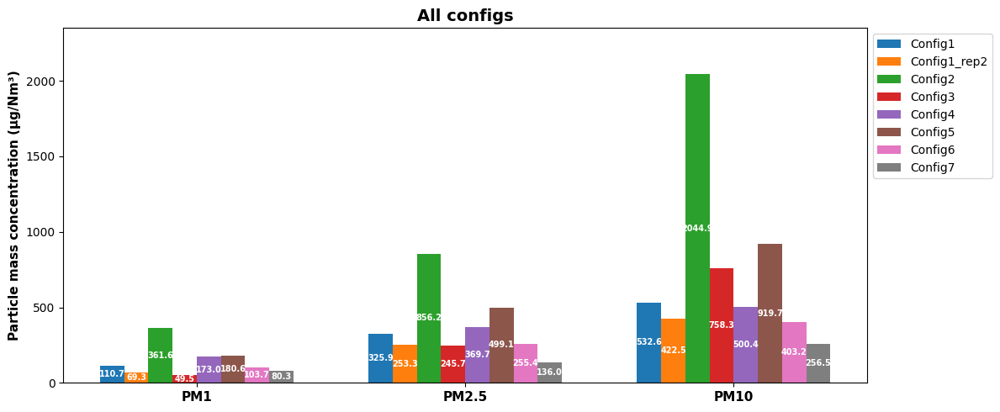

In [4]:
import numpy as np
import matplotlib.pyplot as plt

# Categories
categories = ['PM1', 'PM2.5', 'PM10']

# Data from the figure
data = {
    'Config1':      [110.7, 325.9, 532.6],
    'Config1_rep2': [69.3, 253.3, 422.5],
    'Config2':      [361.6, 856.2, 2044.9],
    'Config3':      [49.5, 245.7, 758.3],
    'Config4':      [173.0, 369.7, 500.4],
    'Config5':      [180.6, 499.1, 919.7],
    'Config6':      [103.7, 255.4, 403.2],
    'Config7':      [80.3, 136.0, 256.5]
}

# Plot settings
x = np.arange(len(categories))
n_configs = len(data)
width = 0.09

fig, ax = plt.subplots(figsize=(12, 5))

# Plot bars
for i, (label, values) in enumerate(data.items()):
    offset = (i - n_configs / 2 + 0.5) * width
    bars = ax.bar(x + offset, values, width, label=label)

    # Add value labels inside bars
    for bar, value in zip(bars, values):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            value * 0.5,
            f'{value:.1f}',
            ha='center',
            va='center',
            color='white',
            fontsize=7,
            fontweight='bold'
        )

# Formatting
ax.set_title('All configs', fontsize=14, fontweight='bold')
ax.set_ylabel('Particle mass concentration (µg/Nm³)', fontsize=11, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(categories, fontsize=11, fontweight='bold')

ax.legend(loc='upper left', bbox_to_anchor=(1.00, 1.0))
ax.set_ylim(0, 2350)

plt.tight_layout()
plt.show()

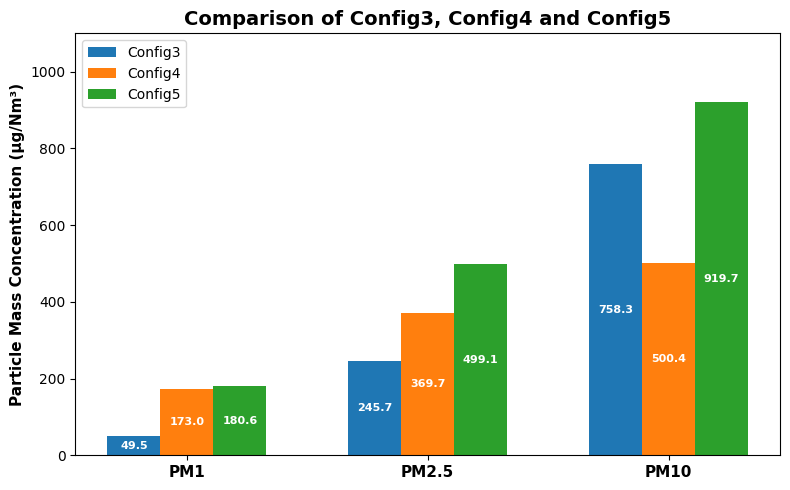

In [5]:
import numpy as np
import matplotlib.pyplot as plt

# Categories
categories = ['PM1', 'PM2.5', 'PM10']

# Data
data = {
    'Config3': [49.5, 245.7, 758.3],
    'Config4': [173.0, 369.7, 500.4],
    'Config5': [180.6, 499.1, 919.7]
}

# Positions
x = np.arange(len(categories))
n_configs = len(data)
width = 0.22

# Create figure
fig, ax = plt.subplots(figsize=(8, 5))

# Plot bars
for i, (label, values) in enumerate(data.items()):
    offset = (i - (n_configs - 1) / 2) * width
    bars = ax.bar(x + offset, values, width, label=label)

    # Value labels
    for bar, value in zip(bars, values):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            value * 0.5,
            f'{value:.1f}',
            ha='center',
            va='center',
            color='white',
            fontsize=8,
            fontweight='bold'
        )

# Formatting
ax.set_title('Comparison of Config3, Config4 and Config5',
             fontsize=14, fontweight='bold')
ax.set_ylabel('Particle Mass Concentration (µg/Nm³)',
              fontsize=11, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(categories, fontsize=11, fontweight='bold')

ax.legend()
ax.set_ylim(0, 1100)

plt.tight_layout()
plt.show()

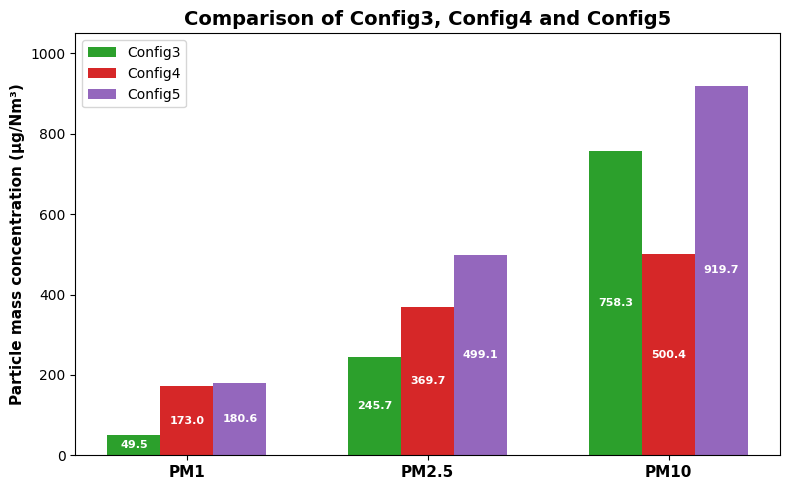

In [6]:
import numpy as np
import matplotlib.pyplot as plt

# Categories
categories = ['PM1', 'PM2.5', 'PM10']

# Data
data = {
    'Config3': [49.5, 245.7, 758.3],
    'Config4': [173.0, 369.7, 500.4],
    'Config5': [180.6, 499.1, 919.7]
}

# Same colors as in the original figure
colors = {
    'Config3': 'tab:green',
    'Config4': 'tab:red',
    'Config5': 'tab:purple'
}

x = np.arange(len(categories))
width = 0.22

fig, ax = plt.subplots(figsize=(8, 5))

for i, (label, values) in enumerate(data.items()):
    offset = (i - 1) * width
    bars = ax.bar(
        x + offset,
        values,
        width,
        label=label,
        color=colors[label]
    )

    # Value labels
    for bar, value in zip(bars, values):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            value * 0.5,
            f'{value:.1f}',
            ha='center',
            va='center',
            color='white',
            fontsize=8,
            fontweight='bold'
        )

# Formatting
ax.set_title('Comparison of Config3, Config4 and Config5',
             fontsize=14, fontweight='bold')

ax.set_ylabel('Particle mass concentration (µg/Nm³)',
              fontsize=11, fontweight='bold')

ax.set_xticks(x)
ax.set_xticklabels(categories,
                   fontsize=11,
                   fontweight='bold')

ax.legend()
ax.set_ylim(0, 1050)

plt.tight_layout()
plt.show()

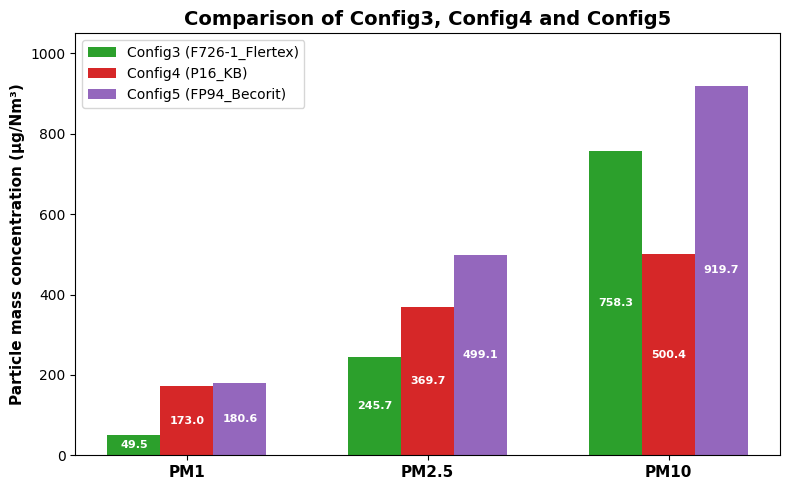

In [7]:
import numpy as np
import matplotlib.pyplot as plt

# Categories
categories = ['PM1', 'PM2.5', 'PM10']

# Data
data = {
    'Config3 (F726-1_Flertex)': [49.5, 245.7, 758.3],
    'Config4 (P16_KB)': [173.0, 369.7, 500.4],
    'Config5 (FP94_Becorit)': [180.6, 499.1, 919.7]
}

# Same colors as in the original figure
colors = {
    'Config3 (F726-1_Flertex)': 'tab:green',
    'Config4 (P16_KB)': 'tab:red',
    'Config5 (FP94_Becorit)': 'tab:purple'
}

x = np.arange(len(categories))
width = 0.22

fig, ax = plt.subplots(figsize=(8, 5))

for i, (label, values) in enumerate(data.items()):
    offset = (i - 1) * width
    bars = ax.bar(
        x + offset,
        values,
        width,
        label=label,
        color=colors[label]
    )

    # Value labels
    for bar, value in zip(bars, values):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            value * 0.5,
            f'{value:.1f}',
            ha='center',
            va='center',
            color='white',
            fontsize=8,
            fontweight='bold'
        )

# Formatting
ax.set_title('Comparison of Config3, Config4 and Config5',
             fontsize=14, fontweight='bold')

ax.set_ylabel('Particle mass concentration (µg/Nm³)',
              fontsize=11, fontweight='bold')

ax.set_xticks(x)
ax.set_xticklabels(categories,
                   fontsize=11,
                   fontweight='bold')

ax.legend()
ax.set_ylim(0, 1050)

plt.tight_layout()
plt.show()

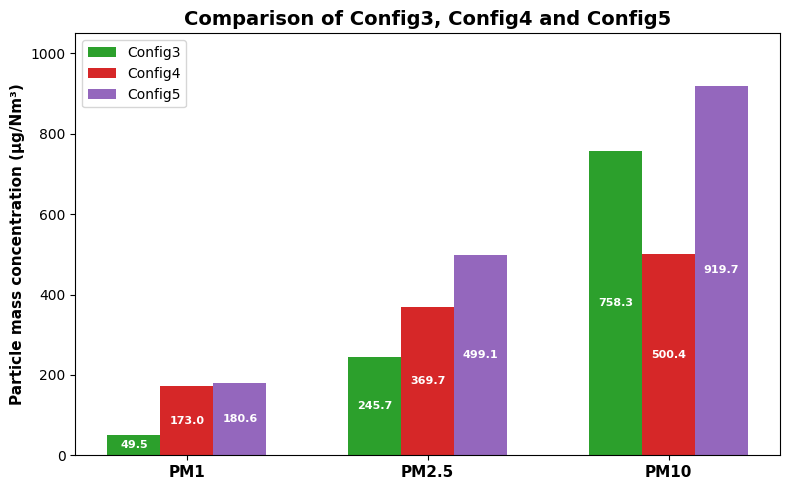

In [8]:
import numpy as np
import matplotlib.pyplot as plt

# Categories
categories = ['PM1', 'PM2.5', 'PM10']

# Data
data = {
    'Config3': [49.5, 245.7, 758.3],
    'Config4': [173.0, 369.7, 500.4],
    'Config5': [180.6, 499.1, 919.7]
}

# Same colors as in the original figure
colors = {
    'Config3': 'tab:green',
    'Config4': 'tab:red',
    'Config5': 'tab:purple'
}

x = np.arange(len(categories))
width = 0.22

fig, ax = plt.subplots(figsize=(8, 5))

for i, (label, values) in enumerate(data.items()):
    offset = (i - 1) * width
    bars = ax.bar(
        x + offset,
        values,
        width,
        label=label,
        color=colors[label]
    )

    # Value labels
    for bar, value in zip(bars, values):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            value * 0.5,
            f'{value:.1f}',
            ha='center',
            va='center',
            color='white',
            fontsize=8,
            fontweight='bold'
        )

# Formatting
ax.set_title('Comparison of Config3, Config4 and Config5',
             fontsize=14, fontweight='bold')

ax.set_ylabel('Particle mass concentration (µg/Nm³)',
              fontsize=11, fontweight='bold')

ax.set_xticks(x)
ax.set_xticklabels(categories,
                   fontsize=11,
                   fontweight='bold')

ax.legend()
ax.set_ylim(0, 1050)

plt.tight_layout()
plt.show()

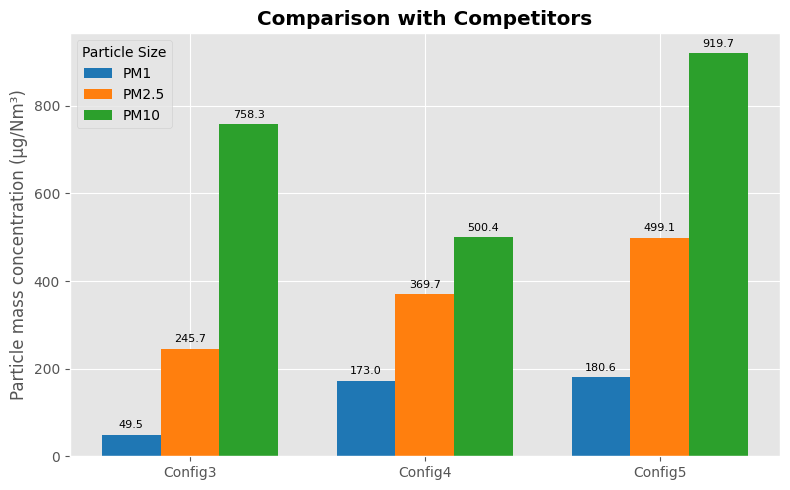

In [9]:
import numpy as np
import matplotlib.pyplot as plt

# Configurations sur l'axe X
configs = ['Config3', 'Config4', 'Config5']

# Données
pm1 = [49.5, 173.0, 180.6]
pm25 = [245.7, 369.7, 499.1]
pm10 = [758.3, 500.4, 919.7]

x = np.arange(len(configs))
width = 0.25

plt.style.use('ggplot')

fig, ax = plt.subplots(figsize=(8, 5))

bars1 = ax.bar(x - width, pm1, width, label='PM1', color='tab:blue')
bars2 = ax.bar(x, pm25, width, label='PM2.5', color='tab:orange')
bars3 = ax.bar(x + width, pm10, width, label='PM10', color='tab:green')

# Ajouter les valeurs sur les barres
for bars in [bars1, bars2, bars3]:

    for bar in bars:
        h = bar.get_height()
        ax.text(
            bar.get_x() + bar.get_width()/2,
            h + 10,
            f'{h:.1f}',
            ha='center',
            va='bottom',
            fontsize=8
        )

ax.set_title('Comparison with Competitors', fontweight='bold')
ax.set_ylabel('Particle mass concentration (µg/Nm³)')
ax.set_xticks(x)
ax.set_xticklabels(configs)

ax.legend(title='Particle Size')

plt.tight_layout()
plt.show()